# Health

In [48]:
import requests

r = requests.get("http://127.0.0.1:5000/v2/health")

print(r.status_code)
print(r.text)

200
{"status":"OK","api":"fastapi"}


# Helpers

In [40]:
"""
Client helpers for the FastAPI v2 AI Analytic Engine.

Supported transports
--------------------
FastAPI REST:
    /v2/process-data/...
    /v2/health

FastAPI WebSocket:
    /v2/ws/optimize
    /v2/ws/scenario
    /v2/ws/recommendations

Diagnosis can be added later by extending WEBSOCKET_ENDPOINTS.

WebSocket dependency:
    pip install websocket-client
"""

from __future__ import annotations

import io
import json
import zipfile

import requests


WEBSOCKET_ENDPOINTS = {
    "optimize": "/v2/ws/optimize",
    "scenario": "/v2/ws/scenario",
    "recommendations": "/v2/ws/recommendations",
    "shap": "/v2/ws/shap",
    "diagnosis": "/v2/ws/diagnosis",
    "cost-drivers": "/v2/ws/cost-drivers",
    "scenario": "/v2/ws/scenario",
    "ask-card": "/v2/ws/ask-card",
    "description": "/v2/ws/description"
}


# ======================================================================
# URL helpers
# ======================================================================

def _clean_base_url(endpoint_url: str) -> str:
    return endpoint_url.rstrip("/")


def _http_url(base_url: str, path: str) -> str:
    return f"{_clean_base_url(base_url)}/{path.strip('/')}"


def _ws_url(base_url: str, path: str) -> str:
    """
    Convert an HTTP base URL into a WebSocket URL.

    Examples
    --------
    http://127.0.0.1:5000 -> ws://127.0.0.1:5000
    https://engine/...     -> wss://engine/...
    """
    base = _clean_base_url(base_url)

    if base.startswith("https://"):
        base = "wss://" + base[len("https://") :]
    elif base.startswith("http://"):
        base = "ws://" + base[len("http://") :]
    elif not base.startswith(("ws://", "wss://")):
        base = "ws://" + base

    return f"{base}/{path.strip('/')}"


def _v2_process_data_endpoint(endpoint: str) -> str:
    endpoint = endpoint.strip("/")

    if endpoint.startswith("v2/"):
        return endpoint

    if not endpoint.startswith("process-data"):
        raise ValueError(
            f"{endpoint!r} is not a FastAPI process-data endpoint."
        )

    return f"v2/{endpoint}"


# ======================================================================
# DataFrame / artifact extraction
# ======================================================================

def _dataframe_from_split(payload: dict, name: str):
    """
    Reconstruct a pandas DataFrame from a pandas 'split' payload.
    """
    import pandas as pd

    if not isinstance(payload, dict):
        raise ValueError(
            f"{name!r} must be an object containing "
            "'columns', 'index', and 'data'."
        )

    required = {"columns", "data"}
    missing = required - set(payload)

    if missing:
        raise ValueError(
            f"{name!r} is missing fields: {sorted(missing)}."
        )

    columns = payload["columns"]
    data = payload["data"]
    index = payload.get("index")

    if index is None:
        return pd.DataFrame(
            data=data,
            columns=columns,
        )

    return pd.DataFrame(
        data=data,
        columns=columns,
        index=index,
    )


def _extract_grouped_json(
    out: dict,
    show_tables: bool = False,
):
    """
    Extract the two DataFrames returned by
    POST /v2/process-data/grouped with output_format='json'.
    """
    from IPython.display import display

    if not isinstance(out, dict):
        raise ValueError(
            "The grouped process-data response must be a JSON object."
        )

    if "data" not in out:
        raise ValueError(
            "The grouped response does not contain 'data'."
        )

    if "grouped" not in out:
        raise ValueError(
            "The grouped response does not contain 'grouped'."
        )

    process_df = _dataframe_from_split(
        out["data"],
        "data",
    )

    grouped_df = _dataframe_from_split(
        out["grouped"],
        "grouped",
    )

    metadata = out.get("metadata", {})

    tables = {
        "process": process_df,
        "grouped": grouped_df,
    }

    if show_tables:
        print("process")
        display(process_df.head())

        print("grouped")
        display(grouped_df.head())

        if metadata:
            print("metadata")
            print(metadata)

    return tables, {}, metadata


def _extract_grouped_parquet(
    response,
    show_tables: bool = False,
):
    """
    Extract the two DataFrames returned by
    POST /v2/process-data/grouped with output_format='parquet'.

    Expected ZIP members:
        process_data.parquet
        process_grouped.parquet
        metadata.json
    """
    import pandas as pd
    from IPython.display import display

    try:
        archive_buffer = io.BytesIO(response.content)

        with zipfile.ZipFile(archive_buffer) as archive:
            members = set(archive.namelist())

            required = {
                "process_data.parquet",
                "process_grouped.parquet",
            }

            missing = required - members

            if missing:
                raise ValueError(
                    "The grouped Parquet response is missing ZIP members: "
                    f"{sorted(missing)}."
                )

            with archive.open(
                "process_data.parquet"
            ) as parquet_file:
                process_df = pd.read_parquet(
                    io.BytesIO(parquet_file.read())
                )

            with archive.open(
                "process_grouped.parquet"
            ) as parquet_file:
                grouped_df = pd.read_parquet(
                    io.BytesIO(parquet_file.read())
                )

            if "metadata.json" in members:
                with archive.open(
                    "metadata.json"
                ) as metadata_file:
                    metadata = json.load(metadata_file)
            else:
                metadata = {}

    except zipfile.BadZipFile as exc:
        raise ValueError(
            "The server response is not a valid grouped Parquet ZIP file."
        ) from exc

    tables = {
        "process": process_df,
        "grouped": grouped_df,
    }

    if show_tables:
        print("process")
        display(process_df.head())

        print("grouped")
        display(grouped_df.head())

        if metadata:
            print("metadata")
            print(metadata)

    return tables, {}, metadata


def extract(
    out,
    download_artifacts,
    show_text=True,
    show_answer=True,
    show_tables=False,
    show_figures=False,
    base_url="http://127.0.0.1:5000",
):
    """
    Extract tables and Plotly figures from an analytical FastAPI/WebSocket
    result payload.
    """
    import pandas as pd
    import plotly.graph_objects as go
    from IPython.display import display, Markdown

    if not isinstance(out, dict):
        raise ValueError(
            "The analytical response must be a dictionary."
        )

    # The engine returns the precise, user-facing answer in a dedicated
    # `answer` field, separate from the raw analytical report in `text`.
    if show_answer and out.get("answer"):
        display(Markdown("## Answer"))
        display(Markdown(out["answer"]))
        display(Markdown("---"))

    if show_text and out.get("text"):
        display(Markdown("### Full report"))
        display(Markdown(out["text"]))

    tables = {}
    figures = {}

    if download_artifacts:
        for table in out.get("tables", []):
            table_url = (
                base_url.rstrip("/")
                + table["artifact"]["url"]
            )

            rt = requests.get(
                table_url,
                timeout=120,
            )
            rt.raise_for_status()

            df = pd.read_parquet(
                io.BytesIO(rt.content)
            )

            tables[table["id"]] = df

            if show_tables:
                print(table["id"])
                display(df.head())

        for fig_payload in out.get("figures", []):
            fig_url = (
                base_url.rstrip("/")
                + fig_payload["artifact"]["url"]
            )

            rf = requests.get(
                fig_url,
                timeout=120,
            )
            rf.raise_for_status()

            fig = go.Figure(rf.json())
            figures[fig_payload["id"]] = fig

            if show_figures:
                fig.show()

    else:
        for table in out.get("tables", []):
            inline = table.get("inline", {})

            if {
                "columns",
                "data",
            }.issubset(inline):
                df = _dataframe_from_split(
                    inline,
                    table.get("id", "table"),
                )
            else:
                df = pd.DataFrame(
                    inline.get("data", [])
                )

            tables[table["id"]] = df

            if show_tables:
                print(table["id"])
                display(df.head())

        for fig_payload in out.get("figures", []):
            fig = go.Figure(
                fig_payload["plotly_json"]
            )

            figures[fig_payload["id"]] = fig

            if show_figures:
                fig.show()

    return tables, figures, out


# ======================================================================
# WebSocket analytical endpoints
# ======================================================================

def run_websocket_job(
    endpoint: str,
    params: dict,
    endpoint_url: str = "http://127.0.0.1:5000",
    timeout: float = 30 * 60,
):
    """
    Run one FastAPI analytical WebSocket job and return its final result.

    Current supported endpoint values:
        optimize
        scenario
        recommendations
    """
    try:
        import websocket
    except ImportError as exc:
        raise ImportError(
            "Install WebSocket client support with:\n"
            "    pip install websocket-client"
        ) from exc

    endpoint = endpoint.strip("/")

    if endpoint not in WEBSOCKET_ENDPOINTS:
        raise ValueError(
            f"{endpoint!r} is not configured as a WebSocket endpoint. "
            f"Available endpoints: {sorted(WEBSOCKET_ENDPOINTS)}"
        )

    ws_url = _ws_url(
        endpoint_url,
        WEBSOCKET_ENDPOINTS[endpoint],
    )

    print(f"Connecting: {ws_url}")

    ws = websocket.create_connection(
        ws_url,
        timeout=timeout,
    )

    try:
        ws.send(json.dumps(params))

        previous_status = None
        job_id = None

        while True:
            raw_message = ws.recv()

            if raw_message is None:
                raise RuntimeError(
                    "The WebSocket closed before receiving a final result."
                )

            message = json.loads(raw_message)

            if message.get("job_id"):
                job_id = message["job_id"]

            status = message.get("status")

            if status != previous_status:
                if job_id:
                    print(f"Job {job_id}: {status}")
                else:
                    print(f"Job status: {status}")

                previous_status = status

            if status == "completed":
                if "result" not in message:
                    raise RuntimeError(
                        f"Job {job_id} completed but returned no result."
                    )

                return message["result"]

            if status == "failed":
                error = message.get(
                    "error",
                    "Unknown engine error",
                )

                raise RuntimeError(
                    f"Job {job_id} failed: {error}"
                )

            if status not in {
                "accepted",
                "queued",
                "running",
            }:
                raise RuntimeError(
                    f"Unexpected WebSocket message:\n{message}"
                )

    finally:
        try:
            ws.close()
        except Exception:
            pass


def ask_engine(
    params: dict,
    endpoint: str,
    download_artifacts: bool = True,
    endpoint_url: str = "http://127.0.0.1:5000",
    job_timeout: float = 30 * 60,
    figures:bool = False,
    resp = False
):
    """
    Call a FastAPI analytical WebSocket endpoint and extract its result.

    Example
    -------
    tables, figures = ask_engine(
        params=params,
        endpoint="optimize",
    )
    """
    request_params = dict(params)

    request_params["download_artifacts"] = (
        download_artifacts
    )

    request_params["figures"] = (
            figures
        )

    result = run_websocket_job(
        endpoint=endpoint,
        params=request_params,
        endpoint_url=endpoint_url,
        timeout=job_timeout,
    )

    rr =  extract(
        result,
        download_artifacts,
        show_tables=True,
        show_figures=True,
        base_url=endpoint_url.rstrip("/"),
    )
    if resp:
        return rr
    else: 
        return rr[0], rr[1]



# ======================================================================
# FastAPI process-data REST endpoints
# ======================================================================

def get_process_data(
    endpoint: str,
    params: dict | None = None,
    endpoint_url: str = "http://127.0.0.1:5000",
    timeout: float = 120,
):
    """
    Generic GET helper for FastAPI /v2/process-data/... endpoints.

    Examples
    --------
    get_process_data("process-data/grades")

    get_process_data(
        "process-data/reels",
        {
            "start": "2026-08-25T00:00:00",
            "end": "2026-08-26T00:00:00",
        },
    )
    """
    path = _v2_process_data_endpoint(endpoint)
    url = _http_url(endpoint_url, path)

    print(f"Calling: {url}")

    response = requests.get(
        url,
        params=params or {},
        timeout=timeout,
    )

    print("HTTP status:", response.status_code)
    response.raise_for_status()

    return response.json()


def get_process_data_parquet(
    params: dict | None = None,
    endpoint_url: str = "http://127.0.0.1:5000",
    timeout: float = 120,
):
    """
    GET /v2/process-data/parquet and return a DataFrame.
    """
    import pandas as pd

    url = _http_url(
        endpoint_url,
        "v2/process-data/parquet",
    )

    print(f"Calling: {url}")

    response = requests.get(
        url,
        params=params or {},
        timeout=timeout,
    )

    print("HTTP status:", response.status_code)
    response.raise_for_status()

    return pd.read_parquet(
        io.BytesIO(response.content)
    )


def get_grouped_process_data(
    params: dict,
    endpoint_url: str = "http://127.0.0.1:5000",
    show_tables: bool = True,
    timeout: float = 30 * 60,
):
    """
    POST /v2/process-data/grouped.

    Supports:
        output_format='json'
        output_format='parquet'
    """
    request_params = dict(params)

    output_format = request_params.get(
        "output_format",
        "json",
    )

    if not isinstance(output_format, str):
        raise ValueError(
            "output_format must be 'json' or 'parquet'."
        )

    output_format = output_format.strip().lower()

    if output_format not in {
        "json",
        "parquet",
    }:
        raise ValueError(
            f"Unsupported output_format={output_format!r}."
        )

    request_params["output_format"] = output_format

    url = _http_url(
        endpoint_url,
        "v2/process-data/grouped",
    )

    print(f"Calling: {url}")
    print(f"Output format: {output_format}")

    response = requests.post(
        url,
        json=request_params,
        timeout=timeout,
    )

    print("HTTP status:", response.status_code)
    response.raise_for_status()

    if output_format == "parquet":
        tables, figures, metadata = (
            _extract_grouped_parquet(
                response,
                show_tables=show_tables,
            )
        )
    else:
        payload = response.json()

        tables, figures, metadata = (
            _extract_grouped_json(
                payload,
                show_tables=show_tables,
            )
        )

    return tables, figures, metadata


def run_query(
    query: str,
    download_artifacts: bool = True,
    endpoint_url: str = "http://127.0.0.1:5000",
):
    params = {
        "query": query,
        "download_artifacts": download_artifacts,
        "diagnosis_summary": True,
        "cost_driver_summary": False,
        "translate": True,
    }

    result = run_websocket_job(
        endpoint="ask-card",
        params=params,
        endpoint_url=endpoint_url,
    )


    return extract(
        result,
        download_artifacts,
        show_tables=True,
        show_figures=True,
        base_url=endpoint_url.rstrip("/"),
    )

import requests

def get_exec_summary(
    base_url,
    lang="en",
    conditional=False,
    target_start=None,
    target_end=None,
    baseline_start=None,
    baseline_end=None,
    timeout=600,
    golden_batch=True
):
    """Fetch the report's enriched (LLM + RAG) executive summary.

    Provide all four date bounds (ISO YYYY-MM-DD) to select a window, or none
    to use the engine's default most-recent-week window.

    Returns the summary Markdown, or None if the engine couldn't generate one.
    """
    params = {"lang": lang, "conditional": str(bool(conditional)).lower()}
    if any(v is not None for v in (target_start, target_end, baseline_start, baseline_end)):
        if golden_batch:
            params.update({
                        "target_start": target_start,
                        "target_end": target_end,
                    })
        else:
            params.update({
                "target_start": target_start,
                "target_end": target_end,
                "baseline_start": baseline_start,
                "baseline_end": baseline_end,
            })

    resp = requests.get(
        f"{base_url.rstrip('/')}/v2/reports/cost-analysis/exec-summary",
        params=params,
        timeout=timeout,
    )
    resp.raise_for_status()
    payload = resp.json()

    if not payload.get("generated"):
        return None  # generation was unavailable; caller keeps its own fallback text
    return payload["summary"]

# Process data

## Raw

### Reels

In [68]:
import requests
import pandas as pd

response = requests.get(
    "http://localhost:5000/v2/process-data/reels",
    params={
        "start": "2026-09-01T00:00:00",
        "end": "2026-10-10T00:00:00"
    }
)
response.raise_for_status()
data = response.json()
pd.DataFrame(data["items"])

,reel_id,timestamp
0,12606175,2026-09-01T00:16:00
1,12606176,2026-09-01T01:15:00
2,12606177,2026-09-01T02:13:00
3,12606178,2026-09-01T03:12:00
4,12606179,2026-09-01T04:11:00
...,...,...
967,12607175,2026-10-09T20:49:00
968,12607176,2026-10-09T21:45:00
969,12607177,2026-10-09T22:42:00
970,12607178,2026-10-09T23:38:00


### Runs

#### Get runs (no clusters)

In [ ]:
import requests
import pandas as pd

response = requests.get(
    "http://localhost:5000/v2/process-data/runs",
    params={
            #"grade": "6010120",
            "start": "2026-10-26T13:10:00",
            "end": "2026-10-27T12:27:00",
            "clusters":False
        }
)
response.raise_for_status()
runs = response.json()["runs"]

In [40]:
import requests
import pandas as pd

response = requests.get(
    "http://localhost:5000/v2/process-data/runs",
    params={
            #"grade": "6010120",
            "start": "2026-10-26T13:10:00",
            "end": "2026-10-27",
            "clusters":False
        }
)
response.raise_for_status()
runs = response.json()["runs"]

In [43]:
import requests
import pandas as pd

response = requests.get(
    "http://localhost:5000/v2/process-data/runs",
    params={
            #"grade": "6010120",
            "start": "2026-01-01T00:00:00",
            "end": "2026-11-01T00:00:00",
            "clusters":False
        }
)
response.raise_for_status()
runs = response.json()["runs"]

In [44]:
import pandas as pd

df = pd.json_normalize(runs, sep="__")
df.columns = [c.replace("stats__", "") for c in df.columns]

df.sort_values("start").tail(20)

,run,cluster,grade,start,end,n_samples,Combined_cost__€/T___mean,Combined_cost__€/T___std,Steam__kWh/T___mean,Steam__kWh/T___std,...,Chemicals__€/T___mean,Chemicals__€/T___std,Fibre_cost__€/T___mean,Fibre_cost__€/T___std,Starch_uptake__g/m2___mean,Starch_uptake__g/m2___std,Jet/wire_ratio__mean,Jet/wire_ratio__std,Speed__mean,Speed__std
61,624,None,3200115,2026-10-14T12:39:00,2026-10-14T13:41:00,3,286.192340,4.263906,1005.455322,29.424768,...,8.856380,0.099637,126.820790,0.710001,5.137220,0.084978,-20.082920,0.059065,1089.462036,0.978176
378,625,None,6010120,2026-10-14T14:47:00,2026-10-14T14:47:00,1,283.208351,0.000000,981.653381,0.000000,...,8.983827,0.000000,126.660250,0.000000,5.578387,0.000000,-15.809119,0.000000,1089.409302,0.000000
62,626,None,3200115,2026-10-14T14:51:00,2026-10-15T13:12:00,22,282.954391,6.575554,983.050232,42.430153,...,9.020433,0.256665,127.954990,0.859924,4.329516,0.510579,-14.385914,0.931374,1092.354980,7.236195
163,627,None,3300115,2026-10-15T13:39:00,2026-10-15T13:39:00,1,277.613765,0.000000,943.694885,0.000000,...,8.457059,0.000000,126.928207,0.000000,4.894063,0.000000,-13.744852,0.000000,1120.150513,0.000000
158,628,None,3300110,2026-10-15T14:35:00,2026-10-15T23:59:00,13,281.313300,6.290486,972.049744,43.304985,...,8.154627,0.244464,128.658398,1.302917,4.259540,0.836519,-14.087675,0.171060,1123.684570,14.590980
110,629,None,3300100,2026-10-16T02:51:00,2026-10-16T19:43:00,14,284.275198,6.527791,981.338196,27.724146,...,8.135901,0.406760,128.974397,1.088677,3.786781,0.547282,-13.750403,0.462831,1221.141479,10.848620
308,630,None,6010100,2026-10-16T20:42:00,2026-10-17T15:36:00,23,280.242049,3.345147,978.774292,31.257261,...,3.323050,0.166619,127.379297,0.608065,5.022441,0.370072,-15.730919,0.599754,1237.167236,61.499653
379,631,None,6010120,2026-10-17T16:39:00,2026-10-19T10:08:00,45,273.624365,2.478596,946.859009,16.631088,...,4.529298,0.171243,127.685746,0.594498,5.489407,0.267147,-16.199091,0.704435,1128.802612,8.014423
309,632,None,6010100,2026-10-19T13:58:00,2026-10-19T17:55:00,5,277.072493,6.986839,957.250122,45.346519,...,3.426298,0.072908,128.160646,0.279681,4.585945,0.232400,-14.444742,0.059103,1243.234131,0.549661
380,633,None,6010120,2026-10-19T18:45:00,2026-10-20T08:28:00,17,274.931315,1.689402,968.269287,21.420980,...,4.779993,1.005883,127.570606,0.439610,5.572104,0.262979,-14.149789,0.207536,1214.225464,19.985777


#### Get runs (+ clusters)

In [ ]:
http://127.0.0.1:5000/v2/process-data/runs?start=2026-10-25T00:00:00&end=2026-10-28&clusters=false

In [70]:
import requests
import pandas as pd

response = requests.get(
    "http://localhost:5000/v2/process-data/runs",
    params={
            "grade": "6010085",
            "start": "2026-01-01T00:00:00",
            "end": "2026-11-20",
            "clusters":False
        }
)
response.raise_for_status()
runs = response.json()["runs"]

In [71]:
runs

[{'run': 265,
  'cluster': None,
  'grade': '6010085',
  'start': '2026-01-05T04:20:00',
  'end': '2026-01-05T14:41:00',
  'n_samples': 11,
  'production': 489.9859619140625,
  'stats': {'Combined_cost__€/T_': {'mean': 299.80759083926745,
    'std': 4.1486196858444355},
   'Steam__kWh/T_': {'mean': 1139.3836669921875, 'std': 42.85614776611328},
   'Electricity__kWh/T_': {'mean': 376.1091003417969,
    'std': 9.541509628295898},
   'Starch_mass_flow__kg/T_': {'mean': 56.59891128540039,
    'std': 2.778351306915283},
   'Fibre_usage__T/T_': {'mean': 0.8730660198639211,
    'std': 0.0028413292253152336},
   'Steam__€/T_': {'mean': 101.43932787231444, 'std': 3.8154827232418826},
   'Electricity__€/T_': {'mean': 42.74856097550826, 'std': 1.0844879874713655},
   'Starch__€/T_': {'mean': 24.5763786560128, 'std': 1.206415662489777},
   'Chemicals__€/T_': {'mean': 3.174074066162109, 'std': 0.052750114580813245},
   'Fibre_cost__€/T_': {'mean': 127.86924926926987,
    'std': 0.41614107833967173}

In [54]:
import requests
import pandas as pd

response = requests.get(
    "http://localhost:5000/v2/process-data/runs",
    params={
            "grade": "6010120",
            "start": "2026-10-25T00:00:00",
            "end": "2026-10-28",
            "clusters":False
        }
)
response.raise_for_status()
runs = response.json()["runs"]

In [17]:
import requests
import pandas as pd

response = requests.get(
    "http://localhost:5000/v2/process-data/runs",
    params={
            "grade": "6010120",
            "start": "2026-10-25T00:00:00",
            "end": "2026-10-28"
        }
)
response.raise_for_status()
runs = response.json()["runs"]

In [19]:
rows = []
for c in runs:
    for var, s in c["stats"].items():
        rows.append({
            "run": c["run"],
            "cluster": c["cluster"],
            "grade": c["grade"],
            "start": c["start"],
            "end": c["end"],
             "production": c["production"],
            "n_samples": c["n_samples"],
            "variable": var,
            "mean": s["mean"],
            "std": s["std"],
        })

df_long = pd.DataFrame(rows)
df_long

,run,cluster,grade,start,end,production,n_samples,variable,mean,std
0,643,0,6010120,2026-10-26T13:10:00,2026-10-26T18:17:00,331.156708,7,Combined_cost__€/T_,271.626866,2.053109
1,643,0,6010120,2026-10-26T13:10:00,2026-10-26T18:17:00,331.156708,7,Steam__kWh/T_,943.473633,22.481733
2,643,0,6010120,2026-10-26T13:10:00,2026-10-26T18:17:00,331.156708,7,Electricity__kWh/T_,297.294006,3.885358
3,643,0,6010120,2026-10-26T13:10:00,2026-10-26T18:17:00,331.156708,7,Starch_mass_flow__kg/T_,47.813866,0.924194
4,643,0,6010120,2026-10-26T13:10:00,2026-10-26T18:17:00,331.156708,7,Fibre_usage__T/T_,0.876269,0.003254
...,...,...,...,...,...,...,...,...,...,...
86,643,6,6010120,2026-10-28T18:50:00,2026-10-28T23:59:00,282.971252,7,Chemicals__€/T_,4.709918,0.084986
87,643,6,6010120,2026-10-28T18:50:00,2026-10-28T23:59:00,282.971252,7,Fibre_cost__€/T_,128.575899,0.646767
88,643,6,6010120,2026-10-28T18:50:00,2026-10-28T23:59:00,282.971252,7,Starch_uptake__g/m2_,4.733322,0.173686
89,643,6,6010120,2026-10-28T18:50:00,2026-10-28T23:59:00,282.971252,7,Jet/wire_ratio,-12.095841,0.435998


In [55]:
import pandas as pd

df = pd.json_normalize(runs, sep="__")
df.columns = [c.replace("stats__", "") for c in df.columns]
df

,run,cluster,grade,start,end,n_samples,Combined_cost__€/T___mean,Combined_cost__€/T___std,Steam__kWh/T___mean,Steam__kWh/T___std,...,Chemicals__€/T___mean,Chemicals__€/T___std,Fibre_cost__€/T___mean,Fibre_cost__€/T___std,Starch_uptake__g/m2___mean,Starch_uptake__g/m2___std,Jet/wire_ratio__mean,Jet/wire_ratio__std,Speed__mean,Speed__std
0,643,None,6010120,2026-10-26T13:10:00,2026-10-28T17:29:00,59,273.030862,4.724703,954.88147,35.616951,...,4.622687,0.248799,128.115687,0.584051,5.132736,0.351285,-13.22748,1.182358,1216.409546,27.178024


In [50]:
import requests
import pandas as pd

response = requests.get(
    "http://localhost:5000/v2/process-data/runs",
    params={
            "start": "2026-01-01T00:00:00",
            #"clusters":False
        }
)
response.raise_for_status()
runs = response.json()["runs"]

runs_df = pd.json_normalize(runs, sep="__")
runs_df.columns = [c.replace("stats__", "") for c in runs_df.columns]

In [51]:
runs_df[runs_df.run==643]

,run,cluster,grade,start,end,n_samples,Combined_cost__€/T___mean,Combined_cost__€/T___std,Steam__kWh/T___mean,Steam__kWh/T___std,...,Chemicals__€/T___mean,Chemicals__€/T___std,Fibre_cost__€/T___mean,Fibre_cost__€/T___std,Starch_uptake__g/m2___mean,Starch_uptake__g/m2___std,Jet/wire_ratio__mean,Jet/wire_ratio__std,Speed__mean,Speed__std
381,643,None,6010120,2026-10-26T13:10:00,2026-10-28T17:28:00,59,273.040478,4.718866,955.010437,35.554192,...,4.622712,0.248793,128.113229,0.586346,5.133856,0.352309,-13.227983,1.181772,1216.408691,27.17757


In [21]:
grade =  "3200115"

In [25]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# grade =  "3300100"

plot_df = runs_df[(runs_df.n_samples > 5) & (runs_df.grade == grade)].copy()

mean_cols = [c for c in plot_df.columns if c.endswith("__mean")]
plot_df[mean_cols] = plot_df[mean_cols].round(1)

# --- group the mean columns into three sections ---
cost_cols = [c for c in mean_cols if "€" in c]
cons_cols = [c for c in mean_cols if "/T_" in c and "€" not in c]
other_cols = [c for c in mean_cols if c not in cost_cols and c not in cons_cols]
id_cols = ["run", "grade", "start", "end", "n_samples"]

hover_cols = id_cols + cost_cols + cons_cols + other_cols
idx = {col: i for i, col in enumerate(hover_cols)}

def _label(col):
    return col[:-6] if col.endswith("__mean") else col

def _section(title, cols):
    if not cols:
        return []
    return [f"<b>{title}</b>"] + [f"  {_label(c)}: %{{customdata[{idx[c]}]}}" for c in cols]

sep = "―――――――――"
blocks = [
    _section("Run", id_cols),
    _section("Costs (€/T)", cost_cols),
    _section("Consumptions (/T)", cons_cols),
    _section("Other", other_cols),
]
blocks = [b for b in blocks if b]
hovertemplate = ("<br>" + sep + "<br>").join("<br>".join(b) for b in blocks) + "<extra></extra>"

# shared custom_data payload for both traces
customdata = plot_df[hover_cols].to_numpy()

y_cost = "Combined_cost__€/T___mean"
y_speed = "Speed__mean"

fig = make_subplots(specs=[[{"secondary_y": True}]])

# Primary axis: combined cost
fig.add_trace(
    go.Scatter(
        x=plot_df["run"], y=plot_df[y_cost],
        mode="markers", name="Combined cost (€/T)",
        marker=dict(color="#1f77b4"),
        customdata=customdata, hovertemplate=hovertemplate,
    ),
    secondary_y=False,
)

# Secondary axis: speed
fig.add_trace(
    go.Scatter(
        x=plot_df["run"], y=plot_df[y_speed],
        mode="markers", name="Speed",
        marker=dict(color="#d62728", symbol="diamond"),
        customdata=customdata, hovertemplate=hovertemplate,
    ),
    secondary_y=True,
)

fig.update_layout(
    title=f"Combined cost & speed per run — grade {grade} (n_samples > 5)",
    xaxis_title="run",
    hoverlabel=dict(align="left", bgcolor="white", font_size=12),
    legend=dict(orientation="h", yanchor="bottom", y=1.02, x=0),
)
fig.update_yaxes(title_text="Combined_cost__€/T_ (mean)", secondary_y=False)
fig.update_yaxes(title_text="Speed (mean)", secondary_y=True)
fig.show()





#### Set golden batch

In [87]:
requests.post(
    "http://localhost:5000/v2/process-data/golden-run",
    json={"grade": "3200115", "start":'2026-09-09T16:54:00', "end": '2026-09-10T02:21:00'},
).raise_for_status()


#### Get golden batch

In [33]:
response = requests.get(
    "http://localhost:5000/v2/process-data/golden-run",
    params={"grade": "3200115"},
)
response.raise_for_status()
response.json()

{'grade': '3200115',
 'golden_run': {'grade': '3200115',
  'run': 321,
  'start': '2026-09-09T18:42:00',
  'end': '2026-09-10T02:21:00',
  'set_at': '2026-10-26T13:41:24.002926+00:00',
  'source': 'store'}}

### Budget

In [ ]:
# set a grade's budget
requests.post("http://localhost:5000/v2/process-data/budget",
              json={"grade": "6010120", "budget": 265.0}).raise_for_status()

# read effective budget(s)
requests.get("http://localhost:5000/v2/process-data/budget", params={"grade": "6010120"}).json()



### Snapshot

#### by timestamp

In [48]:
response = requests.get(
    "http://localhost:5000/v2/process-data/snapshot",
    params={"timestamp": "2026-03-11T15:50:00"},
)

response.raise_for_status()
data = response.json()
pd.DataFrame([data["snapshot"]])

,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_Burst,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1
0,2026-03-11T16:08:00,12601838,6010120,2.18,3.97,281.470001,0.0,885.701538,1280.162964,47174.457031,...,None,-38.0,0.733334,-18.633333,0.0,37.0,4.01,2.16,280.130005,0.0


#### by reel id

In [19]:
response = requests.get(
    "http://localhost:5000/v2/process-data/snapshot",
    params={"reel_id": "12601843"},
)

response.raise_for_status()
data = response.json()
pd.DataFrame([data["snapshot"]])

,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_Burst,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1
0,2026-03-11T19:40:00,12601843,6010100,2.2,4.01,292.549988,0.0,804.787354,1310.183594,45960.039062,...,None,-31.0,5.666667,-12.666666,4.666667,30.0,4.01,2.28,290.679993,0.0


### Grades

In [26]:
response = requests.get(
    "http://localhost:5000/v2/process-data/grades",
)

response.raise_for_status()
data = response.json()
data["grades"]

['3200115',
 '3300085',
 '3300100',
 '3300110',
 '3300115',
 '3300120',
 '3300125',
 '6010085',
 '6010090',
 '6010100',
 '6010120']

### Variables

#### All variables

In [22]:
response = requests.get(
        "http://localhost:5000/v2/process-data/variables",
        params={
            "functions":None
        },
    )

response.raise_for_status()
data = response.json()
data["variables"]

['3200',
 '3300',
 '6010',
 'AB_Grade_ID',
 'AD6_fabric_tension',
 'AD6_speed',
 'AD7_fabric_tension_bottom',
 'AD7_speed_bottom',
 'AD7_speed_top',
 'APA_400V__-1..10_MW_',
 'APA_660V__-1..10_MW_',
 'APA_660V__-1..10_MW_~^0',
 'APA_6KV__-1..10_MW_',
 'ATS1_differential_pressure',
 'ATS1_light_reject_flow',
 'ATS1_power',
 'ATS2_differential_pressure',
 'ATS2_light_reject_flow',
 'ATS2_power',
 'Act_Deaerator_mass_flow__g/T_',
 'Act_Deaerator_mass_flow__l/h_',
 'Act_Production_Rate_Gross',
 'Actual_moisture',
 'Afterdryers_sensor_1_to_9',
 'Aggregated_cost__€/T_',
 'AirTurn_Temperature',
 'Air_pressure_of_rod_clamping_hose_Bottom_Roll',
 'Air_pressure_of_rod_clamping_hose_Top_Roll',
 'Airturn_pillow_pressure',
 'Aktuelle_Arbeitsbreite_in_cm~^0',
 'Approach_flow_returns',
 'Arbeit_0,7kV_RSM2_und_RTA_(Ab)__MWh_',
 'Arbeit_DSS_P5_Eigenbedarf_Werk_gesamt__MWh_',
 'Ash_measurement_HC-line',
 'Auftrag_Stärkeslurry_BW',
 'Auftrag_Stärkeslurry_FW',
 'BSW_2_sigma',
 'Backflow_cross-flow_distrib

#### by function

In [15]:
[v for v in data["variables"] if "state" in v.lower()]

['Steam_power_corrected_state']

In [12]:
response = requests.get(
        "http://localhost:5000/v2/process-data/variables",
        params={
            "functions":["electricity"]
        },
    )
response.raise_for_status()
data = response.json()
data["variables"]

['Act_Deaerator_mass_flow__g/T_',
 'Consistency_starch_main_line',
 'Consistency_white_water',
 'Current_reel_moisture_average(reel)',
 'Dewatering_First_Press_Roll',
 'Dewatering_Shoe_press',
 'Dewatering_Suction_Press_Roll',
 'Dewatering_top_wire_suction_box_zone_2',
 'Electricity__kWh/T__state',
 'Headbox_consistency',
 'Jet/wire_ratio',
 'Linepressure_1st_press_DS__bar_',
 'Linepressure_1st_press_FS__bar_',
 'Linepressure_2nd_press_DS__bar_',
 'Linepressure_2nd_press_FS__bar_',
 'Linepressure_shoe_press__bar_',
 'Moisture_out_of_PreDryer',
 'Natriumhydroxide_mass_flow__g/T_',
 'PickUp_Tension',
 'Retention_Aid_mass_flow__g/T_',
 'Speed',
 'SpeedSizer_Linepressure_DS',
 'SpeedSizer_Linepressure_FS',
 'Thick_Stock_Consistency__%_',
 'Top_wire_tenstion',
 'Total_Dewatering_Press',
 'Uhle_box_1_flow___l/min_',
 'Uhle_box_2_flow___l/min_',
 'White_water_temperature',
 'grammage']

In [14]:
response = requests.get(
        "http://localhost:5000/v2/process-data/variables",
        params={
            "functions":["steam"]
        },
    )
response.raise_for_status()
data = response.json()
data["variables"]

['Consistency_white_water',
 'Current_reel_moisture_average(reel)',
 'Current_reel_width',
 'Cylinder_1-5_steam_pressure',
 'Cylinder_1-5_steam_temperature',
 'Cylinder_14_differential_pressure',
 'Cylinder_16-24_steam_pressure',
 'Cylinder_1_differential_pressure',
 'Cylinder_1_steam_pressure',
 'Cylinder_25-35_steam_pressure',
 'Cylinder_2_differential_pressure',
 'Cylinder_2_steam_pressure',
 'Cylinder_36-39_steam_pressure',
 'Cylinder_36_differential_pressure',
 'Cylinder_36_steam_pressure',
 'Cylinder_37_differential_pressure',
 'Cylinder_37_steam_pressure',
 'Cylinder_38_differential_pressure',
 'Cylinder_38_steam_pressure',
 'Cylinder_39_differential_pressure',
 'Cylinder_39_steam_pressure',
 'Cylinder_3_differential_pressure',
 'Cylinder_3_steam_pressure',
 'Cylinder_40-53_differential_pressure',
 'Cylinder_40-53_steam_pressure',
 'Cylinder_4_differential_pressure',
 'Cylinder_4_steam_pressure',
 'Cylinder_5_differential_pressure',
 'Cylinder_5_steam_pressure',
 'Cylinder_6-15_

In [23]:
response = requests.get(
        "http://localhost:5000/v2/process-data/variables",
        params={
            "functions":["SCT CD"]
        },
    )
response.raise_for_status()
data = response.json()
data["variables"]

['Current_basis_weight',
 'Current_reel_moisture_average(reel)',
 'Headbox_consistency',
 'Jet/wire_ratio',
 'Lip_settings',
 'Long_fibre_consistency_B07',
 'Long_fibre_flow',
 'MBS_SCT_CD_L1',
 'Short_fibre_B06_consistency',
 'Short_fibre_flow',
 'Starch_uptake_by_paper_Bottom_Roll__g/m2_',
 'Starch_uptake_by_paper_Top_Roll__g/m2_',
 'grammage']

In [24]:
response = requests.get(
        "http://localhost:5000/v2/process-data/variables",
        params={
            "functions":["SCT CD","steam"]
        },
    )
response.raise_for_status()
data = response.json()
data["variables"]

['Current_basis_weight',
 'Current_reel_moisture_average(reel)',
 'Current_reel_width',
 'DG1_temperature_Inlet_Air',
 'DG2_temperature_Inlet_Air',
 'DG3_temperature_Inlet_Air',
 'DG4_Temperature_Inlet_Air',
 'DG5_Temperature_Inlet_Air',
 'Dewatering_First_Press_Roll',
 'Dewatering_Shoe_press',
 'Dewatering_Suction_Press_Roll',
 'Dewatering_top_wire_suction_box_zone_2',
 'Dissolved_gas_after_stock_deculator_measurement_1',
 'Dissolved_gas_after_stock_deculator_measurement_2',
 'Dissolved_gas_before_dilution_water_deculator',
 'Draw_PD3-PD4',
 'Fixative_2_mass_flow__g/T_',
 'Free_gas_after_stock_deculator~^0',
 'Free_gas_before_dilution_water_deculator_measurement_1~^0',
 'Free_gas_before_dilution_water_deculator_measurement_2',
 'Headbox_consistency',
 'Jet/wire_ratio',
 'Lip_settings',
 'Long_fibre_consistency_B07',
 'Long_fibre_flow',
 'MBS_SCT_CD_L1',
 'Moisture_out_of_PreDryer',
 'PickUp_Tension',
 'Short_fibre_B06_consistency',
 'Short_fibre_flow',
 'Speed',
 'Starch_uptake_by_pap

In [26]:
response = requests.get(
        "http://localhost:5000/v2/process-data/variables",
        params={
            "functions":["starch uptake"]
        },
    )
response.raise_for_status()
data = response.json()
data["variables"]

['Conductivity_white_water_B46',
 'Current_reel_moisture_average(SpeedSizer)',
 'Moisture_after_SpeedSizer',
 'Moisture_out_of_PreDryer',
 'Rod_Pressure_Bottom_Roll',
 'Rod_pressure_Top_Roll',
 'Speed_Size_Press',
 'Temperature_starch_working_tank_2',
 'Top_wire_tenstion',
 'concentration_starch_working_tank_1',
 'concentration_starch_working_tank_2',
 'grammage']

### Cost label

In [9]:
response = requests.get(
        "http://localhost:5000/v2/process-data/cost-label",
    )
response.raise_for_status()
data = response.json()
data["cost_label"]

'Combined_cost__€/T_'

### Cost components

In [10]:
response = requests.get(
        "http://localhost:5000/v2/process-data/components",
    )
response.raise_for_status()
data = response.json()
data["components"]

{'cost': ['Steam__€/T_',
  'Electricity__€/T_',
  'Starch__€/T_',
  'Chemicals__€/T_',
  'Fibre_cost__€/T_'],
 'consumption': ['Steam__kWh/T_',
  'Electricity__kWh/T_',
  'Starch_mass_flow__kg/T_',
  'Fibre_usage__T/T_'],
 'price': ['Steam_price', 'Electricity_price', 'Starch_price', 'Fibre_price']}

### Cost Subcomponents

In [11]:
response = requests.get(
        "http://localhost:5000/v2/process-data/chemical-subcomponents",
    )
response.raise_for_status()
data = response.json()
data["chemical_subcomponents"]

{'cost': ['Retention_Aid__€/T_',
  'Bentonite_1__€/T_',
  'Bentonite_2__€/T_',
  'Fixative_2__€/T_',
  'Deaerator__€/T_',
  'Defoamer__€/T_',
  'Sizing_Agent__€/T_',
  'Dry_Strength_Agent__€/T_',
  'Natriumhydroxide__€/T_'],
 'consumption': ['Retention_Aid__g/T_',
  'Bentonite_1__g/T_',
  'Bentonite_2__g/T_',
  'Fixative_2__g/T_',
  'Act_Deaerator__g/T_',
  'Defoamer__g/T_',
  'Sizing_Agent__g/T_',
  'Dry_Strength_Agent__g/T_',
  'Natriumhydroxide__g/T_'],
 'price': ['Retention_Aid_price',
  'Bentonite_price',
  'Bentonite_price',
  'Fixative_2_price',
  'Deaerator_price',
  'Defoamer_price',
  'Sizing_Agent_price',
  'Dry_Strength_Agent_price',
  'Natriumhydroxide_price']}

In [12]:
response = requests.get(
        "http://localhost:5000/v2/process-data/steam-subcomponents",
    )
response.raise_for_status()
data = response.json()
data["steam_subcomponents"]

{'cost': ['Steam_Predryers__€/T_',
  'Steam_Afterdryers__€/T_',
  'Steam_Starchkitchen__€/T_',
  'Steam_Heatexchangers__€/T_',
  'Steam_Whitewater__€/T_'],
 'consumption': ['Steam_Predryers__kWh/T_',
  'Steam_Afterdryers__kWh/T_',
  'Steam_Starchkitchen__kWh/T_',
  'Steam_Heatexchangers__kWh/T_',
  'Steam_Whitewater__kWh/T_'],
 'price': ['Steam_price']}

In [13]:
response = requests.get(
        "http://localhost:5000/v2/process-data/electricity-subcomponents",
    )
response.raise_for_status()
data = response.json()
data["electricity_subcomponents"]

{'cost': ['Electricity_Wiresection__€/T_',
  'Electricity_Press_and_Steambox__€/T_',
  'Electricity_Freqconverters__€/T_',
  'Electricity_Other__€/T_',
  'Electricity_Predryer__€/T_',
  'Electricity_Afterdryer__€/T_',
  'Electricity_Specific__€/T_'],
 'consumption': ['Electricity_Wiresection__kWh/T_',
  'Electricity_Press_and_Steambox__kWh/T_',
  'Electricity_Freqconverters__kWh/T_',
  'Electricity_Other__kWh/T_',
  'Electricity_Predryer__kWh/T_',
  'Electricity_Afterdryer__kWh/T_',
  'Electricity_Specific__kWh/T_'],
 'price': ['Electricity_price']}

### Variable bounds

In [42]:
response = requests.get(
    "http://localhost:5000/v2/process-data/variable-bounds",
    params={
        "variables": [
            'Steam__€/T_','Electricity__€/T_','Starch__€/T_','Chemicals__€/T_','Fibre_cost__€/T_'      
        ],
        #"grade": "6010120",
        "lower_percentile": 0.05,
        "upper_percentile": 0.95
    }
)
response.raise_for_status()
data = response.json()
pd.DataFrame(data["bounds"])

,variable,available,grade,method,mode,current_value,lower_bound,upper_bound,conditional_lower_bound,conditional_upper_bound,conditional_median,conditional_error
0,Steam__€/T_,True,ALL,marginal_quantile,marginal_quantile,None,79.663860,99.325542,None,None,None,None
1,Electricity__€/T_,True,ALL,marginal_quantile,marginal_quantile,None,32.445215,42.859491,None,None,None,None
2,Starch__€/T_,True,ALL,marginal_quantile,marginal_quantile,None,17.990190,26.511199,None,None,None,None
3,Chemicals__€/T_,True,ALL,marginal_quantile,marginal_quantile,None,2.575141,8.868206,None,None,None,None
4,Fibre_cost__€/T_,True,ALL,marginal_quantile,marginal_quantile,None,126.512737,129.643153,None,None,None,None


In [43]:
response = requests.get(
    "http://localhost:5000/v2/process-data/variable-bounds",
    params={
        "variables": [
            "Current_basis_weight", 'Current_reel_moisture_average(reel)'      
        ],
        "grades": ["6010120","6010100"],
        "lower_percentile": 0.05,
        "upper_percentile": 0.95
    }
)

response.raise_for_status()
data = response.json()
pd.DataFrame(data["bounds"])

,variable,available,grade,method,mode,current_value,lower_bound,upper_bound,conditional_lower_bound,conditional_upper_bound,conditional_median,conditional_error
0,Current_basis_weight,True,6010120,marginal_quantile,marginal_quantile,None,118.001073,121.293686,None,None,None,None
1,Current_reel_moisture_average(reel),True,6010120,marginal_quantile,marginal_quantile,None,7.798764,8.383088,None,None,None,None
2,Current_basis_weight,True,6010100,marginal_quantile,marginal_quantile,None,99.502520,101.890709,None,None,None,None
3,Current_reel_moisture_average(reel),True,6010100,marginal_quantile,marginal_quantile,None,7.590360,8.214874,None,None,None,None


In [45]:
response = requests.get(
    "http://localhost:5000/v2/process-data/variable-bounds",
    params={
        "variables": [
            ['Steam__€/T_','Electricity__€/T_','Starch__€/T_','Chemicals__€/T_','Fibre_cost__€/T_']   
        ],
        "lower_percentile": 0.05,
        "upper_percentile": 0.95
    }
)
response.raise_for_status()
df = pd.DataFrame(response.json()["bounds"])[["lower_bound","upper_bound","variable"]]
df["median"] = df["lower_bound"] + df["upper_bound"]
df["weight"] = df["median"] / df["median"] .sum()
df[["weight","variable"]]

,weight,variable
0,0.316015,Steam__€/T_
1,0.132954,Electricity__€/T_
2,0.078570,Starch__€/T_
3,0.020204,Chemicals__€/T_
4,0.452257,Fibre_cost__€/T_


In [46]:
response = requests.get(
    "http://localhost:5000/v2/process-data/variable-bounds",
    params={
        "variables": [
            "Current_basis_weight", 'Current_reel_moisture_average(reel)'      
        ],
        "reel_id": 12602792,
        "lower_percentile": 0.05,
        "upper_percentile": 0.95
    }
)

response.raise_for_status()
data = response.json()
pd.DataFrame(data["bounds"])

,variable,available,grade,method,mode,current_value,lower_bound,upper_bound,conditional_lower_bound,conditional_upper_bound,conditional_median,conditional_error
0,Current_basis_weight,True,6010120,joint_conditional,conditional_joint_distribution,118.834610,117.925124,121.177685,117.925124,121.177685,118.899438,None
1,Current_reel_moisture_average(reel),True,6010120,joint_conditional,conditional_joint_distribution,8.308628,7.808433,8.408472,7.808433,8.408472,8.273570,None


### Function (cost or strength) evaluation

In [74]:
import requests

response = requests.post(
    "http://localhost:5000/v2/process-data/snapshot-predictions",
    json={
        "reel_id": 12607496,
        "functions": ["Burst"]
    }
)

response.raise_for_status()
data = response.json()
pd.DataFrame(data["predictions"])

,function,available,prediction,features,n_features
0,Burst,True,242.366097,"[Speed, Moisture_after_SpeedSizer, Current_ree...",18


In [47]:
import requests

response = requests.post(
    "http://localhost:5000/v2/process-data/snapshot-predictions",
    json={
        "reel_id": 12602792,
        "functions": ["SCT CD"]
    }
)

response.raise_for_status()
data = response.json()
pd.DataFrame(data["predictions"])

,function,available,prediction,features,n_features
0,SCT CD,True,2.187086,"[Current_reel_moisture_average(reel), Short_fi...",13


In [48]:
pd.DataFrame(response.json()["predictions"]).iloc[0]["features"]

['Current_reel_moisture_average(reel)',
 'Short_fibre_flow',
 'Long_fibre_consistency_B07',
 'Starch_uptake_by_paper_Top_Roll__g/m2_',
 'Jet/wire_ratio',
 'Headbox_consistency',
 'Starch_uptake_by_paper_Bottom_Roll__g/m2_',
 'Long_fibre_flow',
 'MBS_SCT_CD_L1',
 'Current_basis_weight',
 'grammage',
 'Lip_settings',
 'Short_fibre_B06_consistency']

In [60]:
import requests

response = requests.post(
    "http://localhost:5000/v2/process-data/snapshot-predictions",
    json={
        "reel_id": 12602792,
        "functions": ["SCT CD", "steam", "electricity"]
    }
)

response.raise_for_status()
data = response.json()
pd.DataFrame(data["predictions"])

,function,available,prediction,features,n_features
0,SCT CD,True,2.168723,"[Current_reel_moisture_average(reel), Short_fi...",13
1,steam,True,79.985772,"[Vacuum_suction_box_9, Vacuum_uhle-box_bottom_...",43
2,electricity,True,33.984969,"[Speed, Vacuum_wire_suction_box_2, Vacuum_uhle...",38


### Process Data

In [38]:
table = get_process_data_parquet(params = {
    "start": "2026-10-26 00:00:00",
    "end": "2026-10-28 00:00:00",
    "variables": "Current_basis_weight,basis_weight_cat",
})

Calling: http://127.0.0.1:5000/v2/process-data/parquet
HTTP status: 200


In [39]:
table

,Wedge_Time,AB_Grade_ID,MBS_Current_reel_ID,Current_basis_weight,basis_weight_cat
0,2026-10-26 01:35:00,3200115,12607592,115.164825,115
1,2026-10-26 02:38:00,3200115,12607593,114.490929,115
2,2026-10-26 03:27:00,3200115,12607594,115.531487,115
3,2026-10-26 04:15:00,3200115,12607595,115.903145,115
4,2026-10-26 05:03:00,3200115,12607596,115.083298,115
5,2026-10-26 05:53:00,3200115,12607597,115.057999,115
6,2026-10-26 06:50:00,3200115,12607598,115.140755,115
7,2026-10-26 07:48:00,3200115,12607599,115.094955,115
8,2026-10-26 08:45:00,3200115,12607600,114.662865,115
9,2026-10-26 09:32:00,3200115,12607601,116.106750,115


In [ ]:
table = get_process_data_parquet(params = {
    "start": "2026-10-01",
    "end": "2026-11-01",
    "variables": "Current_basis_weight,basis_weight_cat",
})


Calling: http://127.0.0.1:5000/v2/process-data/parquet
HTTP status: 200


In [28]:
table[table.Wedge_Time>"2026-10-25 02:00:00"]

,Wedge_Time,AB_Grade_ID,MBS_Current_reel_ID,Current_basis_weight,basis_weight_cat
570,2026-10-25 02:09:00,3300100,12607562,99.667274,100
571,2026-10-25 02:59:00,3300100,12607563,100.066177,100
572,2026-10-25 03:42:00,3300100,12607565,100.423218,100
573,2026-10-25 04:32:00,3300110,12607566,109.419960,110
574,2026-10-25 05:23:00,3300110,12607567,108.757866,110
575,2026-10-25 06:14:00,3300110,12607568,109.243690,110
576,2026-10-25 07:04:00,3300110,12607569,108.685684,110
577,2026-10-25 07:54:00,3300110,12607570,108.542580,110
578,2026-10-25 08:44:00,3300110,12607571,109.670769,110
579,2026-10-25 09:34:00,3300110,12607572,109.153282,110


In [69]:
table = get_process_data_parquet(params = {
    "grade": "6010120",
    "start": "2026-08-01",
    "end": "2026-10-01",
    "variables": "MBS_SCT_CD,Combined_cost__€/T_",
})

table

Calling: http://127.0.0.1:5000/v2/process-data/parquet
HTTP status: 200


,Wedge_Time,AB_Grade_ID,MBS_Current_reel_ID,MBS_SCT_CD,Combined_cost__€/T_
0,2026-08-04 01:42:00,6010120,12605485,2.16,271.502453
1,2026-08-06 03:52:00,6010120,12605537,2.16,277.728804
2,2026-08-06 04:36:00,6010120,12605538,2.38,277.813307
3,2026-08-06 05:46:00,6010120,12605539,2.35,269.145429
4,2026-08-06 06:42:00,6010120,12605540,2.32,269.386194
...,...,...,...,...,...
481,2026-09-30 20:50:00,6010120,12606945,2.04,264.901274
482,2026-09-30 21:43:00,6010120,12606946,2.14,265.134841
483,2026-09-30 22:37:00,6010120,12606947,2.11,268.328050
484,2026-09-30 23:30:00,6010120,12606948,2.09,263.391809


In [31]:
pd.read_parquet("aggregated_turned_up_202609.parquet")

,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Dry_Strength_Agent__€/T_,Natriumhydroxide__€/T_,Electricity__€/T_,Steam__€/T_,Fibre_cost__€/T_,Combined_cost__€/T_,Total_SQM_cost__€/hm2_,source_file,turn_up_rows_used,ambient_temp_C
0,2026-09-01 00:16:00,12606175,3200115,NaN,NaN,NaN,NaN,652.166687,1057.747998,49520.241797,...,0.0,0.356317,33.964180,76.906437,127.917480,269.482672,-15916.921650,data-v2/aggregated/2026/09/01/aggregated_20260...,10,14.146667
1,2026-09-01 01:15:00,12606176,3200115,2.10,3.57,265.00,NaN,652.407837,1058.385840,48151.817578,...,0.0,0.192920,34.192251,78.421762,127.248125,270.604717,-14877.227818,data-v2/aggregated/2026/09/01/aggregated_20260...,10,14.075000
2,2026-09-01 02:13:00,12606177,3200115,2.01,3.53,253.68,NaN,652.351172,1058.471509,48788.126172,...,0.0,0.261859,34.330424,76.049809,126.802978,267.262212,-14693.908066,data-v2/aggregated/2026/09/01/aggregated_20260...,10,14.213333
3,2026-09-01 03:12:00,12606178,3200115,2.00,3.48,247.91,NaN,652.349176,1058.520532,48454.837110,...,0.0,0.191502,33.611587,77.752550,127.138790,268.110144,-14782.246496,data-v2/aggregated/2026/09/01/aggregated_20260...,10,13.820000
4,2026-09-01 04:11:00,12606179,3200115,2.05,3.55,261.00,NaN,652.635681,1058.570325,46709.877930,...,0.0,0.428905,34.741814,78.953286,127.232775,270.242345,-14905.601058,data-v2/aggregated/2026/09/01/aggregated_20260...,10,13.463333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
718,2026-09-29 09:08:00,12606903,6010120,2.40,4.55,288.70,NaN,732.400024,1120.900024,15119.730860,...,0.0,16.696537,33.317082,82.455516,126.298989,284.994637,999999.000000,data-v2/aggregated/2026/09/29/aggregated_20260...,10,12.980000
719,2026-09-29 10:05:00,12606904,6010120,2.16,4.03,282.96,200.0,727.125024,1120.211499,34938.865430,...,0.0,2.418054,36.246076,84.622781,128.229019,278.845593,999999.000000,data-v2/aggregated/2026/09/29/aggregated_20260...,10,15.033333
720,2026-09-29 11:09:00,12606905,6010120,NaN,NaN,NaN,NaN,725.317175,1120.512976,47219.380860,...,0.0,0.606558,34.533181,80.842709,127.649821,269.589437,999999.000000,data-v2/aggregated/2026/09/29/aggregated_20260...,10,17.915000
721,2026-09-29 12:02:00,12606906,6010120,NaN,NaN,NaN,NaN,725.172528,1121.184009,46430.063672,...,0.0,0.610590,34.664011,80.276377,128.426544,269.921466,999999.000000,data-v2/aggregated/2026/09/29/aggregated_20260...,10,19.780000


In [22]:
import pandas as pd

### Grouped Process Data

#### Weekly cost grouped by grade. Output format JSON

In [55]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": 'Steam__kWh/T_',
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    # "grades": [
    #     "3300110",
    #     "6010100",
    # ],
    "target_range": ["2026-09-07", "2026-09-12"],
    "baseline_range": ["2026-08-09", "2026-09-06"],
    "output_format": "json",
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Year,Wedge_Week,Steam__kWh/T_,AB_Grade_ID,unit
9869,12606079,85,6010,2026,35,1000.475647,6010085,kWh/T
9870,12606080,85,6010,2026,35,1112.511597,6010085,kWh/T
9871,12606081,85,6010,2026,35,989.600586,6010085,kWh/T
9872,12606082,85,6010,2026,35,899.714844,6010085,kWh/T
9873,12606083,85,6010,2026,35,991.359680,6010085,kWh/T


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,Steam__kWh/T_,n,unit
0,2026,32,6010100,935.885559,3,kWh/T
1,2026,32,6010120,879.574219,14,kWh/T
2,2026,33,3200115,963.723083,43,kWh/T
3,2026,33,3300110,971.196167,14,kWh/T
4,2026,33,3300120,977.849365,3,kWh/T


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010085': 'rgb(48, 18, 59)', '3300100': 'rgb(66, 132, 242)', '6010100': 'rgb(33, 226, 181)', '3300110': 'rgb(164, 252, 59)', '3200115': 'rgb(247, 184, 54)', '3300120': 'rgb(226, 70, 11)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 735, 'grouped_rows': 31}


In [16]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": 'Chemicals__€/T_',
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    # "grades": [
    #     "3300110",
    #     "6010100",
    # ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "json",
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Year,Wedge_Week,Chemicals__€/T_,AB_Grade_ID,unit
6036,12601665,85,6010,2026,10,2.840678,6010085,€/t
6037,12601666,85,6010,2026,10,2.896048,6010085,€/t
6038,12601667,85,6010,2026,10,3.034857,6010085,€/t
6039,12601668,85,6010,2026,10,2.983574,6010085,€/t
6040,12601669,85,6010,2026,10,2.986245,6010085,€/t


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,Chemicals__€/T_,n,unit
0,2026,9,3200115,8.009701,12,€/t
1,2026,9,3300120,7.614721,5,€/t
2,2026,9,6010120,2.589710,8,€/t
3,2026,10,3200115,8.067957,32,€/t
4,2026,10,3300100,7.873054,12,€/t


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010085': 'rgb(48, 18, 59)', '6010090': 'rgb(69, 105, 220)', '3300100': 'rgb(42, 184, 232)', '6010100': 'rgb(51, 240, 151)', '3300110': 'rgb(164, 252, 59)', '3200115': 'rgb(235, 206, 57)', '3300115': 'rgb(248, 127, 33)', '3300120': 'rgb(207, 48, 5)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 1562, 'grouped_rows': 68}


In [17]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": ['Retention_Aid__g/T_','Bentonite_1__g/T_','Bentonite_2__g/T_','Fixative_2__g/T_', 'Act_Deaerator__g/T_','Defoamer__g/T_','Sizing_Agent__g/T_','Dry_Strength_Agent__g/T_','Natriumhydroxide__g/T_'],
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "parquet",
})

df = tables["process"]
dfg = tables["grouped"]

display(df.head())
display(dfg.head())

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: parquet
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,variable,value,unit
0,12601627,2026,10,6010100,100,6010,Retention_Aid__g/T_,200.538544,g/T
1,12601628,2026,10,6010100,100,6010,Retention_Aid__g/T_,205.352402,g/T
2,12601629,2026,10,6010100,100,6010,Retention_Aid__g/T_,202.695282,g/T
3,12601630,2026,10,6010100,100,6010,Retention_Aid__g/T_,230.961426,g/T
4,12601631,2026,10,6010100,100,6010,Retention_Aid__g/T_,201.281677,g/T


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,variable,value,n,unit
0,2026,9,6010120,Act_Deaerator__g/T_,136.039734,8,g/T
1,2026,9,6010120,Bentonite_1__g/T_,1774.449585,8,g/T
2,2026,9,6010120,Bentonite_2__g/T_,1267.459229,8,g/T
3,2026,9,6010120,Defoamer__g/T_,75.124191,8,g/T
4,2026,9,6010120,Dry_Strength_Agent__g/T_,0.000000,8,g/T


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'variable', 'color_map': {'Retention_Aid__g/T_': '#636EFA', 'Bentonite_1__g/T_': '#EF553B', 'Bentonite_2__g/T_': '#00CC96', 'Fixative_2__g/T_': '#AB63FA', 'Act_Deaerator__g/T_': '#FFA15A', 'Defoamer__g/T_': '#19D3F3', 'Sizing_Agent__g/T_': '#FF6692', 'Dry_Strength_Agent__g/T_': '#B6E880', 'Natriumhydroxide__g/T_': '#FF97FF'}, 'prepared_rows': 6489, 'grouped_rows': 162}


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,variable,value,unit
0,12601627,2026,10,6010100,100,6010,Retention_Aid__g/T_,200.538544,g/T
1,12601628,2026,10,6010100,100,6010,Retention_Aid__g/T_,205.352402,g/T
2,12601629,2026,10,6010100,100,6010,Retention_Aid__g/T_,202.695282,g/T
3,12601630,2026,10,6010100,100,6010,Retention_Aid__g/T_,230.961426,g/T
4,12601631,2026,10,6010100,100,6010,Retention_Aid__g/T_,201.281677,g/T


,Wedge_Year,Wedge_Week,AB_Grade_ID,variable,value,n,unit
0,2026,9,6010120,Act_Deaerator__g/T_,136.039734,8,g/T
1,2026,9,6010120,Bentonite_1__g/T_,1774.449585,8,g/T
2,2026,9,6010120,Bentonite_2__g/T_,1267.459229,8,g/T
3,2026,9,6010120,Defoamer__g/T_,75.124191,8,g/T
4,2026,9,6010120,Dry_Strength_Agent__g/T_,0.000000,8,g/T


In [18]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": ['Retention_Aid__€/T_','Bentonite_1__€/T_','Bentonite_2__€/T_','Fixative_2__€/T_','Deaerator__€/T_','Defoamer__€/T_','Sizing_Agent__€/T_','Dry_Strength_Agent__€/T_','Natriumhydroxide__€/T_'],
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
})

df = tables["process"]
dfg = tables["grouped"]

display(df.head())
display(dfg.head())

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,variable,value,unit
0,12601627,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.818197,€/t
1,12601628,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.837838,€/t
2,12601629,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.826997,€/t
3,12601630,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.942323,€/t
4,12601631,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.821229,€/t


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,variable,value,n,unit
0,2026,9,6010120,Bentonite_1__€/T_,0.496846,8,€/t
1,2026,9,6010120,Bentonite_2__€/T_,0.354889,8,€/t
2,2026,9,6010120,Deaerator__€/T_,0.208141,8,€/t
3,2026,9,6010120,Defoamer__€/T_,0.317024,8,€/t
4,2026,9,6010120,Dry_Strength_Agent__€/T_,0.000000,8,€/t


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'variable', 'color_map': {'Retention_Aid__€/T_': '#636EFA', 'Bentonite_1__€/T_': '#EF553B', 'Bentonite_2__€/T_': '#00CC96', 'Fixative_2__€/T_': '#AB63FA', 'Deaerator__€/T_': '#FFA15A', 'Defoamer__€/T_': '#19D3F3', 'Sizing_Agent__€/T_': '#FF6692', 'Dry_Strength_Agent__€/T_': '#B6E880', 'Natriumhydroxide__€/T_': '#FF97FF'}, 'prepared_rows': 6489, 'grouped_rows': 162}


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,variable,value,unit
0,12601627,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.818197,€/t
1,12601628,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.837838,€/t
2,12601629,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.826997,€/t
3,12601630,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.942323,€/t
4,12601631,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.821229,€/t


,Wedge_Year,Wedge_Week,AB_Grade_ID,variable,value,n,unit
0,2026,9,6010120,Bentonite_1__€/T_,0.496846,8,€/t
1,2026,9,6010120,Bentonite_2__€/T_,0.354889,8,€/t
2,2026,9,6010120,Deaerator__€/T_,0.208141,8,€/t
3,2026,9,6010120,Defoamer__€/T_,0.317024,8,€/t
4,2026,9,6010120,Dry_Strength_Agent__€/T_,0.000000,8,€/t


#### Weekly cost grouped by grade. Output format zipped parquet files

In [19]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Year,Wedge_Week,Combined_cost__€/T_,AB_Grade_ID,unit
5998,12601627,100,6010,2026,10,286.647491,6010100,€/t
5999,12601628,100,6010,2026,10,285.999732,6010100,€/t
6000,12601629,100,6010,2026,10,286.481450,6010100,€/t
6001,12601630,100,6010,2026,10,300.153612,6010100,€/t
6002,12601631,100,6010,2026,10,285.236247,6010100,€/t


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,Combined_cost__€/T_,n,unit
0,2026,9,6010120,277.834956,8,€/t
1,2026,10,6010100,285.975132,30,€/t
2,2026,10,6010120,274.692004,62,€/t
3,2026,11,6010100,285.512525,18,€/t
4,2026,11,6010120,274.375577,89,€/t


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010100': 'rgb(48, 18, 59)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 721, 'grouped_rows': 18}


#### Daily SCT CD

In [20]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "MBS_SCT_CD",
    "x_variable_summary": "day",
    "color_variable_summary": "grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Date,MBS_SCT_CD,AB_Grade_ID,unit
5998,12601627,100,6010,2026-03-04,1.82,6010100,
5999,12601628,100,6010,2026-03-04,1.85,6010100,
6000,12601629,100,6010,2026-03-04,1.85,6010100,
6001,12601630,100,6010,2026-03-04,1.84,6010100,
6002,12601631,100,6010,2026-03-04,1.77,6010100,


grouped


,Wedge_Date,AB_Grade_ID,MBS_SCT_CD,n,unit
0,2026-03-01,6010120,2.135000,8,
1,2026-03-02,6010120,2.146875,32,
2,2026-03-03,6010120,2.140400,25,
3,2026-03-04,6010100,1.846154,13,
4,2026-03-04,6010120,2.088000,5,


metadata
{'x_variable': 'Wedge_Date', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010100': 'rgb(48, 18, 59)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 721, 'grouped_rows': 47}


#### Average SCT CD by grade

In [21]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "MBS_SCT_CD",
    "x_variable_summary": "grade",
    "color_variable_summary": None,
    "grades": [
        "6010120",
        "6010100",
        "6010085",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,AB_Grade_ID,MBS_SCT_CD,unit
6036,12601665,85,6010,6010085,1.55,
6037,12601666,85,6010,6010085,1.55,
6038,12601667,85,6010,6010085,1.55,
6039,12601668,85,6010,6010085,1.69,
6040,12601669,85,6010,6010085,1.55,


grouped


,AB_Grade_ID,grammage,paper_type,MBS_SCT_CD,n,unit
0,6010085,85,6010,1.551749,263,
1,6010100,100,6010,1.860647,201,
2,6010120,120,6010,2.162116,520,


metadata
{'x_variable': 'AB_Grade_ID', 'color_variable': None, 'color_map': None, 'prepared_rows': 984, 'grouped_rows': 3}


#### Monthly steam values by grade

In [24]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Steam__€/T_",
    "x_variable_summary": "month",
    "color_variable_summary": "grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Year,Wedge_Month,Steam__€/T_,AB_Grade_ID,unit
5998,12601627,100,6010,2026,3,93.689979,6010100,€/t
5999,12601628,100,6010,2026,3,92.715453,6010100,€/t
6000,12601629,100,6010,2026,3,93.459721,6010100,€/t
6001,12601630,100,6010,2026,3,96.787815,6010100,€/t
6002,12601631,100,6010,2026,3,93.616708,6010100,€/t


grouped


,Wedge_Year,Wedge_Month,AB_Grade_ID,Steam__€/T_,n,unit
0,2026,3,6010100,91.578250,104,€/t
1,2026,3,6010120,86.849296,291,€/t
2,2026,4,6010100,91.038287,97,€/t
3,2026,4,6010120,86.854420,229,€/t


metadata
{'x_variable': 'Wedge_Month', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010100': 'rgb(48, 18, 59)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 721, 'grouped_rows': 4}


#### Several cost components by week

In [25]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "week",
    "color_variable_summary": "cost",
    "agg_cost_label": "Cost__€/T_",
    "grades": [
        "6010120",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})


Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,grammage,paper_type,cost,Cost__€/T_,unit
0,12601557,2026,9,120,6010,Steam__€/T_,89.284146,€/t
1,12601558,2026,9,120,6010,Steam__€/T_,94.430400,€/t
2,12601559,2026,9,120,6010,Steam__€/T_,88.291079,€/t
3,12601560,2026,9,120,6010,Steam__€/T_,88.251851,€/t
4,12601561,2026,9,120,6010,Steam__€/T_,87.696936,€/t


grouped


,Wedge_Year,Wedge_Week,cost,Cost__€/T_,n,unit
0,2026,9,Chemicals__€/T_,2.589710,8,€/t
1,2026,9,Electricity__€/T_,33.051224,8,€/t
2,2026,9,Fibre_cost__€/T_,127.899492,8,€/t
3,2026,9,Starch__€/T_,25.173524,8,€/t
4,2026,9,Steam__€/T_,89.121007,8,€/t


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'cost', 'color_map': {'Steam__€/T_': '#636EFA', 'Electricity__€/T_': '#EF553B', 'Starch__€/T_': '#00CC96', 'Chemicals__€/T_': '#AB63FA', 'Fibre_cost__€/T_': '#FFA15A'}, 'prepared_rows': 2600, 'grouped_rows': 50}


#### Cost components by week and grade

In [26]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "week",
    "color_variable_summary": "cost_grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,cost,Cost__€/T_,unit
0,12601627,2026,10,6010100,100,6010,Steam__€/T_,93.689979,€/t
1,12601628,2026,10,6010100,100,6010,Steam__€/T_,92.715453,€/t
2,12601629,2026,10,6010100,100,6010,Steam__€/T_,93.459721,€/t
3,12601630,2026,10,6010100,100,6010,Steam__€/T_,96.787815,€/t
4,12601631,2026,10,6010100,100,6010,Steam__€/T_,93.616708,€/t


grouped


,Wedge_Year,Wedge_Week,cost,AB_Grade_ID,Cost__€/T_,n,unit
0,2026,9,Chemicals__€/T_,6010120,2.589710,8,€/t
1,2026,9,Electricity__€/T_,6010120,33.051224,8,€/t
2,2026,9,Fibre_cost__€/T_,6010120,127.899492,8,€/t
3,2026,9,Starch__€/T_,6010120,25.173524,8,€/t
4,2026,9,Steam__€/T_,6010120,89.121007,8,€/t


metadata
{'x_variable': 'Wedge_Week', 'color_variable': ['cost', 'AB_Grade_ID'], 'color_map': {'Steam__€/T_': '#636EFA', 'Electricity__€/T_': '#EF553B', 'Starch__€/T_': '#00CC96', 'Chemicals__€/T_': '#AB63FA', 'Fibre_cost__€/T_': '#FFA15A'}, 'prepared_rows': 3605, 'grouped_rows': 90}


#### Overprocessing by week

In [27]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Overprocessing_percentage",
    "x_variable_summary": "week",
    "color_variable_summary": "overprocessing",
    "grades": [
        "6010120",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,grammage,paper_type,cost,Overprocessing_percentage,unit
0,12601557,2026,9,120,6010,SCT_CD,4.878053,%
1,12601558,2026,9,120,6010,SCT_CD,2.439020,%
2,12601559,2026,9,120,6010,SCT_CD,2.926824,%
3,12601560,2026,9,120,6010,SCT_CD,6.341467,%
4,12601561,2026,9,120,6010,SCT_CD,5.365858,%


grouped


,Wedge_Year,Wedge_Week,cost,Overprocessing_percentage,n,unit
0,2026,9,Burst,NaN,8,%
1,2026,9,CMT30,5.328575,8,%
2,2026,9,SCT_CD,4.146342,8,%
3,2026,10,Burst,NaN,62,%
4,2026,10,CMT30,5.075531,62,%


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'cost', 'color_map': {'SCT_CD': '#636EFA', 'Burst': '#EF553B', 'CMT30': '#00CC96'}, 'prepared_rows': 1560, 'grouped_rows': 30}


#### Overprocessing by week and grade

In [28]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Overprocessing_percentage",
    "x_variable_summary": "week",
    "color_variable_summary": "overprocessing_grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,cost,Overprocessing_percentage,unit
0,12601627,2026,10,6010100,100,6010,SCT_CD,7.058827,%
1,12601628,2026,10,6010100,100,6010,SCT_CD,8.823531,%
2,12601629,2026,10,6010100,100,6010,SCT_CD,8.823531,%
3,12601630,2026,10,6010100,100,6010,SCT_CD,8.235296,%
4,12601631,2026,10,6010100,100,6010,SCT_CD,4.117646,%


grouped


,Wedge_Year,Wedge_Week,cost,AB_Grade_ID,Overprocessing_percentage,n,unit
0,2026,9,Burst,6010120,NaN,8,%
1,2026,9,CMT30,6010120,5.328575,8,%
2,2026,9,SCT_CD,6010120,4.146342,8,%
3,2026,10,Burst,6010100,NaN,30,%
4,2026,10,Burst,6010120,NaN,62,%


metadata
{'x_variable': 'Wedge_Week', 'color_variable': ['cost', 'AB_Grade_ID'], 'color_map': {'SCT_CD': '#636EFA', 'Burst': '#EF553B', 'CMT30': '#00CC96'}, 'prepared_rows': 2163, 'grouped_rows': 54}


#### Target comparison

In [29]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "grade",
    "color_variable_summary": "target",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,AB_Grade_ID,Combined_cost__€/T_,target,unit
5998,12601627,100,6010,6010100,286.647491,historic,€/t
5999,12601628,100,6010,6010100,285.999732,historic,€/t
6000,12601629,100,6010,6010100,286.481450,historic,€/t
6001,12601630,100,6010,6010100,300.153612,historic,€/t
6002,12601631,100,6010,6010100,285.236247,historic,€/t


grouped


,AB_Grade_ID,target,grammage,paper_type,Combined_cost__€/T_,n,unit
1,6010100,historic,100,6010,285.045634,104,€/t
3,6010120,historic,120,6010,274.033207,291,€/t
0,6010100,current,100,6010,284.159147,97,€/t
2,6010120,current,120,6010,274.514203,229,€/t


metadata
{'x_variable': 'AB_Grade_ID', 'color_variable': 'target', 'color_map': {'historic': 'blue', 'current': 'red'}, 'prepared_rows': 721, 'grouped_rows': 4}


#### Target and week comparison

In [30]:
tables, figures, metadata = get_grouped_process_data(params = {
   "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "grade",
    "color_variable_summary": "target_grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,AB_Grade_ID,Combined_cost__€/T_,target,_target_grade,unit
5998,12601627,100,6010,6010100,286.647491,historic,historic | 6010100,€/t
5999,12601628,100,6010,6010100,285.999732,historic,historic | 6010100,€/t
6000,12601629,100,6010,6010100,286.481450,historic,historic | 6010100,€/t
6001,12601630,100,6010,6010100,300.153612,historic,historic | 6010100,€/t
6002,12601631,100,6010,6010100,285.236247,historic,historic | 6010100,€/t


grouped


,AB_Grade_ID,target,grammage,paper_type,Combined_cost__€/T_,n,unit
0,6010100,current,100,6010,284.159147,97,€/t
1,6010100,historic,100,6010,285.045634,104,€/t
2,6010120,current,120,6010,274.514203,229,€/t
3,6010120,historic,120,6010,274.033207,291,€/t


metadata
{'x_variable': 'AB_Grade_ID', 'color_variable': ['target', 'AB_Grade_ID'], 'color_map': {'historic | 6010100': 'rgb(48, 18, 59)', 'current | 6010100': 'rgb(33, 226, 181)', 'historic | 6010120': 'rgb(247, 184, 54)', 'current | 6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 721, 'grouped_rows': 4}


In [31]:
tables, figures, metadata = get_grouped_process_data(params = {
   "y_variable_summary": "Combined_cost__€/T_",
    "y_variable_summary_secondary": "Speed",
    "x_variable_summary": "week",
    "color_variable_summary": "cost",
    "grades": ["6010120"],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,grammage,paper_type,Speed,cost,Cost__€/T_,unit
0,12601557,2026,9,120,6010,1234.065186,Steam__€/T_,89.284146,€/t
1,12601558,2026,9,120,6010,1233.718628,Steam__€/T_,94.430400,€/t
2,12601559,2026,9,120,6010,1233.925171,Steam__€/T_,88.291079,€/t
3,12601560,2026,9,120,6010,1233.878296,Steam__€/T_,88.251851,€/t
4,12601561,2026,9,120,6010,1233.819702,Steam__€/T_,87.696936,€/t


grouped


,Wedge_Year,Wedge_Week,cost,Cost__€/T_,n,unit
0,2026,9,Chemicals__€/T_,2.589710,8,€/t
1,2026,9,Electricity__€/T_,33.051224,8,€/t
2,2026,9,Fibre_cost__€/T_,127.899492,8,€/t
3,2026,9,Starch__€/T_,25.173524,8,€/t
4,2026,9,Steam__€/T_,89.121007,8,€/t


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'cost', 'color_map': {'Steam__€/T_': '#636EFA', 'Electricity__€/T_': '#EF553B', 'Starch__€/T_': '#00CC96', 'Chemicals__€/T_': '#AB63FA', 'Fibre_cost__€/T_': '#FFA15A'}, 'prepared_rows': 2600, 'grouped_rows': 50}


#### Weekly production

In [11]:
tables["grouped"]

,Wedge_Date,AB_Grade_ID,Current_reel_weight,n,unit
0,2026-10-01,6010085,62.699024,4,t/day
1,2026-10-01,6010100,140.416779,4,t/day
2,2026-10-01,6010120,272.932281,6,t/day
3,2026-10-02,6010085,145.839035,3,t/day
4,2026-10-03,3300100,184.168060,4,t/day
5,2026-10-03,6010100,732.503784,16,t/day
6,2026-10-04,3200115,438.772064,10,t/day
7,2026-10-04,3300100,323.816956,7,t/day
8,2026-10-05,3200115,1012.886719,21,t/day
9,2026-10-05,3300120,236.715073,5,t/day


In [10]:
tables, figures, metadata = get_grouped_process_data(params = {
   "y_variable_summary": "Current_reel_weight",
    "x_variable_summary": "day",
    "color_variable_summary": "grade",
    "total_range": ["2026-10-01", "2026-11-04"]
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Date,Current_reel_weight,AB_Grade_ID,unit
10741,12606974,85,6010,2026-10-01,2.167270,6010085,t
10742,12606976,85,6010,2026-10-01,24.151783,6010085,t
10743,12606977,85,6010,2026-10-01,35.469501,6010085,t
10744,12606978,85,6010,2026-10-01,0.910469,6010085,t
10745,12606979,85,6010,2026-10-02,48.868492,6010085,t


grouped


,Wedge_Date,AB_Grade_ID,Current_reel_weight,n,unit
0,2026-10-01,6010085,62.699024,4,t/day
1,2026-10-01,6010100,140.416779,4,t/day
2,2026-10-01,6010120,272.932281,6,t/day
3,2026-10-02,6010085,145.839035,3,t/day
4,2026-10-03,3300100,184.168060,4,t/day


metadata
{'x_variable': 'Wedge_Date', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010085': 'rgb(48, 18, 59)', '3300100': 'rgb(70, 117, 237)', '6010100': 'rgb(27, 207, 212)', '3300110': 'rgb(97, 252, 108)', '3200115': 'rgb(209, 232, 52)', '3300115': 'rgb(254, 155, 45)', '3300120': 'rgb(217, 56, 6)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 390, 'grouped_rows': 41}


In [34]:
tables, figures, metadata = get_grouped_process_data(params = {
   "y_variable_summary": "Current_reel_weight",
    "x_variable_summary": "week",
    "color_variable_summary": None,
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Year,Wedge_Week,Current_reel_weight,unit
6036,12601665,85,6010,2026,10,39053.671875,kg
6037,12601666,85,6010,2026,10,3928.125488,kg
6038,12601667,85,6010,2026,10,2170.519043,kg
6039,12601668,85,6010,2026,10,47892.410156,kg
6040,12601669,85,6010,2026,10,48490.164062,kg


grouped


,Wedge_Year,Wedge_Week,Current_reel_weight,n,unit
0,2026,9,1079478.0,25,kg/week
1,2026,10,7481403.0,187,kg/week
2,2026,11,6694248.5,199,kg/week
3,2026,12,5517145.0,144,kg/week
4,2026,13,7787650.0,183,kg/week


metadata
{'x_variable': 'Wedge_Week', 'color_variable': None, 'color_map': None, 'prepared_rows': 1562, 'grouped_rows': 10}


#### Weekly production by grade

In [35]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Current_reel_weight",
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Year,Wedge_Week,Current_reel_weight,AB_Grade_ID,unit
6036,12601665,85,6010,2026,10,39053.671875,6010085,kg
6037,12601666,85,6010,2026,10,3928.125488,6010085,kg
6038,12601667,85,6010,2026,10,2170.519043,6010085,kg
6039,12601668,85,6010,2026,10,47892.410156,6010085,kg
6040,12601669,85,6010,2026,10,48490.164062,6010085,kg


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,Current_reel_weight,n,unit
0,2026,9,3200115,5.499319e+05,12,kg/week
1,2026,9,3300120,1.946935e+05,5,kg/week
2,2026,9,6010120,3.348525e+05,8,kg/week
3,2026,10,3200115,1.330034e+06,32,kg/week
4,2026,10,3300100,4.949843e+05,12,kg/week


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010085': 'rgb(48, 18, 59)', '6010090': 'rgb(69, 105, 220)', '3300100': 'rgb(42, 184, 232)', '6010100': 'rgb(51, 240, 151)', '3300110': 'rgb(164, 252, 59)', '3200115': 'rgb(235, 206, 57)', '3300115': 'rgb(248, 127, 33)', '3300120': 'rgb(207, 48, 5)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 1562, 'grouped_rows': 68}


In [36]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Current_reel_weight",
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "grades": ["6010120"],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Year,Wedge_Week,Current_reel_weight,AB_Grade_ID,unit
5928,12601557,120,6010,2026,9,39393.691406,6010120,kg
5929,12601558,120,6010,2026,9,31964.667969,6010120,kg
5930,12601559,120,6010,2026,9,47270.652344,6010120,kg
5931,12601560,120,6010,2026,9,46791.785156,6010120,kg
5932,12601561,120,6010,2026,9,33496.273438,6010120,kg


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,Current_reel_weight,n,unit
0,2026,9,6010120,3.348525e+05,8,kg/week
1,2026,10,6010120,2.551579e+06,62,kg/week
2,2026,11,6010120,3.692421e+06,89,kg/week
3,2026,12,6010120,2.089824e+06,53,kg/week
4,2026,13,6010120,2.812333e+06,63,kg/week


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010120': 'rgb(164, 252, 59)'}, 'prepared_rows': 520, 'grouped_rows': 10}


## Query

In [54]:
#run_query("show steam cost for grade 6010120 for week 11"),
#run_query("show starch uptake top for grade 6010120 in February"),
#run_query("show starch uptake bottom for grade 6010120 in February"),
run_query("show SCT CD but not overprocessing for grade 6010120 in February"),
#run_query("show starch uptake not top bottom with SCT CD not overprocessing on secondary axis for grade 6010120 in February"),
#tables, figures  = run_query("show current basis weight and starch uptake not top bottom in secondary axis for grade 6010120 in week 12")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job 7cf8e18d-0f58-45f4-a0fe-8cc87addf0f1: accepted
Job 7cf8e18d-0f58-45f4-a0fe-8cc87addf0f1: running
Job 7cf8e18d-0f58-45f4-a0fe-8cc87addf0f1: completed


## Process data

**Grade:** `6010120` 
**Target range:** `(datetime.date(2026, 2, 1), datetime.date(2026, 2, 28))` 

### Requested variables

**Primary axis:** `['MBS_SCT_CD']` 
**Secondary axis:** `[]`

(({},
  {'figure': Figure({
       'data': [{'hovertemplate': '<b>%{fullData.name}</b><br>Time: %{x}<br>Value: %{y}<extra></extra>',
                 'mode': 'markers',
                 'name': 'MBS_SCT_CD',
                 'type': 'scatter',
                 'x': [2026-02-02T22:41:00, 2026-02-02T23:30:00, 2026-02-03T00:19:00,
                       ..., 2026-02-24T22:11:00, 2026-02-24T23:03:00,
                       2026-02-24T23:55:00],
                 'y': [2.1600000858306885, 2.0899999141693115, 2.1600000858306885,
                       ..., 2.0299999713897705, 2.0299999713897705, 2.069999933242798],
                 'yaxis': 'y'}],
       'layout': {'hovermode': 'x unified',
                  'legend': {'orientation': 'h', 'x': 0, 'xanchor': 'left', 'y': 1.02, 'yanchor': 'bottom'},
                  'margin': {'b': 50, 'l': 60, 'r': 40, 't': 80},
                  'template': '...',
                  'title': {'text': 'Process data'},
                  'xaxis': {'title': {'tex

In [70]:
tables, figures  = run_query("How is my starch consumption evolving since august to today")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job 3765a626-0bd7-479d-a6ef-5a9db670f80b: accepted
Job 3765a626-0bd7-479d-a6ef-5a9db670f80b: running
Job 3765a626-0bd7-479d-a6ef-5a9db670f80b: completed


## Process data

**Grade:** `all` 
**Target range:** `(datetime.date(2026, 8, 1), datetime.date(2026, 10, 22))` 

### Requested variables

**Primary axis:** `['Starch_mass_flow__kg/T_']` 
**Secondary axis:** `[]`

# Description

## Raw

In [59]:
tables, figures = ask_engine(params = {
    "grades": ["3200115", "6010085", "6010100", "6010120"],
    "variables": "Combined_cost__€/T_",
    "target_range": ["2026-10-05", "2026-10-11"],
    "baseline_range": ["2026-09-07", "2026-10-04"],
    "summary": True,
    "output_format": "json",
    "function":"variation"
}, endpoint="description",figures=True)

Connecting: ws://127.0.0.1:5000/v2/ws/description
Job b54a4c80-c1f0-4686-8b46-9bf60ff1cb4a: accepted
Job b54a4c80-c1f0-4686-8b46-9bf60ff1cb4a: running
Job b54a4c80-c1f0-4686-8b46-9bf60ff1cb4a: completed


## Summary

- **Combined cost:** €1,247/T in target period vs. €1,198/T in baseline period, **+€49/T increase** (+4.1%)

- Target period covers 7 days (Oct 5-11, 2026) for grades 3200115, 6010085, 6010100, 6010120

- Baseline period spans 28 days (Sep 7-Oct 4, 2026) for comparison

- Cost increase of nearly €50 per tonne indicates deteriorating production economics requiring investigation

- Focus analysis on raw material costs, energy consumption, yield losses, or process efficiency changes during target week

## Detail

## Description (variation)

**Grades:** `3200115, 6010085, 6010100, 6010120` 
**Target interval:** `(datetime.date(2026, 10, 5), datetime.date(2026, 10, 11))` 
**Baseline interval:** `(datetime.date(2026, 9, 7), datetime.date(2026, 10, 4))` 

### Resolved variables

`['Combined_cost__€/T_']`

main


,variable,grade,target_mean,baseline_mean,difference
0,Combined_cost__€/T_,3200115,273.3276,273.8189,-0.4914
1,Combined_cost__€/T_,6010085,292.1506,285.1229,7.0277
2,Combined_cost__€/T_,6010100,279.2182,280.6444,-1.4262
3,Combined_cost__€/T_,6010120,271.4690,269.9461,1.5229


description_table_1


,variable,grade,target_mean,baseline_mean,difference
0,Combined_cost__€/T_,3200115,273.3276,273.8189,-0.4914
1,Combined_cost__€/T_,6010085,292.1506,285.1229,7.0277
2,Combined_cost__€/T_,6010100,279.2182,280.6444,-1.4262
3,Combined_cost__€/T_,6010120,271.4690,269.9461,1.5229


## Query

In [62]:
tables, figures  = run_query("what was my pre-drying consumption in June 2026 compared to April")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job 8ef1dfc4-20ec-4bd2-89fc-7e9eaa4d1d51: accepted
Job 8ef1dfc4-20ec-4bd2-89fc-7e9eaa4d1d51: running
Job 8ef1dfc4-20ec-4bd2-89fc-7e9eaa4d1d51: completed


## Answer

Pre-drying steam consumption was **624.6 kWh/T in June 2026** compared to **674.5 kWh/T in April 2026**, a **decrease of 49.89 kWh/T** (7.4% reduction).

---

## Description (variation)

**Grades:** `all` 
**Target interval:** `(datetime.date(2026, 6, 1), datetime.date(2026, 6, 30))` 
**Baseline interval:** `(datetime.date(2026, 4, 1), datetime.date(2026, 4, 30))` 

### Resolved variables

`['Steam_Predryers__kWh/T_']`

### Results (mean over each interval)

| Variable | Target mean | Baseline mean | Difference (target − baseline) |
| --- | --- | --- | --- |
| `Steam_Predryers__kWh/T_` | 624.6 | 674.5 | -49.89 |

table


,variable,grade,target_mean,baseline_mean,difference
0,Steam_Predryers__kWh/T_,ALL,624.619812,674.510986,-49.891102


In [65]:
tables, figures  = run_query("how is the steam cost for grade 6010120 in September 2026 compared to October")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job 48f94b80-208c-4e59-b114-a648f6769966: accepted
Job 48f94b80-208c-4e59-b114-a648f6769966: running
Job 48f94b80-208c-4e59-b114-a648f6769966: completed


## Answer

Steam cost for grade 6010120 was **82.82 €/T in September 2026** and **84.05 €/T in October 2026**, a **decrease of 1.23 €/T** (1.5% lower in September).

---

## Description (variation)

**Grades:** `6010120` 
**Target interval:** `(datetime.date(2026, 9, 1), datetime.date(2026, 9, 30))` 
**Baseline interval:** `(datetime.date(2026, 10, 1), datetime.date(2026, 10, 31))` 

### Resolved variables

`['Steam__€/T_']`

### Results (mean over each interval)

| Variable | Grade | Target mean | Baseline mean | Difference (target − baseline) |
| --- | --- | --- | --- | --- |
| `Steam__€/T_` | 6010120 | 82.82 | 84.05 | -1.227 |

table


,variable,grade,target_mean,baseline_mean,difference
0,Steam__€/T_,6010120,82.8193,84.0465,-1.2272


# Shap values

## Raw

In [77]:
tables, figures = ask_engine(params = {
    "target": "steam",
    "grade": "6010120",
    "start": "2026-08-01",
    "end": "2026-10-01",
    "max_rows": 200,
    "background_rows": 200,
    "max_features":20,
}, endpoint="shap", figures=True
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job 190588bd-6520-4b8e-906c-95b10ba83166: accepted
Job 190588bd-6520-4b8e-906c-95b10ba83166: running
Job 190588bd-6520-4b8e-906c-95b10ba83166: completed


### Full report

## SHAP values

Computed SHAP values for **steam**.

- Rows explained: `200`
- Background rows: `200`
- Model features used for computation: `34`
- Features returned: `20`
- Ignored requested variables: `0`- Model features used for computation: `34`
- Features returned: `20`

shap_values


,row_id,feature,value,shap_value
0,0,Speed,1119.887207,0.646182
1,0,Consistency_starch_main_line,24.311193,4.346978
2,0,Moisture_after_SpeedSizer,27.544424,-0.258400
3,0,Current_reel_moisture_average(SpeedSizer),9.208884,0.490479
4,0,Cylinder_1-5_fresh_steam,18.136879,-0.102054


In [5]:
tables, figures = ask_engine(params = {
    "target": "steam",
    "grade": "3200115",
    "start": "2026-06-01",
    "end": "2026-07-01",
    "max_rows": 200,
    "background_rows": 200,
    "max_features":5,
}, endpoint="shap", figures=True
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job 267815eb-7dfc-4854-bfcb-fdbd5ac510e6: accepted
Job 267815eb-7dfc-4854-bfcb-fdbd5ac510e6: running
Job 267815eb-7dfc-4854-bfcb-fdbd5ac510e6: completed


## SHAP values

Computed SHAP values for **steam**.

- Rows explained: `169`
- Background rows: `200`
- Model features used for computation: `64`
- Features returned: `5`
- Ignored requested variables: `0`- Model features used for computation: `64`
- Features returned: `5`

shap_values


,row_id,feature,value,shap_value
0,0,DG5_Temperature_Inlet_Air,99.741562,0.453363
1,0,Speed,1253.037842,-1.916689
2,0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.317042,0.538928
3,0,Steam_power_corrected_state,55304.722609,-7.169723
4,0,Current_basis_weight,113.843613,0.701650


In [4]:
tables, figures = ask_engine(params = {
    "target": "electricity",
    "grade": "3200115",
    "start": "2026-06-01",
    "end": "2026-07-01",
    "max_rows": 200,
    "background_rows": 200,
    "max_features":5,
}, endpoint="shap", figures=True
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job 76d571ea-ba45-48f5-9f9c-ae706dbc6504: accepted
Job 76d571ea-ba45-48f5-9f9c-ae706dbc6504: running
Job 76d571ea-ba45-48f5-9f9c-ae706dbc6504: completed


## SHAP values

Computed SHAP values for **electricity**.

- Rows explained: `169`
- Background rows: `200`
- Model features used for computation: `30`
- Features returned: `5`
- Ignored requested variables: `0`- Model features used for computation: `30`
- Features returned: `5`

shap_values


,row_id,feature,value,shap_value
0,0,Retention_Aid_mass_flow__g/T_,203.813629,0.265012
1,0,Act_Deaerator_mass_flow__g/T_,138.815262,0.085558
2,0,Consistency_white_water,2.590955,0.144222
3,0,Dewatering_First_Press_Roll,825.563354,-0.140316
4,0,Electricity__kWh/T__state,345.364335,-0.299196


In [20]:
tables, figures = ask_engine(params = {
    "target": "starch uptake top",
    "grade": "3200115",
    "start": "2026-06-01",
    "end": "2026-07-01",
    "max_rows": 200,
    "background_rows": 200,
    "max_features":5,
}, endpoint="shap", figures=True
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job 8f6e3eec-3ca6-43ac-bfda-0c518968bb11: accepted
Job 8f6e3eec-3ca6-43ac-bfda-0c518968bb11: running
Job 8f6e3eec-3ca6-43ac-bfda-0c518968bb11: completed


## SHAP values

Computed SHAP values for **starch uptake top**.

- Rows explained: `169`
- Background rows: `200`
- Model features used for computation: `26`
- Features returned: `5`
- Ignored requested variables: `0`- Model features used for computation: `26`
- Features returned: `5`

shap_values


,row_id,feature,value,shap_value
0,0,Speed_Size_Press,1247.271240,-0.024212
1,0,Temperature_starch_working_tank_2,77.102791,0.252723
2,0,Moisture_after_SpeedSizer,30.658701,0.045352
3,0,concentration_starch_working_tank_2,11.985752,-0.058532
4,0,Starch_uptake_by_paper_Top_Roll__g/m2__state,2.067872,-0.116872


In [130]:
tables, figures = ask_engine(params = {
    "target": "SCT CD",
    "grade": "3200115",
    "start": "2026-06-01",
    "end": "2026-07-01",
    "max_rows": 200,
    "background_rows": 200,
    "max_features":5,
}, endpoint="shap", figures=True
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job c71bf024-c42a-4df2-b38c-f7b784249607: accepted
Job c71bf024-c42a-4df2-b38c-f7b784249607: running
Job c71bf024-c42a-4df2-b38c-f7b784249607: completed


## SHAP values

Computed SHAP values for **SCT CD**.

- Rows explained: `169`
- Background rows: `200`
- Model features used for computation: `39`
- Features returned: `5`
- Ignored requested variables: `0`- Model features used for computation: `39`
- Features returned: `5`

shap_values


,row_id,feature,value,shap_value
0,0,retention,0.804948,-0.008249
1,0,Current_reel_width,756.619568,-0.012547
2,0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.317042,0.022009
3,0,Starch_uptake_by_paper_Top_Roll__g/m2_,2.033026,0.001732
4,0,MBS_SCT_CD_state,1.821526,0.028027


In [ ]:
tables, figures = ask_engine(params = {
    "target": "SCT MD",
    "grade": "3200115",
    "start": "2026-06-01",
    "end": "2026-07-01",
    "max_rows": 200,
    "background_rows": 200,
    "max_features":5,
}, endpoint="shap", figures=True
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job b9d3ca4b-848c-42c9-ae10-404228bde89b: accepted
Job b9d3ca4b-848c-42c9-ae10-404228bde89b: running
Job b9d3ca4b-848c-42c9-ae10-404228bde89b: completed


## SHAP values

Computed SHAP values for **SCT MD**.

- Rows explained: `169`
- Background rows: `200`
- Model features used for computation: `39`
- Features returned: `5`
- Ignored requested variables: `0`- Model features used for computation: `39`
- Features returned: `5`

shap_values


,row_id,feature,value,shap_value
0,0,Moisture_after_SpeedSizer,30.658701,0.044758
1,0,Headbox_consistency,1.328340,0.007351
2,0,Lip_settings,11.159145,-0.024408
3,0,Current_reel_width,756.619568,-0.039675
4,0,MBS_SCT_MD_state,3.762428,0.313757


: 

In [111]:
tables, figures = ask_engine(params = {
    "target": "starch uptake",
    "grade": "3200115",
    "start": "2026-06-01",
    "end": "2026-07-01",
    "max_rows": 200,
    "background_rows": 200,
    "max_features":5,
}, endpoint="shap"
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job bcc234fc-f8a8-466d-be57-289c81352680: accepted
Job bcc234fc-f8a8-466d-be57-289c81352680: running
Job bcc234fc-f8a8-466d-be57-289c81352680: completed


## SHAP values

Computed SHAP values for **starch uptake**.

- Rows explained: `169`
- Background rows: `200`
- Model features used for computation: `20`
- Features returned: `5`
- Ignored requested variables: `0`- Model features used for computation: `20`
- Features returned: `5`

shap_values


,row_id,feature,value,shap_value
0,0,concentration_starch_working_tank_2,11.985752,-0.557635
1,0,concentration_starch_working_tank_1,11.992792,-1.882551
2,0,Moisture_after_SpeedSizer,30.658701,0.177056
3,0,Temperature_starch_working_tank_1,80.370354,0.097525
4,0,Temperature_starch_working_tank_2,77.102791,0.110119


In [59]:
tables, figures = ask_engine(params = {
    "target": "steam",
    "grade": "3200115",
    "start": "2026-03-01",
    "end": "2026-03-10",
    "max_rows": 200,
    "background_rows": 200,
    "max_features":5,
}, endpoint="shap"
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job fab04bb7-c71c-463a-a342-ca4591140c34: accepted
Job fab04bb7-c71c-463a-a342-ca4591140c34: running
Job fab04bb7-c71c-463a-a342-ca4591140c34: completed


## SHAP values

Computed SHAP values for **steam**.

- Rows explained: `44`
- Background rows: `200`
- Model features used for computation: `43`
- Features returned: `5`
- Ignored requested variables: `0`- Model features used for computation: `43`
- Features returned: `5`

shap_values


,row_id,feature,value,shap_value
0,0,Vacuum_suction_box_9,-0.330190,1.797781
1,0,ambient_temp_C,5.216667,1.773209
2,0,Vacuum_wet_suction_box,-0.099893,-1.396320
3,0,Draw_PD3-PD4,0.350026,0.870490
4,0,Speed,1280.972412,-1.208183


In [114]:
tables, figures = ask_engine(params = {
    "target": "steam",
    "grade": "3200115",
    "start": "2026-03-01",
    "end": "2026-03-10",
    "max_rows": 100,
    "background_rows": 100,
    "variables":['Speed']
}, endpoint="shap"
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job 70c0ec87-bc16-41e2-840c-049e597c380b: accepted
Job 70c0ec87-bc16-41e2-840c-049e597c380b: running
Job 70c0ec87-bc16-41e2-840c-049e597c380b: completed


## SHAP values

Computed SHAP values for **steam**.

- Rows explained: `44`
- Background rows: `100`
- Model features used for computation: `43`
- Features returned: `1`
- Ignored requested variables: `0`- Model features used for computation: `43`
- Features returned: `1`

shap_values


,row_id,feature,value,shap_value
0,0,Speed,1280.972412,-1.336180
1,1,Speed,1280.816040,-1.334038
2,2,Speed,1280.841919,-1.334701
3,3,Speed,1280.951050,-1.336594
4,4,Speed,1280.804688,-1.333929


In [115]:
tables, figures = ask_engine(params = {
    "target": "SCT CD",
    "grade": "6010120",
    "start": "2026-03-01",
    "end": "2026-03-10",
    "max_rows": 100,
    "background_rows": 50
}, endpoint="shap"
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job 9121d0e6-48cc-4a33-8564-30cea1f62340: accepted
Job 9121d0e6-48cc-4a33-8564-30cea1f62340: running
Job 9121d0e6-48cc-4a33-8564-30cea1f62340: completed


## SHAP values

Computed SHAP values for **SCT CD**.

- Rows explained: `100`
- Background rows: `50`
- Model features used for computation: `17`
- Features returned: `15`
- Ignored requested variables: `0`- Model features used for computation: `17`
- Features returned: `15`

shap_values


,row_id,feature,value,shap_value
0,0,Starch_uptake_by_paper_Top_Roll__g/m2_,2.077065,-0.000090
1,0,Moisture_after_SpeedSizer,30.270906,0.016923
2,0,concentration_starch_working_tank_1,13.018085,0.001947
3,0,Lip_settings,11.649321,0.000442
4,0,Linepressure_shoe_press__bar_,101.593246,0.000210


## Query

In [61]:
#tables, figures  = run_query("explain model for SCT CD for grade 6010120 in April"),
#tables, figures  = run_query("explain model for steam cost for grade 6010120"),
#tables, figures  = run_query("explain model for total cost for grade 6010120 in April"),
#tables, figures  = run_query("explain model for starch cost for grade 6010120 in April"),
#tables, figures  = run_query("explain model for SCT CD for grade 6010120 in April 2026")
tables, figures  = run_query("explain model for SCT CD for grade 6010120 in April 2026")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job 0a1e8e75-98f1-4d79-b2bc-a5c879814180: accepted
Job 0a1e8e75-98f1-4d79-b2bc-a5c879814180: running
Job 0a1e8e75-98f1-4d79-b2bc-a5c879814180: completed


## SHAP analysis

**Function:** `SCT CD` 
**Grade:** `6010120` 
**Target period:** `2026-04-01` to `2026-04-30` 
**Baseline period:** `2026-08-02` to `2026-08-30` 

### Summary

Computed SHAP values using the selected target period and the baseline period as reference.

table


,row_id,feature,value,shap_value
0,0,Current_reel_moisture_average(reel),7.959954,0.006371
1,0,Short_fibre_flow,14532.161133,0.000786
2,0,Long_fibre_consistency_B07,4.782810,-0.000115
3,0,Starch_uptake_by_paper_Top_Roll__g/m2_,2.153534,0.002417
4,0,Jet/wire_ratio,-24.179436,-0.003791


# Diagnosis

## Raw

### Description

In [34]:
tables["main"]

,target,current_cost,n,w,Combined_cost__€/T__wmean,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,price_effect,process_effect,cost_effect
0,current,278.752585,752,30334.5,278.358894,TOTAL,269.953527,ALL,8.799058,0.0,2.135189e-07,8.799058,8.799058
1,current,5.284052,752,752.0,5.284052,Chemicals__€/T_,6.593084,ALL,-1.309032,0.0,-4.323788e-08,0.940027,0.940027
2,current,36.298447,752,752.0,36.298447,Electricity__€/T_,37.206580,ALL,-0.908133,0.0,1.150866e-06,0.180111,0.180113
3,current,127.675344,752,752.0,127.675344,Fibre_cost__€/T_,127.990067,ALL,-0.314723,0.0,-1.421085e-14,-0.243277,-0.243277
4,current,23.911612,752,752.0,23.911612,Starch__€/T_,21.371415,ALL,2.540197,0.0,-1.495153e-07,1.901996,1.901996
5,current,86.106812,752,752.0,86.106812,Steam__€/T_,86.144901,ALL,-0.038089,0.0,-7.445935e-07,6.020200,6.020199


In [27]:
tables["diagnosis_table_3"][tables["diagnosis_table_3"].cost=='Steam__€/T_']

,target,AB_Grade_ID,current_cost,n,w,Combined_cost__€/T__wmean,cost,previous_cost,pct_cost,mix_effect,price_effect,process_effect,cost_effect,Delta Price Effect,Delta Process Effect
40,current,3200115,84.583347,128,128.0,84.583347,Steam__€/T_,80.083260,4.500087,0.0,-3.260376e-06,4.500090,4.500087,-0.0,4.5
41,current,3300100,85.608105,40,40.0,85.608105,Steam__€/T_,78.808541,6.799564,0.0,7.762800e-07,6.799563,6.799564,0.0,6.8
42,current,3300110,84.530251,45,45.0,84.530251,Steam__€/T_,81.237031,3.293220,0.0,-3.260376e-06,3.293223,3.293220,-0.0,3.3
43,current,3300115,84.017156,1,1.0,84.017156,Steam__€/T_,86.803369,-2.786213,0.0,6.392894e-07,-2.786214,-2.786213,0.0,-2.8
44,current,3300120,83.049877,14,14.0,83.049877,Steam__€/T_,80.525022,2.524855,0.0,-6.792450e-07,2.524855,2.524855,-0.0,2.5
45,current,6010085,90.651940,179,179.0,90.651940,Steam__€/T_,82.840002,7.811937,0.0,5.433960e-06,7.811932,7.811937,0.0,7.8
46,current,6010100,85.609430,98,98.0,85.609430,Steam__€/T_,78.741243,6.868187,0.0,-3.396225e-07,6.868188,6.868187,-0.0,6.9
47,current,6010120,84.349523,247,247.0,84.349523,Steam__€/T_,78.333959,6.015563,0.0,-3.018867e-06,6.015566,6.015563,-0.0,6.0


In [28]:
temp = tables["diagnosis_table_3"][tables["diagnosis_table_3"].cost=='Steam__€/T_']

In [31]:
sum(temp["n"]*temp["current_cost"]/sum(temp["n"]))

86.10681218641972

In [32]:
sum(temp["n"]*temp["previous_cost"]/sum(temp["n"]))

80.00838978418575

In [56]:
tables, figures = ask_engine(params = {
    #"grades": ["3200115", "6010085", "6010100", "6010120"],
    "target_range": ["2026-11-16 08:00", "2026-11-17 08:00"],
    "levels": [1,2,3,4],
    "objects": ["cost"],
    "secondary_objects":["steam"],
    "summary": True,
    "output_format": "json",
}, endpoint="diagnosis",figures=True
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job 155efdf3-263e-4fc7-9372-029bbe38c179: accepted
Job 155efdf3-263e-4fc7-9372-029bbe38c179: running
Job 155efdf3-263e-4fc7-9372-029bbe38c179: completed


### Full report

## Summary

Total production cost increased by 16.81 €/t to 283.49 €/t, driven entirely by process deterioration with no grade-mix effect. Steam cost rose sharply by 6.03 €/t on average (13.40 €/t when broken down by grade), with pre-dryers accounting for the majority of the increase at 10.69 €/t, indicating significant drying inefficiency. Starch cost also increased by 3.93 €/t on average, while grade 6010085 showed the worst overall performance with a 19.30 €/t cost increase.

## Detailed diagnosis

## Diagnosis result

**Grade:** `all` 
**Target period:** `2026-11-16 08:00` to `2026-11-17 08:00` 
**Historic reference:** each grade's golden run (fixed-clustering mode; baseline period not used).
**Levels:** `1, 2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — Overall

For all considered grades, TOTAL cost saw an increase of 16.81 €/t, resulting in 283.49 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+6.03 €/t).

- **Starch__€/T_** increased on average (+3.93 €/t).

- **Chemicals__€/T_** decreased on average (-2.55 €/t).

- **Electricity__€/T_** decreased on average (-1.54 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.11 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+6.03 €/t on average), with the highest increase in grade ALL (+6.03 €/t) and the largest average decrease comes from **Chemicals__€/T_** (-2.55 €/t on average), with the biggest drop in grade ALL (-2.55 €/t). These components stand out and may require further investigation.

Breaking down the overall cost change, 0.00 €/t was driven by a unchanged mix of grades, and +16.81 €/t was due to a deterioration in the process.

### Cost diagnosis — By grade

For grade 6010085, TOTAL cost saw an increase of 19.30 €/t, resulting in 298.96 €/t.

For grade 6010100, TOTAL cost saw an increase of 15.81 €/t, resulting in 284.84 €/t.

For grade 6010120, TOTAL cost saw an increase of 16.75 €/t, resulting in 281.51 €/t.

Looking across individual grades, the strongest cost increase was observed for grade 6010085 (+19.30 €/t). These movements stand out and may require further investigation.

### Cost diagnosis — By component

For grade 6010085, TOTAL cost saw an increase of 19.30 €/t, resulting in 298.96 €/t.

For grade 6010100, TOTAL cost saw an increase of 15.81 €/t, resulting in 284.84 €/t.

For grade 6010120, TOTAL cost saw an increase of 16.75 €/t, resulting in 281.51 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+13.40 €/t).

- **Starch__€/T_** increased on average (+2.87 €/t).

- **Chemicals__€/T_** increased on average (+0.50 €/t).

- **Fibre_cost__€/T_** increased on average (+0.39 €/t).

- **Electricity__€/T_** increased on average (+0.12 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+13.40 €/t on average), with the highest increase in grade 6010085 (+14.86 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Predryers__€/T_** increased on average (+10.69 €/t).

- **Steam_Whitewater__€/T_** increased on average (+1.22 €/t).

- **Steam_Afterdryers__€/T_** increased on average (+1.16 €/t).

- **Steam_Heatexchangers__€/T_** increased on average (+0.13 €/t).

- **Steam_Starchkitchen__€/T_** increased on average (+0.08 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__€/T_** (+10.69 €/t on average), with the highest increase in grade 6010120 (+12.90 €/t). These components stand out and may require further investigation.

main


,target,current_cost,n,w,Combined_cost__€/T__wmean,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,price_effect,process_effect,cost_effect
0,current,283.487815,25,774.382751,283.183191,TOTAL,266.673113,ALL,16.814702,0.0,-1.338658e-06,16.814703,16.814702
1,current,3.943140,25,25.000000,3.943140,Chemicals__€/T_,6.494132,ALL,-2.550992,0.0,3.098367e-08,1.072952,1.072952
2,current,35.725603,25,25.000000,35.725603,Electricity__€/T_,37.269229,ALL,-1.543626,0.0,1.255923e-07,0.517348,0.517348
3,current,127.841979,25,25.000000,127.841979,Fibre_cost__€/T_,127.950552,ALL,-0.108573,0.0,-2.842171e-14,-0.626067,-0.626067
4,current,25.369956,25,25.000000,25.369956,Starch__€/T_,21.443626,ALL,3.926329,0.0,1.014702e-07,3.221810,3.221810


diagnosis_table_1


... (3 outputs left out)

diagnosis_table_3


,target,AB_Grade_ID,current_cost,n,w,Combined_cost__€/T__wmean,cost,previous_cost,pct_cost,mix_effect,price_effect,process_effect,cost_effect,Delta Price Effect,Delta Process Effect
0,current,6010085,298.958606,4,64.662933,298.836488,TOTAL,279.656176,19.302430,0.0,2.124580e-06,19.302428,19.302430,0.0,19.3
1,current,6010100,284.836989,5,120.850464,284.580713,TOTAL,269.026516,15.810474,0.0,3.357897e-06,15.810471,15.810474,0.0,15.8
2,current,6010120,281.512105,16,588.869446,281.177474,TOTAL,264.764485,16.747620,0.0,-2.682800e-06,16.747623,16.747620,-0.0,16.7
3,current,6010085,3.297106,4,4.000000,3.297106,Chemicals__€/T_,3.213945,0.083161,0.0,5.924988e-08,0.083161,0.083161,0.0,0.1
4,current,6010100,3.309479,5,5.000000,3.309479,Chemicals__€/T_,3.285236,0.024243,0.0,2.861023e-10,0.024243,0.024243,0.0,0.0


diagnosis_table_4


,target,AB_Grade_ID,current_cost,n,w,Steam__€/T__wmean,cost,previous_cost,pct_cost,mix_effect,price_effect,process_effect,cost_effect,Delta Price Effect,Delta Process Effect
0,current,6010085,98.270930,4.0,64.662933,98.649133,steam,83.407487,14.863443,0.0,-1.513443e-06,14.863446,14.863445,-0.0,14.9
1,current,6010100,91.792910,5.0,120.850464,91.433517,steam,78.741435,13.051475,0.0,1.484522e-06,13.051474,13.051476,0.0,13.1
2,current,6010120,90.634240,16.0,588.869446,90.759696,steam,78.337752,12.296488,0.0,-3.833489e-06,12.296490,12.296486,-0.0,12.3
3,current,6010085,25.850347,4.0,4.000000,25.850347,Steam_Afterdryers__€/T_,22.893064,2.957283,0.0,0.000000e+00,2.957283,2.957283,0.0,3.0
4,current,6010100,21.517267,5.0,5.000000,21.517267,Steam_Afterdryers__€/T_,19.911927,1.605341,0.0,1.698112e-07,1.605340,1.605341,0.0,1.6


In [55]:
GOLDEN_RUN = True

tables, figures = ask_engine(params = {
    #"grades": ["3200115", "6010085", "6010100", "6010120"],
    "target_range": ["2026-10-01", "2026-10-31"],
    **({} if GOLDEN_RUN else {"baseline_range": ["2026-09-07", "2026-10-04"]}),
    "levels": [1,2,3,4],
    "objects": ["cost"],
    "secondary_objects":["steam"],
    "summary": True,
    "output_format": "json",
}, endpoint="diagnosis",figures=True
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job 9f33ab54-41a4-4068-a4c8-911760050c00: accepted
Job 9f33ab54-41a4-4068-a4c8-911760050c00: running
Job 9f33ab54-41a4-4068-a4c8-911760050c00: completed


### Full report

## Summary

Total production costs increased by 8.78 €/t in October 2026 compared to golden-run benchmarks, driven primarily by starch consumption (+2.47 €/t) and steam usage (+4.31 €/t when examined at component level). Within steam, the predryers, whitewater system, and afterdryers each contributed approximately 1.3–1.9 €/t of additional cost, with grade 6010085 showing the largest overall cost deterioration at +10.41 €/t. The entire cost increase stems from process deterioration rather than grade-mix changes, indicating operational inefficiencies that require investigation into starch dosing practices and drying section steam consumption.

## Detailed diagnosis

## Diagnosis result

**Grade:** `all` 
**Target period:** `2026-10-01` to `2026-10-31` 
**Historic reference:** each grade's golden run (fixed-clustering mode; baseline period not used).
**Levels:** `1, 2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — Overall

For all considered grades, TOTAL cost saw an increase of 8.78 €/t, resulting in 278.75 €/t.

Average change by component:

- **Starch__€/T_** increased on average (+2.47 €/t).

- **Chemicals__€/T_** decreased on average (-1.21 €/t).

- **Electricity__€/T_** decreased on average (-0.97 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.27 €/t).

- **Steam__€/T_** increased on average (+0.05 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Starch__€/T_** (+2.47 €/t on average), with the highest increase in grade ALL (+2.47 €/t) and the largest average decrease comes from **Chemicals__€/T_** (-1.21 €/t on average), with the biggest drop in grade ALL (-1.21 €/t). These components stand out and may require further investigation.

Breaking down the overall cost change, 0.00 €/t was driven by a unchanged mix of grades, and +8.78 €/t was due to a deterioration in the process.

### Cost diagnosis — By grade

For grade 3200115, TOTAL cost saw an increase of 7.94 €/t, resulting in 277.64 €/t.

For grade 3300100, TOTAL cost saw an increase of 9.76 €/t, resulting in 282.28 €/t.

For grade 3300110, TOTAL cost saw an increase of 8.60 €/t, resulting in 277.84 €/t.

For grade 3300115, TOTAL cost saw an increase of 0.17 €/t, resulting in 277.61 €/t.

For grade 3300120, TOTAL cost saw an increase of 8.23 €/t, resulting in 273.81 €/t.

For grade 6010085, TOTAL cost saw an increase of 10.41 €/t, resulting in 290.06 €/t.

For grade 6010100, TOTAL cost saw an increase of 9.41 €/t, resulting in 278.44 €/t.

For grade 6010120, TOTAL cost saw an increase of 7.97 €/t, resulting in 272.74 €/t.

Looking across individual grades, the strongest cost increase was observed for grade 6010085 (+10.41 €/t). These movements stand out and may require further investigation.

### Cost diagnosis — By component

For grade 3200115, TOTAL cost saw an increase of 7.94 €/t, resulting in 277.64 €/t.

For grade 3300100, TOTAL cost saw an increase of 9.76 €/t, resulting in 282.28 €/t.

For grade 3300110, TOTAL cost saw an increase of 8.60 €/t, resulting in 277.84 €/t.

For grade 3300115, TOTAL cost saw an increase of 0.17 €/t, resulting in 277.61 €/t.

For grade 3300120, TOTAL cost saw an increase of 8.23 €/t, resulting in 273.81 €/t.

For grade 6010085, TOTAL cost saw an increase of 10.41 €/t, resulting in 290.06 €/t.

For grade 6010100, TOTAL cost saw an increase of 9.41 €/t, resulting in 278.44 €/t.

For grade 6010120, TOTAL cost saw an increase of 7.97 €/t, resulting in 272.74 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+4.31 €/t).

- **Starch__€/T_** increased on average (+2.42 €/t).

- **Chemicals__€/T_** increased on average (+0.79 €/t).

- **Electricity__€/T_** increased on average (+0.56 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.25 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+4.31 €/t on average), with the highest increase in grade 6010085 (+7.25 €/t) and the largest average decrease comes from **Fibre_cost__€/T_** (-0.25 €/t on average), with the biggest drop in grade 3300110 (-1.23 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Predryers__€/T_** increased on average (+1.92 €/t).

- **Steam_Whitewater__€/T_** increased on average (+1.36 €/t).

- **Steam_Afterdryers__€/T_** increased on average (+1.30 €/t).

- **Steam_Starchkitchen__€/T_** decreased on average (-0.07 €/t).

- **Steam_Heatexchangers__€/T_** decreased on average (-0.01 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__€/T_** (+1.92 €/t on average), with the highest increase in grade 6010120 (+8.59 €/t) and the largest average decrease comes from **Steam_Starchkitchen__€/T_** (-0.07 €/t on average), with the biggest drop in grade 3300115 (-1.06 €/t). These components stand out and may require further investigation.

main


,target,current_cost,n,w,Combined_cost__€/T__wmean,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,price_effect,process_effect,cost_effect
0,current,278.754949,752,30334.5,278.360098,TOTAL,269.974129,ALL,8.780820,0.0,-4.423095e-07,8.780821,8.780820
1,current,5.284095,752,752.0,5.284095,Chemicals__€/T_,6.494132,ALL,-1.210037,0.0,-2.825278e-08,0.941232,0.941232
2,current,36.299457,752,752.0,36.299457,Electricity__€/T_,37.269229,ALL,-0.969772,0.0,6.770538e-07,0.197419,0.197420
3,current,127.676139,752,752.0,127.676139,Fibre_cost__€/T_,127.950552,ALL,-0.274412,0.0,0.000000e+00,-0.187061,-0.187061
4,current,23.912005,752,752.0,23.912005,Starch__€/T_,21.443626,ALL,2.468379,0.0,1.702075e-07,1.927864,1.927864


diagnosis_table_1


... (3 outputs left out)

diagnosis_table_3


,target,AB_Grade_ID,current_cost,n,w,Combined_cost__€/T__wmean,cost,previous_cost,pct_cost,mix_effect,price_effect,process_effect,cost_effect,Delta Price Effect,Delta Process Effect
0,current,3200115,277.643602,128,5531.568359,277.085775,TOTAL,269.701594,7.942009,0.0,-1.442505e-06,7.942010,7.942009,-0.0,7.9
1,current,3300100,282.284767,40,1449.796753,281.495519,TOTAL,272.527987,9.756780,0.0,1.366806e-06,9.756778,9.756780,0.0,9.8
2,current,3300110,277.843041,45,1821.089600,277.056924,TOTAL,269.243128,8.599913,0.0,-2.797969e-06,8.599915,8.599913,-0.0,8.6
3,current,3300115,277.613765,1,21.810987,277.613765,TOTAL,277.441094,0.172671,0.0,1.258769e-06,0.172669,0.172671,0.0,0.2
4,current,3300120,273.807496,14,607.306702,273.704088,TOTAL,265.572916,8.234580,0.0,-2.866840e-07,8.234580,8.234580,-0.0,8.2


diagnosis_table_4


,target,AB_Grade_ID,current_cost,n,w,Steam__€/T__wmean,cost,previous_cost,pct_cost,mix_effect,price_effect,process_effect,cost_effect,Delta Price Effect,Delta Process Effect
0,current,3200115,84.583347,128.0,5531.568359,84.227775,steam,80.083260,4.500087,0.0,-2.228773e-06,4.500085,4.500083,-0.0,4.5
1,current,3300100,85.608105,40.0,1449.796753,85.116979,steam,78.808541,6.799564,0.0,-7.641506e-07,6.799563,6.799563,-0.0,6.8
2,current,3300110,84.530251,45.0,1821.089600,84.040980,steam,81.237031,3.293220,0.0,-7.705185e-07,3.293220,3.293220,-0.0,3.3
3,current,3300115,84.017156,1.0,21.810987,84.017156,steam,86.803369,-2.786213,0.0,-9.564369e-07,-2.786217,-2.786218,-0.0,-2.8
4,current,3300120,83.049877,14.0,607.306702,83.049612,steam,80.525022,2.524855,0.0,-7.800704e-07,2.524855,2.524854,-0.0,2.5


In [71]:
GOLDEN_RUN = True

tables, figures = ask_engine(params = {
    "grades": ["3200115", "6010085", "6010100", "6010120"],
    "target_range": ["2026-10-05", "2026-10-11"],
    **({} if GOLDEN_RUN else {"baseline_range": ["2026-09-07", "2026-10-04"]}),
    "levels": [2],
    "objects": ["budget"],
    "secondary_objects":["steam"],
    "summary": True,
    "output_format": "json",
}, endpoint="diagnosis",figures=True
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job 67c22451-1647-45b8-b504-f79f130cd42a: accepted
Job 67c22451-1647-45b8-b504-f79f130cd42a: running
Job 67c22451-1647-45b8-b504-f79f130cd42a: completed


## Summary

All four grades exceeded their cost budgets during the week, with grade 6010100 showing the most significant overrun at 8.4 EUR/T above target, followed by grade 6010085 at 4.8 EUR/T over budget. Together, grades 6010085 and 6010120 account for 68% of the total mill-level cost gap of 30,548 EUR due to their high production volumes (32.6% and 42.0% of total tonnes respectively), despite grade 6010120's relatively modest 3.6 EUR/T overrun. Immediate attention should focus on identifying the cost drivers in grade 6010100 for its severity and grades 6010085 and 6010120 for their combined volume impact.

## Detailed diagnosis

## Diagnosis result

**Grade:** `3200115, 6010085, 6010100, 6010120` 
**Target period:** `2026-10-05` to `2026-10-11` 
**Budget reference:** each grade's budget (the `budget` object compares current cost against it).
**Levels:** `2` 
**Objects:** `budget`

### Budget diagnosis — By grade

### Budget (current total cost vs budget, EUR/T)

- `3200115`: current 273.3 vs budget 269.7 (over by 3.6)
- `6010085`: current 292.2 vs budget 287.4 (over by 4.8)
- `6010100`: current 279.2 vs budget 270.8 (over by 8.4)
- `6010120`: current 271.5 vs budget 267.9 (over by 3.6)

**Mill-level gap:** 4.5 €/t over budget (total gap 30,547.8 € over 6,826.1 t produced).
- `3200115`: gap +3.6 €/t × 1,012.9 t = 3,674.3 € (12.0% of the total gap; 14.8% of tonnes).
- `6010085`: gap +4.8 €/t × 2,227.7 t = 10,582.7 € (34.6% of the total gap; 32.6% of tonnes).
- `6010100`: gap +8.4 €/t × 720.6 t = 6,065.9 € (19.9% of the total gap; 10.6% of tonnes).
- `6010120`: gap +3.6 €/t × 2,865.0 t = 10,225.0 € (33.5% of the total gap; 42.0% of tonnes).

main


,AB_Grade_ID,cost,current_cost,previous_cost,budget_source,pct_cost,tonnes,tonnage_share_pct,gap_eur_per_t,gap_contribution,gap_share_pct
0,3200115,TOTAL,273.327555,269.7,default,3.627555,1012.886719,14.838438,3.627555,3674.302255,12.028023
1,6010085,TOTAL,292.150576,287.4,default,4.750576,2227.667725,32.634557,4.750576,10582.705533,34.643047
2,6010100,TOTAL,279.218161,270.8,default,8.418161,720.571350,10.556120,8.418161,6065.885953,19.856999
3,6010120,TOTAL,271.468951,267.9,default,3.568951,2864.974854,41.970885,3.568951,10224.954870,33.471931


diagnosis_table_1


,AB_Grade_ID,cost,current_cost,previous_cost,budget_source,pct_cost,tonnes,tonnage_share_pct,gap_eur_per_t,gap_contribution,gap_share_pct
0,3200115,TOTAL,273.327555,269.7,default,3.627555,1012.886719,14.838438,3.627555,3674.302255,12.028023
1,6010085,TOTAL,292.150576,287.4,default,4.750576,2227.667725,32.634557,4.750576,10582.705533,34.643047
2,6010100,TOTAL,279.218161,270.8,default,8.418161,720.571350,10.556120,8.418161,6065.885953,19.856999
3,6010120,TOTAL,271.468951,267.9,default,3.568951,2864.974854,41.970885,3.568951,10224.954870,33.471931


In [72]:
tables, figures = ask_engine(params = {
    "grades": ["3200115", "6010085", "6010100", "6010120"],
    "target_range": ["2026-10-05", "2026-10-11"],
    "baseline_range": ["2026-09-07", "2026-10-04"],
    "levels": [2],
    "objects": ["production"],
    "secondary_objects":["steam"],
    "summary": True,
    "output_format": "json",
}, endpoint="diagnosis",figures=True
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job fdf93f1e-7ceb-4928-acc3-c3cc5fa78102: accepted
Job fdf93f1e-7ceb-4928-acc3-c3cc5fa78102: running
Job fdf93f1e-7ceb-4928-acc3-c3cc5fa78102: completed


## Summary

Production fell sharply across all four grades during the target week (5–11 October 2026), dropping from 27,650 tonnes in the baseline period to only 6,826 tonnes—a decline of approximately 75%. Grade 6010120 experienced the largest absolute reduction (down 7,467 tonnes), followed by grade 3200115 (down 7,948 tonnes), indicating a severe production disruption or extended downtime that affected the entire operation rather than isolated grade-specific issues.

## Detailed diagnosis

## Diagnosis result

**Grade:** `3200115, 6010085, 6010100, 6010120` 
**Target period:** `2026-10-05` to `2026-10-11` 
**Baseline period:** `2026-09-07` to `2026-10-04` (historic reference: the whole period). 
**Levels:** `2` 
**Objects:** `production`

### Production diagnosis — By grade

### Production (produced tonnes by grade)

- `6010120`: current 2,865.0 t (42.0% of total), previous 10,332.2 t, change -7,467.2 t.
- `6010085`: current 2,227.7 t (32.6% of total), previous 4,916.1 t, change -2,688.4 t.
- `3200115`: current 1,012.9 t (14.8% of total), previous 8,960.6 t, change -7,947.8 t.
- `6010100`: current 720.6 t (10.6% of total), previous 3,441.3 t, change -2,720.7 t.

**Total produced:** 6,826.1 t across 4 grade(s).

main


,AB_Grade_ID,cost,current_prod,previous_prod,prod_change,current_cost,previous_cost,pct_cost,tonnes,tonnes_share_pct
0,3200115,PRODUCTION,1012.886719,8960.644531,-7947.757812,1012.886719,8960.644531,-7947.757812,1012.886719,14.838438
1,6010085,PRODUCTION,2227.667725,4916.058105,-2688.390381,2227.667725,4916.058105,-2688.390381,2227.667725,32.634557
2,6010100,PRODUCTION,720.571350,3441.287109,-2720.715759,720.571350,3441.287109,-2720.715759,720.571350,10.556120
3,6010120,PRODUCTION,2864.974854,10332.190430,-7467.215576,2864.974854,10332.190430,-7467.215576,2864.974854,41.970885


diagnosis_table_1


,AB_Grade_ID,cost,current_prod,previous_prod,prod_change,current_cost,previous_cost,pct_cost,tonnes,tonnes_share_pct
0,3200115,PRODUCTION,1012.886719,8960.644531,-7947.757812,1012.886719,8960.644531,-7947.757812,1012.886719,14.838438
1,6010085,PRODUCTION,2227.667725,4916.058105,-2688.390381,2227.667725,4916.058105,-2688.390381,2227.667725,32.634557
2,6010100,PRODUCTION,720.571350,3441.287109,-2720.715759,720.571350,3441.287109,-2720.715759,720.571350,10.556120
3,6010120,PRODUCTION,2864.974854,10332.190430,-7467.215576,2864.974854,10332.190430,-7467.215576,2864.974854,41.970885


In [73]:
GOLDEN_RUN = True

tables, figures = ask_engine(params = {
    "grades": ["3200115", "6010085", "6010100", "6010120"],
    "target_range": ["2026-10-05", "2026-10-11"],
    **({} if GOLDEN_RUN else {"baseline_range": ["2026-09-07", "2026-10-04"]}),
    "levels": [1, 2, 3],
    "objects": ["budget","cost"],
    "secondary_objects":["steam"],
    "summary": True,
    "output_format": "json",
}, endpoint="diagnosis",figures=True
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job 641555b8-b862-41b5-a9ce-53b01a37c596: accepted
Job 641555b8-b862-41b5-a9ce-53b01a37c596: running
Job 641555b8-b862-41b5-a9ce-53b01a37c596: completed


## Summary

Total production costs increased by 9.17 €/t to 279.75 €/t, with all four grades running 3.6–8.4 €/t over budget and accumulating a mill-level gap of 30,548 € across the week. Steam consumption is the dominant driver, rising an average of 6.60 €/t (with grade 6010085 showing the steepest increase at +9.26 €/t), while starch costs also rose significantly by 1.72 €/t on average. Process deterioration accounts for 8.66 €/t of the total increase, indicating that operational inefficiencies rather than grade mix are the primary cause requiring immediate attention.

## Detailed diagnosis

## Diagnosis result

**Grade:** `3200115, 6010085, 6010100, 6010120` 
**Target period:** `2026-10-05` to `2026-10-11` 
**Historic reference:** each grade's golden run (fixed-clustering mode; baseline period not used).
- `3200115`: `2026-09-09T18:42:00` to `2026-09-10T02:21:00`
- `6010085`: `2026-10-02T20:44:00` to `2026-10-03T05:19:00`
- `6010100`: `2026-10-03T06:17:00` to `2026-10-03T20:08:00`
- `6010120`: `2026-06-30T01:04:00` to `2026-06-30T09:27:00`
**Budget reference:** each grade's budget (the `budget` object compares current cost against it).
**Levels:** `1, 2, 3` 
**Objects:** `budget, cost`

### Cost diagnosis — Overall

For all considered grades, TOTAL cost saw an increase of 9.17 €/t, resulting in 279.75 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+6.60 €/t).

- **Starch__€/T_** increased on average (+1.72 €/t).

- **Chemicals__€/T_** increased on average (+0.51 €/t).

- **Fibre_cost__€/T_** increased on average (+0.32 €/t).

- **Electricity__€/T_** increased on average (+0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+6.60 €/t on average), with the highest increase in grade ALL (+6.60 €/t). These components stand out and may require further investigation.

Breaking down the overall cost change, +0.51 €/t was driven by a more expensive mix of grades, and +8.66 €/t was due to a deterioration in the process.

### Budget diagnosis — By grade

### Budget (current total cost vs budget, EUR/T)

- `3200115`: current 273.3 vs budget 269.7 (over by 3.6)
- `6010085`: current 292.2 vs budget 287.4 (over by 4.8)
- `6010100`: current 279.2 vs budget 270.8 (over by 8.4)
- `6010120`: current 271.5 vs budget 267.9 (over by 3.6)

**Mill-level gap:** 4.5 €/t over budget (total gap 30,547.8 € over 6,826.1 t produced).
- `3200115`: gap +3.6 €/t × 1,012.9 t = 3,674.3 € (12.0% of the total gap; 14.8% of tonnes).
- `6010085`: gap +4.8 €/t × 2,227.7 t = 10,582.7 € (34.6% of the total gap; 32.6% of tonnes).
- `6010100`: gap +8.4 €/t × 720.6 t = 6,065.9 € (19.9% of the total gap; 10.6% of tonnes).
- `6010120`: gap +3.6 €/t × 2,865.0 t = 10,225.0 € (33.5% of the total gap; 42.0% of tonnes).

### Cost diagnosis — By grade

For grade 3200115, TOTAL cost saw an increase of 3.63 €/t, resulting in 273.33 €/t.

For grade 6010085, TOTAL cost saw an increase of 12.41 €/t, resulting in 292.15 €/t.

For grade 6010100, TOTAL cost saw an increase of 10.20 €/t, resulting in 279.22 €/t.

For grade 6010120, TOTAL cost saw an increase of 6.69 €/t, resulting in 271.47 €/t.

Looking across individual grades, the strongest cost increase was observed for grade 6010085 (+12.41 €/t). These movements stand out and may require further investigation.

### Cost diagnosis — By component

For grade 3200115, TOTAL cost saw an increase of 3.63 €/t, resulting in 273.33 €/t.

For grade 6010085, TOTAL cost saw an increase of 12.41 €/t, resulting in 292.15 €/t.

For grade 6010100, TOTAL cost saw an increase of 10.20 €/t, resulting in 279.22 €/t.

For grade 6010120, TOTAL cost saw an increase of 6.69 €/t, resulting in 271.47 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+5.59 €/t).

- **Starch__€/T_** increased on average (+1.79 €/t).

- **Chemicals__€/T_** increased on average (+0.79 €/t).

- **Fibre_cost__€/T_** increased on average (+0.09 €/t).

- **Electricity__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+5.59 €/t on average), with the highest increase in grade 6010085 (+9.26 €/t) and the largest average decrease comes from **Electricity__€/T_** (-0.02 €/t on average), with the biggest drop in grade 6010100 (-0.65 €/t). These components stand out and may require further investigation.

main


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,price_effect,process_effect,cost_effect
0,current,279.748828,163,TOTAL,270.575706,ALL,9.173121,0.510207,-1.775088e-06,8.662916,8.662914
1,current,4.541237,163,Chemicals__€/T_,4.028338,ALL,0.512899,-0.424582,-7.978123e-09,0.937481,0.937481
2,current,36.832863,163,Electricity__€/T_,36.816180,ALL,0.016683,-0.146486,-5.804100e-07,0.163169,0.163169
3,current,127.730938,163,Fibre_cost__€/T_,127.409413,ALL,0.321525,0.283422,0.000000e+00,0.038103,0.038103
4,current,24.086525,163,Starch__€/T_,22.362173,ALL,1.724352,0.379908,3.538942e-07,1.344443,1.344444


diagnosis_table_1


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,price_effect,process_effect,cost_effect
0,current,279.748828,163,TOTAL,270.575706,ALL,9.173121,0.510207,-1.775088e-06,8.662916,8.662914
1,current,4.541237,163,Chemicals__€/T_,4.028338,ALL,0.512899,-0.424582,-7.978123e-09,0.937481,0.937481
2,current,36.832863,163,Electricity__€/T_,36.816180,ALL,0.016683,-0.146486,-5.804100e-07,0.163169,0.163169
3,current,127.730938,163,Fibre_cost__€/T_,127.409413,ALL,0.321525,0.283422,0.000000e+00,0.038103,0.038103
4,current,24.086525,163,Starch__€/T_,22.362173,ALL,1.724352,0.379908,3.538942e-07,1.344443,1.344444


... (2 outputs left out)

diagnosis_table_3


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost,mix_effect,price_effect,process_effect,cost_effect,Delta Price Effect,Delta Process Effect
0,current,3200115,273.327555,21,TOTAL,269.702388,3.625167,0.0,-0.000001,3.625168,3.625167,-0.0,3.6
1,current,6010085,292.150576,57,TOTAL,279.739783,12.410793,0.0,-0.000001,12.410794,12.410793,-0.0,12.4
2,current,6010100,279.218161,17,TOTAL,269.018815,10.199347,0.0,-0.000001,10.199348,10.199347,-0.0,10.2
3,current,6010120,271.468951,68,TOTAL,264.775975,6.692976,0.0,-0.000003,6.692979,6.692976,-0.0,6.7


diagnosis_table_4


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost,mix_effect,price_effect,process_effect,cost_effect,Delta Price Effect,Delta Process Effect
0,current,3200115,273.327555,21,TOTAL,269.702388,3.625167,0.0,-1.427856e-06,3.625168,3.625167,-0.0,3.6
1,current,6010085,292.150576,57,TOTAL,279.739783,12.410793,0.0,-1.030144e-06,12.410794,12.410793,-0.0,12.4
2,current,6010100,279.218161,17,TOTAL,269.018815,10.199347,0.0,-1.070929e-06,10.199348,10.199347,-0.0,10.2
3,current,6010120,271.468951,68,TOTAL,264.775975,6.692976,0.0,-2.682800e-06,6.692979,6.692976,-0.0,6.7
4,current,3200115,8.134330,21,Chemicals__€/T_,7.157949,0.976381,0.0,-2.330780e-07,0.976381,0.976381,-0.0,1.0


In [147]:
GOLDEN_RUN = True

tables, figures = ask_engine(params = {
    "grade": None,
    "target_range": ["2026-10-05", "2026-10-11"],
    **({} if GOLDEN_RUN else {"baseline_range": ["2026-09-07", "2026-10-04"]}),
    "levels": [4],
    "objects": ["cost"],
    "secondary_objects":["steam"],
    "summary": False,
    "output_format": "json",
}, endpoint="diagnosis"
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job 2ed0b24b-129c-44aa-a57d-4e060be42db1: accepted
Job 2ed0b24b-129c-44aa-a57d-4e060be42db1: running
Job 2ed0b24b-129c-44aa-a57d-4e060be42db1: completed


## Diagnosis result

**Grade:** `all` 
**Target period:** `2026-10-05` to `2026-10-11` 
**Historic reference:** each grade's golden run (fixed-clustering mode; baseline period not used).
**Levels:** `4` 
**Objects:** `cost`

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Predryers__€/T_** increased on average (+1.54 €/t).

- **Steam_Whitewater__€/T_** increased on average (+0.38 €/t).

- **Steam_Heatexchangers__€/T_** decreased on average (-0.31 €/t).

- **Steam_Afterdryers__€/T_** decreased on average (-0.17 €/t).

- **Steam_Starchkitchen__€/T_** increased on average (+0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__€/T_** (+1.54 €/t on average), with the highest increase in grade 3300120 (+3.93 €/t) and the largest average decrease comes from **Steam_Heatexchangers__€/T_** (-0.31 €/t on average), with the biggest drop in grade 3300120 (-0.66 €/t). These components stand out and may require further investigation.

main


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,80.966284,21.0,steam,80.036129,0.930155
1,current,3300120,81.978604,6.0,steam,81.304916,0.673688
2,current,6010085,92.511029,8.0,steam,88.041062,4.469966
3,current,6010100,86.262026,15.0,steam,86.777851,-0.515825
4,current,6010120,84.073288,26.0,steam,82.232169,1.841119


diagnosis_table_1


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,80.966284,21.0,steam,80.036129,0.930155
1,current,3300120,81.978604,6.0,steam,81.304916,0.673688
2,current,6010085,92.511029,8.0,steam,88.041062,4.469966
3,current,6010100,86.262026,15.0,steam,86.777851,-0.515825
4,current,6010120,84.073288,26.0,steam,82.232169,1.841119


In [ ]:
GOLDEN_RUN = True

tables, figures = ask_engine(params = {
    "grades": ["3200115", "6010085", "6010100", "6010120"],
    "target_range": ["2026-10-05", "2026-10-11"],
    **({} if GOLDEN_RUN else {"baseline_range": ["2026-09-07", "2026-10-04"]}),
    "levels": [2],
    "objects": ["budget"],
    "secondary_objects":["chemicals","steam","electricity"],
    "summary": False,
}, endpoint="diagnosis"
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job 445525fc-c756-4b87-bba7-3324aeb60f80: accepted
Job 445525fc-c756-4b87-bba7-3324aeb60f80: running
Job 445525fc-c756-4b87-bba7-3324aeb60f80: completed


## Diagnosis result

**Grade:** `3200115, 6010085, 6010100, 6010120` 
**Target period:** `2026-10-05` to `2026-10-11` 
**Budget reference:** each grade's budget (the `budget` object compares current cost against it).
**Levels:** `2` 
**Objects:** `budget`

### Budget diagnosis — By grade

### Budget (current total cost vs budget, EUR/T)

- `3200115`: current 273.3 vs budget 269.7 (over by 3.6)
- `6010085`: current 291.4 vs budget 287.4 (over by 4.0)
- `6010100`: current 279.6 vs budget 270.8 (over by 8.8)
- `6010120`: current 273.2 vs budget 267.9 (over by 5.3)

main


,AB_Grade_ID,cost,current_cost,previous_cost,budget_source,pct_cost
0,3200115,TOTAL,273.331151,269.7,default,3.631151
1,6010085,TOTAL,291.407752,287.4,default,4.007752
2,6010100,TOTAL,279.564056,270.8,default,8.764056
3,6010120,TOTAL,273.227237,267.9,default,5.327237


diagnosis_table_1


,AB_Grade_ID,cost,current_cost,previous_cost,budget_source,pct_cost
0,3200115,TOTAL,273.331151,269.7,default,3.631151
1,6010085,TOTAL,291.407752,287.4,default,4.007752
2,6010100,TOTAL,279.564056,270.8,default,8.764056
3,6010120,TOTAL,273.227237,267.9,default,5.327237


In [115]:
GOLDEN_RUN = True

tables, figures = ask_engine(params = {
    "grades": ["3200115", "6010085", "6010100", "6010120"],
    "target_range": ["2026-10-05", "2026-10-11"],
    **({} if GOLDEN_RUN else {"baseline_range": ["2026-09-07", "2026-10-04"]}),
    "levels": [1, 2, 3, 4],
    "objects": ["cost"],
    "secondary_objects":["chemicals","steam","electricity"],
    "summary": False,
}, endpoint="diagnosis"
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job 270b701a-4ae3-4727-95a8-0966032c7d68: accepted
Job 270b701a-4ae3-4727-95a8-0966032c7d68: running
Job 270b701a-4ae3-4727-95a8-0966032c7d68: completed


## Diagnosis result

**Grade:** `3200115, 6010085, 6010100, 6010120` 
**Target period:** `2026-10-05` to `2026-10-11` 
**Historic reference:** each grade's golden run (fixed-clustering mode; baseline period not used).
- `3200115`: `2026-09-09T16:54:00` to `2026-09-10T02:21:00`
- `6010085`: `2026-06-05T12:53:00` to `2026-06-06T01:59:00`
- `6010100`: `2026-03-19T10:02:00` to `2026-03-19T14:54:00`
- `6010120`: `2026-06-19T19:53:00` to `2026-07-20T19:10:00`
**Levels:** `1, 2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — Overall

For all considered grades, TOTAL cost saw an increase of 4.04 €/t, resulting in 276.69 €/t.

Average change by component:

- **Chemicals__€/T_** increased on average (+2.19 €/t).

- **Steam__€/T_** increased on average (+2.15 €/t).

- **Starch__€/T_** decreased on average (-0.12 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.11 €/t).

- **Electricity__€/T_** decreased on average (-0.06 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Chemicals__€/T_** (+2.19 €/t on average), with the highest increase in grade ALL (+2.19 €/t) and the largest average decrease comes from **Starch__€/T_** (-0.12 €/t on average), with the biggest drop in grade ALL (-0.12 €/t). These components stand out and may require further investigation.

Breaking down the overall cost change, +0.29 €/t was driven by a more expensive mix of grades, and +3.76 €/t was due to a deterioration in the process.

### Cost diagnosis — By grade

For grade 3200115, TOTAL cost saw an increase of 3.62 €/t, resulting in 273.33 €/t.

For grade 6010085, TOTAL cost saw an increase of 4.00 €/t, resulting in 291.41 €/t.

For grade 6010100, TOTAL cost saw an increase of 8.77 €/t, resulting in 279.56 €/t.

For grade 6010120, TOTAL cost saw an increase of 0.91 €/t, resulting in 273.23 €/t.

Looking across individual grades, the strongest cost increase was observed for grade 6010100 (+8.77 €/t). These movements stand out and may require further investigation.

### Cost diagnosis — By component

For grade 3200115, TOTAL cost saw an increase of 3.62 €/t, resulting in 273.33 €/t.

For grade 6010085, TOTAL cost saw an increase of 4.00 €/t, resulting in 291.41 €/t.

For grade 6010100, TOTAL cost saw an increase of 8.77 €/t, resulting in 279.56 €/t.

For grade 6010120, TOTAL cost saw an increase of 0.91 €/t, resulting in 273.23 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+1.68 €/t).

- **Starch__€/T_** increased on average (+1.16 €/t).

- **Chemicals__€/T_** increased on average (+0.93 €/t).

- **Fibre_cost__€/T_** increased on average (+0.75 €/t).

- **Electricity__€/T_** decreased on average (-0.20 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+1.68 €/t on average), with the highest increase in grade 6010085 (+4.47 €/t) and the largest average decrease comes from **Electricity__€/T_** (-0.20 €/t on average), with the biggest drop in grade 6010120 (-1.81 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Fixative_2__€/T_** increased on average (+0.88 €/t).

- **Sizing_Agent__€/T_** increased on average (+0.27 €/t).

- **Bentonite_2__€/T_** decreased on average (-0.11 €/t).

- **Defoamer__€/T_** increased on average (+0.09 €/t).

- **Retention_Aid__€/T_** increased on average (+0.04 €/t).

- **Bentonite_1__€/T_** decreased on average (-0.02 €/t).

- **Deaerator__€/T_** decreased on average (-0.01 €/t).

- **Natriumhydroxide__€/T_** decreased on average (-0.01 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Fixative_2__€/T_** (+0.88 €/t on average), with the highest increase in grade 6010120 (+1.82 €/t) and the largest average decrease comes from **Bentonite_2__€/T_** (-0.11 €/t on average), with the biggest drop in grade 6010085 (-0.22 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Predryers__€/T_** increased on average (+1.01 €/t).

- **Steam_Whitewater__€/T_** increased on average (+0.53 €/t).

- **Steam_Afterdryers__€/T_** increased on average (+0.33 €/t).

- **Steam_Heatexchangers__€/T_** decreased on average (-0.24 €/t).

- **Steam_Starchkitchen__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__€/T_** (+1.01 €/t on average), with the highest increase in grade 6010085 (+3.67 €/t) and the largest average decrease comes from **Steam_Heatexchangers__€/T_** (-0.24 €/t on average), with the biggest drop in grade 6010120 (-0.42 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Other__€/T_** decreased on average (-0.53 €/t).

- **Electricity_Predryer__€/T_** increased on average (+0.16 €/t).

- **Electricity_Freqconverters__€/T_** decreased on average (-0.15 €/t).

- **Electricity_Specific__€/T_** increased on average (+0.09 €/t).

- **Electricity_Wiresection__€/T_** increased on average (+0.09 €/t).

- **Electricity_Press_and_Steambox__€/T_** increased on average (+0.09 €/t).

- **Electricity_Afterdryer__€/T_** increased on average (+0.03 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Predryer__€/T_** (+0.16 €/t on average), with the highest increase in grade 6010100 (+0.44 €/t) and the largest average decrease comes from **Electricity_Other__€/T_** (-0.53 €/t on average), with the biggest drop in grade 6010120 (-1.63 €/t). These components stand out and may require further investigation.

main


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,276.694074,70,TOTAL,272.649126,ALL,4.044948,0.285069,3.759879
1,current,5.280686,70,Chemicals__€/T_,3.092777,ALL,2.187909,1.109269,1.078640
2,current,35.387631,70,Electricity__€/T_,35.442925,ALL,-0.055294,0.240686,-0.295980
3,current,127.422553,70,Fibre_cost__€/T_,127.534659,ALL,-0.112106,-0.747495,0.635389
4,current,24.028689,70,Starch__€/T_,24.153415,ALL,-0.124727,-1.103347,0.978620


diagnosis_table_1


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,276.694074,70,TOTAL,272.649126,ALL,4.044948,0.285069,3.759879
1,current,5.280686,70,Chemicals__€/T_,3.092777,ALL,2.187909,1.109269,1.078640
2,current,35.387631,70,Electricity__€/T_,35.442925,ALL,-0.055294,0.240686,-0.295980
3,current,127.422553,70,Fibre_cost__€/T_,127.534659,ALL,-0.112106,-0.747495,0.635389
4,current,24.028689,70,Starch__€/T_,24.153415,ALL,-0.124727,-1.103347,0.978620


... (6 outputs left out)

diagnosis_table_5


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,80.966284,21.0,steam,80.036129,0.930155
1,current,6010085,92.511029,8.0,steam,88.041062,4.469966
2,current,6010100,86.262026,15.0,steam,86.777851,-0.515825
3,current,6010120,84.073288,26.0,steam,82.232169,1.841119
4,current,3200115,21.007889,21.0,Steam_Afterdryers__€/T_,19.235173,1.772715


diagnosis_table_6


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,34.123754,21.0,electricity,34.160364,-0.036610
1,current,6010085,41.350043,8.0,electricity,42.939765,-1.589722
2,current,6010100,37.327509,15.0,electricity,34.676630,2.650880
3,current,6010120,33.454706,26.0,electricity,35.262213,-1.807507
4,current,3200115,0.588152,21.0,Electricity_Afterdryer__€/T_,0.506436,0.081716


In [116]:
GOLDEN_RUN = True
tables, figures = ask_engine(params = {
    "grade": None,
    "target_range": ["2026-10-05", "2026-10-11"],
    **({} if GOLDEN_RUN else {"baseline_range": ["2026-09-07", "2026-10-04"]}),
    "levels": [3,4],
    "objects": ["consumption"],
    "secondary_objects":["chemicals","steam","electricity"],
    
    "summary": False
}, endpoint="diagnosis"
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job 59ae6ba2-f3e8-401e-85ec-ef705dd6d3f6: accepted
Job 59ae6ba2-f3e8-401e-85ec-ef705dd6d3f6: running
Job 59ae6ba2-f3e8-401e-85ec-ef705dd6d3f6: completed


## Diagnosis result

**Grade:** `all` 
**Target period:** `2026-10-05` to `2026-10-11` 
**Historic reference:** each grade's golden run (fixed-clustering mode; baseline period not used).
**Levels:** `3, 4` 
**Objects:** `consumption`

### Consumption diagnosis — By component

Average change by component:

- **Steam__kWh/T_** increased on average (+16.30).

- **Electricity__kWh/T_** decreased on average (-5.79).

- **Starch_mass_flow__kg/T_** increased on average (+2.95).

- **Fibre_usage__T/T_** increased on average (+0.00).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__kWh/T_** (+16.30 on average), with the highest increase in grade 6010085 (+50.21) and the largest average decrease comes from **Electricity__kWh/T_** (-5.79 on average), with the biggest drop in grade 3300120 (-23.58). These components stand out and may require further investigation.

### Consumption diagnosis — Chemicals breakdown

Average change by component:

- **Sizing_Agent__g/T_** increased on average (+365.34).

- **Bentonite_2__g/T_** decreased on average (-326.24).

- **Fixative_2__g/T_** increased on average (+214.22).

- **Natriumhydroxide__g/T_** decreased on average (-105.04).

- **Bentonite_1__g/T_** decreased on average (-91.42).

- **Defoamer__g/T_** increased on average (+24.41).

- **Act_Deaerator__g/T_** decreased on average (-7.36).

- **Retention_Aid__g/T_** increased on average (+7.33).

A more detailed breakdown by component shows that the largest average increase comes from **Sizing_Agent__g/T_** (+365.34 on average), with the highest increase in grade 3200115 (+528.75) and the largest average decrease comes from **Bentonite_2__g/T_** (-326.24 on average), with the biggest drop in grade 6010085 (-788.38). These components stand out and may require further investigation.

### Consumption diagnosis — Steam breakdown

Average change by component:

- **Steam_Predryers__kWh/T_** increased on average (+17.31).

- **Steam_Whitewater__kWh/T_** increased on average (+4.22).

- **Steam_Heatexchangers__kWh/T_** decreased on average (-3.51).

- **Steam_Afterdryers__kWh/T_** decreased on average (-1.93).

- **Steam_Starchkitchen__kWh/T_** increased on average (+0.22).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__kWh/T_** (+17.31 on average), with the highest increase in grade 3300120 (+44.18) and the largest average decrease comes from **Steam_Heatexchangers__kWh/T_** (-3.51 on average), with the biggest drop in grade 3300120 (-7.44). These components stand out and may require further investigation.

### Consumption diagnosis — Electricity breakdown

Average change by component:

- **Electricity_Other__kWh/T_** decreased on average (-5.95).

- **Electricity_Freqconverters__kWh/T_** decreased on average (-1.62).

- **Electricity_Predryer__kWh/T_** increased on average (+1.24).

- **Electricity_Press_and_Steambox__kWh/T_** increased on average (+0.69).

- **Electricity_Specific__kWh/T_** decreased on average (-0.59).

- **Electricity_Wiresection__kWh/T_** increased on average (+0.27).

- **Electricity_Afterdryer__kWh/T_** increased on average (+0.16).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Predryer__kWh/T_** (+1.24 on average), with the highest increase in grade 6010100 (+3.86) and the largest average decrease comes from **Electricity_Other__kWh/T_** (-5.95 on average), with the biggest drop in grade 6010120 (-14.34). These components stand out and may require further investigation.

main


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Electricity__kWh/T_,3200115,300.226589,21.0,300.548693,-0.322105
1,current,Electricity__kWh/T_,3300120,289.982107,6.0,313.561849,-23.579742
2,current,Electricity__kWh/T_,6010085,363.804710,8.0,377.791354,-13.986644
3,current,Electricity__kWh/T_,6010100,328.413772,15.0,305.090881,23.322890
4,current,Electricity__kWh/T_,6010120,294.340191,26.0,310.242947,-15.902755


diagnosis_table_1


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Electricity__kWh/T_,3200115,300.226589,21.0,300.548693,-0.322105
1,current,Electricity__kWh/T_,3300120,289.982107,6.0,313.561849,-23.579742
2,current,Electricity__kWh/T_,6010085,363.804710,8.0,377.791354,-13.986644
3,current,Electricity__kWh/T_,6010100,328.413772,15.0,305.090881,23.322890
4,current,Electricity__kWh/T_,6010120,294.340191,26.0,310.242947,-15.902755


... (2 outputs left out)

diagnosis_table_3


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Steam_Afterdryers__kWh/T_,3200115,235.964142,21.0,216.052719,19.911423
1,current,Steam_Afterdryers__kWh/T_,3300120,218.630569,6.0,246.200745,-27.570175
2,current,Steam_Afterdryers__kWh/T_,6010085,276.234802,8.0,280.157745,-3.922943
3,current,Steam_Afterdryers__kWh/T_,6010100,257.071869,15.0,244.028183,13.043686
4,current,Steam_Afterdryers__kWh/T_,6010120,235.529480,26.0,249.345840,-13.816360


diagnosis_table_4


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Electricity_Afterdryer__kWh/T_,3200115,5.174664,21.0,4.455709,0.718956
1,current,Electricity_Afterdryer__kWh/T_,3300120,4.915318,6.0,5.238242,-0.322924
2,current,Electricity_Afterdryer__kWh/T_,6010085,6.717296,8.0,6.956935,-0.239639
3,current,Electricity_Afterdryer__kWh/T_,6010100,6.256703,15.0,5.234274,1.022429
4,current,Electricity_Afterdryer__kWh/T_,6010120,4.767463,26.0,5.186853,-0.419390


In [117]:
GOLDEN_RUN = True
tables, figures = ask_engine(params = {
    "grades": ["3200115", "6010085", "6010100", "6010120"],
    "target_range": ["2026-10-05", "2026-10-11"],
    **({} if GOLDEN_RUN else {"baseline_range": ["2026-09-07", "2026-10-04"]}),
    "levels": [1,2, 3,4],
    "objects": ["budget","cost","consumption"],
    "secondary_objects":["chemicals","steam","electricity"],
    
    "summary": False
}, endpoint="diagnosis", figures=False
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job 42dd2516-09a4-4b41-bb47-4c4ceda46963: accepted
Job 42dd2516-09a4-4b41-bb47-4c4ceda46963: running
Job 42dd2516-09a4-4b41-bb47-4c4ceda46963: completed


## Diagnosis result

**Grade:** `3200115, 6010085, 6010100, 6010120` 
**Target period:** `2026-10-05` to `2026-10-11` 
**Historic reference:** each grade's golden run (fixed-clustering mode; baseline period not used).
- `3200115`: `2026-09-09T16:54:00` to `2026-09-10T02:21:00`
- `6010085`: `2026-06-05T12:53:00` to `2026-06-06T01:59:00`
- `6010100`: `2026-03-19T10:02:00` to `2026-03-19T14:54:00`
- `6010120`: `2026-06-19T19:53:00` to `2026-07-20T19:10:00`
**Budget reference:** each grade's budget (the `budget` object compares current cost against it).
**Levels:** `1, 2, 3, 4` 
**Objects:** `budget, cost, consumption`

### Cost diagnosis — Overall

For all considered grades, TOTAL cost saw an increase of 4.04 €/t, resulting in 276.69 €/t.

Average change by component:

- **Chemicals__€/T_** increased on average (+2.19 €/t).

- **Steam__€/T_** increased on average (+2.15 €/t).

- **Starch__€/T_** decreased on average (-0.12 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.11 €/t).

- **Electricity__€/T_** decreased on average (-0.06 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Chemicals__€/T_** (+2.19 €/t on average), with the highest increase in grade ALL (+2.19 €/t) and the largest average decrease comes from **Starch__€/T_** (-0.12 €/t on average), with the biggest drop in grade ALL (-0.12 €/t). These components stand out and may require further investigation.

Breaking down the overall cost change, +0.29 €/t was driven by a more expensive mix of grades, and +3.76 €/t was due to a deterioration in the process.

### Budget diagnosis — By grade

### Budget (current total cost vs budget, EUR/T)

- `3200115`: current 273.3 vs budget 269.7 (over by 3.6)
- `6010085`: current 291.4 vs budget 287.4 (over by 4.0)
- `6010100`: current 279.6 vs budget 270.8 (over by 8.8)
- `6010120`: current 273.2 vs budget 267.9 (over by 5.3)

### Cost diagnosis — By grade

For grade 3200115, TOTAL cost saw an increase of 3.62 €/t, resulting in 273.33 €/t.

For grade 6010085, TOTAL cost saw an increase of 4.00 €/t, resulting in 291.41 €/t.

For grade 6010100, TOTAL cost saw an increase of 8.77 €/t, resulting in 279.56 €/t.

For grade 6010120, TOTAL cost saw an increase of 0.91 €/t, resulting in 273.23 €/t.

Looking across individual grades, the strongest cost increase was observed for grade 6010100 (+8.77 €/t). These movements stand out and may require further investigation.

### Cost diagnosis — By component

For grade 3200115, TOTAL cost saw an increase of 3.62 €/t, resulting in 273.33 €/t.

For grade 6010085, TOTAL cost saw an increase of 4.00 €/t, resulting in 291.41 €/t.

For grade 6010100, TOTAL cost saw an increase of 8.77 €/t, resulting in 279.56 €/t.

For grade 6010120, TOTAL cost saw an increase of 0.91 €/t, resulting in 273.23 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+1.68 €/t).

- **Starch__€/T_** increased on average (+1.16 €/t).

- **Chemicals__€/T_** increased on average (+0.93 €/t).

- **Fibre_cost__€/T_** increased on average (+0.75 €/t).

- **Electricity__€/T_** decreased on average (-0.20 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+1.68 €/t on average), with the highest increase in grade 6010085 (+4.47 €/t) and the largest average decrease comes from **Electricity__€/T_** (-0.20 €/t on average), with the biggest drop in grade 6010120 (-1.81 €/t). These components stand out and may require further investigation.

### Consumption diagnosis — By component

Average change by component:

- **Steam__kWh/T_** increased on average (+18.17).

- **Starch_mass_flow__kg/T_** increased on average (+2.59).

- **Electricity__kWh/T_** decreased on average (-1.90).

- **Fibre_usage__T/T_** increased on average (+0.00).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__kWh/T_** (+18.17 on average), with the highest increase in grade 6010085 (+50.21) and the largest average decrease comes from **Electricity__kWh/T_** (-1.90 on average), with the biggest drop in grade 6010120 (-15.90). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Fixative_2__€/T_** increased on average (+0.88 €/t).

- **Sizing_Agent__€/T_** increased on average (+0.27 €/t).

- **Bentonite_2__€/T_** decreased on average (-0.11 €/t).

- **Defoamer__€/T_** increased on average (+0.09 €/t).

- **Retention_Aid__€/T_** increased on average (+0.04 €/t).

- **Bentonite_1__€/T_** decreased on average (-0.02 €/t).

- **Deaerator__€/T_** decreased on average (-0.01 €/t).

- **Natriumhydroxide__€/T_** decreased on average (-0.01 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Fixative_2__€/T_** (+0.88 €/t on average), with the highest increase in grade 6010120 (+1.82 €/t) and the largest average decrease comes from **Bentonite_2__€/T_** (-0.11 €/t on average), with the biggest drop in grade 6010085 (-0.22 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Predryers__€/T_** increased on average (+1.01 €/t).

- **Steam_Whitewater__€/T_** increased on average (+0.53 €/t).

- **Steam_Afterdryers__€/T_** increased on average (+0.33 €/t).

- **Steam_Heatexchangers__€/T_** decreased on average (-0.24 €/t).

- **Steam_Starchkitchen__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__€/T_** (+1.01 €/t on average), with the highest increase in grade 6010085 (+3.67 €/t) and the largest average decrease comes from **Steam_Heatexchangers__€/T_** (-0.24 €/t on average), with the biggest drop in grade 6010120 (-0.42 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Other__€/T_** decreased on average (-0.53 €/t).

- **Electricity_Predryer__€/T_** increased on average (+0.16 €/t).

- **Electricity_Freqconverters__€/T_** decreased on average (-0.15 €/t).

- **Electricity_Specific__€/T_** increased on average (+0.09 €/t).

- **Electricity_Wiresection__€/T_** increased on average (+0.09 €/t).

- **Electricity_Press_and_Steambox__€/T_** increased on average (+0.09 €/t).

- **Electricity_Afterdryer__€/T_** increased on average (+0.03 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Predryer__€/T_** (+0.16 €/t on average), with the highest increase in grade 6010100 (+0.44 €/t) and the largest average decrease comes from **Electricity_Other__€/T_** (-0.53 €/t on average), with the biggest drop in grade 6010120 (-1.63 €/t). These components stand out and may require further investigation.

### Consumption diagnosis — Chemicals breakdown

Average change by component:

- **Bentonite_2__g/T_** decreased on average (-396.33).

- **Sizing_Agent__g/T_** increased on average (+325.89).

- **Fixative_2__g/T_** increased on average (+245.80).

- **Bentonite_1__g/T_** decreased on average (-65.93).

- **Natriumhydroxide__g/T_** decreased on average (-21.84).

- **Defoamer__g/T_** increased on average (+21.45).

- **Retention_Aid__g/T_** increased on average (+10.79).

- **Act_Deaerator__g/T_** decreased on average (-7.34).

A more detailed breakdown by component shows that the largest average increase comes from **Sizing_Agent__g/T_** (+325.89 on average), with the highest increase in grade 3200115 (+528.75) and the largest average decrease comes from **Bentonite_2__g/T_** (-396.33 on average), with the biggest drop in grade 6010085 (-788.38). These components stand out and may require further investigation.

### Consumption diagnosis — Steam breakdown

Average change by component:

- **Steam_Predryers__kWh/T_** increased on average (+11.38).

- **Steam_Whitewater__kWh/T_** increased on average (+5.94).

- **Steam_Afterdryers__kWh/T_** increased on average (+3.68).

- **Steam_Heatexchangers__kWh/T_** decreased on average (-2.65).

- **Steam_Starchkitchen__kWh/T_** decreased on average (-0.18).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__kWh/T_** (+11.38 on average), with the highest increase in grade 6010085 (+41.22) and the largest average decrease comes from **Steam_Heatexchangers__kWh/T_** (-2.65 on average), with the biggest drop in grade 6010120 (-4.73). These components stand out and may require further investigation.

### Consumption diagnosis — Electricity breakdown

Average change by component:

- **Electricity_Other__kWh/T_** decreased on average (-4.66).

- **Electricity_Predryer__kWh/T_** increased on average (+1.39).

- **Electricity_Freqconverters__kWh/T_** decreased on average (-1.29).

- **Electricity_Specific__kWh/T_** increased on average (+0.82).

- **Electricity_Wiresection__kWh/T_** increased on average (+0.82).

- **Electricity_Press_and_Steambox__kWh/T_** increased on average (+0.77).

- **Electricity_Afterdryer__kWh/T_** increased on average (+0.27).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Predryer__kWh/T_** (+1.39 on average), with the highest increase in grade 6010100 (+3.86) and the largest average decrease comes from **Electricity_Other__kWh/T_** (-4.66 on average), with the biggest drop in grade 6010120 (-14.34). These components stand out and may require further investigation.

main


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,276.694074,70,TOTAL,272.649126,ALL,4.044948,0.285069,3.759879
1,current,5.280686,70,Chemicals__€/T_,3.092777,ALL,2.187909,1.109269,1.078640
2,current,35.387631,70,Electricity__€/T_,35.442925,ALL,-0.055294,0.240686,-0.295980
3,current,127.422553,70,Fibre_cost__€/T_,127.534659,ALL,-0.112106,-0.747495,0.635389
4,current,24.028689,70,Starch__€/T_,24.153415,ALL,-0.124727,-1.103347,0.978620


diagnosis_table_1


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,276.694074,70,TOTAL,272.649126,ALL,4.044948,0.285069,3.759879
1,current,5.280686,70,Chemicals__€/T_,3.092777,ALL,2.187909,1.109269,1.078640
2,current,35.387631,70,Electricity__€/T_,35.442925,ALL,-0.055294,0.240686,-0.295980
3,current,127.422553,70,Fibre_cost__€/T_,127.534659,ALL,-0.112106,-0.747495,0.635389
4,current,24.028689,70,Starch__€/T_,24.153415,ALL,-0.124727,-1.103347,0.978620


... (16 outputs left out)

diagnosis_table_10


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Steam_Afterdryers__kWh/T_,3200115,235.964142,21.0,216.052719,19.911423
1,current,Steam_Afterdryers__kWh/T_,6010085,276.234802,8.0,280.157745,-3.922943
2,current,Steam_Afterdryers__kWh/T_,6010100,257.071869,15.0,244.028183,13.043686
3,current,Steam_Afterdryers__kWh/T_,6010120,235.529480,26.0,249.345840,-13.816360
4,current,Steam_Heatexchangers__kWh/T_,3200115,3.509482,21.0,6.960020,-3.450538


diagnosis_table_11


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Electricity_Afterdryer__kWh/T_,3200115,5.174664,21.0,4.455709,0.718956
1,current,Electricity_Afterdryer__kWh/T_,6010085,6.717296,8.0,6.956935,-0.239639
2,current,Electricity_Afterdryer__kWh/T_,6010100,6.256703,15.0,5.234274,1.022429
3,current,Electricity_Afterdryer__kWh/T_,6010120,4.767463,26.0,5.186853,-0.419390
4,current,Electricity_Freqconverters__kWh/T_,3200115,14.592766,21.0,14.089324,0.503442


In [63]:
tables, figures = ask_engine(params = {
    "grades": ["3200115","6010085","6010100","6010120"],
    "target_range": ["2026-11-16 08:00", "2026-11-17 08:00"],
    "levels": [1,2,3,4],
    "objects": ["cost"],
    "include_cost_drivers":True,
    "secondary_objects":["steam"],
    "cost_driver_components":"highest",
    "summary": True
}, endpoint="diagnosis", figures=False
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job 89248d4c-92c1-4158-8c96-6378ca4db3ac: accepted
Job 89248d4c-92c1-4158-8c96-6378ca4db3ac: running
Job 89248d4c-92c1-4158-8c96-6378ca4db3ac: completed


### Full report

## Summary

Total production cost increased by 16.81 €/t to 283.49 €/t, driven primarily by a sharp rise in steam consumption (+12.13 €/t overall, with predryers accounting for +10.69 €/t) and starch costs (+3.01 €/t), partially offset by lower electricity usage (-1.09 €/t). Grade 6010085 showed the largest cost increase (+19.30 €/t), with steam as the dominant component (+14.86 €/t) driven by reduced machine speed, decreased reel width, increased shoe press dewatering, higher dryer inlet air temperatures, and elevated starch uptake on the bottom roll. Similar patterns emerged for grades 6010100 and 6010120, where steam costs rose (+13.40 €/t average) due to increased shoe press dewatering, higher dryer inlet air temperatures, reduced reel width, and changes in starch uptake, though speed increases in 6010100 provided some mitigation.

## Detailed diagnosis

## Diagnosis result

**Grade:** `3200115, 6010085, 6010100, 6010120` 
**Target period:** `2026-11-16 08:00` to `2026-11-17 08:00` 
**Historic reference:** each grade's golden run (fixed-clustering mode; baseline period not used).
- `3200115`: `2026-09-09T18:42:00` to `2026-09-10T02:21:00`
- `6010085`: `2026-10-02T20:44:00` to `2026-10-03T05:19:00`
- `6010100`: `2026-10-03T06:17:00` to `2026-10-03T20:08:00`
- `6010120`: `2026-06-30T01:04:00` to `2026-06-30T09:27:00`
**Levels:** `1, 2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — Overall

For all considered grades, TOTAL cost saw an increase of 16.81 €/t, resulting in 283.49 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+12.13 €/t).

- **Starch__€/T_** increased on average (+3.01 €/t).

- **Electricity__€/T_** decreased on average (-1.09 €/t).

- **Fibre_cost__€/T_** increased on average (+0.45 €/t).

- **Chemicals__€/T_** decreased on average (-0.09 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+12.13 €/t on average), with the highest increase in grade ALL (+12.13 €/t) and the largest average decrease comes from **Electricity__€/T_** (-1.09 €/t on average), with the biggest drop in grade ALL (-1.09 €/t). These components stand out and may require further investigation.

Breaking down the overall cost change, 0.00 €/t was driven by a unchanged mix of grades, and +16.81 €/t was due to a deterioration in the process.

### Cost diagnosis — By grade

For grade 6010085, TOTAL cost saw an increase of 19.30 €/t, resulting in 298.96 €/t.

For grade 6010100, TOTAL cost saw an increase of 15.81 €/t, resulting in 284.84 €/t.

For grade 6010120, TOTAL cost saw an increase of 16.75 €/t, resulting in 281.51 €/t.

Looking across individual grades, the strongest cost increase was observed for grade 6010085 (+19.30 €/t). These movements stand out and may require further investigation.

### Cost diagnosis — By component

For grade 6010085, TOTAL cost saw an increase of 19.30 €/t, resulting in 298.96 €/t.

For grade 6010100, TOTAL cost saw an increase of 15.81 €/t, resulting in 284.84 €/t.

For grade 6010120, TOTAL cost saw an increase of 16.75 €/t, resulting in 281.51 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+13.40 €/t).

- **Starch__€/T_** increased on average (+2.87 €/t).

- **Chemicals__€/T_** increased on average (+0.50 €/t).

- **Fibre_cost__€/T_** increased on average (+0.39 €/t).

- **Electricity__€/T_** increased on average (+0.12 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+13.40 €/t on average), with the highest increase in grade 6010085 (+14.86 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Predryers__€/T_** increased on average (+10.69 €/t).

- **Steam_Whitewater__€/T_** increased on average (+1.22 €/t).

- **Steam_Afterdryers__€/T_** increased on average (+1.16 €/t).

- **Steam_Heatexchangers__€/T_** increased on average (+0.13 €/t).

- **Steam_Starchkitchen__€/T_** increased on average (+0.08 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__€/T_** (+10.69 €/t on average), with the highest increase in grade 6010120 (+12.90 €/t). These components stand out and may require further investigation.

main


,target,current_cost,n,w,Combined_cost__€/T__wmean,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,price_effect,process_effect,cost_effect
0,current,283.487815,25,774.382751,283.183191,TOTAL,266.673113,ALL,16.814702,0.0,-1.338658e-06,16.814703,16.814702
1,current,3.943140,25,25.000000,3.943140,Chemicals__€/T_,4.028975,ALL,-0.085835,0.0,3.098367e-08,1.072952,1.072952
2,current,35.725603,25,25.000000,35.725603,Electricity__€/T_,36.816846,ALL,-1.091242,0.0,1.255923e-07,0.517348,0.517348
3,current,127.841979,25,25.000000,127.841979,Fibre_cost__€/T_,127.389808,ALL,0.452171,0.0,-2.842171e-14,-0.626067,-0.626067
4,current,25.369956,25,25.000000,25.369956,Starch__€/T_,22.362173,ALL,3.007783,0.0,1.014702e-07,3.221810,3.221810


diagnosis_table_1


... (21 outputs left out)

cost_driver_6010120_steam_table_2


,variable,baseline_mean,target_mean,delta
0,Steam_power_corrected_state,54619.931893,62781.116020,8161.184127
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.261831,3.131907,0.870076
2,DG5_Temperature_Inlet_Air,104.063416,98.213013,-5.850403
3,Current_basis_weight,120.192703,118.642395,-1.550308
4,DG3_temperature_Inlet_Air,127.994766,123.047920,-4.946846


cost_driver_6010120_steam_table_3


,Cylinder_1-5_steam_temperature,Dewatering_Shoe_press,Total_Dewatering_Press,DG2_Ventilator_Revolution_Output,Retention_Aid_mass_flow__g/T_,grammage,Cylinder_36_steam_pressure,Cylinder_37_steam_pressure,Cylinder_38_steam_pressure,Cylinder_39_steam_pressure,...,concentration_starch_working_tank_2,Steam_power_corrected_state,Current_basis_weight,Steam__€/T_,AB_Grade_ID,target,Wedge_Time,Starch_uptake__g/m2_,Jet/wire_ratio,cluster
0,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54746.859292,120.556786,78.371885,6010120,historic,2026-06-30 01:04:00,5.050812,-19.500002,0
1,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54751.496558,119.842003,78.269162,6010120,historic,2026-06-30 02:00:00,4.363480,-19.500002,0
2,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54744.398681,120.258499,78.291827,6010120,historic,2026-06-30 02:57:00,4.363480,-19.500002,0
3,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54682.152605,120.686569,78.401153,6010120,historic,2026-06-30 03:54:00,4.363480,-19.500002,0
4,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54632.943781,119.702133,78.434778,6010120,historic,2026-06-30 04:52:00,4.363480,-19.500002,0


In [27]:
GOLDEN_RUN = True
tables, figures = ask_engine(params = {
    "grades": ["6010120"],
    "target_range": ["2026-10-26", "2026-11-01"],
    **({} if GOLDEN_RUN else {"baseline_range": ["2026-09-28", "2026-10-25"]}),
    "levels": [3],
    "objects": ["cost"],
    "include_cost_drivers":True,
    "cost_driver_components":["steam","electricity"],
    "summary": True
}, endpoint="diagnosis", figures=False
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job 48c10362-ae0f-4c55-9817-4c0b67cf76b4: accepted
Job 48c10362-ae0f-4c55-9817-4c0b67cf76b4: running
Job 48c10362-ae0f-4c55-9817-4c0b67cf76b4: completed


## Summary

For grade 6010120, total production cost increased by 8.35 €/t to 273.12 €/t during the target period compared to the golden run baseline. The dominant driver is steam consumption, which rose by 6.73 €/t and accounts for over 80% of the cost increase, indicating significant energy inefficiency or process deviation. Chemical costs also increased by 1.71 €/t, while a modest 0.83 €/t reduction in fibre cost partially offset the overall rise.

## Detailed diagnosis

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-10-26` to `2026-11-01` 
**Historic reference:** each grade's golden run (fixed-clustering mode; baseline period not used).
- `6010120`: `2026-06-30T01:04:00` to `2026-06-30T09:27:00`
**Levels:** `3` 
**Objects:** `cost`

### Cost diagnosis — By component

For grade 6010120, TOTAL cost saw an increase of 8.35 €/t, resulting in 273.12 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+6.73 €/t).

- **Chemicals__€/T_** increased on average (+1.71 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.83 €/t).

- **Starch__€/T_** increased on average (+0.41 €/t).

- **Electricity__€/T_** increased on average (+0.33 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+6.73 €/t on average), with the highest increase in grade 6010120 (+6.73 €/t) and the largest average decrease comes from **Fibre_cost__€/T_** (-0.83 €/t on average), with the biggest drop in grade 6010120 (-0.83 €/t). These components stand out and may require further investigation.

main


,target,AB_Grade_ID,current_cost,n,w,Combined_cost__€/T__wmean,cost,previous_cost,pct_cost,mix_effect,price_effect,process_effect,cost_effect,Delta Price Effect,Delta Process Effect
0,current,6010120,273.122919,73,3166.62915,272.628225,TOTAL,264.769112,8.353807,0.0,-2.682800e-06,8.353810,8.353807,-0.0,8.4
1,current,6010120,4.624268,73,73.00000,4.624268,Chemicals__€/T_,2.910435,1.713834,0.0,3.417969e-08,1.713834,1.713834,0.0,1.7
2,current,6010120,33.239199,73,73.00000,33.239199,Electricity__€/T_,32.911015,0.328184,0.0,-7.105427e-15,0.328184,0.328184,-0.0,0.3
3,current,6010120,128.177654,73,73.00000,128.177654,Fibre_cost__€/T_,129.006626,-0.828972,0.0,-2.842171e-14,-0.828972,-0.828972,-0.0,-0.8
4,current,6010120,22.010629,73,73.00000,22.010629,Starch__€/T_,21.603285,0.407345,0.0,0.000000e+00,0.407345,0.407345,0.0,0.4


diagnosis_table_1


,target,AB_Grade_ID,current_cost,n,w,Combined_cost__€/T__wmean,cost,previous_cost,pct_cost,mix_effect,price_effect,process_effect,cost_effect,Delta Price Effect,Delta Process Effect
0,current,6010120,273.122919,73,3166.62915,272.628225,TOTAL,264.769112,8.353807,0.0,-2.682800e-06,8.353810,8.353807,-0.0,8.4
1,current,6010120,4.624268,73,73.00000,4.624268,Chemicals__€/T_,2.910435,1.713834,0.0,3.417969e-08,1.713834,1.713834,0.0,1.7
2,current,6010120,33.239199,73,73.00000,33.239199,Electricity__€/T_,32.911015,0.328184,0.0,-7.105427e-15,0.328184,0.328184,-0.0,0.3
3,current,6010120,128.177654,73,73.00000,128.177654,Fibre_cost__€/T_,129.006626,-0.828972,0.0,-2.842171e-14,-0.828972,-0.828972,-0.0,-0.8
4,current,6010120,22.010629,73,73.00000,22.010629,Starch__€/T_,21.603285,0.407345,0.0,0.000000e+00,0.407345,0.407345,0.0,0.4


... (8 outputs left out)

cost_driver_6010120_steam_table_2


,variable,baseline_mean,target_mean,delta
0,Steam_power_corrected_state,54619.931893,59977.791620,5357.859727
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.261831,3.665239,1.403407
2,Current_basis_weight,120.192703,118.540581,-1.652122
3,DG5_Temperature_Inlet_Air,104.063416,95.282990,-8.780426
4,Starch_uptake_by_paper_Top_Roll__g/m2_,2.170382,1.588264,-0.582118


cost_driver_6010120_steam_table_3


,Cylinder_1-5_steam_temperature,Dewatering_Shoe_press,Total_Dewatering_Press,DG2_Ventilator_Revolution_Output,Retention_Aid_mass_flow__g/T_,grammage,Cylinder_36_steam_pressure,Cylinder_37_steam_pressure,Cylinder_38_steam_pressure,Cylinder_39_steam_pressure,...,concentration_starch_working_tank_2,Steam_power_corrected_state,Current_basis_weight,Steam__€/T_,AB_Grade_ID,target,Wedge_Time,Starch_uptake__g/m2_,Jet/wire_ratio,cluster
0,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54746.859292,120.556786,78.371885,6010120,historic,2026-06-30 01:04:00,5.050812,-19.500002,0
1,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54751.496558,119.842003,78.269162,6010120,historic,2026-06-30 02:00:00,4.363480,-19.500002,0
2,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54744.398681,120.258499,78.291827,6010120,historic,2026-06-30 02:57:00,4.363480,-19.500002,0
3,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54682.152605,120.686569,78.401153,6010120,historic,2026-06-30 03:54:00,4.363480,-19.500002,0
4,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54632.943781,119.702133,78.434778,6010120,historic,2026-06-30 04:52:00,4.363480,-19.500002,0


In [15]:
print(response['structured_summary'])

[{'grade': '6010120', 'status': 'negative', 'delta': 8.353963300749285, 'component': {'name': 'steam', 'golden_run': 78.33775185272216, 'run': 85.07116871441566, 'delta': 6.733416861693499}, 'headline': 'Grade 6010120 steam cost increased by 6.73 EUR/T driving total cost up by 8.35 EUR/T.', 'reasons': [{'impact': 'negative', 'label': 'Hidden state', 'text': '54619.93 -> 59977.88 vs the golden run'}, {'impact': 'negative', 'label': 'steam', 'text': '78.34 -> 85.07 EUR/T vs the golden run'}, {'impact': 'negative', 'label': 'Chemicals €/T', 'text': '2.91 -> 4.62 EUR/T vs the golden run'}, {'impact': 'negative', 'label': 'Starch uptake by paper Bottom Roll g/m2', 'text': '2.26 -> 3.67 vs the golden run (g/m2)'}, {'impact': 'negative', 'label': 'Current basis weight', 'text': '120.19 -> 118.54 vs the golden run (g/m2)'}, {'impact': 'positive', 'label': 'DG5 Temperature Inlet Air', 'text': '104.06 -> 95.28 vs the golden run (°C)'}, {'impact': 'positive', 'label': 'fibre', 'text': '129.01 -> 

In [58]:
tables, figures = ask_engine(params = {
    #"grades": ["3200115", "6010085", "6010100", "6010120"],
    "target_range": ["2026-11-16 08:00", "2026-11-17 08:00"],
    "levels": [1,2,3,4],
    "objects": ["cost"],
    "secondary_objects":["steam"],
    "summary": True,
    "output_format": "json",
}, endpoint="diagnosis",figures=True
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job 81988649-fef5-4b83-86bf-e3ab882895f3: accepted
Job 81988649-fef5-4b83-86bf-e3ab882895f3: running
Job 81988649-fef5-4b83-86bf-e3ab882895f3: completed


### Full report

## Summary

Total production cost increased by 16.81 €/t to 283.49 €/t, driven entirely by process deterioration with no grade-mix effect. Steam cost rose sharply by 6.03 €/t on average (13.40 €/t when broken down by grade), with pre-dryers accounting for the majority of the increase at 10.69 €/t, indicating significant drying inefficiency. Starch cost also increased by 3.93 €/t on average, while grade 6010085 showed the worst overall performance with a 19.30 €/t cost increase.

## Detailed diagnosis

## Diagnosis result

**Grade:** `all` 
**Target period:** `2026-11-16 08:00` to `2026-11-17 08:00` 
**Historic reference:** each grade's golden run (fixed-clustering mode; baseline period not used).
**Levels:** `1, 2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — Overall

For all considered grades, TOTAL cost saw an increase of 16.81 €/t, resulting in 283.49 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+6.03 €/t).

- **Starch__€/T_** increased on average (+3.93 €/t).

- **Chemicals__€/T_** decreased on average (-2.55 €/t).

- **Electricity__€/T_** decreased on average (-1.54 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.11 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+6.03 €/t on average), with the highest increase in grade ALL (+6.03 €/t) and the largest average decrease comes from **Chemicals__€/T_** (-2.55 €/t on average), with the biggest drop in grade ALL (-2.55 €/t). These components stand out and may require further investigation.

Breaking down the overall cost change, 0.00 €/t was driven by a unchanged mix of grades, and +16.81 €/t was due to a deterioration in the process.

### Cost diagnosis — By grade

For grade 6010085, TOTAL cost saw an increase of 19.30 €/t, resulting in 298.96 €/t.

For grade 6010100, TOTAL cost saw an increase of 15.81 €/t, resulting in 284.84 €/t.

For grade 6010120, TOTAL cost saw an increase of 16.75 €/t, resulting in 281.51 €/t.

Looking across individual grades, the strongest cost increase was observed for grade 6010085 (+19.30 €/t). These movements stand out and may require further investigation.

### Cost diagnosis — By component

For grade 6010085, TOTAL cost saw an increase of 19.30 €/t, resulting in 298.96 €/t.

For grade 6010100, TOTAL cost saw an increase of 15.81 €/t, resulting in 284.84 €/t.

For grade 6010120, TOTAL cost saw an increase of 16.75 €/t, resulting in 281.51 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+13.40 €/t).

- **Starch__€/T_** increased on average (+2.87 €/t).

- **Chemicals__€/T_** increased on average (+0.50 €/t).

- **Fibre_cost__€/T_** increased on average (+0.39 €/t).

- **Electricity__€/T_** increased on average (+0.12 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+13.40 €/t on average), with the highest increase in grade 6010085 (+14.86 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Predryers__€/T_** increased on average (+10.69 €/t).

- **Steam_Whitewater__€/T_** increased on average (+1.22 €/t).

- **Steam_Afterdryers__€/T_** increased on average (+1.16 €/t).

- **Steam_Heatexchangers__€/T_** increased on average (+0.13 €/t).

- **Steam_Starchkitchen__€/T_** increased on average (+0.08 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__€/T_** (+10.69 €/t on average), with the highest increase in grade 6010120 (+12.90 €/t). These components stand out and may require further investigation.

main


,target,current_cost,n,w,Combined_cost__€/T__wmean,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,price_effect,process_effect,cost_effect
0,current,283.487815,25,774.382751,283.183191,TOTAL,266.673113,ALL,16.814702,0.0,-1.338658e-06,16.814703,16.814702
1,current,3.943140,25,25.000000,3.943140,Chemicals__€/T_,6.494132,ALL,-2.550992,0.0,3.098367e-08,1.072952,1.072952
2,current,35.725603,25,25.000000,35.725603,Electricity__€/T_,37.269229,ALL,-1.543626,0.0,1.255923e-07,0.517348,0.517348
3,current,127.841979,25,25.000000,127.841979,Fibre_cost__€/T_,127.950552,ALL,-0.108573,0.0,-2.842171e-14,-0.626067,-0.626067
4,current,25.369956,25,25.000000,25.369956,Starch__€/T_,21.443626,ALL,3.926329,0.0,1.014702e-07,3.221810,3.221810


diagnosis_table_1


... (3 outputs left out)

diagnosis_table_3


,target,AB_Grade_ID,current_cost,n,w,Combined_cost__€/T__wmean,cost,previous_cost,pct_cost,mix_effect,price_effect,process_effect,cost_effect,Delta Price Effect,Delta Process Effect
0,current,6010085,298.958606,4,64.662933,298.836488,TOTAL,279.656176,19.302430,0.0,2.124580e-06,19.302428,19.302430,0.0,19.3
1,current,6010100,284.836989,5,120.850464,284.580713,TOTAL,269.026516,15.810474,0.0,3.357897e-06,15.810471,15.810474,0.0,15.8
2,current,6010120,281.512105,16,588.869446,281.177474,TOTAL,264.764485,16.747620,0.0,-2.682800e-06,16.747623,16.747620,-0.0,16.7
3,current,6010085,3.297106,4,4.000000,3.297106,Chemicals__€/T_,3.213945,0.083161,0.0,5.924988e-08,0.083161,0.083161,0.0,0.1
4,current,6010100,3.309479,5,5.000000,3.309479,Chemicals__€/T_,3.285236,0.024243,0.0,2.861023e-10,0.024243,0.024243,0.0,0.0


diagnosis_table_4


,target,AB_Grade_ID,current_cost,n,w,Steam__€/T__wmean,cost,previous_cost,pct_cost,mix_effect,price_effect,process_effect,cost_effect,Delta Price Effect,Delta Process Effect
0,current,6010085,98.270930,4.0,64.662933,98.649133,steam,83.407487,14.863443,0.0,-1.513443e-06,14.863446,14.863445,-0.0,14.9
1,current,6010100,91.792910,5.0,120.850464,91.433517,steam,78.741435,13.051475,0.0,1.484522e-06,13.051474,13.051476,0.0,13.1
2,current,6010120,90.634240,16.0,588.869446,90.759696,steam,78.337752,12.296488,0.0,-3.833489e-06,12.296490,12.296486,-0.0,12.3
3,current,6010085,25.850347,4.0,4.000000,25.850347,Steam_Afterdryers__€/T_,22.893064,2.957283,0.0,0.000000e+00,2.957283,2.957283,0.0,3.0
4,current,6010100,21.517267,5.0,5.000000,21.517267,Steam_Afterdryers__€/T_,19.911927,1.605341,0.0,1.698112e-07,1.605340,1.605341,0.0,1.6


### Cost Drivers

In [ ]:
GOLDEN_RUN = True
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "starch uptake",
    "target_range": ["2026-10-05", "2026-10-11"],
    **({} if GOLDEN_RUN else {"baseline_range": ["2026-09-07", "2026-10-04"]}),
}, endpoint="cost-drivers")

Connecting: ws://127.0.0.1:5000/v2/ws/cost-drivers
Job 496b7728-f9e3-4541-b435-70998a7d9d69: accepted
Job 496b7728-f9e3-4541-b435-70998a7d9d69: running
Job 496b7728-f9e3-4541-b435-70998a7d9d69: completed


## Cost-driver analysis

**Function:** `starch uptake` 
**Grade:** `6010120` 
**Target period:** `2026-10-05` to `2026-10-11` 
**Historic reference:** the grade's golden run (fixed-clustering mode; baseline period not used).
- `6010120`: `2026-06-30T01:04:00` to `2026-06-30T09:27:00`

### Summary

For grade 6010120, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Temperature starch working tank 2 decreased (-4.10)
- Moisture after SpeedSizer decreased (-0.68)
- Linepressure 2nd press DS bar decreased (-0.10)

### Cost-increasing drivers

- Viscosity for working tank bottom roll increased (+20.02)
- Speed Size Press decreased (-67.27)
- Hidden state increased (+0.15)
- Hidden state: +1.94 (latent model state carried across time; not a physical process driver).

### Main driver variables

- **Temperature_starch_working_tank_2**
- **Speed_Size_Press**
- **Viscosity_for_working_tank_bottom_roll**
- **Starch_uptake_by_paper_Bottom_Roll__g/m2__state**
- **Linepressure_2nd_press_DS__bar_**
- **Rod_Pressure_Bottom_Roll**
- **Act_Deaerator_mass_flow__g/T_**

main


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Temperature_starch_working_tank_2,-7.243306,-4.100723,76.793983,72.693260,-4.100723,4.100723,1.907717,70.581889,76.793983,2.149544,0.660119,0.573974,True,6010120,0.378891
1,6010120,Speed_Size_Press,2.132342,-67.265991,1197.800049,1130.534058,-67.265991,67.265991,32.179718,1131.436926,1197.800049,2.090323,1.013605,0.168971,True,6010120,0.168971
2,6010120,Viscosity_for_working_tank_bottom_roll,2.339129,20.022459,27.777777,47.800236,20.022459,20.022459,12.919843,27.777777,62.991894,1.549745,0.568592,0.185357,True,6010120,0.105393
3,6010120,Starch_uptake_by_paper_Bottom_Roll__g/m2__state,1.941219,0.153826,2.969965,3.123792,0.153826,0.153826,0.113695,2.972380,3.272828,1.352971,0.511990,0.153826,True,6010120,0.078757
4,6010120,Linepressure_2nd_press_DS__bar_,-1.028031,-0.095222,100.593811,100.498589,-0.095222,0.095222,0.036709,100.489151,100.593811,2.593954,0.909830,0.081463,True,6010120,0.074118


cost_driver_shapley_contributions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Temperature_starch_working_tank_2,-7.243306,-4.100723,76.793983,72.693260,-4.100723,4.100723,1.907717,70.581889,76.793983,2.149544,0.660119,0.573974,True,6010120,0.378891
1,6010120,Speed_Size_Press,2.132342,-67.265991,1197.800049,1130.534058,-67.265991,67.265991,32.179718,1131.436926,1197.800049,2.090323,1.013605,0.168971,True,6010120,0.168971
2,6010120,Viscosity_for_working_tank_bottom_roll,2.339129,20.022459,27.777777,47.800236,20.022459,20.022459,12.919843,27.777777,62.991894,1.549745,0.568592,0.185357,True,6010120,0.105393
3,6010120,Starch_uptake_by_paper_Bottom_Roll__g/m2__state,1.941219,0.153826,2.969965,3.123792,0.153826,0.153826,0.113695,2.972380,3.272828,1.352971,0.511990,0.153826,True,6010120,0.078757
4,6010120,Linepressure_2nd_press_DS__bar_,-1.028031,-0.095222,100.593811,100.498589,-0.095222,0.095222,0.036709,100.489151,100.593811,2.593954,0.909830,0.081463,True,6010120,0.074118


cost_driver_extreme_cluster_differences


,variable,baseline_mean,target_mean,delta
0,Temperature_starch_working_tank_2,76.793991,72.693260,-4.100731
1,Speed_Size_Press,1197.800049,1130.534058,-67.265991
2,Viscosity_for_working_tank_bottom_roll,27.777777,47.800236,20.022459
3,Starch_uptake_by_paper_Bottom_Roll__g/m2__state,2.969965,3.123792,0.153826
4,Linepressure_2nd_press_DS__bar_,100.593811,100.498589,-0.095222


cost_driver_process_data_clustered


,SpeedSizer_Linepressure_FS,Rod_Pressure_Bottom_Roll,concentration_starch_working_tank_1,Natriumhydroxide_mass_flow__g/T_,concentration_starch_working_tank_2,Linepressure_2nd_press_DS__bar_,Retention_Aid_mass_flow__g/T_,Top_wire_tenstion,Linepressure_shoe_press__bar_,Temperature_starch_working_tank_2,...,Temperature_starch_working_tank_1,Act_Deaerator_mass_flow__g/T_,MBS_SCT_CD,SpeedSizer_Linepressure_DS,Starch_uptake__g/m2_,AB_Grade_ID,target,Wedge_Time,Speed,cluster
0,66.898148,1.76794,12.429457,1406.347778,12.561293,100.593811,198.719284,7.98,101.996529,76.793983,...,86.371529,147.471664,2.11,64.43866,5.050812,6010120,historic,2026-06-30 01:04:00,1200.400024,0
1,66.898148,1.76794,12.429457,1406.347778,12.561293,100.593811,198.719284,7.98,101.996529,76.793983,...,86.371529,147.471664,2.10,64.43866,4.363480,6010120,historic,2026-06-30 02:00:00,1200.400024,0
2,66.898148,1.76794,12.429457,1406.347778,12.561293,100.593811,198.719284,7.98,101.996529,76.793983,...,86.371529,147.471664,2.18,64.43866,4.363480,6010120,historic,2026-06-30 02:57:00,1200.400024,0
3,66.898148,1.76794,12.429457,1406.347778,12.561293,100.593811,198.719284,7.98,101.996529,76.793983,...,86.371529,147.471664,2.09,64.43866,4.363480,6010120,historic,2026-06-30 03:54:00,1200.400024,0
4,66.898148,1.76794,12.429457,1406.347778,12.561293,100.593811,198.719284,7.98,101.996529,76.793983,...,86.371529,147.471664,2.06,64.43866,4.363480,6010120,historic,2026-06-30 04:52:00,1200.400024,0


In [21]:
GOLDEN_RUN = True
tables, figures = ask_engine(params = {
    "grade": "6010085",
    "cost_component": "steam",
    "target_range": ["2026-10-26", "2026-11-01"],
    **({} if GOLDEN_RUN else {"baseline_range": ["2026-09-07", "2026-10-04"]}),
}, endpoint="cost-drivers")

Connecting: ws://127.0.0.1:5000/v2/ws/cost-drivers
Job 7a603a00-ae25-4f67-89f0-d01ebcd80646: accepted
Job 7a603a00-ae25-4f67-89f0-d01ebcd80646: running
Job 7a603a00-ae25-4f67-89f0-d01ebcd80646: completed


## Cost-driver analysis

**Function:** `steam` 
**Grade:** `6010085` 
**Target period:** `2026-10-26` to `2026-11-01` 
**Historic reference:** the grade's golden run (fixed-clustering mode; baseline period not used).
- `6010085`: `2026-10-02T20:44:00` to `2026-10-03T05:19:00`

### Summary

For grade 6010085, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Concentration starch working tank 2 increased (+4.10)
- Starch uptake by paper Top Roll g/m2 decreased (-0.52)
- Cylinder 1-5 steam temperature decreased (-5.71)
- DG1 Moisture content Outlet Air decreased (-2.46)
- Starch uptake by paper Bottom Roll g/m2 decreased (-0.12)

### Cost-increasing drivers

- Hidden state increased (+5569.36)
- Speed decreased (-21.61)
- Dewatering Shoe press increased (+16.86)
- Current reel width decreased (-1.70)
- Hidden state: +1.09 (latent model state carried across time; not a physical process driver).

### Main driver variables

- **Steam_power_corrected_state**
- **concentration_starch_working_tank_2**
- **Starch_uptake_by_paper_Top_Roll__g/m2_**
- **Speed**
- **Cylinder_1-5_steam_temperature**
- **Current_reel_width**
- **Dewatering_Shoe_press**

main


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010085,Steam_power_corrected_state,1.088060,5569.364701,55579.175368,61148.540069,5569.364701,5569.364701,2783.691611,55418.836213,64326.586815,2.000712,0.625227,9.882236,True,6010085,6.178639
1,6010085,concentration_starch_working_tank_2,-0.105973,4.100513,9.203487,13.304000,4.100513,4.100513,1.811156,9.104392,13.513983,2.264031,0.929908,0.962496,True,6010085,0.895033
2,6010085,Starch_uptake_by_paper_Top_Roll__g/m2_,-0.078662,-0.515481,1.895977,1.380495,-0.515481,0.515481,0.247724,1.257563,1.895977,2.080873,0.807441,0.714444,True,6010085,0.576872
3,6010085,Speed,0.146013,-21.612671,1317.567749,1295.955078,-21.612671,21.612671,13.999370,1261.363904,1317.619574,1.543832,0.384187,1.326151,True,6010085,0.509489
4,6010085,Cylinder_1-5_steam_temperature,-0.070343,-5.706993,108.823204,103.116211,-5.706993,5.706993,4.235425,101.619462,109.495296,1.347443,0.724621,0.638883,True,6010085,0.462948


cost_driver_shapley_contributions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010085,Steam_power_corrected_state,1.088060,5569.364701,55579.175368,61148.540069,5569.364701,5569.364701,2783.691611,55418.836213,64326.586815,2.000712,0.625227,9.882236,True,6010085,6.178639
1,6010085,concentration_starch_working_tank_2,-0.105973,4.100513,9.203487,13.304000,4.100513,4.100513,1.811156,9.104392,13.513983,2.264031,0.929908,0.962496,True,6010085,0.895033
2,6010085,Starch_uptake_by_paper_Top_Roll__g/m2_,-0.078662,-0.515481,1.895977,1.380495,-0.515481,0.515481,0.247724,1.257563,1.895977,2.080873,0.807441,0.714444,True,6010085,0.576872
3,6010085,Speed,0.146013,-21.612671,1317.567749,1295.955078,-21.612671,21.612671,13.999370,1261.363904,1317.619574,1.543832,0.384187,1.326151,True,6010085,0.509489
4,6010085,Cylinder_1-5_steam_temperature,-0.070343,-5.706993,108.823204,103.116211,-5.706993,5.706993,4.235425,101.619462,109.495296,1.347443,0.724621,0.638883,True,6010085,0.462948


cost_driver_extreme_cluster_differences


,variable,baseline_mean,target_mean,delta
0,Steam_power_corrected_state,55579.175368,61148.540069,5569.364701
1,concentration_starch_working_tank_2,9.203487,13.304001,4.100513
2,Starch_uptake_by_paper_Top_Roll__g/m2_,1.895977,1.380495,-0.515481
3,Speed,1317.567749,1295.954956,-21.612793
4,Cylinder_1-5_steam_temperature,108.823204,103.116211,-5.706993


cost_driver_process_data_clustered


,Cylinder_1-5_steam_temperature,Dewatering_Shoe_press,Total_Dewatering_Press,DG2_Ventilator_Revolution_Output,Retention_Aid_mass_flow__g/T_,grammage,Cylinder_36_steam_pressure,Cylinder_37_steam_pressure,Cylinder_38_steam_pressure,Cylinder_39_steam_pressure,...,concentration_starch_working_tank_2,Steam_power_corrected_state,Current_basis_weight,Steam__€/T_,AB_Grade_ID,target,Wedge_Time,Starch_uptake__g/m2_,Jet/wire_ratio,cluster
0,108.934441,534.029968,2909.492676,67.291855,261.766083,85,0.402382,0.399118,0.312820,0.401269,...,9.245217,55758.528635,84.401718,84.356354,6010085,historic,2026-10-02 20:44:00,5.056075,-14.018069,0
1,108.483055,534.054993,2918.107178,67.294708,261.885834,85,0.399176,0.402666,0.318730,0.402299,...,9.185881,55749.681660,84.332733,86.507550,6010085,historic,2026-10-02 21:47:00,5.061985,-14.077552,0
2,109.378914,537.441650,3001.883057,67.292931,260.020844,85,0.326047,0.304647,0.302116,0.306798,...,9.195619,55738.569417,84.950256,83.330944,6010085,historic,2026-10-02 22:50:00,5.090520,-14.130802,0
3,108.944656,541.871643,2918.518311,67.290649,260.195465,85,0.300373,0.300687,0.301679,0.302173,...,9.269787,55728.848281,84.909790,80.945898,6010085,historic,2026-10-02 23:53:00,5.087019,-13.989185,0
4,109.307678,542.188904,2923.952148,67.293846,260.239319,85,0.308510,0.306106,0.309899,0.300774,...,9.092282,55728.848281,84.854713,80.795393,6010085,historic,2026-10-02 23:59:00,5.037171,-14.073057,0


## Query

In [45]:

tables, figures, response  = run_query("What are the operational reasons for the steam consumption increase for grade 6010120 for today?")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job d634b806-cfb1-4d0c-9d72-7b29f737ab95: accepted
Job d634b806-cfb1-4d0c-9d72-7b29f737ab95: running
Job d634b806-cfb1-4d0c-9d72-7b29f737ab95: completed


## Answer

Steam consumption for grade 6010120 increased by **+9.64 €/t** today (2026-11-13) compared to the golden run reference period (2026-06-30), resulting in a steam cost of approximately 274.85 €/t total cost (steam being the dominant component of the increase).

**Key operational drivers of the steam increase:**

- **Basis weight reduction**: Current basis weight decreased by 1.89 g/m², which typically requires more specific steam energy per ton to dry lighter paper
- **Reel width reduction**: Current reel width decreased by 2.94 mm, reducing production efficiency and increasing specific steam consumption
- **Dryer section imbalances**: DG2 moisture content at outlet increased (+5.93%) and DG4 inlet air temperature increased (+5.82°C), indicating less efficient drying in earlier sections and compensatory heating in later sections
- **Hidden state factor**: A significant latent process state change (+9328.57) suggests unmeasured or combined effects (e.g., steam system pressure variations, condensate return issues, or dryer fabric condition) are the largest contributor

Despite speed increasing (+54.17 m/min, which normally improves efficiency) and some dryer temperatures decreasing (DG5, DG1, DG3), the net effect was substantially higher steam consumption driven primarily by the production format changes and dryer section performance.

---

### Full report

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-11-13` to `2026-11-13` 
**Historic reference:** each grade's golden run (fixed-clustering mode; baseline period not used).
- `6010120`: `2026-06-30T01:04:00` to `2026-06-30T09:27:00`
**Levels:** `2, 3` 
**Objects:** `cost`

### Cost diagnosis — By grade

For grade 6010120, TOTAL cost saw an increase of 10.08 €/t, resulting in 274.85 €/t.

### Cost diagnosis — By component

For grade 6010120, TOTAL cost saw an increase of 10.08 €/t, resulting in 274.85 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+9.64 €/t).

- **Chemicals__€/T_** increased on average (+1.50 €/t).

- **Starch__€/T_** decreased on average (-0.60 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.59 €/t).

- **Electricity__€/T_** increased on average (+0.13 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+9.64 €/t on average), with the highest increase in grade 6010120 (+9.64 €/t) and the largest average decrease comes from **Starch__€/T_** (-0.60 €/t on average), with the biggest drop in grade 6010120 (-0.60 €/t). These components stand out and may require further investigation.

## Cost-driver analysis

**Function:** `steam` 
**Grade:** `6010120` 
**Target period:** `2026-11-13` to `2026-11-13` 
**Historic reference:** the grade's golden run (fixed-clustering mode; baseline period not used).
- `6010120`: `2026-06-30T01:04:00` to `2026-06-30T09:27:00`

### Summary

For grade 6010120, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Speed increased (+54.17)
- DG5 Temperature Inlet Air decreased (-8.25)
- DG1 temperature Inlet Air decreased (-3.12)
- DG3 temperature Inlet Air decreased (-2.38)
- Starch uptake by paper Top Roll g/m2 decreased (-0.15)
- Dewatering Shoe press decreased (-13.48)

### Cost-increasing drivers

- Hidden state increased (+9328.57)
- Current basis weight decreased (-1.89)
- Starch uptake by paper Bottom Roll g/m2 increased (+0.58)
- DG2 Moisture content Outlet Air increased (+5.93)
- Current reel width decreased (-2.94)
- DG4 Temperature Inlet Air increased (+5.82)
- Concentration starch working tank 2 decreased (-0.56)
- Hidden state: +1.27 (latent model state carried across time; not a physical process driver).

### Main driver variables

- **Steam_power_corrected_state**
- **Speed**
- **Current_basis_weight**
- **DG5_Temperature_Inlet_Air**
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**
- **Current_reel_width**
- **DG2_Moisture_content_Outlet_Air**

... (6 outputs left out)

table


,variable,baseline_mean,target_mean,delta
0,Steam_power_corrected_state,54619.931893,63948.499734,9328.567841
1,Speed,1200.400146,1254.568726,54.168579
2,Current_basis_weight,120.192703,118.301140,-1.891563
3,DG5_Temperature_Inlet_Air,104.063416,95.813828,-8.249588
4,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.261831,2.843589,0.581757


table


,Cylinder_1-5_steam_temperature,Dewatering_Shoe_press,Total_Dewatering_Press,DG2_Ventilator_Revolution_Output,Retention_Aid_mass_flow__g/T_,grammage,Cylinder_36_steam_pressure,Cylinder_37_steam_pressure,Cylinder_38_steam_pressure,Cylinder_39_steam_pressure,...,concentration_starch_working_tank_2,Steam_power_corrected_state,Current_basis_weight,Steam__€/T_,AB_Grade_ID,target,Wedge_Time,Starch_uptake__g/m2_,Jet/wire_ratio,cluster
0,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54746.859292,120.556786,78.371885,6010120,historic,2026-06-30 01:04:00,5.050812,-19.500002,0
1,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54751.496558,119.842003,78.269162,6010120,historic,2026-06-30 02:00:00,4.363480,-19.500002,0
2,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54744.398681,120.258499,78.291827,6010120,historic,2026-06-30 02:57:00,4.363480,-19.500002,0
3,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54682.152605,120.686569,78.401153,6010120,historic,2026-06-30 03:54:00,4.363480,-19.500002,0
4,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54632.943781,119.702133,78.434778,6010120,historic,2026-06-30 04:52:00,4.363480,-19.500002,0


In [42]:
tables, figures, response  = run_query("What are the causes fro the steam consumption increase in October 2026")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job 404d1c4b-12c1-4638-834e-541a15915449: accepted
Job 404d1c4b-12c1-4638-834e-541a15915449: running
Job 404d1c4b-12c1-4638-834e-541a15915449: completed


## Answer

Steam consumption increased by **+6.69 €/t on average** across all grades in October 2026 compared to each grade's golden run baseline, accounting for the largest share of the total cost increase.

**By grade:**
- Grade 6010085 saw the highest steam cost increase at **+7.81 €/t**
- Grade 3200115: **+6.30 €/t** (estimated from component breakdown)
- Grade 6010100 and 6010120 also showed significant increases

**Main causes across all grades:**

- **Hidden state / latent process drift** – A persistent underlying process deterioration (labeled "hidden state" in the model) contributed significantly across all four grades, indicating systematic changes not captured by individual measured variables

- **Drying section inefficiencies** – Multiple dryer groups showed suboptimal conditions:
  - Increased inlet air temperatures (DG2, DG4, DG5) requiring more steam
  - Higher moisture content in outlet air (DG2, DG1) indicating poor drying efficiency
  - Changes in ventilator operation (DG2)

- **Speed and dewatering variations** – Lower machine speeds (grades 6010085, 6010120) and increased shoe press dewatering (grades 6010085, 6010100) altered the steam demand profile, though speed increases in some grades partially offset costs

- **Starch application changes** – Variations in starch uptake and concentration affected moisture load entering the dryer section

---

### Full report

## Diagnosis result

**Grade:** `3200115, 6010085, 6010100, 6010120` 
**Target period:** `2026-10-01` to `2026-10-31` 
**Historic reference:** each grade's golden run (fixed-clustering mode; baseline period not used).
- `3200115`: `2026-09-09T18:42:00` to `2026-09-10T02:21:00`
- `6010085`: `2026-10-02T23:53:00` to `2026-10-03T05:19:00`
- `6010100`: `2026-10-03T06:17:00` to `2026-10-03T20:08:00`
- `6010120`: `2026-06-30T01:04:00` to `2026-06-30T09:27:00`
**Levels:** `1, 2, 3` 
**Objects:** `cost`

### Cost diagnosis — Overall

For all considered grades, TOTAL cost saw an increase of 8.82 €/t, resulting in 278.74 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+6.69 €/t).

- **Starch__€/T_** increased on average (+1.89 €/t).

- **Chemicals__€/T_** increased on average (+0.78 €/t).

- **Fibre_cost__€/T_** increased on average (+0.15 €/t).

- **Electricity__€/T_** decreased on average (-0.07 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+6.69 €/t on average), with the highest increase in grade ALL (+6.69 €/t) and the largest average decrease comes from **Electricity__€/T_** (-0.07 €/t on average), with the biggest drop in grade ALL (-0.07 €/t). These components stand out and may require further investigation.

Breaking down the overall cost change, 0.00 €/t was driven by a unchanged mix of grades, and +8.82 €/t was due to a deterioration in the process.

### Cost diagnosis — By grade

For grade 3200115, TOTAL cost saw an increase of 7.94 €/t, resulting in 277.64 €/t.

For grade 6010085, TOTAL cost saw an increase of 10.65 €/t, resulting in 290.05 €/t.

For grade 6010100, TOTAL cost saw an increase of 9.41 €/t, resulting in 278.44 €/t.

For grade 6010120, TOTAL cost saw an increase of 7.97 €/t, resulting in 272.74 €/t.

Looking across individual grades, the strongest cost increase was observed for grade 6010085 (+10.65 €/t). These movements stand out and may require further investigation.

### Cost diagnosis — By component

For grade 3200115, TOTAL cost saw an increase of 7.94 €/t, resulting in 277.64 €/t.

For grade 6010085, TOTAL cost saw an increase of 10.65 €/t, resulting in 290.05 €/t.

For grade 6010100, TOTAL cost saw an increase of 9.41 €/t, resulting in 278.44 €/t.

For grade 6010120, TOTAL cost saw an increase of 7.97 €/t, resulting in 272.74 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+6.30 €/t).

- **Starch__€/T_** increased on average (+1.84 €/t).

- **Chemicals__€/T_** increased on average (+0.84 €/t).

- **Fibre_cost__€/T_** increased on average (+0.07 €/t).

- **Electricity__€/T_** decreased on average (-0.05 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+6.30 €/t on average), with the highest increase in grade 6010085 (+7.81 €/t) and the largest average decrease comes from **Electricity__€/T_** (-0.05 €/t on average), with the biggest drop in grade 6010100 (-0.64 €/t). These components stand out and may require further investigation.

## Cost-driver analysis

**Function:** `steam` 
**Grade:** `3200115` 
**Target period:** `2026-10-01` to `2026-10-31` 
**Historic reference:** the grade's golden run (fixed-clustering mode; baseline period not used).
- `3200115`: `2026-09-09T18:42:00` to `2026-09-10T02:21:00`

### Summary

For grade 3200115, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Speed increased (+111.27)
- DG2 Ventilator Revolution Output decreased (-95.98)
- Cylinder 6-35 differential pressure increased (+0.10)
- Dewatering Shoe press decreased (-53.18)
- Starch uptake by paper Bottom Roll g/m2 decreased (-0.33)
- DG3 temperature Inlet Air decreased (-2.58)

### Cost-increasing drivers

- Hidden state increased (+5483.11)
- DG2 temperature Inlet Air increased (+12.96)
- DG2 Moisture content Outlet Air increased (+13.55)
- DG5 Temperature Inlet Air increased (+2.85)
- DG4 Temperature Inlet Air increased (+9.34)
- Current reel width decreased (-2.76)
- Hidden state: +2.26 (latent model state carried across time; not a physical process driver).

### Main driver variables

- **Speed**
- **DG2_Ventilator_Revolution_Output**
- **Steam_power_corrected_state**
- **Cylinder_6-35_differential_pressure**
- **DG2_temperature_Inlet_Air**
- **DG2_Moisture_content_Outlet_Air**
- **Dewatering_Shoe_press**

## Cost-driver analysis

**Function:** `steam` 
**Grade:** `6010085` 
**Target period:** `2026-10-01` to `2026-10-31` 
**Historic reference:** the grade's golden run (fixed-clustering mode; baseline period not used).
- `6010085`: `2026-10-02T23:53:00` to `2026-10-03T05:19:00`

### Summary

For grade 6010085, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Concentration starch working tank 2 increased (+4.11)
- Starch uptake by paper Top Roll g/m2 decreased (-0.52)
- Cylinder 1-5 steam temperature decreased (-5.66)
- DG1 Moisture content Outlet Air decreased (-2.11)
- Starch uptake by paper Bottom Roll g/m2 decreased (-0.09)

### Cost-increasing drivers

- Hidden state increased (+5643.76)
- Speed decreased (-21.70)
- Dewatering Shoe press increased (+15.80)
- Current reel width decreased (-1.67)
- Hidden state: +1.08 (latent model state carried across time; not a physical process driver).

### Main driver variables

- **Steam_power_corrected_state**
- **concentration_starch_working_tank_2**
- **Starch_uptake_by_paper_Top_Roll__g/m2_**
- **Speed**
- **Cylinder_1-5_steam_temperature**
- **Current_reel_width**
- **Cylinder_1-5_steam_pressure**

## Cost-driver analysis

**Function:** `steam` 
**Grade:** `6010100` 
**Target period:** `2026-10-01` to `2026-10-31` 
**Historic reference:** the grade's golden run (fixed-clustering mode; baseline period not used).
- `6010100`: `2026-10-03T06:17:00` to `2026-10-03T20:08:00`

### Summary

For grade 6010100, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Speed increased (+50.11)
- Concentration starch working tank 2 increased (+5.16)
- Starch uptake by paper Top Roll g/m2 decreased (-0.37)

### Cost-increasing drivers

- Hidden state increased (+6114.55)
- Dewatering Shoe press increased (+51.15)
- DG1 temperature Inlet Air increased (+4.21)
- DG2 Ventilator Revolution Output increased (+5.62)
- DG2 Moisture content Outlet Air increased (+3.84)
- DG1 Moisture content Outlet Air increased (+4.78)
- DG5 Temperature Inlet Air increased (+1.86)
- DG2 temperature Inlet Air increased (+2.71)
- DG4 Temperature Inlet Air increased (+4.90)
- Hidden state: +1.17 (latent model state carried across time; not a physical process driver).

### Main driver variables

- **Steam_power_corrected_state**
- **Speed**
- **concentration_starch_working_tank_2**
- **Dewatering_Shoe_press**
- **Starch_uptake_by_paper_Top_Roll__g/m2_**
- **DG2_Moisture_content_Outlet_Air**
- **DG1_temperature_Inlet_Air**

## Cost-driver analysis

**Function:** `steam` 
**Grade:** `6010120` 
**Target period:** `2026-10-01` to `2026-10-31` 
**Historic reference:** the grade's golden run (fixed-clustering mode; baseline period not used).
- `6010120`: `2026-06-30T01:04:00` to `2026-06-30T09:27:00`

### Summary

For grade 6010120, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Speed increased (+29.99)
- DG5 Temperature Inlet Air decreased (-8.78)
- Starch uptake by paper Top Roll g/m2 decreased (-0.58)
- DG3 temperature Inlet Air decreased (-3.14)
- Total Dewatering Press increased (+413.09)
- DG1 temperature Inlet Air decreased (-3.20)
- Concentration starch working tank 1 increased (+0.57)

### Cost-increasing drivers

- Hidden state increased (+5371.56)
- Starch uptake by paper Bottom Roll g/m2 increased (+1.40)
- Current basis weight decreased (-1.65)
- DG2 Moisture content Outlet Air increased (+3.78)
- Hidden state: +1.52 (latent model state carried across time; not a physical process driver).

### Main driver variables

- **Steam_power_corrected_state**
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**
- **Current_basis_weight**
- **DG5_Temperature_Inlet_Air**
- **Starch_uptake_by_paper_Top_Roll__g/m2_**
- **Total_Dewatering_Press**
- **DG2_Moisture_content_Outlet_Air**

... (26 outputs left out)

table


,variable,baseline_mean,target_mean,delta
0,Steam_power_corrected_state,54619.931893,59991.490105,5371.558212
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.261831,3.665239,1.403407
2,Current_basis_weight,120.192703,118.540581,-1.652122
3,DG5_Temperature_Inlet_Air,104.063416,95.282990,-8.780426
4,Starch_uptake_by_paper_Top_Roll__g/m2_,2.170382,1.588264,-0.582118


table


,Cylinder_1-5_steam_temperature,Dewatering_Shoe_press,Total_Dewatering_Press,DG2_Ventilator_Revolution_Output,Retention_Aid_mass_flow__g/T_,grammage,Cylinder_36_steam_pressure,Cylinder_37_steam_pressure,Cylinder_38_steam_pressure,Cylinder_39_steam_pressure,...,concentration_starch_working_tank_2,Steam_power_corrected_state,Current_basis_weight,Steam__€/T_,AB_Grade_ID,target,Wedge_Time,Starch_uptake__g/m2_,Jet/wire_ratio,cluster
0,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54746.859292,120.556786,78.371885,6010120,historic,2026-06-30 01:04:00,5.050812,-19.500002,0
1,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54751.496558,119.842003,78.269162,6010120,historic,2026-06-30 02:00:00,4.363480,-19.500002,0
2,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54744.398681,120.258499,78.291827,6010120,historic,2026-06-30 02:57:00,4.363480,-19.500002,0
3,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54682.152605,120.686569,78.401153,6010120,historic,2026-06-30 03:54:00,4.363480,-19.500002,0
4,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54632.943781,119.702133,78.434778,6010120,historic,2026-06-30 04:52:00,4.363480,-19.500002,0


In [157]:
tables, figures  = run_query("steam cost drivers for grade 6010120 in September 2026")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job 8b3f2032-0436-4cc4-8aba-156a524f0dc0: accepted
Job 8b3f2032-0436-4cc4-8aba-156a524f0dc0: running
Job 8b3f2032-0436-4cc4-8aba-156a524f0dc0: completed


## Cost-driver analysis

**Function:** `steam` 
**Grade:** `6010120` 
**Target period:** `2026-09-01` to `2026-09-30` 
**Historic reference:** the grade's golden run (fixed-clustering mode; baseline period not used).
- `6010120`: `2026-06-19T19:53:00` to `2026-07-20T19:10:00`

### Summary

For grade 6010120, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- DG5 Temperature Inlet Air decreased (-14.29)
- Current basis weight increased (+2.28)
- Current reel width increased (+3.83)
- DG5 Moisture content Outlet Air decreased (-27.95)
- Concentration starch working tank 1 increased (+1.11)
- Dewatering Shoe press decreased (-23.53)
- Cylinder 40-53 steam pressure decreased (-1.32)
- DG4 Temperature Inlet Air decreased (-8.85)

### Cost-increasing drivers

- Speed decreased (-82.14)
- Starch uptake by paper Bottom Roll g/m2 increased (+1.75)
- Concentration starch working tank 2 decreased (-3.58)

### Main driver variables

- **Speed**
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**
- **DG5_Temperature_Inlet_Air**
- **Current_basis_weight**
- **concentration_starch_working_tank_2**
- **DG5_Moisture_content_Outlet_Air**
- **Cylinder_40-53_steam_pressure**

table


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Speed,28.306085,-82.139404,1202.482788,1120.343384,-82.139404,82.139404,49.754253,1050.026752,1200.394476,1.650902,0.546257,5.126933,True,6010120,2.800622
1,6010120,Starch_uptake_by_paper_Bottom_Roll__g/m2_,10.702441,1.751711,2.140539,3.892250,1.751711,1.751711,0.524439,2.419989,4.115074,3.340164,1.033406,1.938477,True,6010120,1.938477
2,6010120,DG5_Temperature_Inlet_Air,-8.608596,-14.287262,107.408844,93.121582,-14.287262,14.287262,3.538162,93.146619,106.361674,4.038047,1.081135,1.559230,True,6010120,1.559230
3,6010120,Current_basis_weight,-8.451961,2.279770,118.026329,120.306099,2.279770,2.279770,1.041142,118.120040,121.428467,2.189682,0.689080,1.530860,True,6010120,1.054884
4,6010120,concentration_starch_working_tank_2,3.557072,-3.582782,12.817990,9.235209,-3.582782,3.582782,1.296299,9.655811,13.994547,2.763855,0.825766,0.644274,True,6010120,0.532020


table


,variable,baseline_mean,target_mean,delta
0,Speed,1202.482788,1120.343262,-82.139526
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.140539,3.892250,1.751711
2,DG5_Temperature_Inlet_Air,107.408844,93.121582,-14.287262
3,Current_basis_weight,118.026329,120.306099,2.279770
4,concentration_starch_working_tank_2,12.817990,9.235209,-3.582782


table


,Cylinder_1-5_steam_temperature,Dewatering_Shoe_press,Total_Dewatering_Press,DG2_Ventilator_Revolution_Output,Retention_Aid_mass_flow__g/T_,grammage,Cylinder_36_steam_pressure,Cylinder_37_steam_pressure,Cylinder_38_steam_pressure,Cylinder_39_steam_pressure,...,concentration_starch_working_tank_2,Steam_power_corrected_state,Current_basis_weight,Steam__€/T_,AB_Grade_ID,target,Wedge_Time,Starch_uptake__g/m2_,Jet/wire_ratio,cluster
0,124.551857,639.911682,3062.506836,99.993980,198.330200,120,0.804250,0.803888,0.800237,0.801501,...,12.985824,56011.080875,118.860207,82.492908,6010120,historic,2026-06-22 07:51:00,6.014737,-32.469116,0
1,124.566841,635.575012,3042.661621,99.992821,197.936661,120,0.797177,0.796860,0.803886,0.800930,...,12.988724,56181.856944,119.155159,81.556403,6010120,historic,2026-06-22 08:02:00,5.962721,-32.482002,0
2,124.571182,642.616638,3056.753906,99.989571,198.610565,120,0.818457,0.806716,0.801034,0.802867,...,12.997174,56351.047671,118.680862,81.384782,6010120,historic,2026-06-22 09:01:00,6.092768,-32.542469,0
3,124.483490,643.944458,3077.072510,99.995338,247.854980,120,0.774660,0.785246,0.793074,0.792300,...,12.817990,56351.047671,118.026329,88.735409,6010120,historic,2026-06-22 09:07:00,3.433648,-32.569111,1
4,124.524483,650.146667,3101.655518,99.985970,199.197479,120,0.787710,0.796191,0.795895,0.798836,...,13.000271,56360.929622,118.253998,80.089479,6010120,historic,2026-06-22 10:04:00,5.997463,-32.528069,2


In [66]:
tables, figures  = run_query("Describe cost for grade 6010120 in week 18")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job 29d87bae-a4fa-49ef-98e9-da38f446c2f7: accepted
Job 29d87bae-a4fa-49ef-98e9-da38f446c2f7: running
Job 29d87bae-a4fa-49ef-98e9-da38f446c2f7: completed


## Answer

For grade 6010120 in week 18 (April 27 – May 1, 2026), **total cost was 274.70 €/t**, an increase of **+9.92 €/t** compared to the grade's golden run reference period.

**Key drivers of the cost increase:**

- **Steam** rose by +8.42 €/t (the largest contributor to the increase)
- **Starch** increased by +1.88 €/t
- **Fibre cost** decreased by -1.23 €/t (partially offsetting the increases)

---

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-01` 
**Historic reference:** each grade's golden run (fixed-clustering mode; baseline period not used).
- `6010120`: `2026-06-30T01:04:00` to `2026-06-30T09:27:00`
**Levels:** `2, 3` 
**Objects:** `cost`

### Cost diagnosis — By grade

For grade 6010120, TOTAL cost saw an increase of 9.92 €/t, resulting in 274.70 €/t.

### Cost diagnosis — By component

For grade 6010120, TOTAL cost saw an increase of 9.92 €/t, resulting in 274.70 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+8.42 €/t).

- **Starch__€/T_** increased on average (+1.88 €/t).

- **Fibre_cost__€/T_** decreased on average (-1.23 €/t).

- **Electricity__€/T_** increased on average (+0.78 €/t).

- **Chemicals__€/T_** increased on average (+0.09 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+8.42 €/t on average), with the highest increase in grade 6010120 (+8.42 €/t) and the largest average decrease comes from **Fibre_cost__€/T_** (-1.23 €/t on average), with the biggest drop in grade 6010120 (-1.23 €/t). These components stand out and may require further investigation.

table


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost,mix_effect,price_effect,process_effect,cost_effect,Delta Price Effect,Delta Process Effect
0,current,6010120,274.700904,52,TOTAL,264.775975,9.924929,0.0,-0.000003,9.924932,9.924929,-0.0,9.9


table


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost,mix_effect,price_effect,process_effect,cost_effect,Delta Price Effect,Delta Process Effect
0,current,6010120,274.700904,52,TOTAL,264.775975,9.924929,0.0,-2.682800e-06,9.924932,9.924929,-0.0,9.9
1,current,6010120,3.002874,52,Chemicals__€/T_,2.917297,0.085576,0.0,3.417969e-08,0.085576,0.085576,0.0,0.1
2,current,6010120,33.688345,52,Electricity__€/T_,32.911015,0.777331,0.0,0.000000e+00,0.777331,0.777331,0.0,0.8
3,current,6010120,127.774138,52,Fibre_cost__€/T_,129.006626,-1.232488,0.0,-2.842171e-14,-1.232488,-1.232488,-0.0,-1.2
4,current,6010120,23.480696,52,Starch__€/T_,21.603285,1.877411,0.0,0.000000e+00,1.877411,1.877411,0.0,1.9


In [67]:
tables, figures  = run_query("Describe cost for grade 6010120 in week 18")

HTTP status: 200


## Summary

Based on the analytics for grade 6010120 in week 18:

- **Total cost decreased by 0.20 €/t** to 274.06 €/t compared to the baseline period, showing overall improvement.

- **Electricity cost increased by 0.27 €/t**, driven primarily by "Electricity_Other" (+0.27 €/t), which requires investigation to identify the root cause.

- **Steam cost decreased by 0.25 €/t** with mixed performance: Steam_Whitewater improved significantly (-0.76 €/t) but Steam_Predryers increased substantially (+0.58 €/t), suggesting potential drying section inefficiency.

- **Retention Aid cost increased by 0.06 €/t**, representing the main chemical cost driver that may indicate retention performance issues.

- **Minor improvements** in Starch (-0.17 €/t), other chemicals, and fiber costs contributed to the overall cost reduction.

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 
**Levels:** `2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — By grade

For grade 6010120, TOTAL cost saw a decrease of 0.20 €/t, resulting in 274.06 €/t.

### Cost diagnosis — By component

Average change by component:

- **Electricity__€/T_** increased on average (+0.27 €/t).

- **Steam__€/T_** decreased on average (-0.25 €/t).

- **Starch__€/T_** decreased on average (-0.17 €/t).

- **Chemicals__€/T_** decreased on average (-0.03 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity__€/T_** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Steam__€/T_** (-0.25 €/t on average), with the biggest drop in grade 6010120 (-0.25 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Retention_Aid__€/T_** increased on average (+0.06 €/t).

- **Bentonite_2__€/T_** increased on average (+0.01 €/t).

- **Defoamer__€/T_** decreased on average (-0.01 €/t).

- **Deaerator__€/T_** decreased on average (-0.00 €/t).

- **Natriumhydroxide__€/T_** increased on average (+0.00 €/t).

- **Bentonite_1__€/T_** decreased on average (-0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Retention_Aid__€/T_** (+0.06 €/t on average), with the highest increase in grade 6010120 (+0.06 €/t) and the largest average decrease comes from **Defoamer__€/T_** (-0.01 €/t on average), with the biggest drop in grade 6010120 (-0.01 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Whitewater** decreased on average (-0.76 €/t).

- **Steam_Predryers** increased on average (+0.58 €/t).

- **Steam_Afterdryers** decreased on average (-0.11 €/t).

- **Steam_Heatexchangers** increased on average (+0.06 €/t).

- **Steam_Starchkitchen** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers** (+0.58 €/t on average), with the highest increase in grade 6010120 (+0.58 €/t) and the largest average decrease comes from **Steam_Whitewater** (-0.76 €/t on average), with the biggest drop in grade 6010120 (-0.76 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Other** increased on average (+0.27 €/t).

- **Electricity_Specific** increased on average (+0.07 €/t).

- **Electricity_Wiresection** decreased on average (-0.05 €/t).

- **Electricity_Predryer** decreased on average (-0.04 €/t).

- **Electricity_Afterdryer** decreased on average (-0.04 €/t).

- **Electricity_Press_and_Steambox** increased on average (+0.04 €/t).

- **Electricity_Freqconverters** increased on average (+0.04 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Other** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Electricity_Wiresection** (-0.05 €/t on average), with the biggest drop in grade 6010120 (-0.05 €/t). These components stand out and may require further investigation.

block_5


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395


block_6


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395
1,current,6010120,2.959306,67,Chemicals__€/T_,2.987226,-0.027920
2,current,6010120,33.407902,67,Electricity__€/T_,33.137527,0.270374
3,current,6010120,127.494064,67,Fibre_cost__€/T_,127.509697,-0.015633
4,current,6010120,23.599850,67,Starch__€/T_,23.773542,-0.173693


... (2 outputs left out)

block_8


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,86.602135,67,steam,86.853683,-0.251549
1,current,6010120,21.717804,67,Steam_Afterdryers,21.830896,-0.113092
2,current,6010120,0.912111,67,Steam_Heatexchangers,0.849800,0.062312
3,current,6010120,60.216549,67,Steam_Predryers,59.637001,0.579548
4,current,6010120,0.567385,67,Steam_Starchkitchen,0.590640,-0.023255


block_9


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,33.407902,67,electricity,33.137527,0.270374
1,current,6010120,0.608688,67,Electricity_Afterdryer,0.648933,-0.040245
2,current,6010120,1.893417,67,Electricity_Freqconverters,1.857606,0.035811
3,current,6010120,16.926254,67,Electricity_Other,16.659695,0.266560
4,current,6010120,1.130690,67,Electricity_Predryer,1.174682,-0.043992


In [68]:
tables, figures  = run_query("Describe overprocessing for grade 6010120 in week 18")

HTTP status: 200


## Summary

- **Overprocessing for grade 6010120 decreased by 0.63% in week 18**, bringing the total to 4.91% (down from 5.54% in the baseline period).

- **CMT30 showed the largest improvement**, decreasing by 1.22%, indicating reduced compression strength overprocessing for this grade.

- **SCT_CD remained nearly stable**, with only a minor decrease of 0.04%, suggesting cross-direction stiffness is already close to target.

- **Overall trend is positive** with reduced overprocessing costs, though 4.91% total overprocessing still represents opportunity for further optimization.

- **CMT30 component warrants monitoring** to ensure the improvement is sustained and not due to temporary process conditions.

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 
**Levels:** `2, 3` 
**Objects:** `overprocessing`

### Overprocessing diagnosis — By grade

For grade 6010120, TOTAL overprocessing saw a decrease of 0.63 %, resulting in 4.91 %.

### Overprocessing diagnosis — By component

Average change by component:

- **CMT30** decreased on average (-1.22 %).

- **SCT_CD** decreased on average (-0.04 %).

A more detailed breakdown by component shows that the largest average decrease comes from **CMT30** (-1.22 % on average), with the biggest drop in grade 6010120 (-1.22 %). These components stand out and may require further investigation.

block_2


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,4.908278,67,AVERAGE,5.537253,-0.628975


block_3


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,4.908278,67,AVERAGE,5.537253,-0.628975
1,current,6010120,4.050264,67,CMT30,5.272496,-1.222232
2,current,6010120,5.766292,67,SCT_CD,5.802009,-0.035718


In [78]:
tables, figures  = run_query("Describe steam cost for grade 6010120 in week 18")

HTTP status: 200


## Summary

- **Steam cost decreased by 0.25 €/t** for grade 6010120 in week 18, contributing to overall cost reduction.

- **Steam_Whitewater showed significant savings** (-0.76 €/t), indicating improved efficiency in the wet end heating system.

- **Steam_Predryers increased substantially** (+0.58 €/t), partially offsetting the whitewater savings and requiring investigation into drying section conditions or sheet dryness after pressing.

- **Net steam impact was positive** despite predryer increase, as whitewater reduction and smaller decreases in afterdryers (-0.11 €/t) and starch kitchen (-0.02 €/t) outweighed the predryer rise.

- **Monitor predryer steam consumption** to determine if the increase reflects process changes, lower sheet dryness entering the dryer section, or equipment performance issues.

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 
**Levels:** `2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — By grade

For grade 6010120, TOTAL cost saw a decrease of 0.20 €/t, resulting in 274.06 €/t.

### Cost diagnosis — By component

Average change by component:

- **Electricity__€/T_** increased on average (+0.27 €/t).

- **Steam__€/T_** decreased on average (-0.25 €/t).

- **Starch__€/T_** decreased on average (-0.17 €/t).

- **Chemicals__€/T_** decreased on average (-0.03 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity__€/T_** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Steam__€/T_** (-0.25 €/t on average), with the biggest drop in grade 6010120 (-0.25 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Retention_Aid__€/T_** increased on average (+0.06 €/t).

- **Bentonite_2__€/T_** increased on average (+0.01 €/t).

- **Defoamer__€/T_** decreased on average (-0.01 €/t).

- **Deaerator__€/T_** decreased on average (-0.00 €/t).

- **Natriumhydroxide__€/T_** increased on average (+0.00 €/t).

- **Bentonite_1__€/T_** decreased on average (-0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Retention_Aid__€/T_** (+0.06 €/t on average), with the highest increase in grade 6010120 (+0.06 €/t) and the largest average decrease comes from **Defoamer__€/T_** (-0.01 €/t on average), with the biggest drop in grade 6010120 (-0.01 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Whitewater** decreased on average (-0.76 €/t).

- **Steam_Predryers** increased on average (+0.58 €/t).

- **Steam_Afterdryers** decreased on average (-0.11 €/t).

- **Steam_Heatexchangers** increased on average (+0.06 €/t).

- **Steam_Starchkitchen** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers** (+0.58 €/t on average), with the highest increase in grade 6010120 (+0.58 €/t) and the largest average decrease comes from **Steam_Whitewater** (-0.76 €/t on average), with the biggest drop in grade 6010120 (-0.76 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Other** increased on average (+0.27 €/t).

- **Electricity_Specific** increased on average (+0.07 €/t).

- **Electricity_Wiresection** decreased on average (-0.05 €/t).

- **Electricity_Predryer** decreased on average (-0.04 €/t).

- **Electricity_Afterdryer** decreased on average (-0.04 €/t).

- **Electricity_Press_and_Steambox** increased on average (+0.04 €/t).

- **Electricity_Freqconverters** increased on average (+0.04 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Other** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Electricity_Wiresection** (-0.05 €/t on average), with the biggest drop in grade 6010120 (-0.05 €/t). These components stand out and may require further investigation.

block_5


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395


block_6


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395
1,current,6010120,2.959306,67,Chemicals__€/T_,2.987226,-0.027920
2,current,6010120,33.407902,67,Electricity__€/T_,33.137527,0.270374
3,current,6010120,127.494064,67,Fibre_cost__€/T_,127.509697,-0.015633
4,current,6010120,23.599850,67,Starch__€/T_,23.773542,-0.173693


... (2 outputs left out)

block_8


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,86.602135,67,steam,86.853683,-0.251549
1,current,6010120,21.717804,67,Steam_Afterdryers,21.830896,-0.113092
2,current,6010120,0.912111,67,Steam_Heatexchangers,0.849800,0.062312
3,current,6010120,60.216549,67,Steam_Predryers,59.637001,0.579548
4,current,6010120,0.567385,67,Steam_Starchkitchen,0.590640,-0.023255


block_9


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,33.407902,67,electricity,33.137527,0.270374
1,current,6010120,0.608688,67,Electricity_Afterdryer,0.648933,-0.040245
2,current,6010120,1.893417,67,Electricity_Freqconverters,1.857606,0.035811
3,current,6010120,16.926254,67,Electricity_Other,16.659695,0.266560
4,current,6010120,1.130690,67,Electricity_Predryer,1.174682,-0.043992


In [79]:
tables, figures  = run_query("Diagnose cost for grade 6010120 in week 18")

HTTP status: 200


## Summary

- **Total cost decreased by 0.20 €/t to 274.06 €/t**, but **electricity increased by 0.27 €/t** while steam decreased by 0.25 €/t, offsetting each other.

- **Electricity_Other increased significantly (+0.27 €/t)**, accounting for the entire electricity rise—investigate non-production electrical loads or measurement anomalies.

- **Steam efficiency improved in whitewater heating (-0.76 €/t)** but **predryers consumed more steam (+0.58 €/t)**—check drying section operating conditions or sheet dryness profile entering predryers.

- **Retention aid cost increased by 0.06 €/t**—verify dosing rates and retention performance to ensure chemicals are not being overused.

- Overall cost reduction is modest; focus on understanding the electricity spike in "Other" category and the steam shift from whitewater to predryers for further optimization.

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 
**Levels:** `2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — By grade

For grade 6010120, TOTAL cost saw a decrease of 0.20 €/t, resulting in 274.06 €/t.

### Cost diagnosis — By component

Average change by component:

- **Electricity__€/T_** increased on average (+0.27 €/t).

- **Steam__€/T_** decreased on average (-0.25 €/t).

- **Starch__€/T_** decreased on average (-0.17 €/t).

- **Chemicals__€/T_** decreased on average (-0.03 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity__€/T_** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Steam__€/T_** (-0.25 €/t on average), with the biggest drop in grade 6010120 (-0.25 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Retention_Aid__€/T_** increased on average (+0.06 €/t).

- **Bentonite_2__€/T_** increased on average (+0.01 €/t).

- **Defoamer__€/T_** decreased on average (-0.01 €/t).

- **Deaerator__€/T_** decreased on average (-0.00 €/t).

- **Natriumhydroxide__€/T_** increased on average (+0.00 €/t).

- **Bentonite_1__€/T_** decreased on average (-0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Retention_Aid__€/T_** (+0.06 €/t on average), with the highest increase in grade 6010120 (+0.06 €/t) and the largest average decrease comes from **Defoamer__€/T_** (-0.01 €/t on average), with the biggest drop in grade 6010120 (-0.01 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Whitewater** decreased on average (-0.76 €/t).

- **Steam_Predryers** increased on average (+0.58 €/t).

- **Steam_Afterdryers** decreased on average (-0.11 €/t).

- **Steam_Heatexchangers** increased on average (+0.06 €/t).

- **Steam_Starchkitchen** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers** (+0.58 €/t on average), with the highest increase in grade 6010120 (+0.58 €/t) and the largest average decrease comes from **Steam_Whitewater** (-0.76 €/t on average), with the biggest drop in grade 6010120 (-0.76 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Other** increased on average (+0.27 €/t).

- **Electricity_Specific** increased on average (+0.07 €/t).

- **Electricity_Wiresection** decreased on average (-0.05 €/t).

- **Electricity_Predryer** decreased on average (-0.04 €/t).

- **Electricity_Afterdryer** decreased on average (-0.04 €/t).

- **Electricity_Press_and_Steambox** increased on average (+0.04 €/t).

- **Electricity_Freqconverters** increased on average (+0.04 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Other** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Electricity_Wiresection** (-0.05 €/t on average), with the biggest drop in grade 6010120 (-0.05 €/t). These components stand out and may require further investigation.

## Cost-driver analysis

**Function:** `total` 
**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 

### Summary

For grade 6010120, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Dissolved gas after stock deculator measurement 1 increased (+0.16)
- Dewatering Suction Press Roll increased (+746.86)
- Vacuum uhle-box Pick-Up decreased (-0.07)
- Dewatering First Press Roll increased (+581.45)
- Speed PD1 increased (+54.41)
- Vacuum uhle-box bottom felt decreased (-0.10)
- Linepressure shoe press bar increased (+0.04)
- Concentration starch working tank 1 decreased (-0.02)

### Cost-increasing drivers

- Temperature starch working tank 2 increased (+2.29)
- Dissolved gas before dilution water deculator decreased (-0.31)
- Linepressure 1st press FS bar decreased (-0.05)
- Top wire tenstion decreased (-0.03)

### Main driver variables

- **Dewatering_First_Press_Roll**
- **Vacuum_uhle-box_Pick-Up**
- **Dissolved_gas_before_dilution_water_deculator**
- **Dewatering_Suction_Press_Roll**
- **Temperature_starch_working_tank_2**
- **Linepressure_1st_press_FS__bar_**
- **Vacuum_uhle-box_bottom_felt**

block_6


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395


block_7


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395
1,current,6010120,2.959306,67,Chemicals__€/T_,2.987226,-0.027920
2,current,6010120,33.407902,67,Electricity__€/T_,33.137527,0.270374
3,current,6010120,127.494064,67,Fibre_cost__€/T_,127.509697,-0.015633
4,current,6010120,23.599850,67,Starch__€/T_,23.773542,-0.173693


... (8 outputs left out)

block_12


,variable,baseline_mean,target_mean,delta
0,Dewatering_First_Press_Roll,126.060318,707.511963,581.451645
1,Vacuum_uhle-box_Pick-Up,-0.281136,-0.353843,-0.072708
2,Dissolved_gas_before_dilution_water_deculator,1.738748,1.433727,-0.305021
3,Dewatering_Suction_Press_Roll,93.673012,840.531433,746.858421
4,Temperature_starch_working_tank_2,76.720222,79.010338,2.290115


block_13


,Storage_tank_temperature,Speed_PD4_bottom,Speed_PD2,Speed_press_section,Linepressure_1st_press_DS__bar_,Top_Felt_Tension,Draw_WS-PS,Draw_SS-AD6,Vacuum_suction_box_9,Temperature_starch_working_tank_2,...,Forming_Wire_Speed,Starch_uptake_by_paper_Top_Roll__g/m2_,Free_gas_before_dilution_water_deculator_measurement_1~^0,Speed_PD1,Vacuum_suction_box_10,Vacuum_formning_roll,Combined_cost__€/T_,AB_Grade_ID,target,cluster
0,101.040459,1232.500000,1224.800049,1195.900024,77.590332,3.519897,-0.001817,0.052158,-0.330073,77.295525,...,1195.900024,2.237707,0.960648,1219.900024,-0.412183,-0.050184,276.443298,6010120,historic,2
1,101.099998,1232.500000,1224.700073,1196.000000,77.435661,3.520000,-0.002459,0.075550,-0.330106,77.430557,...,1196.000000,2.267815,1.030093,1219.800049,-0.441019,-0.050084,276.146790,6010120,historic,2
2,101.149284,1232.500000,1224.800049,1195.900024,77.631790,3.519624,-0.004053,0.064760,-0.329965,77.247299,...,1196.000000,2.254196,1.030093,1219.900024,-0.434911,-0.050139,276.103699,6010120,historic,2
3,101.200005,1232.700073,1224.700073,1196.000000,77.601334,3.519858,-0.002726,0.035064,-0.329942,76.562500,...,1196.000000,2.201665,0.972222,1219.900024,-0.429305,-0.049981,272.772217,6010120,historic,2
4,101.200005,1232.550049,1224.800049,1196.000000,77.832207,3.520000,-0.002423,0.039851,-0.329900,76.703964,...,1195.900024,2.185154,1.186884,1219.900024,-0.435296,-0.050248,273.542114,6010120,historic,2


# What-if Scenario

## Raw

In [69]:
tables, figures = ask_engine(params = {
    "reel_id": "12604448",
    "actions": {     
        'Current_basis_weight': 115.0
    },
    "functions":["SCT CD", "SCT MD","steam", "total"],
    "cost_per_m2":True
}, endpoint="scenario")

Connecting: ws://127.0.0.1:5000/v2/ws/scenario
Job bb033ecd-e6b7-4b83-9c0a-e03cecf28d8e: accepted
Job bb033ecd-e6b7-4b83-9c0a-e03cecf28d8e: running
Job bb033ecd-e6b7-4b83-9c0a-e03cecf28d8e: completed


## Scenario result

### Function evaluation

- **SCT CD**: `2.148092` → `2.137670` (delta `-0.010422`)
- **SCT MD**: `4.071918` → `4.066649` (delta `-0.005269`)
- **steam**: `0.009577` → `0.009498` €/m2 (delta `-0.000079` €/m2)
- **total**: `0.031089` → `0.030845` €/m2 (delta `-0.000243` €/m2)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12604448`
- **Matched grade:** `6010120`
- **Matched time:** `2026-06-14 23:05:00`

### Applied interventions
- **Current_basis_weight**: `118.844810` → `117.866921` *(mode=`absolute`, value=`117.86692083430235`)*
- **Lip_settings**: `11.354797` → `11.291205` *(mode=`hard_dependency`, value=`11.291205406188965`)*

### Warnings
- 1 intervention(s) were clipped to feasible conditional bounds.

_Cost functions are reported in €/m2 using `€/T × Current_basis_weight / 1e6`._

main


,function,kind,unit,before,after,delta,status,error
0,SCT CD,model,,2.148092,2.137670,-0.010422,ok,None
1,SCT MD,model,,4.071918,4.066649,-0.005269,ok,None
2,steam,model,€/m2,0.009577,0.009498,-0.000079,ok,None
3,total,model,€/m2,0.031089,0.030845,-0.000243,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-06-14 23:05:00,12604448,6010120,2.16,3.94,282.519989,0.0,782.438538,1200.486938,19302.306641,...,-38.0,0.466668,-18.766666,0.0,37.0,4.04,2.15,285.100006,0.0,before
1,2026-06-14 23:05:00,12604448,6010120,2.16,3.94,282.519989,0.0,782.438538,1200.486938,19302.306641,...,-38.0,0.466668,-18.766666,0.0,37.0,4.04,2.15,285.100006,0.0,after


... (4 outputs left out)

scenario_applied_interventions


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Current_basis_weight,absolute,117.866921,118.844810,117.866921,None,None
1,Lip_settings,hard_dependency,11.291205,11.354797,11.291205,lip_settings_from_mass_balance,[Current_basis_weight]


scenario_warnings


,warning
0,1 intervention(s) were clipped to feasible con...


In [10]:
tables["scenario_full_snapshot"]

,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-06-14 23:04:00,4.04,2.15,285.100006,195.0,12604448,6010120,782.606689,1200.528931,23066.583984,...,1.0,0.333335,0.666667,0.0,0.0,3.99,2.07,282.570007,194.0,before
1,2026-06-14 23:04:00,4.04,2.15,285.100006,195.0,12604448,6010120,782.606689,1200.528931,23066.583984,...,1.0,0.333335,0.666667,0.0,0.0,3.99,2.07,282.570007,194.0,after


In [12]:
tables["scenario_full_snapshot"][["MBS_SCT_CD","Current_basis_weight","Lip_settings","snapshot"]]

,MBS_SCT_CD,Current_basis_weight,Lip_settings,snapshot
0,2.15,118.909889,11.357081,before
1,2.15,117.843066,11.282470,after


In [7]:
tables["scenario_full_snapshot"].iloc[0]

Wedge_Time       2026-06-14 23:04:00
MBS_SCT_MD                      4.04
MBS_SCT_CD                      2.15
MBS_Burst                 285.100006
MBS_CMT30                      195.0
                        ...         
MBS_SCT_MD_L1                   3.99
MBS_SCT_CD_L1                   2.07
MBS_Burst_L1              282.570007
MBS_CMT30_L1                   194.0
snapshot                      before
Name: 0, Length: 519, dtype: object

In [8]:
tables["scenario_full_snapshot"].iloc[1]

Wedge_Time       2026-06-14 23:04:00
MBS_SCT_MD                      4.04
MBS_SCT_CD                      2.15
MBS_Burst                 285.100006
MBS_CMT30                      195.0
                        ...         
MBS_SCT_MD_L1                   3.99
MBS_SCT_CD_L1                   2.07
MBS_Burst_L1              282.570007
MBS_CMT30_L1                   194.0
snapshot                       after
Name: 1, Length: 519, dtype: object

In [9]:
tables["scenario_function_evaluation"]

,function,kind,unit,before,after,delta,status,error
0,SCT CD,model,,2.113223,2.101527,-0.011696,ok,None
1,steam,model,€/t,84.576029,84.576029,0.000000,ok,None
2,total,model,€/t,265.700768,265.817530,0.116762,ok,None


In [23]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "actions": {
        'Starch_uptake_by_paper_Top_Roll__g/m2_': 2.5,
        'Current_basis_weight': 120.0
    },
    "functions":["SCT CD"],
}, endpoint="scenario")


Connecting: ws://127.0.0.1:5000/v2/ws/scenario
Job 690ab374-2d69-4be5-9c53-387889e51fe0: accepted
Job 690ab374-2d69-4be5-9c53-387889e51fe0: running
Job 690ab374-2d69-4be5-9c53-387889e51fe0: completed


## Scenario result

### Function evaluation

- **SCT CD**: `2.151491` → `2.169058` (delta `0.017568`)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12602792`
- **Matched grade:** `6010120`
- **Matched time:** `2026-04-15 17:02:00`

### Applied interventions
- **Starch_uptake_by_paper_Top_Roll__g/m2_**: `1.916208` → `2.500000` *(mode=`absolute`, value=`2.5`)*
- **Current_basis_weight**: `118.834610` → `120.000000` *(mode=`absolute`, value=`120.0`)*
- **Lip_settings**: `11.647388` → `11.755290` *(mode=`hard_dependency`, value=`11.755290031433105`)*

main


,function,kind,unit,before,after,delta,status,error
0,SCT CD,model,,2.151491,2.169058,0.017568,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,before
1,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,after


... (2 outputs left out)

scenario_function_evaluation


,function,kind,unit,before,after,delta,status,error
0,SCT CD,model,,2.151491,2.169058,0.017568,ok,None


scenario_applied_interventions


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Starch_uptake_by_paper_Top_Roll__g/m2_,absolute,2.50000,1.916208,2.50000,None,None
1,Current_basis_weight,absolute,120.00000,118.834610,120.00000,None,None
2,Lip_settings,hard_dependency,11.75529,11.647388,11.75529,lip_settings_from_mass_balance,[Current_basis_weight]


In [24]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "actions": {
        'Starch_uptake_by_paper_Top_Roll__g/m2_': 2.5,
        'Current_basis_weight': 120.0
    },
    "functions":["starch"],
}, endpoint="scenario")

Connecting: ws://127.0.0.1:5000/v2/ws/scenario
Job 788f435e-afc4-4e0d-8423-99b96cca0a03: accepted
Job 788f435e-afc4-4e0d-8423-99b96cca0a03: running
Job 788f435e-afc4-4e0d-8423-99b96cca0a03: completed


## Scenario result

### Function evaluation

- **starch**: `21.061750` → `22.969660` €/t (delta `1.907910` €/t)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12602792`
- **Matched grade:** `6010120`
- **Matched time:** `2026-04-15 17:02:00`

### Applied interventions
- **Starch_uptake_by_paper_Top_Roll__g/m2_**: `1.916208` → `2.500000` *(mode=`absolute`, value=`2.5`)*
- **Current_basis_weight**: `118.834610` → `120.000000` *(mode=`absolute`, value=`120.0`)*
- **Lip_settings**: `11.647388` → `11.755290` *(mode=`hard_dependency`, value=`11.755290031433105`)*

main


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,21.06175,22.96966,1.90791,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,before
1,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,after


... (2 outputs left out)

scenario_function_evaluation


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,21.06175,22.96966,1.90791,ok,None


scenario_applied_interventions


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Starch_uptake_by_paper_Top_Roll__g/m2_,absolute,2.50000,1.916208,2.50000,None,None
1,Current_basis_weight,absolute,120.00000,118.834610,120.00000,None,None
2,Lip_settings,hard_dependency,11.75529,11.647388,11.75529,lip_settings_from_mass_balance,[Current_basis_weight]


In [25]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "actions": {
        "Moisture_after_SpeedSizer":0
    },
    "functions":["starch uptake"],
}, endpoint="scenario")

Connecting: ws://127.0.0.1:5000/v2/ws/scenario
Job f34796c7-0ee6-47ba-9ac7-356832c45cdd: accepted
Job f34796c7-0ee6-47ba-9ac7-356832c45cdd: running


Job f34796c7-0ee6-47ba-9ac7-356832c45cdd: completed


## Scenario result

### Function evaluation

- **starch uptake**: `70.019440` → `69.892430` g/m2 (delta `-0.127010` g/m2)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12602792`
- **Matched grade:** `6010120`
- **Matched time:** `2026-04-15 17:02:00`

### Applied interventions
- **Moisture_after_SpeedSizer**: `29.230293` → `27.759103` *(mode=`absolute`, value=`27.759102781154727`)*

### Warnings
- 1 intervention(s) were clipped to feasible conditional bounds.

main


,function,kind,unit,before,after,delta,status,error
0,starch uptake,model,g/m2,70.01944,69.89243,-0.12701,ok,None


scenario_full_snapshot


... (5 outputs left out)

scenario_applied_interventions


,variable,mode,value,old_value,new_value
0,Moisture_after_SpeedSizer,absolute,27.759103,29.230293,27.759103


scenario_warnings


,warning
0,1 intervention(s) were clipped to feasible con...


In [26]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "actions": {        
        'Current_basis_weight': 120.0
    },
    "functions":["starch"],
}, endpoint="scenario")

Connecting: ws://127.0.0.1:5000/v2/ws/scenario
Job e9c8c699-561f-4f77-81e6-dccd978c0daf: accepted
Job e9c8c699-561f-4f77-81e6-dccd978c0daf: running
Job e9c8c699-561f-4f77-81e6-dccd978c0daf: completed


## Scenario result

### Function evaluation

- **starch**: `21.061750` → `20.857207` €/t (delta `-0.204543` €/t)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12602792`
- **Matched grade:** `6010120`
- **Matched time:** `2026-04-15 17:02:00`

### Applied interventions
- **Current_basis_weight**: `118.834610` → `120.000000` *(mode=`absolute`, value=`120.0`)*
- **Lip_settings**: `11.647388` → `11.755290` *(mode=`hard_dependency`, value=`11.755290031433105`)*

main


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,21.06175,20.857207,-0.204543,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,before
1,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,after


... (2 outputs left out)

scenario_function_evaluation


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,21.06175,20.857207,-0.204543,ok,None


scenario_applied_interventions


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Current_basis_weight,absolute,120.00000,118.834610,120.00000,None,None
1,Lip_settings,hard_dependency,11.75529,11.647388,11.75529,lip_settings_from_mass_balance,[Current_basis_weight]


In [5]:
tables["scenario_full_snapshot"][["snapshot", "Current_basis_weight"]]

,snapshot,Current_basis_weight
0,before,118.960022
1,after,120.000000


In [6]:
tables["scenario_function_evaluation"]

,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,21.151759,20.968448,-0.183311,ok,None


In [30]:
tables["scenario_full_snapshot"].columns[tables["scenario_full_snapshot"].iloc[[1]].isnull().sum()>0]

Index(['Temperature_working_tank_to_bottom_roll',
       'Concentration_of_starch_to_bottom_roll',
       'Viscosity_for_working_tank_bottom_roll',
       'Viscosity_for_starch_ring_main_line', 'Overprocessing_Burst',
       'Overprocessing_std_Burst'],
      dtype='object')

In [31]:
tables["scenario_full_snapshot"]['Temperature_working_tank_to_bottom_roll']

0   NaN
1   NaN
Name: Temperature_working_tank_to_bottom_roll, dtype: float32

'{"Wedge_Time":"2026-04-15T11:01:00.000","MBS_SCT_MD":4.1700000763,"MBS_SCT_CD":2.1199998856,"MBS_Burst":286.299987793,"MBS_CMT30":193.0,"MBS_Current_reel_ID":12602792,"AB_Grade_ID":"6010120","Stock_pump_power":845.8883666992,"Speed":1231.1000976562,"Current_reel_weight":50879.87890625,"Current_reel_width":755.3628540039,"Current_reel_length":56630.4140625,"Production_Rate__T\\/h_":66.374710083,"Current_basis_weight":120.0,"Current_reel_moisture_average(reel)":8.2990255356,"Actual_moisture":8.3096418381,"Current_reel_dry_average":109.0657272339,"BSW_2_sigma":2.2029569149,"Mois_Size_Press_2_sigma":1.2864209414,"Mois_2_sigma":1.1144609451,"Contact_pressure_reel_holders":51.0869483948,"Reel_discharge_pressure":47.8387832642,"Draw_meaurement_pope_reel_FS":1801.1573486328,"Draw_measurement_pope_reel_DS":1808.1019287109,"Total_draw_measurement_pope_reel":635.1984863281,"Contact_pressure_secondary_arm_OS":48.4271316528,"Contact_pressure_secondary_arm_DS":49.6356582642,"Retentionsmittel_Menge_

In [27]:
import json
new_snapshot=tables["scenario_full_snapshot"].dropna(axis=1, how='all').iloc[1]

tables, figures = ask_engine(params = {
    "reference_data":json.loads(new_snapshot.to_json(date_format="iso")),
    "actions": {        
        'Current_basis_weight': 119.0
    },
    "functions":["starch"],
}, endpoint="scenario")

Connecting: ws://127.0.0.1:5000/v2/ws/scenario
Job 769c04fc-c809-4530-bee8-cedaf698b315: accepted
Job 769c04fc-c809-4530-bee8-cedaf698b315: running
Job 769c04fc-c809-4530-bee8-cedaf698b315: completed


## Scenario result

### Function evaluation

- **starch**: `20.857207` → `21.032478` €/t (delta `0.175271` €/t)

### Reference snapshot
- **Reference mode:** `provided_row`
- **Matched grade:** `6010120`

### Applied interventions
- **Current_basis_weight**: `120.000000` → `119.000000` *(mode=`absolute`, value=`119.0`)*
- **Lip_settings**: `11.755290` → `11.657330` *(mode=`hard_dependency`, value=`11.657329600484308`)*

main


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,20.857207,21.032478,0.175271,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15T17:02:00.000,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,before
1,2026-04-15T17:02:00.000,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,after


... (2 outputs left out)

scenario_function_evaluation


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,20.857207,21.032478,0.175271,ok,None


scenario_applied_interventions


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Current_basis_weight,absolute,119.00000,120.00000,119.00000,None,None
1,Lip_settings,hard_dependency,11.65733,11.75529,11.65733,lip_settings_from_mass_balance,[Current_basis_weight]


## Query

In [47]:
tables, figures  = run_query("simulate SCT CD for reel id 12602792 if starch uptake bottom is reduced by 10% and current basis weight is increased by 1%")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job e0462b63-aa4f-4e80-bc99-01c2fb5de343: accepted
Job e0462b63-aa4f-4e80-bc99-01c2fb5de343: running
Job e0462b63-aa4f-4e80-bc99-01c2fb5de343: completed


## Scenario result

### Function evaluation

- **SCT CD**: `2.132449` → `2.118425` (delta `-0.014024`)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12602792`
- **Matched grade:** `6010120`
- **Matched time:** `2026-04-15 17:02:00`

### Applied interventions
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `3.847840` → `3.463056` *(mode=`absolute`, value=`3.46305627822876`)*
- **Current_basis_weight**: `118.834610` → `120.022956` *(mode=`absolute`, value=`120.02295608520508`)*
- **Lip_settings**: `11.647388` → `11.757539` *(mode=`hard_dependency`, value=`11.757538795471191`)*
- **Starch_uptake_by_paper_Top_Roll__g/m2_**: `1.916208` → `1.724587` *(mode=`hard_dependency`, value=`1.724586796760559`)*

### Warnings
- Resolved variable 'starch uptake bottom' to 'Starch_uptake_by_paper_Bottom_Roll__g/m2_'
- Resolved variable 'current basis weight' to 'Current_basis_weight'

table


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,MBS_CMT30_L1,MBS_SCT_CD_state,MBS_SCT_MD_state,MBS_Burst_state,MBS_CMT30_state,Starch_uptake_by_paper_Top_Roll__g/m2__state,Starch_uptake_by_paper_Bottom_Roll__g/m2__state,Electricity__kWh/T__state,Steam_power_corrected_state,snapshot
0,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,194.448013,845.927185,1231.158203,47.012688,...,193.0,1.607325,3.241992,228.366681,150.357975,1.941214,3.255158,350.276466,61135.239314,before
1,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,194.448013,845.927185,1231.158203,47.012688,...,193.0,1.607325,3.241992,228.366681,150.357975,1.941214,3.255158,350.276466,61135.239314,after


table


,variable,before,after
0,Current_basis_weight,118.834610,120.022956
1,Lip_settings,11.647388,11.757539
2,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.847840,3.463056
3,Starch_uptake_by_paper_Top_Roll__g/m2_,1.916208,1.724587


... (2 outputs left out)

table


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,absolute,3.463056,3.847840,3.463056,None,None
1,Current_basis_weight,absolute,120.022956,118.834610,120.022956,None,None
2,Lip_settings,hard_dependency,11.757539,11.647388,11.757539,lip_settings_from_mass_balance,[Current_basis_weight]
3,Starch_uptake_by_paper_Top_Roll__g/m2_,hard_dependency,1.724587,1.916208,1.724587,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Bottom_Roll__g/m2_]


table


,warning
0,Resolved variable 'starch uptake bottom' to 'S...
1,Resolved variable 'current basis weight' to 'C...


# Recommendation | Prescription | Control

## Raw

### Recommendation

In [54]:
tables["recommendation_actions"]

,variable,actionability_degree,actionability_rationale,optimisation_rationale,how_to_control
0,Moisture_after_SpeedSizer,indirectly actionable,Moisture after sizing depends on starch applic...,Higher moisture after sizing increases after-d...,Control starch application rate and pre-dryer ...
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,indirectly actionable,Starch uptake is controlled by metering rod pr...,"Higher starch uptake adds water to the web, in...",Reduce metering rod pressure or starch consist...
2,DG1_zero_point,actionable,Pre-dryer hood zero-point pressure is directly...,Zero-point affects pocket ventilation and heat...,Adjust hood dampers to maintain optimal zero-p...
3,DG2-3_zero_point,actionable,Pre-dryer hood zero-point pressure is directly...,Zero-point affects pocket ventilation and heat...,Adjust hood dampers to maintain optimal zero-p...
4,DG_4-5_zero_level,actionable,After-dryer hood zero-point pressure is direct...,Zero-point affects pocket ventilation and heat...,Adjust hood dampers to maintain optimal zero-p...
5,Cylinder_1-5_steam_temperature,indicator,Steam temperature is determined by steam press...,Higher cylinder temperature increases evaporat...,Monitor to verify steam pressure control effec...


In [67]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "steam",
    "target_range": ["2026-04-01", "2026-05-03"],
    "baseline_range": ["2026-05-04", "2026-05-10"],
}, endpoint="recommendations", download_artifacts=False)

Connecting: ws://127.0.0.1:5000/v2/ws/recommendations
Job a953d3c5-6543-415b-a20f-6644af9a006a: accepted
Job a953d3c5-6543-415b-a20f-6644af9a006a: running
Job a953d3c5-6543-415b-a20f-6644af9a006a: completed


### Full report

## Recommendations

### Analysis context

- **Function:** `steam`
- **Direction:** `minimize`
- **Grade:** `6010120`
- **Target range:** `(datetime.date(2026, 4, 1), datetime.date(2026, 5, 3))`
- **Baseline range:** `(datetime.date(2026, 5, 4), datetime.date(2026, 5, 10))`

### Main driver variables

1. `DG1_zero_point`
2. `DG2-3_zero_point`
3. `DG3_temperature_Inlet_Air`
4. `DG_4-5_zero_level`
5. `Consistency_white_water`
6. `Cylinder_1-5_steam_temperature`
7. `Cylinder_1_differential_pressure`
8. `Cylinder_39_differential_pressure`
9. `Cylinder_1_steam_pressure`
10. `Cylinder_2_steam_pressure`
11. `Cylinder_36_steam_pressure`
12. `Cylinder_37_steam_pressure`
13. `Cylinder_3_steam_pressure`
14. `Cylinder_6-15_steam_pressure`
15. `Starch_uptake_by_paper_Bottom_Roll__g/m2_`
16. `Rod_pressure_Top_Roll`

### Variable recommendations

#### `DG1_zero_point`

**Actionability:** actionable

**Why it is or is not actionable:** Controlled by adjusting hood exhaust dampers to balance supply and exhaust airflows.

**Why it may optimise the objective:** Zero point affects pocket humidity and evaporation efficiency with non-monotonic relationship to steam.

**How to control or influence it:** Adjust exhaust dampers to maintain optimal pressure balance in dryer pockets.

#### `DG2-3_zero_point`

**Actionability:** actionable

**Why it is or is not actionable:** Controlled by adjusting hood exhaust dampers for dryer group 2-3.

**Why it may optimise the objective:** Optimal zero point maximizes evaporation efficiency while maintaining paper quality and runnability.

**How to control or influence it:** Adjust exhaust dampers to maintain target pressure differential across dryer pockets.

#### `DG3_temperature_Inlet_Air`

**Actionability:** actionable

**Why it is or is not actionable:** Directly controlled via steam heat exchangers supplying air to dryer group 3.

**Why it may optimise the objective:** Supply air temperature directly affects evaporation capacity and total steam consumption.

**How to control or influence it:** Adjust steam valve to air heating coils for dryer group 3.

#### `DG_4-5_zero_level`

**Actionability:** actionable

**Why it is or is not actionable:** Controlled by adjusting exhaust dampers for after-dryer groups 4-5.

**Why it may optimise the objective:** Zero level affects pocket ventilation efficiency with non-monotonic impact on steam consumption.

**How to control or influence it:** Adjust exhaust dampers to maintain optimal pressure balance in after-dryer pockets.

#### `Consistency_white_water`

**Actionability:** indirectly actionable

**Why it is or is not actionable:** Influenced by retention aid dosage, drainage conditions, and fiber furnish characteristics.

**Why it may optimise the objective:** Higher white water consistency improves retention reducing water to evaporate per ton.

**How to control or influence it:** Optimize retention aid dosage and drainage conditions to maximize first-pass retention.

#### `Cylinder_1-5_steam_temperature`

**Actionability:** actionable

**Why it is or is not actionable:** Controlled by steam pressure regulating valves supplying cylinders 1-5.

**Why it may optimise the objective:** Higher cylinder temperature increases evaporation rate but requires higher steam pressure and consumption.

**How to control or influence it:** Adjust steam pressure control valve to maintain target temperature within grade limits.

#### `Cylinder_1_differential_pressure`

**Actionability:** indirectly actionable

**Why it is or is not actionable:** Differensiaaldruk word beïnvloed deur kondensaatverwydering, stoomtoevoer en silindertoestand, nie direk verstelbaar nie.

**Why it may optimise the objective:** Hoër differensiaaldruk dui op swak kondensaatverwydering, wat warmte-oordrag verminder en stoomverbruik verhoog.

**How to control or influence it:** Optimaliseer kondensaatverwyderingstelsels, verseker behoorlike sifon-werking, en handhaaf silinder-integriteit.

#### `Cylinder_39_differential_pressure`

**Actionability:** indirectly actionable

**Why it is or is not actionable:** Differensiaaldruk word beïnvloed deur kondensaatverwydering, stoomtoevoer en silindertoestand, nie direk verstelbaar nie.

**Why it may optimise the objective:** Hoër differensiaaldruk dui op swak kondensaatverwydering, wat warmte-oordrag verminder en stoomverbruik verhoog.

**How to control or influence it:** Optimaliseer kondensaatverwyderingstelsels, verseker behoorlike sifon-werking, en handhaaf silinder-integriteit.

#### `Cylinder_1_steam_pressure`

**Actionability:** actionable

**Why it is or is not actionable:** Stoomdruk word direk beheer deur drukreguleerders en stoomtoevoerklepe.

**Why it may optimise the objective:** Hoër druk verhoog silinder-oppervlaktemperatuur en verdampingstempo, maar verhoog ook stoomverbruik per ton.

**How to control or influence it:** Stel drukreguleerders om optimale balans tussen drooingtempo en stoomverbruik te bereik.

#### `Cylinder_2_steam_pressure`

**Actionability:** actionable

**Why it is or is not actionable:** Stoomdruk word direk beheer deur drukreguleerders en stoomtoevoerklepe.

**Why it may optimise the objective:** Hoër druk verhoog silinder-oppervlaktemperatuur en verdampingstempo, maar verhoog ook stoomverbruik per ton.

**How to control or influence it:** Stel drukreguleerders om optimale balans tussen drooingtempo en stoomverbruik te bereik.

#### `Cylinder_36_steam_pressure`

**Actionability:** actionable

**Why it is or is not actionable:** Stoomdruk word direk beheer deur drukreguleerders en stoomtoevoerklepe.

**Why it may optimise the objective:** Hoër druk verhoog silinder-oppervlaktemperatuur en verdampingstempo, maar verhoog ook stoomverbruik per ton.

**How to control or influence it:** Stel drukreguleerders om optimale balans tussen drooingtempo en stoomverbruik te bereik.

#### `Cylinder_37_steam_pressure`

**Actionability:** actionable

**Why it is or is not actionable:** Stoomdruk word direk beheer deur drukreguleerders en stoomtoevoerklepe.

**Why it may optimise the objective:** Hoër druk verhoog silinder-oppervlaktemperatuur en verdampingstempo, maar verhoog ook stoomverbruik per ton.

**How to control or influence it:** Stel drukreguleerders om optimale balans tussen drooingtempo en stoomverbruik te bereik.

#### `Cylinder_3_steam_pressure`

**Actionability:** actionable

**Why it is or is not actionable:** Stoomdruk word direk beheer deur drukreguleerders en stoomtoevoerklepe.

**Why it may optimise the objective:** Hoër druk verhoog silinder-oppervlaktemperatuur en verdampingstempo, maar verhoog ook stoomverbruik per ton.

**How to control or influence it:** Stel drukreguleerders om optimale balans tussen drooingtempo en stoomverbruik te bereik.

#### `Cylinder_6-15_steam_pressure`

**Actionability:** actionable

**Why it is or is not actionable:** Directly adjustable setpoint controlling dryer cylinder surface temperature and evaporation rate.

**Why it may optimise the objective:** Higher steam pressure increases cylinder temperature and evaporation rate, reducing specific steam consumption per ton.

**How to control or influence it:** Adjust steam pressure control valve setpoint within grade-specific limits (typically 275-520 kPa for grade 6010120).

#### `Starch_uptake_by_paper_Bottom_Roll__g/m2_`

**Actionability:** actionable

**Why it is or is not actionable:** Controlled via metering rod pressure and starch flow rate at the size press bottom roll.

**Why it may optimise the objective:** Higher starch uptake adds water to the sheet requiring additional evaporation in after-dryers.

**How to control or influence it:** Adjust metering rod pressure and starch consistency to minimize uptake while meeting surface strength requirements.

#### `Rod_pressure_Top_Roll`

**Actionability:** actionable

**Why it is or is not actionable:** Metering rod pressure directly controls starch film thickness and water application at top roll.

**Why it may optimise the objective:** Higher rod pressure reduces starch uptake and water addition, lowering evaporation demand in after-dryers.

**How to control or influence it:** Increase rod pressure to minimize starch uptake while maintaining required surface sizing level.

### Direction check (RAG effect vs observed change)

A variable is kept only when its observed change between the target and baseline periods agrees with the direction the RAG gave, given how `Steam__kWh/T_` itself changed (+14.35), and only when the change is at least 0.3 standard deviations of the variable's own variability (change size shown as `sd`).

- `Current_reel_width`: RAG: increasing it lowers `Steam__kWh/T_`; observed change +1.327 (target mean +754.5 vs baseline mean +753.1; size 1.38 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Machine_chest_consistency`: RAG: increasing it lowers `Steam__kWh/T_`; observed change +0.03066 (target mean +4.328 vs baseline mean +4.297; size 1.12 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Thick_Stock_Flow__l/min_`: RAG: increasing it raises `Steam__kWh/T_`; observed change -926.6 (target mean +2.681e+04 vs baseline mean +2.774e+04; size 1.03 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `DG1_temperature_Inlet_Air`: RAG: increasing it raises `Steam__kWh/T_`; observed change -0.7518 (target mean +102.6 vs baseline mean +103.3; size 0.60 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `DG1_zero_point`: RAG: increasing it raises `Steam__kWh/T_`; observed change +2.639 (target mean +49.15 vs baseline mean +46.51; size 0.43 sd) -> **kept**
- `DG2-3_zero_point`: RAG: increasing it raises `Steam__kWh/T_`; observed change +1.766 (target mean +38.16 vs baseline mean +36.39; size 0.46 sd) -> **kept**
- `DG2_temperature_Inlet_Air`: RAG: increasing it raises `Steam__kWh/T_`; observed change -0.4586 (target mean +109.3 vs baseline mean +109.8; size 0.26 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `DG3_temperature_Inlet_Air`: RAG: increasing it raises `Steam__kWh/T_`; observed change +1.921 (target mean +125.5 vs baseline mean +123.6; size 2.05 sd) -> **kept**
- `DG4_Temperature_Inlet_Air`: RAG: increasing it raises `Steam__kWh/T_`; observed change -2.302 (target mean +105.8 vs baseline mean +108.1; size 0.54 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `DG5_Temperature_Inlet_Air`: RAG: increasing it raises `Steam__kWh/T_`; observed change -0.9476 (target mean +96.28 vs baseline mean +97.23; size 0.89 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `DG_4-5_zero_level`: RAG: increasing it raises `Steam__kWh/T_`; observed change +59.92 (target mean +62.92 vs baseline mean +3; size 0.86 sd) -> **kept**
- `DG_4-5_zero_level_(Pa)`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.03419 (target mean +2.528 vs baseline mean +2.494; size 0.10 sd) -> **dropped (change too small compared with its variability (0.10 sd < 0.3))**
- `Consistency_white_water`: RAG: increasing it lowers `Steam__kWh/T_`; observed change -0.1444 (target mean +2.619 vs baseline mean +2.764; size 0.70 sd) -> **kept**
- `Cylinder_1-5_steam_temperature`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.06867 (target mean +124.5 vs baseline mean +124.4; size 0.49 sd) -> **kept**
- `Cylinder_14_differential_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +9.617e-05 (target mean +0.2 vs baseline mean +0.1999; size 0.15 sd) -> **dropped (change too small compared with its variability (0.15 sd < 0.3))**
- `Cylinder_1_differential_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.001552 (target mean +0.1999 vs baseline mean +0.1984; size 0.46 sd) -> **kept**
- `Cylinder_2_differential_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.0005886 (target mean +0.2002 vs baseline mean +0.1996; size 0.26 sd) -> **dropped (change too small compared with its variability (0.26 sd < 0.3))**
- `Cylinder_36_differential_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change -0.002389 (target mean +0.1977 vs baseline mean +0.2; size 0.17 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Cylinder_37_differential_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.000615 (target mean +0.2003 vs baseline mean +0.1997; size 0.26 sd) -> **dropped (change too small compared with its variability (0.26 sd < 0.3))**
- `Cylinder_38_differential_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +3.047e-05 (target mean +0.2 vs baseline mean +0.2; size 0.04 sd) -> **dropped (change too small compared with its variability (0.04 sd < 0.3))**
- `Cylinder_39_differential_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.03928 (target mean +0.2392 vs baseline mean +0.1999; size 0.33 sd) -> **kept**
- `Cylinder_3_differential_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change -0.0001167 (target mean +0.2 vs baseline mean +0.2001; size 0.23 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Cylinder_40-53_differential_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +8.553e-05 (target mean +0.3 vs baseline mean +0.3; size 0.11 sd) -> **dropped (change too small compared with its variability (0.11 sd < 0.3))**
- `Cylinder_4_differential_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +2.117e-05 (target mean +0.2 vs baseline mean +0.2; size 0.02 sd) -> **dropped (change too small compared with its variability (0.02 sd < 0.3))**
- `Cylinder_5_differential_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.0001496 (target mean +0.2001 vs baseline mean +0.1999; size 0.16 sd) -> **dropped (change too small compared with its variability (0.16 sd < 0.3))**
- `Cylinder_6-15_differential_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.0001496 (target mean +0.2001 vs baseline mean +0.1999; size 0.16 sd) -> **dropped (change too small compared with its variability (0.16 sd < 0.3))**
- `Cylinder_6-35_differential_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +6.637e-05 (target mean +0.2 vs baseline mean +0.1999; size 0.21 sd) -> **dropped (change too small compared with its variability (0.21 sd < 0.3))**
- `Headbox_consistency`: RAG: increasing it lowers `Steam__kWh/T_`; observed change +0.007094 (target mean +1.338 vs baseline mean +1.331; size 0.42 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Moisture_out_of_PreDryer`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.01466 (target mean +9.046 vs baseline mean +9.031; size 0.11 sd) -> **dropped (change too small compared with its variability (0.11 sd < 0.3))**
- `Cylinder_1-5_steam_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change -0.001044 (target mean +1.399 vs baseline mean +1.4; size 0.12 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Cylinder_16-24_steam_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change -0.1614 (target mean +2.896 vs baseline mean +3.057; size 0.69 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Cylinder_1_steam_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.1065 (target mean +0.6065 vs baseline mean +0.5; size 1.22 sd) -> **kept**
- `Cylinder_25-35_steam_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change -0.1624 (target mean +2.996 vs baseline mean +3.158; size 0.69 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Cylinder_2_steam_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.1723 (target mean +0.6722 vs baseline mean +0.5; size 2.41 sd) -> **kept**
- `Cylinder_36-39_steam_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change -0.1831 (target mean +1.319 vs baseline mean +1.503; size 0.69 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Cylinder_36_steam_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.06198 (target mean +0.7606 vs baseline mean +0.6986; size 0.32 sd) -> **kept**
- `Cylinder_37_steam_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.06258 (target mean +0.7615 vs baseline mean +0.699; size 0.39 sd) -> **kept**
- `Cylinder_38_steam_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change -0.0253 (target mean +0.7748 vs baseline mean +0.8001; size 0.18 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Cylinder_39_steam_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.01305 (target mean +0.8131 vs baseline mean +0.8; size 0.08 sd) -> **dropped (change too small compared with its variability (0.08 sd < 0.3))**
- `Cylinder_3_steam_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.05113 (target mean +0.7011 vs baseline mean +0.6499; size 0.55 sd) -> **kept**
- `Cylinder_40-53_steam_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change -0.1084 (target mean +1.834 vs baseline mean +1.943; size 0.44 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Cylinder_4_steam_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change -0.02144 (target mean +0.7777 vs baseline mean +0.7992; size 0.31 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Cylinder_5_steam_pressure`: RAG: increasing it raises `Steam__kWh/T_`; observed change -0.02368 (target mean +0.8764 vs baseline mean +0.9; size 0.47 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Cylinder_6-15_steam_pressure`: RAG: increasing it lowers `Steam__kWh/T_`; observed change -0.1605 (target mean +2.396 vs baseline mean +2.556; size 0.68 sd) -> **kept**
- `Speed_press_section`: RAG: increasing it raises `Steam__kWh/T_`; observed change -40.08 (target mean +1159 vs baseline mean +1199; size 1.07 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Starch_uptake_by_paper_Bottom_Roll__g/m2_`: RAG: increasing it raises `Steam__kWh/T_`; observed change +0.4528 (target mean +3.413 vs baseline mean +2.96; size 1.19 sd) -> **kept**
- `Starch_uptake_by_paper_Top_Roll__g/m2_`: RAG: increasing it raises `Steam__kWh/T_`; observed change -0.3288 (target mean +2.199 vs baseline mean +2.528; size 1.23 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Bentonitmenge_z._Mischrohr__-10..9000_l/h_`: RAG: increasing it raises `Steam__kWh/T_`; observed change -136.8 (target mean +4580 vs baseline mean +4717; size 1.09 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Linepressure_1st_press_DS__bar_`: RAG: increasing it lowers `Steam__kWh/T_`; observed change +0.03436 (target mean +77.57 vs baseline mean +77.53; size 0.73 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Linepressure_1st_press_FS__bar_`: RAG: increasing it lowers `Steam__kWh/T_`; observed change +0.02863 (target mean +78.26 vs baseline mean +78.24; size 0.71 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Linepressure_2nd_press_DS__bar_`: RAG: increasing it lowers `Steam__kWh/T_`; observed change +0.001083 (target mean +100.5 vs baseline mean +100.5; size 0.25 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Linepressure_2nd_press_FS__bar_`: RAG: increasing it lowers `Steam__kWh/T_`; observed change -0.0001755 (target mean +96.73 vs baseline mean +96.73; size 0.04 sd) -> **dropped (change too small compared with its variability (0.04 sd < 0.3))**
- `Linepressure_shoe_press__bar_`: RAG: increasing it lowers `Steam__kWh/T_`; observed change +0.01185 (target mean +101.5 vs baseline mean +101.5; size 0.42 sd) -> **dropped (observed change is opposite to the RAG direction)**
- `Retentionsmittel_Menge_l/h__0..9000_l/h__`: RAG: increasing it lowers `Steam__kWh/T_`; observed change -24.76 (target mean +2909 vs baseline mean +2934; size 0.16 sd) -> **dropped (change too small compared with its variability (0.16 sd < 0.3))**
- `Rod_Pressure_Bottom_Roll`: RAG: increasing it lowers `Steam__kWh/T_`; observed change -0.08644 (target mean +1.203 vs baseline mean +1.29; size 0.25 sd) -> **dropped (change too small compared with its variability (0.25 sd < 0.3))**
- `Rod_pressure_Top_Roll`: RAG: increasing it lowers `Steam__kWh/T_`; observed change -0.161 (target mean +1.239 vs baseline mean +1.4; size 0.47 sd) -> **kept**

recommendation_actions


,variable,actionability_degree,actionability_rationale,optimisation_rationale,how_to_control,variable_variation,consumption_variation
0,DG1_zero_point,actionable,Controlled by adjusting hood exhaust dampers t...,Zero point affects pocket humidity and evapora...,Adjust exhaust dampers to maintain optimal pre...,2.639023,14.353027
1,DG2-3_zero_point,actionable,Controlled by adjusting hood exhaust dampers f...,Optimal zero point maximizes evaporation effic...,Adjust exhaust dampers to maintain target pres...,1.766445,14.353027
2,DG3_temperature_Inlet_Air,actionable,Directly controlled via steam heat exchangers ...,Supply air temperature directly affects evapor...,Adjust steam valve to air heating coils for dr...,1.921150,14.353027
3,DG_4-5_zero_level,actionable,Controlled by adjusting exhaust dampers for af...,Zero level affects pocket ventilation efficien...,Adjust exhaust dampers to maintain optimal pre...,59.918774,14.353027
4,Consistency_white_water,indirectly actionable,"Influenced by retention aid dosage, drainage c...",Higher white water consistency improves retent...,Optimize retention aid dosage and drainage con...,-0.144426,14.353027


In [76]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "steam",
    "target_range": ["2026-04-01", "2026-05-03"],
    "baseline_range": ["2026-05-04", "2026-05-10"],
}, endpoint="recommendations", download_artifacts=False)


Connecting: ws://127.0.0.1:5000/v2/ws/recommendations
Job 8b9479aa-b1b9-4829-8878-bfedcbc55ba8: accepted
Job 8b9479aa-b1b9-4829-8878-bfedcbc55ba8: running
Job 8b9479aa-b1b9-4829-8878-bfedcbc55ba8: completed


## Recommendations

### Analysis context

- **Function:** `steam`
- **Direction:** `minimize`
- **Grade:** `6010120`
- **Target range:** `(datetime.date(2026, 4, 1), datetime.date(2026, 5, 3))`
- **Baseline range:** `(datetime.date(2026, 5, 4), datetime.date(2026, 5, 10))`

### Main driver variables

1. `Current_basis_weight`
2. `DG5_Temperature_Inlet_Air`
3. `Starch_uptake_by_paper_Bottom_Roll__g/m2_`
4. `Current_reel_width`
5. `Starch_uptake_by_paper_Top_Roll__g/m2_`
6. `Dewatering_Shoe_press`
7. `concentration_starch_working_tank_1`

### Variable recommendations

#### `Current_basis_weight`

**Actionability:** indicator

**Why it is or is not actionable:** Current_basis_weight is a measured product property representing the mass per unit area of the finished paper. It is a process result determined by upstream variables such as stock flow, machine speed, and headbox consistency, not a direct setpoint.

**Why it may optimise the objective:** Basis weight directly affects the amount of water that must be evaporated in the drying section. Lower basis weight requires less water removal and therefore less steam consumption. However, basis weight is typically specified by the grade (6010120) and customer requirements, making it a constraint rather than an optimization lever.

**How to control or influence it:** Monitor basis weight as an outcome. It is influenced indirectly through headbox consistency, stock flow rate, machine speed, and slice opening. For steam optimization at fixed basis weight, focus on improving press section dewatering and drying efficiency rather than changing the basis weight itself.

#### `DG5_Temperature_Inlet_Air`

**Actionability:** actionable

**Why it is or is not actionable:** DG5_Temperature_Inlet_Air is a direct setpoint or control parameter for the inlet air temperature to a drying group (likely drying group 5). Operators can adjust this through the air heating system controls, making it directly manipulable.

**Why it may optimise the objective:** Higher inlet air temperature increases the drying capacity and evaporation rate in the pocket ventilation system, potentially allowing lower steam pressure in cylinders while maintaining drying performance. However, the relationship is complex: excessively high air temperature may increase overall energy consumption if heat recovery efficiency decreases. Optimal inlet air temperature balances drying efficiency with heat recovery performance.

**How to control or influence it:** Adjust the setpoint for the air heating system supplying drying group 5. This may be controlled through steam-to-air heat exchangers or heat recovery systems. Coordinate with hood supply/exhaust air ratio and heat recovery efficiency monitoring.

#### `Starch_uptake_by_paper_Bottom_Roll__g/m2_`

**Actionability:** indirectly actionable

**Why it is or is not actionable:** Starch uptake at the bottom roll is influenced by size press operating parameters such as starch concentration, roll pressure, roll temperature, and machine speed. It is not directly set but results from these upstream manipulated variables and paper properties.

**Why it may optimise the objective:** Starch uptake adds moisture to the paper sheet (typically 3% moisture increase at size press ), which must be removed in the after-dryer section, increasing steam consumption. Minimizing starch uptake while meeting grade 6010120 surface treatment requirements would reduce the moisture load and steam demand. However, starch application is typically specified by grade requirements for strength and surface properties.

**How to control or influence it:** Influence through size press parameters: reduce starch concentration in working tank, decrease roll nip pressure, optimize roll temperature, or adjust machine speed. Monitor concentration_starch_working_tank_1 as a primary lever. Balance against grade quality requirements for surface strength and printability.

#### `Current_reel_width`

**Actionability:** indicator

**Why it is or is not actionable:** Current_reel_width is a production parameter typically determined by customer order specifications and trim squirt positioning. While technically adjustable, it represents a production decision rather than a process control variable for ongoing optimization during a grade run.

**Why it may optimise the objective:** Reel width affects edge trim losses and the total water load per unit time but does not directly change specific steam consumption (steam per ton of paper). Wider reels may improve production efficiency by reducing trim waste percentage, but the relationship to steam consumption is indirect and primarily affects total steam flow rather than specific consumption. Width is typically fixed by order requirements for grade 6010120.

**How to control or influence it:** Monitor as a production parameter. Width is set during production planning based on customer orders and adjusted through trim squirts and slitter positioning. For steam optimization, focus on variables that affect drying efficiency at the given width rather than changing width itself.

#### `Starch_uptake_by_paper_Top_Roll__g/m2_`

**Actionability:** indirectly actionable

**Why it is or is not actionable:** Similar to bottom roll starch uptake, top roll uptake is a result of size press operating conditions including starch concentration, roll pressure, temperature, and paper properties. It cannot be directly set but is influenced through manipulation of size press parameters.

**Why it may optimise the objective:** Top roll starch uptake adds moisture to the paper surface that must be evaporated in the after-dryer section, directly increasing steam consumption. Reducing top roll uptake while maintaining grade 6010120 surface quality requirements would decrease the moisture burden and steam demand. The combined uptake from both rolls determines total moisture addition at the size press.

**How to control or influence it:** Influence through size press top roll parameters: adjust starch concentration (concentration_starch_working_tank_1), modify roll nip pressure, optimize roll temperature, or adjust applicator roll speed differential. Coordinate with bottom roll settings to achieve total required starch application for grade specifications while minimizing total moisture addition.

#### `Dewatering_Shoe_press`

**Actionability:** indirectly actionable

**Why it is or is not actionable:** Dewatering_Shoe_press likely represents the dry solids content achieved after the shoe press, which is a measured result rather than a direct setpoint. However, it can be influenced through press section operating parameters such as press load, felt condition, nip residence time, and temperature.

**Why it may optimise the objective:** Higher press section dryness (press solids) is one of the most significant factors for reducing steam consumption, as mechanical water removal is far more energy-efficient than thermal evaporation. Each 1% increase in press solids reduces the water load to the dryer section and decreases specific steam consumption proportionally. Target press solids for grade 6010120 should be maximized within equipment and sheet quality constraints.

**How to control or influence it:** Influence through shoe press operating parameters: increase press load (within sheet quality limits), optimize felt conditioning and vacuum levels, maintain proper felt permeability through cleaning, adjust nip width/residence time if possible, and optimize press section temperature. Monitor press solids as a key performance indicator and adjust upstream variables to maximize dewatering.

#### `concentration_starch_working_tank_1`

**Actionability:** actionable

**Why it is or is not actionable:** Starch concentration in the working tank is a direct recipe parameter that can be adjusted by operators through dilution water addition or starch feed rate. It is a manipulated variable with a direct setpoint in the size press preparation system.

**Why it may optimise the objective:** Lower starch concentration reduces the total moisture applied to the paper at the size press (for a given starch solids pickup requirement), thereby reducing the moisture that must be evaporated in the after-dryer section and minimizing steam consumption. However, concentration must be balanced against required starch penetration, coating uniformity, and surface treatment effectiveness for grade 6010120. Excessively low concentration may require multiple passes or affect quality.

**How to control or influence it:** Directly adjust the setpoint for starch concentration in working tank 1 through the starch kitchen control system. This is typically controlled by regulating dilution water flow or concentrated starch feed rate. Coordinate with size press roll speeds and nip pressures to achieve required starch pickup (g/m²) while minimizing total moisture addition.

recommendation_actions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Current_basis_weight,1.139488,-1.708908,120.192703,118.483795,-1.708908,1.708908,0.960947,118.224925,120.686089,1.778358,0.694350,1.173492,True,6010120,0.814814
1,6010120,DG5_Temperature_Inlet_Air,-0.744287,-7.286713,104.063416,96.776703,-7.286713,7.286713,3.699438,96.383636,104.063416,1.969681,0.948818,0.766497,True,6010120,0.727266
2,6010120,Starch_uptake_by_paper_Bottom_Roll__g/m2_,0.858232,0.759612,2.261831,3.021443,0.759612,0.759612,0.418203,2.193098,3.162891,1.816370,0.783272,0.883843,True,6010120,0.692289
3,6010120,Current_reel_width,0.450986,-4.760864,757.699036,752.938171,-4.760864,4.760864,2.422989,752.720184,757.895660,1.964873,0.919889,0.464443,True,6010120,0.427237
4,6010120,Starch_uptake_by_paper_Top_Roll__g/m2_,0.498956,0.443283,2.170382,2.613664,0.443283,0.443283,0.237726,2.170382,2.746384,1.864678,0.769585,0.513845,True,6010120,0.395447


recommendation_scenario


,variable,baseline_mean,target_mean,delta
0,Current_basis_weight,120.192703,118.483780,-1.708923
1,DG5_Temperature_Inlet_Air,104.063416,96.776718,-7.286697
2,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.261831,3.021443,0.759612
3,Current_reel_width,757.699097,752.938171,-4.760925
4,Starch_uptake_by_paper_Top_Roll__g/m2_,2.170382,2.613664,0.443283


recommendation_diagnostics


,Cylinder_1-5_steam_temperature,Dewatering_Shoe_press,Total_Dewatering_Press,DG2_Ventilator_Revolution_Output,Retention_Aid_mass_flow__g/T_,grammage,Cylinder_36_steam_pressure,Cylinder_37_steam_pressure,Cylinder_38_steam_pressure,Cylinder_39_steam_pressure,...,concentration_starch_working_tank_2,Steam_power_corrected_state,Current_basis_weight,Steam__€/T_,AB_Grade_ID,target,Wedge_Time,Starch_uptake__g/m2_,Jet/wire_ratio,cluster
0,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54729.562583,120.556786,78.371885,6010120,historic,2026-06-30 01:04:00,5.050812,-19.500002,0
1,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54736.206573,119.842003,78.269162,6010120,historic,2026-06-30 02:00:00,4.363480,-19.500002,0
2,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54730.857206,120.258499,78.291827,6010120,historic,2026-06-30 02:57:00,4.363480,-19.500002,0
3,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54670.143478,120.686569,78.401153,6010120,historic,2026-06-30 03:54:00,4.363480,-19.500002,0
4,124.479172,635.0,3003.609863,99.957283,198.719284,120,0.994916,0.987848,0.986813,0.992004,...,12.561293,54622.278590,119.702133,78.434778,6010120,historic,2026-06-30 04:52:00,4.363480,-19.500002,0


recommendations


,variable,actionability_degree,actionability_rationale,optimisation_rationale,how_to_control
0,Current_basis_weight,indicator,Current_basis_weight is a measured product pro...,Basis weight directly affects the amount of wa...,Monitor basis weight as an outcome. It is infl...
1,DG5_Temperature_Inlet_Air,actionable,DG5_Temperature_Inlet_Air is a direct setpoint...,Higher inlet air temperature increases the dry...,Adjust the setpoint for the air heating system...
2,Starch_uptake_by_paper_Bottom_Roll__g/m2_,indirectly actionable,Starch uptake at the bottom roll is influenced...,Starch uptake adds moisture to the paper sheet...,Influence through size press parameters: reduc...
3,Current_reel_width,indicator,Current_reel_width is a production parameter t...,Reel width affects edge trim losses and the to...,Monitor as a production parameter. Width is se...
4,Starch_uptake_by_paper_Top_Roll__g/m2_,indirectly actionable,"Similar to bottom roll starch uptake, top roll...",Top roll starch uptake adds moisture to the pa...,Influence through size press top roll paramete...


In [74]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "starch",
    "target_range": ["2026-04-01", "2026-05-03"],
    "baseline_range": ["2026-05-04", "2026-05-10"],
}, endpoint="recommendations")


Connecting: ws://127.0.0.1:5000/v2/ws/recommendations
Job 3c80fe3f-b3bc-4ab1-bb77-306b0478299d: accepted
Job 3c80fe3f-b3bc-4ab1-bb77-306b0478299d: running
Job 3c80fe3f-b3bc-4ab1-bb77-306b0478299d: completed


## Recommendations

### Analysis context

- **Function:** `starch`
- **Direction:** `minimize`
- **Grade:** `6010120`
- **Target range:** `(datetime.date(2026, 4, 1), datetime.date(2026, 5, 3))`
- **Baseline range:** `(datetime.date(2026, 5, 4), datetime.date(2026, 5, 10))`

### Main driver variables

1. `Starch_uptake_by_paper_Top_Roll__g/m2_`
2. `Starch_uptake_by_paper_Bottom_Roll__g/m2_`

### Variable recommendations

#### `Starch_uptake_by_paper_Top_Roll__g/m2_`

**Actionability:** indicator

**Why it is or is not actionable:** This is a measured outcome variable representing the amount of starch absorbed by the paper from the top roll of the size press. It is a product property resulting from the surface sizing process, not a setpoint or direct control parameter. The uptake is measured after the sizing operation has occurred.

**Why it may optimise the objective:** Reducing starch uptake directly decreases total starch consumption, which aligns with the minimize objective. Lower uptake on the top roll means less starch is being applied or absorbed on that surface. However, starch uptake is the result of multiple upstream factors including starch viscosity, solids content, nip pressure, roll temperature, and paper properties [starch_sizing.pdf:p15:c0][starch_sizing.pdf:p18:c0]. Monitoring this variable helps identify when total starch usage is excessive and signals the need to adjust upstream parameters.

**How to control or influence it:** Monitor this measured value to assess sizing efficiency. To influence it, adjust upstream variables: reduce starch solution solids content (decreases pickup), increase starch viscosity (reduces penetration and can affect pickup) [starch_sizing.pdf:p18:c0], decrease nip pressure (reduces starch transfer), lower application temperature (increases viscosity, affects penetration), or modify metered size press flow rate. The specific control mechanism depends on the size press configuration (puddle, blade, or metered) [size_press_practices.pdf:p19:c0][size_press_practices.pdf:p20:c0].

#### `Starch_uptake_by_paper_Bottom_Roll__g/m2_`

**Actionability:** indicator

**Why it is or is not actionable:** This is a measured outcome variable representing the amount of starch absorbed by the paper from the bottom roll of the size press. Like the top roll uptake, it is a product property and process result, not a direct control parameter. It reflects the effectiveness of the sizing operation on the bottom surface after the process has occurred.

**Why it may optimise the objective:** Reducing starch uptake on the bottom roll directly contributes to minimizing total starch consumption. Lower bottom roll uptake indicates less starch application or absorption on that surface. The uptake is influenced by starch rheology, application conditions, nip loading, and paper characteristics [starch_sizing.pdf:p15:c0][papermaking_science_technology.pdf:p5510:c0]. Monitoring both top and bottom uptake allows identification of asymmetric sizing, which may indicate opportunities to reduce total starch usage while maintaining required paper properties for grade 6010120.

**How to control or influence it:** Monitor this measured value alongside top roll uptake to evaluate sizing balance and total starch consumption. To influence it, adjust the same upstream parameters as for top roll: starch solution concentration, viscosity (via cooking temperature, enzyme treatment level, or starch type) [size_press_practices.pdf:p19:c0], nip pressure, roll temperatures, machine speed, or metered flow rates. For asymmetric size presses, independent control of top and bottom application may be possible. Investigate which surface requires less starch for the specific grade requirements.

recommendation_actions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Starch_uptake_by_paper_Top_Roll__g/m2_,-12.339689,-0.156950,2.432831,2.275880,-0.156950,0.156950,0.364490,1.403261,2.591595,0.430603,0.132076,0.573283,True,6010120,0.032604
1,6010120,Starch_uptake_by_paper_Bottom_Roll__g/m2_,13.339689,0.169668,2.845468,3.015137,0.169668,0.169668,0.564578,2.011173,3.818223,0.300522,0.093893,0.619741,True,6010120,0.017487


recommendation_scenario


,variable,baseline_mean,target_mean,delta
0,Starch_uptake_by_paper_Top_Roll__g/m2_,2.432831,2.275880,-0.156950
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.845468,3.015137,0.169668


recommendation_diagnostics


,Current_basis_weight,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Starch_uptake_by_paper_Top_Roll__g/m2_,Starch__€/T_,AB_Grade_ID,target,cluster
0,118.125946,2.742837,2.484752,22.880971,6010120,historic,1
1,118.258545,2.874038,2.501017,22.979493,6010120,historic,1
2,119.518272,2.748791,2.442208,21.616543,6010120,historic,1
3,118.375587,2.698981,2.411264,21.825871,6010120,historic,1
4,118.246063,2.670795,2.399545,21.757507,6010120,historic,1


recommendations


,variable,actionability_degree,actionability_rationale,optimisation_rationale,how_to_control
0,Starch_uptake_by_paper_Top_Roll__g/m2_,indicator,This is a measured outcome variable representi...,Reducing starch uptake directly decreases tota...,Monitor this measured value to assess sizing e...
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,indicator,This is a measured outcome variable representi...,Reducing starch uptake on the bottom roll dire...,Monitor this measured value alongside top roll...


In [75]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "starch uptake",
    "target_range": ["2026-04-01", "2026-05-03"],
    "baseline_range": ["2026-05-04", "2026-05-10"],
}, endpoint="recommendations")


Connecting: ws://127.0.0.1:5000/v2/ws/recommendations
Job 391c0382-62d3-4342-a616-dbfe82e0a7a0: accepted
Job 391c0382-62d3-4342-a616-dbfe82e0a7a0: running
Job 391c0382-62d3-4342-a616-dbfe82e0a7a0: completed


## Recommendations

### Analysis context

- **Function:** `starch uptake`
- **Direction:** `minimize`
- **Grade:** `6010120`
- **Target range:** `(datetime.date(2026, 4, 1), datetime.date(2026, 5, 3))`
- **Baseline range:** `(datetime.date(2026, 5, 4), datetime.date(2026, 5, 10))`

### Main driver variables

1. `concentration_starch_working_tank_1`
2. `concentration_starch_working_tank_2`
3. `Temperature_starch_working_tank_2`
4. `Rod_Pressure_Bottom_Roll`
5. `Moisture_after_SpeedSizer`
6. `Rod_pressure_Top_Roll`
7. `Speed_Size_Press`

### Variable recommendations

#### `concentration_starch_working_tank_1`

**Actionability:** actionable

**Why it is or is not actionable:** This is a recipe parameter representing the starch solids concentration in the working tank, which can be directly adjusted through dilution water addition or starch feed rate control. Starch concentration is a standard process setpoint in size press operations [size_press_practices.pdf:p20:c0].

**Why it may optimise the objective:** Lower starch concentration reduces the viscosity of the size press solution and decreases the amount of starch available for pickup. Reducing concentration directly decreases starch uptake by limiting the starch solids applied to the sheet, though this must be balanced against penetration effects from viscosity changes [size_press_practices.pdf:p31:c0].

**How to control or influence it:** Adjust through dilution water valve setpoint or starch feed pump speed to the working tank. Concentration is monitored via refractive index measurement and controlled by the starch kitchen control system [size_press_practices.pdf:p20:c0].

#### `concentration_starch_working_tank_2`

**Actionability:** actionable

**Why it is or is not actionable:** This is a recipe parameter representing the starch solids concentration in the second working tank, directly adjustable through dilution water or starch feed rate. It functions as a process setpoint similar to working tank 1 [size_press_practices.pdf:p20:c0].

**Why it may optimise the objective:** Lower starch concentration in the second working tank reduces starch solids available for application, directly decreasing starch uptake. The relationship between concentration and pickup is generally proportional, making this an effective lever to minimize starch consumption [size_press_practices.pdf:p31:c0].

**How to control or influence it:** Adjust through dilution water valve setpoint or starch feed pump speed to working tank 2. Monitor via refractive index and control through the starch preparation system.

#### `Temperature_starch_working_tank_2`

**Actionability:** actionable

**Why it is or is not actionable:** This is a process setpoint that can be directly controlled through steam injection or heat exchanger control in the starch preparation system. Temperature is typically maintained at 51-65°C in size press operations [size_press_practices.pdf:p31:c0].

**Why it may optimise the objective:** Temperature affects starch solution viscosity and penetration behavior. Lower temperature increases viscosity, which can reduce penetration depth and potentially decrease total starch uptake, though the relationship is complex and depends on whether reduced penetration or increased surface retention dominates [size_press_practices.pdf:p31:c0].

**How to control or influence it:** Adjust through steam valve setpoint to the working tank heat exchanger or by controlling the cooling water flow rate. Temperature is measured directly and controlled via cascade control loop.

#### `Rod_Pressure_Bottom_Roll`

**Actionability:** actionable

**Why it is or is not actionable:** This is a direct actuator setpoint representing the hydraulic or pneumatic pressure applied to the bottom size press roll. Rod pressure is a standard manipulated variable in size press operations that controls nip load.

**Why it may optimise the objective:** Rod pressure directly influences nip load, which affects starch penetration and pickup. Lower rod pressure reduces nip compression and hydraulic pressure driving starch into the sheet, thereby decreasing starch uptake. The relationship between nip pressure and starch pickup is demonstrated in penetration studies [starch_sizing.pdf:p15:c0].

**How to control or influence it:** Adjust through hydraulic or pneumatic pressure setpoint to the bottom roll loading system. The pressure is controlled via pressure regulator and monitored by pressure transducers on the loading cylinders.

#### `Moisture_after_SpeedSizer`

**Actionability:** indicator

**Why it is or is not actionable:** This is a measured process result representing the moisture content of the sheet after the size press. It is a product property that results from starch application, nip conditions, and base sheet characteristics rather than a directly controllable parameter.

**Why it may optimise the objective:** Moisture after the size press is strongly correlated with starch uptake, as applied starch solution contributes water to the sheet. Monitoring this indicator helps verify that reduced starch uptake is being achieved. Lower moisture typically indicates lower starch pickup, though moisture also depends on base sheet moisture and water-only pickup.

**How to control or influence it:** Monitor this indicator to verify optimization results. To influence moisture, adjust upstream variables including starch concentration (both tanks), rod pressures (top and bottom), and size press speed. Moisture measurement provides feedback on the combined effect of these manipulated variables.

#### `Rod_pressure_Top_Roll`

**Actionability:** actionable

**Why it is or is not actionable:** This is a direct actuator setpoint representing the hydraulic or pneumatic pressure applied to the top size press roll. It is a standard manipulated variable controlling nip load, similar to the bottom roll pressure.

**Why it may optimise the objective:** Top roll rod pressure influences nip load and the pressure gradient driving starch penetration into the sheet. Lower top roll pressure reduces compression in the maximum pressure zone and decreases hydraulic forces promoting starch uptake, thereby minimizing starch pickup [starch_sizing.pdf:p15:c0].

**How to control or influence it:** Adjust through hydraulic or pneumatic pressure setpoint to the top roll loading system. Controlled via pressure regulator with feedback from pressure transducers on the loading cylinders.

#### `Speed_Size_Press`

**Actionability:** actionable

**Why it is or is not actionable:** This is a process setpoint representing the operating speed of the size press, typically synchronized with the paper machine speed. It can be adjusted directly through the drive system setpoint, though it is often constrained by overall machine speed requirements.

**Why it may optimise the objective:** Size press speed affects the contact time in the nip, influencing starch penetration and pickup. Higher speed reduces dwell time in the absorption, hydraulic pressure, and maximum pressure zones, potentially decreasing starch uptake. However, the relationship is complex and may be grade-dependent. For grade 6010120, speed optimization should be evaluated against residence time effects [size_press_practices.pdf:p31:c0].

**How to control or influence it:** Adjust through the size press drive speed setpoint, typically controlled as part of the paper machine section speed cascade. Speed changes must be coordinated with upstream and downstream sections to maintain sheet tension and threading stability.

recommendation_actions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,concentration_starch_working_tank_1,0.815767,0.709423,12.861806,13.571229,0.709423,0.709423,0.886475,10.997649,13.998057,0.800274,0.236442,5.050177,True,6010120,0.955588
1,6010120,concentration_starch_working_tank_2,0.183254,0.967497,12.577776,13.545273,0.967497,0.967497,0.825886,11.008486,13.998510,1.171465,0.323575,1.134469,True,6010120,0.367086
2,6010120,Temperature_starch_working_tank_2,-0.023268,-2.830132,79.208549,76.378418,-2.830132,2.830132,1.918843,73.857816,79.576045,1.474916,0.494931,0.144043,True,6010120,0.071291
3,6010120,Rod_Pressure_Bottom_Roll,0.003999,-0.402137,1.625412,1.223275,-0.402137,0.402137,0.317466,0.775058,1.779132,1.266711,0.400506,0.024756,True,6010120,0.009915
4,6010120,Moisture_after_SpeedSizer,0.018048,0.499060,28.750954,29.250013,0.499060,0.499060,1.801351,26.607322,31.331893,0.277047,0.105631,0.111728,True,6010120,0.003270


recommendation_scenario


,variable,baseline_mean,target_mean,delta
0,concentration_starch_working_tank_1,12.861806,13.571228,0.709422
1,concentration_starch_working_tank_2,12.577778,13.545274,0.967496
2,Temperature_starch_working_tank_2,79.208549,76.378426,-2.830124
3,Rod_Pressure_Bottom_Roll,1.625412,1.223275,-0.402137
4,Moisture_after_SpeedSizer,28.750954,29.250013,0.499060


recommendation_diagnostics


,grammage,Temperature_starch_working_tank_2,Top_wire_tenstion,concentration_starch_working_tank_2,Rod_Pressure_Bottom_Roll,Current_reel_moisture_average(SpeedSizer),Moisture_after_SpeedSizer,Rod_pressure_Top_Roll,Moisture_out_of_PreDryer,Conductivity_white_water_B46,Speed_Size_Press,concentration_starch_working_tank_1,Starch_uptake__g/m2_,AB_Grade_ID,target,cluster
0,120,79.176872,8.025084,12.996398,1.570052,9.051172,28.771915,1.602730,8.884188,0.363426,1205.972290,13.000194,5.227589,6010120,historic,1
1,120,79.528404,8.031522,13.012383,1.570744,9.218777,29.010654,1.610123,9.170863,0.363426,1216.475220,13.017822,5.375055,6010120,historic,1
2,120,79.197517,8.016682,12.506888,1.770853,9.139433,28.432068,1.608601,8.773951,0.363426,1217.767334,12.483542,5.191000,6010120,historic,1
3,120,79.229263,8.020000,12.521049,1.770920,8.991757,28.802711,1.614299,9.098950,0.363426,1236.364014,12.505721,5.110244,6010120,historic,1
4,120,79.161743,8.023376,12.507823,1.771545,9.024091,28.805847,1.613720,9.182797,0.363426,1236.388916,12.494603,5.070341,6010120,historic,1


recommendations


,variable,actionability_degree,actionability_rationale,optimisation_rationale,how_to_control
0,concentration_starch_working_tank_1,actionable,This is a recipe parameter representing the st...,Lower starch concentration reduces the viscosi...,Adjust through dilution water valve setpoint o...
1,concentration_starch_working_tank_2,actionable,This is a recipe parameter representing the st...,Lower starch concentration in the second worki...,Adjust through dilution water valve setpoint o...
2,Temperature_starch_working_tank_2,actionable,This is a process setpoint that can be directl...,Temperature affects starch solution viscosity ...,Adjust through steam valve setpoint to the wor...
3,Rod_Pressure_Bottom_Roll,actionable,This is a direct actuator setpoint representin...,"Rod pressure directly influences nip load, whi...",Adjust through hydraulic or pneumatic pressure...
4,Moisture_after_SpeedSizer,indicator,This is a measured process result representing...,Moisture after the size press is strongly corr...,Monitor this indicator to verify optimization ...


In [76]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "steam",
    "target_range": ["2026-04-01", "2026-05-03"],
    "baseline_range": ["2026-05-04", "2026-05-10"],
}, endpoint="recommendations")

Connecting: ws://127.0.0.1:5000/v2/ws/recommendations
Job 2fec698a-bec2-49ad-9dd8-82ee58deb0f3: accepted
Job 2fec698a-bec2-49ad-9dd8-82ee58deb0f3: running
Job 2fec698a-bec2-49ad-9dd8-82ee58deb0f3: completed


## Recommendations

### Analysis context

- **Function:** `steam`
- **Direction:** `minimize`
- **Grade:** `6010120`
- **Target range:** `(datetime.date(2026, 4, 1), datetime.date(2026, 5, 3))`
- **Baseline range:** `(datetime.date(2026, 5, 4), datetime.date(2026, 5, 10))`

### Main driver variables

1. `Speed`
2. `Dissolved_gas_after_stock_deculator_measurement_2`
3. `Dissolved_gas_after_stock_deculator_measurement_1`
4. `Dewatering_Suction_Press_Roll`
5. `Vacuum_uhle-box_Pick-Up`
6. `Draw_PD3-PD4`
7. `Dewatering_First_Press_Roll`

### Variable recommendations

#### `Speed`

**Actionability:** actionable

**Why it is or is not actionable:** Machine speed is a directly controllable setpoint that operators can adjust through the drive system control interface. It is a primary operating parameter commanded to the paper machine drive.

**Why it may optimise the objective:** Reducing speed decreases water evaporation rate requirements, allowing lower steam pressure and flow to achieve target dryness. Lower speed increases residence time in the dryer section, improving drying efficiency per unit steam consumed. However, speed reduction impacts production rate, so steam savings must be balanced against throughput for grade 6010120.

**How to control or influence it:** Adjust machine speed setpoint directly through the distributed control system (DCS) or drive control interface. Speed changes must follow ramp rates appropriate for the grade and coordinate with steam pressure controllers to maintain paper moisture targets.

#### `Dissolved_gas_after_stock_deculator_measurement_2`

**Actionability:** indicator

**Why it is or is not actionable:** This is a measured process value from instrumentation monitoring dissolved gas content after the stock deculator. It represents a process state resulting from upstream deaeration performance, not a direct control command.

**Why it may optimise the objective:** Lower dissolved gas content in stock improves sheet formation and reduces air entrapment, which can enhance press section dewatering efficiency. Better dewatering entering the dryer section reduces the evaporative load, thereby decreasing steam consumption required to reach target dryness for grade 6010120.

**How to control or influence it:** Monitor this measurement to assess deculator performance. If values are high, investigate upstream variables: deculator vacuum level, stock flow rate, deculator efficiency, chemical defoamer dosage, and consistency control. Adjust these parameters to influence dissolved gas removal.

#### `Dissolved_gas_after_stock_deculator_measurement_1`

**Actionability:** indicator

**Why it is or is not actionable:** This is a measured process value from instrumentation monitoring dissolved gas content after the stock deculator. It represents a process state resulting from upstream deaeration performance, not a direct control command.

**Why it may optimise the objective:** Lower dissolved gas content in stock improves sheet formation and reduces air entrapment, which can enhance press section dewatering efficiency. Better dewatering entering the dryer section reduces the evaporative load, thereby decreasing steam consumption required to reach target dryness for grade 6010120.

**How to control or influence it:** Monitor this measurement to assess deculator performance. If values are high, investigate upstream variables: deculator vacuum level, stock flow rate, deculator efficiency, chemical defoamer dosage, and consistency control. Adjust these parameters to influence dissolved gas removal.

#### `Dewatering_Suction_Press_Roll`

**Actionability:** actionable

**Why it is or is not actionable:** Suction press roll vacuum level is directly controllable through vacuum system setpoints or valve positions. Operators can adjust the vacuum pressure applied to the suction press roll through the control system.

**Why it may optimise the objective:** Increasing suction press roll vacuum improves mechanical dewatering, removing more water before the dryer section. Higher sheet dryness entering the dryers directly reduces the evaporative load and steam consumption required to achieve final target moisture for grade 6010120. Mechanical water removal is significantly more energy-efficient than thermal evaporation.

**How to control or influence it:** Adjust vacuum setpoint for the suction press roll through the DCS. Control is typically achieved by modulating vacuum pump capacity, vacuum valve position, or vacuum header pressure. Monitor press section performance and sheet dryness after pressing to optimize the setting.

#### `Vacuum_uhle-box_Pick-Up`

**Actionability:** actionable

**Why it is or is not actionable:** Uhle box vacuum level is directly controllable through vacuum system setpoints or valve positions. Operators can adjust the vacuum pressure applied to the uhle box through the control system.

**Why it may optimise the objective:** Increasing uhle box vacuum at the pick-up point improves initial sheet dewatering and formation stability. Better early-stage mechanical dewatering reduces moisture content entering subsequent press and dryer sections, decreasing the total evaporative load and steam consumption required for grade 6010120.

**How to control or influence it:** Adjust vacuum setpoint for the uhle box at the pick-up position through the DCS. Control is typically achieved by modulating vacuum pump capacity, vacuum valve position, or vacuum system pressure. Balance vacuum level against sheet formation quality and fiber retention.

#### `Draw_PD3-PD4`

**Actionability:** indirectly actionable

**Why it is or is not actionable:** Draw between dryer sections PD3 and PD4 is a calculated or measured tension value resulting from speed differential between sections. It is not directly commanded but is influenced by adjusting the speed ratio or tension control setpoints between these dryer groups.

**Why it may optimise the objective:** Optimizing draw affects sheet tension, which influences contact between paper and dryer cylinders. Proper draw ensures good heat transfer from cylinders to the sheet, improving drying efficiency. Poor draw can cause sheet flutter, reducing cylinder contact and requiring higher steam pressure/temperature to compensate. For grade 6010120, appropriate draw optimization can minimize steam usage while maintaining quality.

**How to control or influence it:** Adjust draw indirectly by modifying the speed differential setpoint between dryer sections PD3 and PD4, or by adjusting tension control parameters in the sectional drive system. Changes are implemented through the DCS sectional speed control or draw control loops.

#### `Dewatering_First_Press_Roll`

**Actionability:** actionable

**Why it is or is not actionable:** First press roll dewatering parameters (typically vacuum level or nip pressure) are directly controllable through setpoints. Operators can adjust vacuum pressure or hydraulic nip loading through the control system.

**Why it may optimise the objective:** Increasing first press roll dewatering effectiveness removes more water mechanically at the earliest press stage. Higher sheet dryness after the first press reduces the dewatering burden on subsequent presses and the evaporative load in the dryer section, directly decreasing steam consumption required to reach target moisture for grade 6010120. Early mechanical dewatering is most energy-efficient.

**How to control or influence it:** Adjust vacuum setpoint (if suction press) or nip pressure setpoint (if plain press) for the first press roll through the DCS. For suction presses, control vacuum valve position or pump capacity. For plain presses, adjust hydraulic nip loading pressure. Monitor sheet dryness and press performance to optimize settings.

recommendation_actions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Speed,0.325515,-92.467407,1239.735840,1147.268433,-92.467407,92.467407,59.151951,1161.459863,1341.023743,1.563218,0.514955,1.651083,True,6010120,0.850234
1,6010120,Dissolved_gas_after_stock_deculator_measurement_2,0.141579,-0.409254,0.707506,0.298252,-0.409254,0.409254,0.230881,0.099309,0.828504,1.772578,0.561241,0.718119,True,6010120,0.403037
2,6010120,Dissolved_gas_after_stock_deculator_measurement_1,0.140182,-0.409787,0.706704,0.296917,-0.409787,0.409787,0.231118,0.098040,0.826288,1.773061,0.562703,0.711033,True,6010120,0.400100
3,6010120,Dewatering_Suction_Press_Roll,0.086176,-907.666748,1016.949280,109.282524,-907.666756,907.666756,309.467712,273.611418,1291.448126,2.932993,0.891761,0.437103,True,6010120,0.389791
4,6010120,Vacuum_uhle-box_Pick-Up,0.082785,0.082702,-0.363748,-0.281046,0.082702,0.082702,0.026892,-0.382613,-0.292084,3.075307,0.913549,0.419902,True,6010120,0.383601


recommendation_scenario


,variable,baseline_mean,target_mean,delta
0,Speed,1239.735962,1147.268555,-92.467407
1,Dissolved_gas_after_stock_deculator_measurement_2,0.707506,0.298252,-0.409254
2,Dissolved_gas_after_stock_deculator_measurement_1,0.706704,0.296917,-0.409787
3,Dewatering_Suction_Press_Roll,1016.949280,109.282524,-907.666756
4,Vacuum_uhle-box_Pick-Up,-0.363748,-0.281046,0.082702


recommendation_diagnostics


,Vacuum_suction_box_9,Vacuum_uhle-box_bottom_felt,DG4_Temperature_Inlet_Air,Vacuum_wire_suction_box_2,Dissolved_gas_before_dilution_water_deculator,DG1_temperature_Inlet_Air,Vacuum_suction_box_10,Vacuum_presszone_of_suction-press_roll,DG2_temperature_Inlet_Air,Dissolved_gas_after_stock_deculator_measurement_1,...,Total_Dewatering_Press,Uhle_box_1_flow___l/min_,Uhle_box_2_flow___l/min_,concentration_starch_working_tank_1,concentration_starch_working_tank_2,grammage,Steam__€/T_,AB_Grade_ID,target,cluster
0,-0.330114,-0.390899,104.009247,-0.695660,1.493827,102.529137,-0.379888,-0.570797,109.275124,0.345900,...,2992.175781,134.899872,0.0,13.000194,12.996398,120,86.261088,6010120,historic,0
1,-0.330235,-0.390431,105.354897,-0.699543,1.626906,102.560455,-0.381913,-0.570271,109.984337,0.375750,...,3000.754639,135.135345,0.0,13.017822,13.012383,120,86.350802,6010120,historic,0
2,-0.329950,-0.390988,107.167610,-0.710374,1.754367,102.471970,-0.453381,-0.569510,110.853401,0.571583,...,3136.829102,145.378555,0.0,12.483542,12.506888,120,84.188619,6010120,historic,0
3,-0.329803,-0.389979,106.872841,-0.705269,1.813638,102.833740,-0.419771,-0.562761,109.897171,0.611516,...,3069.785156,142.825012,0.0,12.505721,12.521049,120,86.408924,6010120,historic,0
4,-0.329993,-0.400931,106.529221,-0.692336,1.742947,102.899254,-0.407117,-0.563318,110.735756,0.588167,...,3062.720215,157.663422,0.0,12.494603,12.507823,120,86.396317,6010120,historic,0


recommendations


,variable,actionability_degree,actionability_rationale,optimisation_rationale,how_to_control
0,Speed,actionable,Machine speed is a directly controllable setpo...,Reducing speed decreases water evaporation rat...,Adjust machine speed setpoint directly through...
1,Dissolved_gas_after_stock_deculator_measurement_2,indicator,This is a measured process value from instrume...,Lower dissolved gas content in stock improves ...,Monitor this measurement to assess deculator p...
2,Dissolved_gas_after_stock_deculator_measurement_1,indicator,This is a measured process value from instrume...,Lower dissolved gas content in stock improves ...,Monitor this measurement to assess deculator p...
3,Dewatering_Suction_Press_Roll,actionable,Suction press roll vacuum level is directly co...,Increasing suction press roll vacuum improves ...,Adjust vacuum setpoint for the suction press r...
4,Vacuum_uhle-box_Pick-Up,actionable,Uhle box vacuum level is directly controllable...,Increasing uhle box vacuum at the pick-up poin...,Adjust vacuum setpoint for the uhle box at the...


### Optimisation

In [80]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "objective_function": "steam",
    "direction": "minimize",
    "constraints": {
        "SCT CD": 2.05,
        "SCT MD": 4
    },
    "max_interventions": 5,
}, endpoint="optimize")

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job cdce003a-7245-4c6b-a43b-cf532160a6e0: accepted
Job cdce003a-7245-4c6b-a43b-cf532160a6e0: running
Job cdce003a-7245-4c6b-a43b-cf532160a6e0: completed


## Optimization result

**Objective:** `steam` 
**Direction:** `minimize` 
**Max interventions:** `5` 
**Reel ID:** `12602792` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `79.99` €/T
- **After:** `77.77` €/T
- **Delta:** `-2.22` €/T
- **Expected improvement:** `2.22` €/T
- **Overprocessing savings:** `0.00` €/T

### Optimized interventions

- **Fixative_2_mass_flow__g/T_**: `0.00` → `427.10` (Δ `427.10`)
- **Current_reel_moisture_average(reel)**: `8.31` → `7.71` (Δ `-0.60`)
- **DG2_temperature_Inlet_Air**: `109.60` → `114.32` (Δ `4.72`)
- **DG1_temperature_Inlet_Air**: `101.80` → `105.48` (Δ `3.67`)

### Constraints

- **SCT CD** >= `2.05`
- **SCT MD** >= `4.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Fixative_2_mass_flow__g/T_,0.000000,427.103977,427.103977,NaN,-28.533827,427.103977
1,Current_reel_moisture_average(reel),8.308628,7.710271,-0.598357,-0.072016,7.710271,8.542274
2,DG2_temperature_Inlet_Air,109.600891,114.323065,4.722174,0.043085,102.186264,114.323065
3,DG1_temperature_Inlet_Air,101.802040,105.475466,3.673426,0.036084,98.286612,105.475466


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,steam,before,79.985774,0.000000,2.218894
1,steam,after,77.766880,-2.218894,2.218894


... (6 outputs left out)

reference_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,before
1,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,after


hard_dependencies


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7332.189453125, 'Lip_setti...","{'Long_fibre_flow': 7332.189453125, 'Lip_setti...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.7...","{'Long_fibre_flow': None, 'Lip_settings': 11.7...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


In [33]:
tables["block_4"][['Current_basis_weight',"Starch_uptake_by_paper_Bottom_Roll__g/m2_","Lip_settings"]]

,Current_basis_weight,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Lip_settings
0,113.943581,3.302847,11.160289
1,116.193542,3.302847,11.272829


In [30]:
tables, figures = ask_engine(params = {
    "reel_id": "12604077",
    "objective_function": "steam",
    "direction": "minimize",
    "constraints": [
        {
            "function":"SCT CD",
            "operator":">=",
            "value":1.95
        },
        {
            "function":"Burst",
            "operator":">=",
            "value":240
        }
    ],    
    "candidate_features":["Starch_uptake_by_paper_Bottom_Roll__g/m2_"],
    "max_interventions": 1,
    "overprocessing":True,   
}, endpoint="optimize")

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job 94e683b7-28f9-447a-9ea6-eb196ceb15c8: accepted
Job 94e683b7-28f9-447a-9ea6-eb196ceb15c8: running
Job 94e683b7-28f9-447a-9ea6-eb196ceb15c8: completed


## Optimization result

**Objective:** `steam` 
**Direction:** `minimize` 
**Max interventions:** `1` 
**Reel ID:** `12604077` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `92.28` €/T
- **After:** `84.82` €/T
- **Delta:** `-7.45` €/T
- **Expected improvement:** `7.45` €/T
- **Overprocessing savings:** `7.01` €/T

### Optimized interventions

- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `3.32` → `2.23` (Δ `-1.08`)

### Constraints

- **SCT CD** >= `1.95`
- **Burst** >= `240.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.317042,2.234827,-1.082215,-0.326259,2.234827,3.614409


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,steam,before,78.970239,0.000000,7.451269
1,steam,after,78.527811,-0.442428,7.451269


... (8 outputs left out)

hard_dependencies


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 6911.19482421875, 'Lip_set...","{'Long_fibre_flow': 6911.19482421875, 'Lip_set...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.0...","{'Long_fibre_flow': None, 'Lip_settings': 11.0...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


invariants


,metric,operator,threshold,success,reason,current_strength,target_strength,relative_starch_delta,starch_before,starch_after,starch_delta,basis_weight,overprocessing_cost,snapshot,min_trial_strength,max_trial_strength
0,SCT CD,>=,1.95,True,None,1.997078,1.95,-0.652002,5.350068,1.861813,-3.488255,113.843613,13.304832,before,NaN,NaN
1,Burst,>=,240.00,False,target_not_reachable_in_bounds,263.452011,240.00,NaN,NaN,NaN,NaN,NaN,0.000000,before,253.892977,264.514126
2,SCT CD,>=,1.95,True,None,1.972278,1.95,-0.457942,3.604559,1.953879,-1.650680,113.843613,6.295991,after,NaN,NaN
3,Burst,>=,240.00,False,target_not_reachable_in_bounds,259.986764,240.00,NaN,NaN,NaN,NaN,NaN,0.000000,after,253.546452,260.702354


In [32]:
tables, figures = ask_engine(params = {
    "reel_id": "12604077",
    "objective_function": "total",
    "direction": "minimize",
    "constraints": [
        {
            "function":"SCT CD",
            "operator":">=",
            "value":1.95
        },
        {
            "function":"Burst",
            "operator":">=",
            "value":240
        }
    ],    
    "candidate_features":[
        'Current_basis_weight',
        "Starch_uptake_by_paper_Bottom_Roll__g/m2_",
        ],
    "max_interventions": 2,
    "overprocessing":True,
    "cost_per_m2": True,
}, endpoint="optimize")

snapshot_initial = tables["reference_snapshot"]. iloc[0]
snapshot_step1 = tables["reference_snapshot"]. iloc[1]

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job cc481446-5bf7-46e2-a067-94396c5a877f: accepted
Job cc481446-5bf7-46e2-a067-94396c5a877f: running
Job cc481446-5bf7-46e2-a067-94396c5a877f: completed


## Optimization result

**Objective:** `total` 
**Direction:** `minimize` 
**Max interventions:** `2` 
**Reel ID:** `12604077` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `0.03` €/m2
- **After:** `0.03` €/m2
- **Delta:** `-1.25e-03` €/m2
- **Expected improvement:** `1.25e-03` €/m2
- **Overprocessing savings:** `7.26e-04` €/m2

### Optimized interventions

- **Current_basis_weight**: `113.84` → `113.29` (Δ `-0.56`)
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `3.32` → `2.55` (Δ `-0.77`)

### Constraints

- **SCT CD** >= `1.95`
- **Burst** >= `240.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Current_basis_weight,113.843613,113.287150,-0.556463,-0.004888,113.287150,115.782933
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.317042,2.551323,-0.765719,-0.230844,2.551323,3.614409


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,total,before,0.029607,0.000000,0.001254
1,total,after,0.029079,-0.000528,0.001254


... (8 outputs left out)

hard_dependencies


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 6911.19482421875, 'Lip_set...","{'Long_fibre_flow': 6911.19482421875, 'Lip_set...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 10.9...","{'Long_fibre_flow': None, 'Lip_settings': 10.9...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


invariants


,metric,operator,threshold,success,reason,current_strength,target_strength,relative_starch_delta,starch_before,starch_after,starch_delta,basis_weight,overprocessing_cost,snapshot,min_trial_strength,max_trial_strength
0,SCT CD,>=,1.95,True,None,1.997078,1.95,-0.652002,5.350068,1.861813,-3.488255,113.843613,13.304832,before,NaN,NaN
1,Burst,>=,240.00,False,target_not_reachable_in_bounds,263.452011,240.00,NaN,NaN,NaN,NaN,NaN,0.000000,before,253.892977,264.514126
2,SCT CD,>=,1.95,True,None,1.974522,1.95,-0.441549,4.115038,2.298047,-1.816990,113.287150,6.964369,after,NaN,NaN
3,Burst,>=,240.00,False,target_not_reachable_in_bounds,260.557446,240.00,NaN,NaN,NaN,NaN,NaN,0.000000,after,253.205056,261.374379


In [33]:
import requests
import json
import pandas as pd

r = requests.post(
    "http://localhost:5000/v2/process-data/snapshot-predictions",
    json={
        "reference_data":json.loads(snapshot_initial.to_json(date_format="iso")),
        "functions": ["total", "fibre","steam","electricity","starch","SCT CD","Burst"]
    }
)

before = pd.DataFrame(r.json()["predictions"]).set_index("function")["prediction"]
before

function
total          260.069815
fibre          126.195603
steam           78.970239
electricity     34.497851
starch          20.406121
SCT CD           1.997078
Burst          263.452011
Name: prediction, dtype: float64

In [35]:
import requests
import json
import pandas as pd

r = requests.post(
    "http://localhost:5000/v2/process-data/snapshot-predictions",
    json={
        "reference_data":json.loads(snapshot_step1.to_json(date_format="iso")),
        "functions": ["total","fibre","steam","electricity","starch","SCT CD","Burst"]
    }
)

after = pd.DataFrame(r.json()["predictions"]).set_index("function")["prediction"]
after

function
total          256.686108
fibre          127.758468
steam           78.657200
electricity     34.497851
starch          15.772589
SCT CD           1.974522
Burst          260.557446
Name: prediction, dtype: float64

In [36]:
after - before

function
total         -3.383707
fibre          1.562865
steam         -0.313039
electricity    0.000000
starch        -4.633532
SCT CD        -0.022556
Burst         -2.894565
Name: prediction, dtype: float64

In [37]:
tables, figures = ask_engine(params = {
    "reel_id": "12604077",
    "objective_function": "total",
    "direction": "minimize",
    "constraints": [
        {
            "function":"SCT CD",
            "operator":">=",
            "value":1.95
        },
        {
            "function":"Burst",
            "operator":">=",
            "value":240
        }
    ],    
    "candidate_features":[
        'Current_basis_weight',
        "Starch_uptake_by_paper_Bottom_Roll__g/m2_",
        ],
    "max_interventions": 2,
    "overprocessing":True,
    "cost_per_m2": True,
}, endpoint="optimize")

snapshot_initial = tables["reference_snapshot"]. iloc[0]
snapshot_step1 = tables["reference_snapshot"]. iloc[1]

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job 2d4044be-4cbf-4e43-bb1b-0753c49fcb40: accepted
Job 2d4044be-4cbf-4e43-bb1b-0753c49fcb40: running
Job 2d4044be-4cbf-4e43-bb1b-0753c49fcb40: completed


## Optimization result

**Objective:** `total` 
**Direction:** `minimize` 
**Max interventions:** `2` 
**Reel ID:** `12604077` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `0.03` €/m2
- **After:** `0.03` €/m2
- **Delta:** `-1.25e-03` €/m2
- **Expected improvement:** `1.25e-03` €/m2
- **Overprocessing savings:** `7.26e-04` €/m2

### Optimized interventions

- **Current_basis_weight**: `113.84` → `113.29` (Δ `-0.56`)
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `3.32` → `2.55` (Δ `-0.77`)

### Constraints

- **SCT CD** >= `1.95`
- **Burst** >= `240.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Current_basis_weight,113.843613,113.287150,-0.556463,-0.004888,113.287150,115.782933
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.317042,2.551323,-0.765719,-0.230844,2.551323,3.614409


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,total,before,0.029607,0.000000,0.001254
1,total,after,0.029079,-0.000528,0.001254


... (8 outputs left out)

hard_dependencies


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 6911.19482421875, 'Lip_set...","{'Long_fibre_flow': 6911.19482421875, 'Lip_set...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 10.9...","{'Long_fibre_flow': None, 'Lip_settings': 10.9...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


invariants


,metric,operator,threshold,success,reason,current_strength,target_strength,relative_starch_delta,starch_before,starch_after,starch_delta,basis_weight,overprocessing_cost,snapshot,min_trial_strength,max_trial_strength
0,SCT CD,>=,1.95,True,None,1.997078,1.95,-0.652002,5.350068,1.861813,-3.488255,113.843613,13.304832,before,NaN,NaN
1,Burst,>=,240.00,False,target_not_reachable_in_bounds,263.452011,240.00,NaN,NaN,NaN,NaN,NaN,0.000000,before,253.892977,264.514126
2,SCT CD,>=,1.95,True,None,1.974522,1.95,-0.441549,4.115038,2.298047,-1.816990,113.287150,6.964369,after,NaN,NaN
3,Burst,>=,240.00,False,target_not_reachable_in_bounds,260.557446,240.00,NaN,NaN,NaN,NaN,NaN,0.000000,after,253.205056,261.374379


In [38]:
tables["reference_snapshot"][["MBS_SCT_CD_L1"]]

,MBS_SCT_CD_L1
0,1.89
1,1.89


In [39]:
tables["reference_snapshot"][["MBS_SCT_CD_L1"]]

,MBS_SCT_CD_L1
0,1.89
1,1.89


In [40]:
import pandas as pd
import json


tables, figures = ask_engine(params = {    
    "reference_data":json.loads(snapshot_step1.to_json(date_format="iso")),
    "objective_function": "SCT CD",
    "direction": "maximize",
    "constraints": None,
    "max_interventions": 5,
    "exclude_features":['Current_basis_weight',"Starch_uptake_by_paper_Bottom_Roll__g/m2_",'Starch_uptake_by_paper_Top_Roll__g/m2_'],    
}, endpoint="optimize")

snapshot_step1_ = tables["reference_snapshot"]. iloc[0]
snapshot_step2 = tables["reference_snapshot"]. iloc[1]

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job ad078785-5e60-44bc-a3ff-e6c9491c22c9: accepted
Job ad078785-5e60-44bc-a3ff-e6c9491c22c9: running
Job ad078785-5e60-44bc-a3ff-e6c9491c22c9: completed


## Optimization result

**Objective:** `SCT CD` 
**Direction:** `maximize` 
**Max interventions:** `5` 
**Reel ID:** `None` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `1.97`
- **After:** `2.00`
- **Delta:** `0.03`
- **Expected improvement:** `0.03`
- **Overprocessing savings:** `0.00`

### Optimized interventions

- **Moisture_after_SpeedSizer**: `30.66` → `30.68` (Δ `0.02`)
- **retention**: `0.80` → `0.91` (Δ `0.11`)
- **Jet/wire_ratio**: `-18.14` → `-12.66` (Δ `5.48`)

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Moisture_after_SpeedSizer,30.658701,30.682257,0.023556,0.000768,26.442102,30.682257
1,retention,0.804948,0.913670,0.108722,0.135067,0.729363,0.913670
2,Jet/wire_ratio,-18.144335,-12.664099,5.480236,0.302036,-19.523552,-12.664099


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,SCT CD,before,1.974522,0.000000,0.029024
1,SCT CD,after,2.003546,0.029024,0.029024


... (3 outputs left out)

,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-06-02T01:16:00.000,12604077,3200115,1.87,3.63,256.0,0.0,821.72937,1253.037842,47965.914062,...,NaN,-1.8,-0.866667,0.0,0.8,3.3,1.89,256.0,0.0,before
1,2026-06-02T01:16:00.000,12604077,3200115,1.87,3.63,256.0,0.0,821.72937,1253.037842,47965.914062,...,NaN,-1.8,-0.866667,0.0,0.8,3.3,1.89,256.0,0.0,after


constraints


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 6911.194824218801, 'Lip_se...","{'Long_fibre_flow': 6911.194824218801, 'Lip_se...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 10.9...","{'Long_fibre_flow': None, 'Lip_settings': 10.9...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


KeyError: 'reference_snapshot'

In [41]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "objective_function": "starch",
    "direction": "minimize",
    "constraints": {
        "SCT CD": 2.05,
        "SCT MD": 4
    },
    "max_interventions": 5,
}, endpoint="optimize")

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job 953f82ad-7f29-44f7-ad1e-91b2c104d950: accepted
Job 953f82ad-7f29-44f7-ad1e-91b2c104d950: running
Job 953f82ad-7f29-44f7-ad1e-91b2c104d950: completed


## Optimization result

**Objective:** `starch` 
**Direction:** `minimize` 
**Max interventions:** `5` 
**Reel ID:** `12602792` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `21.06` €/T
- **After:** `11.43` €/T
- **Delta:** `-9.63` €/T
- **Expected improvement:** `9.63` €/T
- **Overprocessing savings:** `0.00` €/T

### Optimized interventions

- **Current_basis_weight**: `118.83` → `120.60` (Δ `1.76`)
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `3.85` → `2.12` (Δ `-1.73`)

### Constraints

- **SCT CD** >= `2.05`
- **SCT MD** >= `4.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Current_basis_weight,118.83461,120.595324,1.760714,0.014817,117.684355,120.595324
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.84784,2.119721,-1.728120,-0.449114,2.119721,4.077028


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,starch,before,21.061750,0.000000,9.628532
1,starch,after,11.433219,-9.628532,9.628532


... (6 outputs left out)

reference_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,before
1,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,after


hard_dependencies


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7332.189453125, 'Lip_setti...","{'Long_fibre_flow': 7332.189453125, 'Lip_setti...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.8...","{'Long_fibre_flow': None, 'Lip_settings': 11.8...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


In [42]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "objective_function": "starch uptake",
    "direction": "minimize",
    "constraints": {
        "SCT CD": 2.05,
        "SCT MD": 4
    },
    "max_interventions": 5,
}, endpoint="optimize")

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job f5de7d5f-06d3-4005-9be7-a36f37dec376: accepted
Job f5de7d5f-06d3-4005-9be7-a36f37dec376: running
Job f5de7d5f-06d3-4005-9be7-a36f37dec376: completed


## Optimization result

**Objective:** `starch uptake` 
**Direction:** `minimize` 
**Max interventions:** `5` 
**Reel ID:** `12602792` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `70.02` €/T
- **After:** `69.53` €/T
- **Delta:** `-0.49` €/T
- **Expected improvement:** `0.49` €/T
- **Overprocessing savings:** `0.00` €/T

### Optimized interventions

- **Moisture_after_SpeedSizer**: `29.23` → `26.22` (Δ `-3.01`)
- **Jet/wire_ratio**: `-23.84` → `-14.51` (Δ `9.33`)
- **Retention_Aid_mass_flow__g/T_**: `169.00` → `150.68` (Δ `-18.32`)
- **SpeedSizer_Linepressure_DS**: `65.27` → `58.61` (Δ `-6.66`)
- **SpeedSizer_Linepressure_FS**: `66.04` → `57.48` (Δ `-8.56`)

### Constraints

- **SCT CD** >= `2.05`
- **SCT MD** >= `4.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Moisture_after_SpeedSizer,29.230293,26.219952,-3.010341,-0.102987,26.219952,31.566996
1,Jet/wire_ratio,-23.839401,-14.507746,9.331655,0.391438,-32.327078,-14.507746
2,Retention_Aid_mass_flow__g/T_,168.996979,150.679571,-18.317408,-0.108389,150.679571,219.148952
3,SpeedSizer_Linepressure_DS,65.266975,58.609916,-6.657059,-0.101997,58.609916,71.960055
4,SpeedSizer_Linepressure_FS,66.038147,57.481630,-8.556517,-0.129569,57.481630,72.929358


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,starch uptake,before,70.019440,0.000000,0.485359
1,starch uptake,after,69.534081,-0.485359,0.485359


... (6 outputs left out)

reference_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,before
1,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,after


hard_dependencies


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7332.189453125, 'Lip_setti...","{'Long_fibre_flow': 7332.189453125, 'Lip_setti...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.5...","{'Long_fibre_flow': None, 'Lip_settings': 11.5...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


In [43]:
tables, figures = ask_engine(params = {
    "reel_id": "12601543",
    "objective_function": "SCT CD",
    "direction": "maximize",
    "constraints": [
        
    ],    
    "exclude_features":['Current_basis_weight',"Starch_uptake_by_paper_Bottom_Roll__g/m2_",'Starch_uptake_by_paper_Top_Roll__g/m2_'], 
    "max_interventions": 1,
}, endpoint="optimize")

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job 0409a973-4428-4592-beb2-15aca6ff9a51: accepted
Job 0409a973-4428-4592-beb2-15aca6ff9a51: running
Job 0409a973-4428-4592-beb2-15aca6ff9a51: completed


## Optimization result

**Objective:** `SCT CD` 
**Direction:** `maximize` 
**Max interventions:** `1` 
**Reel ID:** `12601543` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `2.08`
- **After:** `2.10`
- **Delta:** `0.02`
- **Expected improvement:** `0.02`
- **Overprocessing savings:** `0.00`

### Optimized interventions

- **retention**: `0.81` → `0.90` (Δ `0.09`)

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,retention,0.813823,0.904964,0.091142,0.111992,0.725134,0.904964


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,SCT CD,before,2.080445,0.0000,0.0198
1,SCT CD,after,2.100245,0.0198,0.0198


... (2 outputs left out)

quality_evaluation


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-03-01 06:00:00,12601543,3200115,2.02,3.95,274.26001,0.0,872.333435,1280.95105,48000.339844,...,NaN,-0.3,0.492,0.284001,0.0,3.81,2.1,269.230011,0.0,before
1,2026-03-01 06:00:00,12601543,3200115,2.02,3.95,274.26001,0.0,872.333435,1280.95105,48000.339844,...,NaN,-0.3,0.492,0.284001,0.0,3.81,2.1,269.230011,0.0,after


constraints


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7537.8994140625, 'Lip_sett...","{'Long_fibre_flow': 7537.8994140625, 'Lip_sett...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.0...","{'Long_fibre_flow': None, 'Lip_settings': 11.0...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


## Queries

In [21]:
tables, figures  = run_query("what are the recommendations for SCT CD for grade 6010120 for week 18")

HTTP status: 200


# Recommendations

## Recommendations

**Function:** `SCT CD` 
**Direction:** `maximize` 
**Grade:** `6010120` 

### Main driver variables

- **Starch_uptake_by_paper_Top_Roll__g/m2_**
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**
- **Jet/wire_ratio**

### Knowledge-based actionability

# Classification and Operational Actions for Process Control Variables

Based on papermaking process control principles, here's the classification of your variables:

## 1. **Starch_uptake_by_paper_Top_Roll (g/m²)** - INDICATOR

**Classification Rationale:**
- This is a **result** of upstream process conditions rather than a directly manipulable variable
- It reflects the effectiveness of starch application and paper properties

**Operational Actions:**
- **Indirectly actionable through:**
  - Adjusting starch concentration in the size press solution
  - Modifying size press nip pressure (top roll)
  - Changing paper moisture content entering size press
  - Adjusting paper temperature
  - Modifying machine speed
  - Changing starch formulation or cooking conditions

## 2. **Starch_uptake_by_paper_Bottom_Roll (g/m²)** - INDICATOR

**Classification Rationale:**
- Similar to top roll, this is an outcome variable
- Indicates size press performance and two-sidedness

**Operational Actions:**
- **Indirectly actionable through:**
  - Adjusting bottom roll nip pressure independently
  - Balancing top/bottom starch application for two-sidedness control
  - Same parameters as top roll (concentration, temperature, speed)
  - Monitoring for roll condition differences that might cause asymmetric pickup

## 3. **Jet/Wire_Ratio** - ACTIONABLE (Critical Command Variable)

**Classification Rationale:**
- This is a **directly manipulable process parameter** at the headbox
- Fits the definition of a "command variable" that can be adjusted to influence multiple state variables [papermaking_science_technology.pdf:d6f6f20ccb65b658:8068:0]

**Operational Actions:**
- **Directly actionable:**
  - Adjust headbox slice opening
  - Modify wire speed
  - Change stock flow rate to headbox
  
**Critical Impacts (forming critical pairs):**
- Formation quality vs. drainage efficiency
- MD/CD strength ratio vs. sheet structure
- Retention vs. two-sidedness
- Fiber orientation vs. runnability

---

## Process Control Context

According to the provided context, effective process control requires understanding the relationship between:

1. **Command variables** (directly adjustable) - like jet/wire ratio
2. **State variables** (process outcomes) - like starch uptake measurements
3. **Critical pairs** - where adjusting one parameter improves one property but worsens another [papermaking_science_technology.pdf:d6f6f20ccb65b658:8068:0]

### Recommended Control Strategy:

**For Starch Uptake Variables:**
- Implement as **monitoring indicators** in your control system
- Use for feedback to adjust size press operating conditions
- Track for quality consistency and two-sidedness control
- Consider in multivariate control schemes if implementing model-predictive control (mMPC) [papermaking_science_technology.pdf:d6f6f20ccb65b658:7052:0]

**For Jet/Wire Ratio:**
- Treat as a **primary control variable** for formation and sheet structure
- Establish optimal setpoints for each grade
- Include in grade change automation procedures [papermaking_science_technology.pdf:d6f6f20ccb65b658:7052:0]
- Monitor for cross-effects on retention, moisture, and strength properties

### Integration Considerations:

The context emphasizes that "all components of the furnish interact and contribute at least to some extent to the final paper properties" [papermaking_science_technology.pdf:d6f6f20ccb65b658:1318:0]. Therefore:

- Changes to jet/wire ratio will affect downstream starch uptake through impacts on sheet structure, porosity, and moisture
- Starch uptake variations may indicate upstream formation or retention issues
- Consider these variables within a comprehensive wet-end chemistry control strategy

**Note:** The provided context doesn't contain specific plant data for these exact variables, so recommendations are based on general papermaking control principles from the referenced material.

block_1


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Starch_uptake_by_paper_Top_Roll__g/m2_,0.735195,0.356710,2.114740,2.471449,0.356710,0.356710,0.295464,1.544266,2.535764,1.207288,0.359768,0.007828,True,6010120,0.002816
1,6010120,Starch_uptake_by_paper_Bottom_Roll__g/m2_,-0.919158,-0.445967,3.476169,3.030203,-0.445967,0.445967,0.499934,2.153482,3.814401,0.892052,0.268506,0.009786,True,6010120,0.002344
2,6010120,Jet/wire_ratio,-0.816037,-5.405741,-23.980612,-29.386353,-5.405741,5.405741,5.872373,-32.476563,-13.880795,0.920538,0.290697,0.008688,True,6010120,0.002325


block_2


,variable,baseline_mean,target_mean,delta
0,Starch_uptake_by_paper_Top_Roll__g/m2_,2.114740,2.471449,0.356710
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.476169,3.030203,-0.445967
2,Jet/wire_ratio,-23.980612,-29.386353,-5.405741


block_3


,Current_reel_moisture_average(reel),Short_fibre_flow,Long_fibre_consistency_B07,Starch_uptake_by_paper_Top_Roll__g/m2_,Jet/wire_ratio,Headbox_consistency,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Long_fibre_flow,MBS_SCT_CD_L1,Current_basis_weight,grammage,Lip_settings,Short_fibre_B06_consistency,MBS_SCT_CD,AB_Grade_ID,target,cluster
0,8.304674,14337.444336,4.840000,2.237707,-23.726307,1.338559,3.328518,6881.695312,2.12,120.732170,120,11.796112,4.320000,2.12,6010120,historic,0
1,7.786961,13960.211914,4.685000,2.267815,-23.967649,1.339906,3.377847,6998.057129,2.12,120.481644,120,11.798262,4.820000,2.19,6010120,historic,0
2,7.682594,12422.310547,4.680000,2.254196,-23.873335,1.329147,3.346720,6847.950684,2.19,120.102203,120,11.797306,4.420000,2.12,6010120,historic,0
3,8.028027,12962.226562,4.857143,2.201665,-23.911524,1.335463,3.378820,6772.362305,2.12,120.170372,120,11.817170,4.423333,2.10,6010120,historic,0
4,8.314017,14544.416992,4.740000,2.185154,-23.687145,1.316963,3.308063,6774.561035,2.10,118.907776,120,11.780860,4.200000,2.14,6010120,historic,0


In [22]:
tables, figures  = run_query("what are the recommendations for steam,  grade 6010120 and week 18")

HTTP status: 200


# Recommendations

## Recommendations

**Function:** `steam` 
**Direction:** `minimize` 
**Grade:** `6010120` 

### Main driver variables

- **Vacuum_uhle-box_bottom_felt**
- **Dewatering_First_Press_Roll**
- **Dissolved_gas_before_dilution_water_deculator**
- **Dewatering_Suction_Press_Roll**
- **Vacuum_uhle-box_Pick-Up**
- **Linepressure_1st_press_FS__bar_**
- **Top_wire_tenstion**

### Knowledge-based actionability

# Classification of Papermaking Process Variables

Based on the provided context and papermaking engineering principles, here's the classification and operational guidance:

## **1. ACTIONABLE VARIABLES** (Direct control possible)

### **Linepressure_1st_press_FS__bar_**
- **Classification:** Directly actionable
- **Operational Actions:**
  - Adjust press loading to optimize dewatering
  - Modify hydraulic pressure settings
  - Balance with felt conditioning to prevent crushing
  - Target pressure based on furnish type and basis weight
- **Rationale:** Press pressure is a critical command variable that directly affects dewatering efficiency and paper properties

### **Dissolved_gas_before_dilution_water_deculator**
- **Classification:** Directly actionable
- **Operational Actions:**
  - Adjust deculator vacuum settings
  - Modify water temperature (affects gas solubility)
  - Control water flow rates through deculator
  - Monitor and maintain deculator efficiency
- **Rationale:** Dissolved gas control prevents air-related defects and improves formation

## **2. INDIRECTLY ACTIONABLE VARIABLES**

### **Vacuum_uhle-box_bottom_felt**
- **Classification:** Indirectly actionable
- **Operational Actions:**
  - Adjust vacuum pump capacity/settings
  - Check for felt plugging and schedule cleaning
  - Optimize felt conditioning shower pressures
  - Monitor felt permeability and plan replacement
  - Adjust uhle box slot openings if applicable

### **Vacuum_uhle-box_Pick-Up**
- **Classification:** Indirectly actionable
- **Operational Actions:**
  - Similar to bottom felt vacuum control
  - Coordinate with wire section drainage
  - Optimize pick-up point consistency
  - Balance with forming section vacuum elements

### **Top_wire_tension**
- **Classification:** Indirectly actionable
- **Operational Actions:**
  - Adjust tension control system setpoints
  - Monitor wire stretch and age
  - Check wire alignment and tracking
  - Schedule wire changes based on tension trends
  - Verify tension measurement calibration

## **3. INDICATOR VARIABLES** (Process performance indicators)

### **Dewatering_First_Press_Roll**
- **Classification:** Indicator
- **Operational Actions:**
  - **Monitor trends** for press section efficiency
  - Use as feedback for adjusting:
    - Press loading (Linepressure_1st_press)
    - Felt conditioning
    - Vacuum levels
    - Furnish drainage characteristics
  - Troubleshoot if deviating from normal range
  - **Root cause analysis** if poor dewatering occurs:
    - Check felt condition
    - Verify press loading
    - Assess furnish retention/drainage

### **Dewatering_Suction_Press_Roll**
- **Classification:** Indicator
- **Operational Actions:**
  - Similar monitoring approach as first press
  - Compare with first press for press section optimization
  - Use for **troubleshooting** suction box performance
  - Adjust upstream variables based on trends

## **Key Operational Strategy**

According to the context [papermaking_science_technology.pdf:d6f6f20ccb65b658:8068:0], these variables form **critical pairs**:

- **Press pressure ↔ Dewatering efficiency**: Increasing pressure improves dewatering but may affect formation
- **Vacuum levels ↔ Felt condition**: Higher vacuum compensates for felt aging but increases energy costs
- **Wire tension ↔ Formation quality**: Proper tension ensures uniform drainage

## **Control Approach**

The context emphasizes [papermaking_science_technology.pdf:d6f6f20ccb65b658:4587:0] that modern systems use **MPC (Multivariable model-based Predictive Control)** for managing interrelated variables. For your variables:

1. **Direct actions:** Adjust linepressure and deculator settings
2. **Indirect actions:** Modify vacuum and tension setpoints through control systems
3. **Monitor indicators:** Use dewatering measurements for feedback and troubleshooting

**Note:** The context doesn't provide plant-specific setpoints or detailed operational limits for these exact variables. Consult your mill's operating procedures and equipment specifications for specific target ranges and control limits.

block_1


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Vacuum_uhle-box_bottom_felt,-0.273181,-0.095194,-0.287122,-0.382316,-0.095194,0.095194,0.023051,-0.378961,-0.298587,4.129675,1.184388,5.206433,True,6010120,5.206433
1,6010120,Dewatering_First_Press_Roll,-0.264849,573.361694,126.060318,699.421997,573.361679,573.361679,163.807129,264.500829,773.292517,3.500224,1.126909,5.047640,True,6010120,5.047640
2,6010120,Dissolved_gas_before_dilution_water_deculator,0.462237,-0.306673,1.738748,1.432075,-0.306673,0.306673,0.172101,1.385185,1.967078,1.781940,0.527027,8.809572,True,6010120,4.642885
3,6010120,Dewatering_Suction_Press_Roll,-0.344386,745.547791,93.673012,839.220825,745.547813,745.547813,334.182648,232.009169,1320.125006,2.230959,0.685173,6.563496,True,6010120,4.497132
4,6010120,Vacuum_uhle-box_Pick-Up,-0.238373,-0.071834,-0.281136,-0.352970,-0.071834,0.071834,0.027800,-0.383514,-0.289546,2.583966,0.764456,4.543038,True,6010120,3.472954


block_2


,variable,baseline_mean,target_mean,delta
0,Vacuum_uhle-box_bottom_felt,-0.287122,-0.382316,-0.095194
1,Dewatering_First_Press_Roll,126.060318,699.421936,573.361618
2,Dissolved_gas_before_dilution_water_deculator,1.738748,1.432075,-0.306673
3,Dewatering_Suction_Press_Roll,93.673012,839.220764,745.547752
4,Vacuum_uhle-box_Pick-Up,-0.281136,-0.352970,-0.071834


block_3


,Linepressure_shoe_press__bar_,Linepressure_1st_press_DS__bar_,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Dewatering_top_wire_suction_box_zone_2,Dissolved_gas_before_dilution_water_deculator,Vacuum_wire_suction_box_2,Current_reel_moisture_average(reel),Vacuum_wet_suction_box,DG4_Temperature_Inlet_Air,Jet/wire_ratio,...,retention,Free_gas_before_dilution_water_deculator_measurement_1~^0,PickUp_Tension,Vacuum_suction_box_10,Vacuum_Zone_1_PickUp,pH-Messung_Verdünnungswasser__2..12_pH_,Steam__€/T_,AB_Grade_ID,target,cluster
0,101.532623,77.590332,3.328518,1451.011475,1.784722,-0.618748,8.304674,-0.100056,107.178680,-23.726307,...,0.821987,0.960648,3.548441,-0.412183,-0.555266,6.951968,88.223030,6010120,historic,2
1,101.634834,77.435661,3.377847,1384.259277,1.844907,-0.621987,7.786961,-0.100064,106.857597,-23.967649,...,0.813559,1.030093,3.549549,-0.441019,-0.555556,6.986111,87.480751,6010120,historic,2
2,101.498932,77.631790,3.346720,1393.974487,1.877315,-0.624255,7.682594,-0.099944,106.357666,-23.873335,...,0.809329,1.030093,3.547874,-0.434911,-0.555845,6.973380,87.137558,6010120,historic,2
3,101.548347,77.601334,3.378820,1379.176758,1.837963,-0.623333,8.028027,-0.100118,105.729187,-23.911524,...,0.806427,0.972222,3.552504,-0.429305,-0.555845,6.932870,85.835403,6010120,historic,2
4,101.507385,77.832207,3.308063,1345.017578,1.837963,-0.616457,8.314017,-0.100044,105.269135,-23.687145,...,0.789975,1.186884,3.553575,-0.435296,-0.557002,6.900463,86.635384,6010120,historic,2


In [23]:
tables, figures  = run_query("maximize SCT CD for reel id 12602391")

HTTP status: 200


# Optimization

## Optimization result

**Objective:** `SCT CD` 
**Direction:** `maximize` 
**Max interventions:** `all` 
**Reel ID:** `12602391` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `2.122563`
- **After:** `2.197410`
- **Delta:** `0.074847`
- **Expected improvement:** `0.074847`

### Optimized interventions

- **Current_basis_weight**: `118.60252380371094` → `120.6833381652832` (Δ `2.0808143615722656`)
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `2.835623025894165` → `3.599713683128357` (Δ `0.7640906572341919`)
- **Current_reel_moisture_average(reel)**: `8.082893371582031` → `7.723650693893433` (Δ `-0.35924267768859863`)
- **Jet/wire_ratio**: `-24.20738410949707` → `-15.420324087142944` (Δ `8.787060022354126`)
- **Headbox_consistency**: `1.3038740158081055` → `1.2293862998485565` (Δ `-0.07448771595954895`)

### Optimizer message

Optimization terminated successfully.

block_5


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Current_basis_weight,118.602524,120.683338,2.080814,0.017544,84.342379,120.683338
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.835623,3.599714,0.764091,0.269461,1.968459,3.599714
2,Current_reel_moisture_average(reel),8.082893,7.723651,-0.359243,-0.044445,7.723651,9.050693
3,Jet/wire_ratio,-24.207384,-15.420324,8.787060,0.362991,-35.945543,-15.420324
4,Headbox_consistency,1.303874,1.229386,-0.074488,-0.057128,1.229386,1.364898


block_6


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,before
1,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,after


block_7


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...","{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 12.7...","{'Long_fibre_flow': None, 'Lip_settings': 12.7...",True


In [24]:
tables, figures  = run_query("minimize steam cost subject to SCT CD >= 2.1 for reel id 12602391")

HTTP status: 200


# Optimization

## Optimization result

**Objective:** `steam` 
**Direction:** `minimize` 
**Max interventions:** `all` 
**Reel ID:** `12602391` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `1055.049793`
- **After:** `1023.272900`
- **Delta:** `-31.776893`
- **Expected improvement:** `31.776893`

### Optimized interventions

- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `2.835623025894165` → `1.9684594869613647` (Δ `-0.8671635389328003`)
- **Linepressure_shoe_press__bar_**: `101.515625` → `101.62520027160645` (Δ `0.10957527160644531`)
- **Linepressure_1st_press_FS__bar_**: `78.28659057617188` → `78.33893585205078` (Δ `0.05234527587890625`)
- **Linepressure_1st_press_DS__bar_**: `77.56346130371094` → `77.6578540802002` (Δ `0.09439277648925781`)
- **Starch_uptake_by_paper_Top_Roll__g/m2_**: `2.1599440574645996` → `1.8938028193508878` (Δ `-0.2661412381137118`)

### Constraints

- **SCT CD** >= `2.1`

### Optimizer message

Optimization terminated successfully.

block_5


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.835623,1.968459,-0.867164,-0.305811,1.968459,3.599714
1,Linepressure_shoe_press__bar_,101.515625,101.625200,0.109575,0.001079,101.438961,101.625200
2,Linepressure_1st_press_FS__bar_,78.286591,78.338936,0.052345,0.000669,78.146545,78.338936
3,Linepressure_1st_press_DS__bar_,77.563461,77.657854,0.094393,0.001217,77.473961,77.657854
4,Starch_uptake_by_paper_Top_Roll__g/m2_,2.159944,1.893803,-0.266141,-0.123217,1.410302,2.419731


block_6


,metric,operator,threshold,predicted_value,satisfied,violation,available,message,snapshot
0,SCT CD,>=,2.1,2.122563,True,0.000000,True,None,before
1,SCT CD,>=,2.1,2.099758,False,0.000242,True,None,after


... (2 outputs left out)

block_8


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,before
1,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,after


block_9


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...","{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.8...","{'Long_fibre_flow': None, 'Lip_settings': 11.8...",True


In [25]:
tables, figures = run_query("Minimizar el consumo de vapor manteniendo SCT CD por encima de 2.1 para el reel 12602391")

HTTP status: 200


# Optimization

## Optimization result

**Objective:** `steam` 
**Direction:** `minimize` 
**Max interventions:** `all` 
**Reel ID:** `12602391` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `1055.049793`
- **After:** `1023.272900`
- **Delta:** `-31.776893`
- **Expected improvement:** `31.776893`

### Optimized interventions

- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `2.835623025894165` → `1.9684594869613647` (Δ `-0.8671635389328003`)
- **Linepressure_shoe_press__bar_**: `101.515625` → `101.62520027160645` (Δ `0.10957527160644531`)
- **Linepressure_1st_press_FS__bar_**: `78.28659057617188` → `78.33893585205078` (Δ `0.05234527587890625`)
- **Linepressure_1st_press_DS__bar_**: `77.56346130371094` → `77.6578540802002` (Δ `0.09439277648925781`)
- **Starch_uptake_by_paper_Top_Roll__g/m2_**: `2.1599440574645996` → `1.8938028193508878` (Δ `-0.2661412381137118`)

### Constraints

- **SCT CD** >= `2.1`

### Optimizer message

Optimization terminated successfully.

block_5


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.835623,1.968459,-0.867164,-0.305811,1.968459,3.599714
1,Linepressure_shoe_press__bar_,101.515625,101.625200,0.109575,0.001079,101.438961,101.625200
2,Linepressure_1st_press_FS__bar_,78.286591,78.338936,0.052345,0.000669,78.146545,78.338936
3,Linepressure_1st_press_DS__bar_,77.563461,77.657854,0.094393,0.001217,77.473961,77.657854
4,Starch_uptake_by_paper_Top_Roll__g/m2_,2.159944,1.893803,-0.266141,-0.123217,1.410302,2.419731


block_6


,metric,operator,threshold,predicted_value,satisfied,violation,available,message,snapshot
0,SCT CD,>=,2.1,2.122563,True,0.000000,True,None,before
1,SCT CD,>=,2.1,2.099758,False,0.000242,True,None,after


... (2 outputs left out)

block_8


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,before
1,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,after


block_9


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...","{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.8...","{'Long_fibre_flow': None, 'Lip_settings': 11.8...",True


## Contour curves

In [1]:
import pandas as pd
from utility import _process_data, _turnup_data, setpoint_df, _summary_cost_plot, make_model_cost, make_models_cost, DivideByFeatureRegressor, make_model_cost_batch, make_models_cost_batch
from datetime import date, timedelta
import plotly.io as pio
from pathlib import Path
import pickle
from typing import Callable, Dict, List, Any, Optional


steam_null = False
turnup_data = _turnup_data(True, "", None, setpoint_df, steam_null)
turnup_data["MBS_SCT_MD_L1"] = turnup_data.MBS_SCT_MD.shift(1)
turnup_data["MBS_SCT_CD_L1"] = turnup_data.MBS_SCT_CD.shift(1)
turnup_data["MBS_Burst_L1"] = turnup_data.MBS_Burst.shift(1)
turnup_data["MBS_CMT30_L1"] = turnup_data.MBS_CMT30.shift(1)

max_date = turnup_data["Wedge_Time"].max()
min_date = turnup_data["Wedge_Time"].min()

last_friday = max_date - pd.to_timedelta((max_date.weekday() - 4) % 7, unit="D")
target_start = last_friday - pd.Timedelta(days=4)      # Monday
target_end_exclusive = last_friday + pd.Timedelta(days=3)  # Saturday (exclusive end)
target_range = (target_start.date(), target_end_exclusive.date())
end_date=min(target_start.date() - timedelta(days=1),max_date.date())
baseline_start = end_date - pd.Timedelta(weeks=4)
baseline_end = end_date
baseline_range = (baseline_start, baseline_end)

period_md = f"{baseline_start.strftime('%B %d, %Y')} – {target_end_exclusive.strftime('%B %d, %Y')}"

process_data =  _process_data(turnup_data, target_range, baseline_range, steam_null)

plotly_theme = "plotly_white"

grades_summary = ["3200115", "6010085", "6010100", "6010120"]


def load_model(model_filename: str):
    """
    Load model locally in development and from S3 in pod deployment.
    """
    
    path = Path("models") / model_filename

    if not path.exists():
        raise FileNotFoundError(
            f"Local model not found: {path.resolve()}"
        )

    

    with path.open("rb") as f:
        return pickle.load(f)

electricity_model = load_model("model_electricity.pkl")
steam_model = load_model("model_steam.pkl")
model_starch_top = load_model("model_starch_top.pkl")
model_starch_bottom = load_model("model_starch_bottom.pkl")
model_SCTCD = load_model("model_SCTCD.pkl")
model_SCTMD = load_model("model_SCTMD.pkl")
model_Burst = load_model("model_Burst.pkl")
model_CMT30 = load_model("model_CMT30.pkl")
model_cost_starch_bottom = load_model("model_cost_starch_bottom.pkl")
model_cost_starch_top = load_model("model_cost_starch_top.pkl")

# -------------------------------------------------
# Feature definitions
# -------------------------------------------------
 
def steam_features() -> List[str]:
    return list(steam_model.best_estimator_.feature_names_in_)
 
def electricity_features() -> List[str]:
    return list(electricity_model.best_estimator_.feature_names_in_)
 
def starch_uptake_features():
    return list(set(list(model_starch_top.best_estimator_.feature_names_in_) + list(model_starch_bottom.best_estimator_.feature_names_in_)))
 
def fibre_features() -> List[str]:
    return [
        "Current_basis_weight",
        "Starch_uptake_by_paper_Bottom_Roll__g/m2_",
        "Starch_uptake_by_paper_Top_Roll__g/m2_",
        "Current_reel_moisture_average(reel)",
    ]

def total_features():
    return list(set(list(model_starch_top.best_estimator_.feature_names_in_) + 
                    list(model_starch_bottom.best_estimator_.feature_names_in_) + 
                    list(steam_model.best_estimator_.feature_names_in_) + 
                    list(electricity_model.best_estimator_.feature_names_in_) +
                    fibre_features()
                    ))

def SCTCD_features():
    return list(model_SCTCD.best_estimator_.feature_names_in_)

def SCTMD_features():
    return list(model_SCTMD.best_estimator_.feature_names_in_)

def Burst_features():
    return list(model_Burst.best_estimator_.feature_names_in_)

def CMT30_features():
    return list(model_CMT30.best_estimator_.feature_names_in_)
 
 
# -------------------------------------------------
# Formula-based component
# -------------------------------------------------
 
def fibre_cost_from_row(row) -> float:    
    #require_columns(row, fibre_features(), "fibre")    
    if type(row) == pd.Series:
        row = row.to_dict()
    basis_weight = row["Current_basis_weight"]
    starch_uptake = row["Starch_uptake_by_paper_Bottom_Roll__g/m2_"] + row["Starch_uptake_by_paper_Top_Roll__g/m2_"]
    moisture = row["Current_reel_moisture_average(reel)"]

    return 146.46* (basis_weight * (1 - moisture / 100) - starch_uptake) / basis_weight


def fibre_cost(X):
    """
    Behaves like the model-based cost functions:
    - accepts one row: pd.Series / dict
    - accepts a dataframe: pd.DataFrame
    """    
    if isinstance(X, list):
        X = pd.DataFrame(X)
    if isinstance(X, pd.DataFrame):
        
        missing = [c for c in fibre_features() if c not in X.columns]
        if missing:
            raise KeyError(f"Missing columns for 'fibre': {missing}")

        basis_weight = X["Current_basis_weight"]
        starch_uptake = X["Starch_uptake_by_paper_Bottom_Roll__g/m2_"] + X["Starch_uptake_by_paper_Top_Roll__g/m2_"]
        moisture = X["Current_reel_moisture_average(reel)"]

        return 146.46  * (basis_weight * (1 - moisture / 100) - starch_uptake) / basis_weight    
    return float(fibre_cost_from_row(X))

def starch_features():
    return ["Current_basis_weight", "Starch_uptake_by_paper_Bottom_Roll__g/m2_", "Starch_uptake_by_paper_Top_Roll__g/m2_"]

def starch_from_row(X):
    basis_weight = X["Current_basis_weight"]
    starch_uptake = X["Starch_uptake_by_paper_Bottom_Roll__g/m2_"] + X["Starch_uptake_by_paper_Top_Roll__g/m2_"]
    return 434.22 * starch_uptake / basis_weight

def starch(X):
    """
    Behaves like the model-based cost functions:
    - accepts one row: pd.Series / dict
    - accepts a dataframe: pd.DataFrame
    """    
    if isinstance(X, list):
        X = pd.DataFrame(X)
    if isinstance(X, pd.DataFrame):
        
        missing = [c for c in starch_features() if c not in X.columns]
        if missing:
            raise KeyError(f"Missing columns for 'starch': {missing}")

        basis_weight = X["Current_basis_weight"]
        starch_uptake = X["Starch_uptake_by_paper_Bottom_Roll__g/m2_"] + X["Starch_uptake_by_paper_Top_Roll__g/m2_"]
        
        return 434.22 * starch_uptake / basis_weight
    return float(starch_from_row(X))
 
 
# -------------------------------------------------
# Model-based components
# -------------------------------------------------
 
_, steam_cost = make_model_cost_batch(steam_model, steam_features, weight=89.03 / 1000)
_, electricity_cost = make_model_cost_batch(electricity_model, electricity_features, weight=113.66 / 1000)
_, starch_uptake = make_models_cost_batch(
    models={
        "bottom": model_starch_bottom,
        "top": model_starch_top,
    },
    feature_fns={
        "bottom": list(model_starch_bottom.best_estimator_.feature_names_in_),
        "top": list(model_starch_top.best_estimator_.feature_names_in_),
    },
    agg="sum",
    weights = {
        "starch_bottom": 434.22,
        "starch_top": 434.22,        
    },
) 

_, total_cost = make_models_cost_batch(
    models={        
        "starch": starch,
        "fibre": fibre_cost,
        "steam": steam_model,
        "electricity": electricity_model,
    },
    feature_fns={        
        "starch": starch_features(),
        "fibre": fibre_features(),
        "steam": list(steam_model.best_estimator_.feature_names_in_),
        "electricity": list(electricity_model.best_estimator_.feature_names_in_),
    },
    weights = {        
        "starch": 1,
        "fibre": 1,
        "steam": 89.03 / 1000,
        "electricity": 113.66 / 1000
    },
    agg="sum",
)

_, sctcd_strength = make_model_cost_batch(model_SCTCD, SCTCD_features)
_, sctmd_strength = make_model_cost_batch(model_SCTMD, SCTMD_features)
_, burst_strength = make_model_cost_batch(model_Burst, Burst_features)
_, cmt30_strength = make_model_cost_batch(model_CMT30, CMT30_features)
 
# -------------------------------------------------
# Registry
# -------------------------------------------------
 
PREDICTORS: Dict[str, Dict[str, Any]] = {
    "fibre": {
        "kind": "formula",
        "features_fn": fibre_features,
        "predict_fn": fibre_cost,
        "unit": "€/t",
    },
    "steam": {
        "kind": "model",
        "features_fn": steam_features,
        "predict_fn": steam_cost,
        "unit": "€/t",
    },
    "electricity": {
        "kind": "model",
        "features_fn": electricity_features,
        "predict_fn": electricity_cost,
        "unit": "€/t",
    },
    "starch uptake": {
        "kind": "model",
        "features_fn": starch_uptake_features,
        "predict_fn": starch_uptake,
        "unit": "g/m2",
    },
    "starch": {
        "kind": "model",
        "features_fn": starch_features,
        "predict_fn": starch,
        "unit": "€/t",
    },
    "total": {
        "kind": "model",
        "features_fn": total_features,
        "predict_fn": total_cost,
        "unit": "€/t",
    },
    "SCT CD": {
        "kind": "model",
        "features_fn": SCTCD_features,
        "predict_fn": sctcd_strength,
        "unit": "",
    },
    "SCT MD": {
        "kind": "model",
        "features_fn": SCTMD_features,
        "predict_fn": sctmd_strength,
        "unit": "",
    },
    "Burst": {
        "kind": "model",
        "features_fn": Burst_features,
        "predict_fn": burst_strength,
        "unit": "",
    },
    "CMT30": {
        "kind": "model",
        "features_fn": CMT30_features,
        "predict_fn": cmt30_strength,
        "unit": "",
    },
}


In [2]:
BW_min=turnup_data[turnup_data.AB_Grade_ID=="3200115"]["Current_basis_weight"].quantile(0.05)
BW_max=turnup_data[turnup_data.AB_Grade_ID=="3200115"]["Current_basis_weight"].quantile(0.95)


SU_min=turnup_data[turnup_data.AB_Grade_ID=="3200115"]["Starch_uptake__g/m2_"].quantile(0.05)
SU_max=turnup_data[turnup_data.AB_Grade_ID=="3200115"]["Starch_uptake__g/m2_"].quantile(0.95)


In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reference operating point
base = turnup_data[turnup_data.MBS_Current_reel_ID==12604077].copy()

# Ranges
bw_grid = np.linspace(
    BW_min - 2*(BW_max-BW_min),
    BW_max + 2*(BW_max-BW_min),
    100,
)

starch_grid = np.linspace(
    SU_min - 2*(SU_max-SU_min),
    SU_max + 2*(SU_max-SU_min),
    100,
)

BW, STARCH = np.meshgrid(bw_grid, starch_grid)

SCT = np.zeros_like(BW)
BURST = np.zeros_like(BW)
COST_T = np.zeros_like(BW)

for i in range(BW.shape[0]):
    for j in range(BW.shape[1]):

        x = base.copy()

        x["Current_basis_weight"] = BW[i, j]
        x['Starch_uptake_by_paper_Bottom_Roll__g/m2_'] = STARCH[i, j]
        x['Starch_uptake_by_paper_Top_Roll__g/m2_'] = 0

        X = pd.DataFrame(x)

        SCT[i, j] = float(sctcd_strength(X)[0])
        BURST[i, j] = float(burst_strength(X)[0])
        COST_T[i, j] = float(total_cost(X)[0])



In [4]:
with open(f"COST_T.pkl", 'wb') as f:
        pickle.dump(COST_T, f)

In [5]:
print("SCT range:", np.nanmin(SCT), np.nanmax(SCT))
print("Burst range:", np.nanmin(BURST), np.nanmax(BURST))
print("Cost range:", np.nanmin(COST_T), np.nanmax(COST_T))

SCT range: 1.8448090426944885 2.072227851906691
Burst range: 234.06481820963953 285.0797647196039
Cost range: 251.61755770549445 275.2198919987152


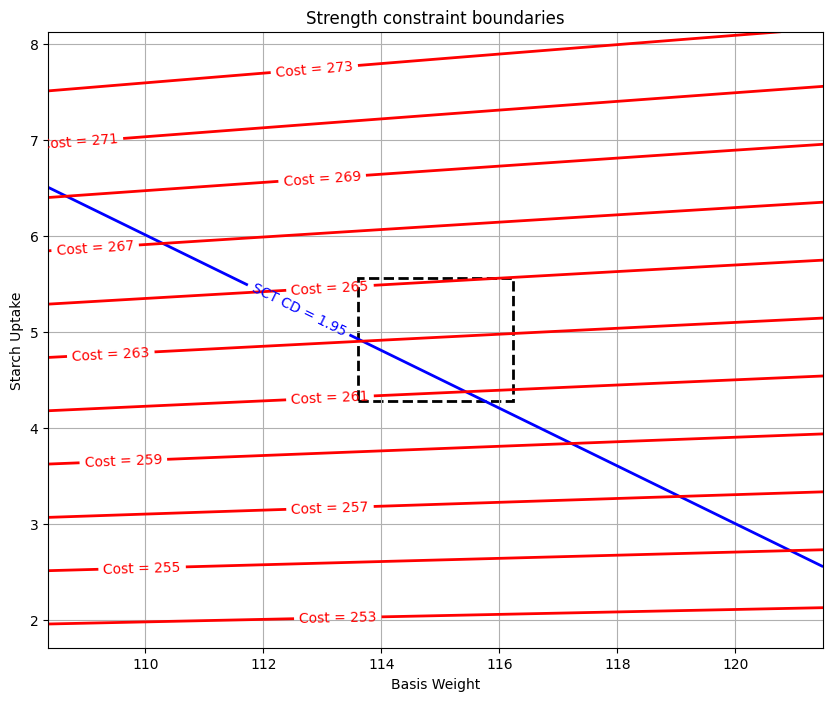

In [6]:
plt.figure(figsize=(10, 8))

# SCT CD = 1.95
cs1 = plt.contour(
    BW,
    STARCH,
    SCT,
    levels=[1.95],
    colors="blue",
    linewidths=2,
)

# Burst = 255
# cs2 = plt.contour(
#     BW,
#     STARCH,
#     BURST,
#     levels=[255],
#     colors="green",
#     linewidths=2,
# )

cs3 = plt.contour(
    BW,
    STARCH,
    COST_T,
    levels=np.arange(int(np.nanmin(COST_T)), int(np.nanmax(COST_T)),2),
    colors="red",
    linewidths=2,
)

plt.clabel(cs1, fmt="SCT CD = %.2f")
#plt.clabel(cs2, fmt="Burst = %.0f")
plt.clabel(cs3, fmt="Cost = %.0f")

plt.xlabel("Basis Weight")
plt.ylabel("Starch Uptake")
plt.title("Strength constraint boundaries")

plt.grid(True)

from matplotlib.patches import Rectangle

ax = plt.gca()

rect = Rectangle(
    (BW_min, SU_min),
    BW_max - BW_min,
    SU_max - SU_min,
    fill=False,
    linewidth=2,
    linestyle="--",
    label="Feasible region"
)

ax.add_patch(rect)

plt.show()





In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reference operating point
base = turnup_data[turnup_data.MBS_Current_reel_ID==12604077].copy()

# Ranges
bw_grid = np.linspace(
    BW_min - 2*(BW_max-BW_min),
    BW_max + 2*(BW_max-BW_min),
    100,
)

starch_grid = np.linspace(
    SU_min - 2*(SU_max-SU_min),
    SU_max + 2*(SU_max-SU_min),
    100,
)

BW, STARCH = np.meshgrid(bw_grid, starch_grid)

SCT = np.zeros_like(BW)
BURST = np.zeros_like(BW)
COST_m2 = np.zeros_like(BW)

for i in range(BW.shape[0]):
    for j in range(BW.shape[1]):

        x = base.copy()

        x["Current_basis_weight"] = BW[i, j]
        x['Starch_uptake_by_paper_Bottom_Roll__g/m2_'] = STARCH[i, j]
        x['Starch_uptake_by_paper_Top_Roll__g/m2_'] = 0

        bw_value = float(x["Current_basis_weight"].iloc[0])

        X = pd.DataFrame(x)

        SCT[i, j] = float(sctcd_strength(X)[0])
        BURST[i, j] = float(burst_strength(X)[0])
        COST_m2[i, j] = float(total_cost(X)[0] * bw_value)



In [8]:
with open(f"COST_m2.pkl", 'wb') as f:
        pickle.dump(COST_m2, f)

In [9]:
print("SCT range:", np.nanmin(SCT), np.nanmax(SCT))
print("Burst range:", np.nanmin(BURST), np.nanmax(BURST))
print("Cost range:", np.nanmin(COST_m2), np.nanmax(COST_m2))

SCT range: 1.8448090426944885 2.072227851906691
Burst range: 234.06481820963953 285.0797647196039
Cost range: 27317.51877317855 33152.653924498736


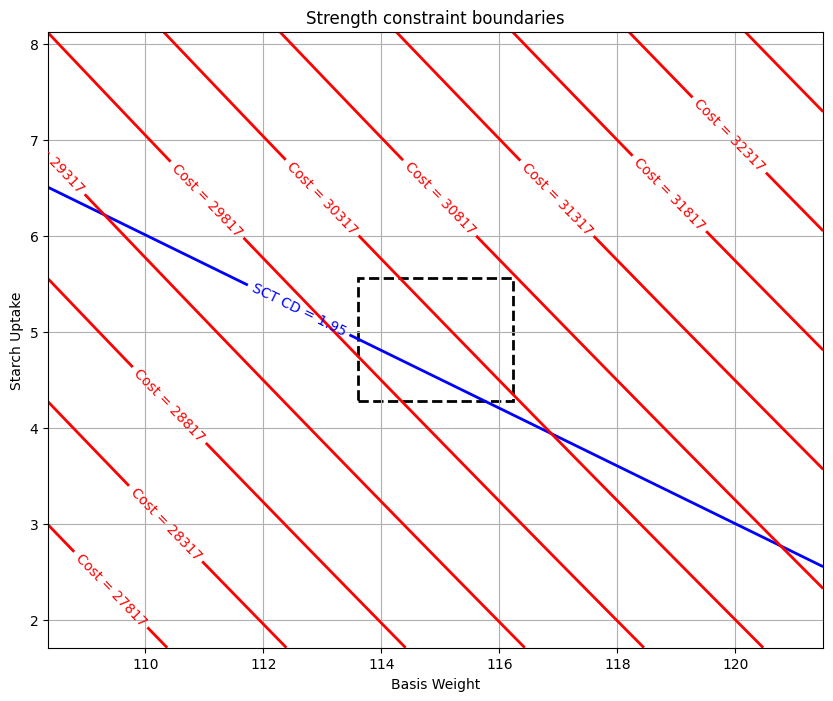

In [10]:
plt.figure(figsize=(10, 8))

# SCT CD = 1.95
cs1 = plt.contour(
    BW,
    STARCH,
    SCT,
    levels=[1.95],
    colors="blue",
    linewidths=2,
)

# Burst = 255
# cs2 = plt.contour(
#     BW,
#     STARCH,
#     BURST,
#     levels=[255],
#     colors="green",
#     linewidths=2,
# )

cs3 = plt.contour(
    BW,
    STARCH,
    COST_m2,
    levels=np.arange(int(np.nanmin(COST_m2)), int(np.nanmax(COST_m2)),500),
    colors="red",
    linewidths=2,
)

plt.clabel(cs1, fmt="SCT CD = %.2f")
#plt.clabel(cs2, fmt="Burst = %.0f")
plt.clabel(cs3, fmt="Cost = %.0f")

plt.xlabel("Basis Weight")
plt.ylabel("Starch Uptake")
plt.title("Strength constraint boundaries")

plt.grid(True)

from matplotlib.patches import Rectangle

ax = plt.gca()

rect = Rectangle(
    (BW_min, SU_min),
    BW_max - BW_min,
    SU_max - SU_min,
    fill=False,
    linewidth=2,
    linestyle="--",
    label="Feasible region"
)

ax.add_patch(rect)

plt.show()


# Knowledge

In [16]:
_,_ = run_query("Can a lower outlet moisture improve stem consumption in drying?")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job 7929839c-aa3f-4bb3-918d-6d2241a330cd: accepted
Job 7929839c-aa3f-4bb3-918d-6d2241a330cd: running
Job 7929839c-aa3f-4bb3-918d-6d2241a330cd: completed


# Can Lower Outlet Moisture Improve Steam Consumption in Drying?

## Direct Answer

**Yes, lower outlet moisture (drier paper at the reel) actually *increases* steam consumption** — not improves (reduces) it. This is a fundamental relationship in papermaking drying sections.

## Why This Matters

To achieve lower outlet moisture, you must:
- Evaporate more water from the sheet
- Maintain higher drying cylinder temperatures
- Potentially increase residence time in the dryer section

All of these factors increase the total steam demand.

## Key Energy Efficiency Factors

However, the context provided focuses on **optimizing steam consumption for a given production target** through several mechanisms:

### 1. **Exhaust Air Humidity Management**
Operating at higher exhaust air humidity levels reduces specific energy consumption because:
- Less exhaust air is needed to carry evaporated water
- Less supply air requires heating at a specified leakage air ratio
- Fans use less electrical power due to decreased air flows
- Heat recovery becomes more effective



### 2. **Supply Air Ratio Optimization**
"The aim should be to keep the supply air ratio as high as possible to bring pre-heated supply air into the hood system through blow boxes... instead of allowing cold leakage air to enter."

The general relation shows that **exhaust air humidity, supply air ratio, and total specific steam consumption are interconnected**

### 3. **Leakage Air Control**
"An excessive amount of leakage air into the hood primarily from the basement adversely affects energy consumption. The air is relatively cold, and in addition to the condensation problem... the specific energy consumption of the drying section increases."

## Energy Management Framework

The context emphasizes four categories affecting heat energy efficiency:
1. Steam system operation
2. Steam system maintenance
3. Pocket ventilation & hood supply system
4. Steam system control



## Conclusion

**Lower outlet moisture does not improve (reduce) steam consumption** — it increases it. However, you can optimize steam efficiency for any target moisture level by:
- Maximizing exhaust air humidity
- Minimizing leakage air
- Optimizing supply air ratio
- Implementing proper steam system control
- Maintaining effective heat recovery systems

The context does not provide plant-specific guidance on your actual outlet moisture targets or specifications.

In [10]:
_,_ = run_query("What is retention?")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job 3781fe8d-864d-43e2-9bb9-24667e59716e: accepted
Job 3781fe8d-864d-43e2-9bb9-24667e59716e: running
Job 3781fe8d-864d-43e2-9bb9-24667e59716e: completed


# What is Retention?

In papermaking, **retention** refers to the ability to keep fine particles (fines), fillers, and other additives in the paper sheet during the forming process, rather than losing them through the forming fabric into the white water system.

## Key Aspects of Retention:

### Purpose and Benefits
Retention aids are chemicals used to improve total retention, which provides several benefits:

**On the forming fabric:**
- Improvement of total retention
- Better drainage and dewatering
- Fixing of anionic trash
- Less abrasion


**Overall production effects:**
- Increase of production
- Saving of steam consumption
- Reduction of COD and BOD


### Retention Mechanisms

The retention process involves **adsorption of polymers onto furnish solids**, followed by flocculation. The mechanisms can be divided into three principal categories:
1. **Charge neutralisation**
2. **Patch-flocculation**
3. **Bridging** (most common in practice)

Importantly, "the adsorption to fibres is faster than to fines and fillers," though fines and fillers adsorb proportionally larger quantities due to their larger specific surface area.

### Modern Retention Systems

On modern paper machines, retention systems have evolved from single-polymer to **multi-component systems** because "improving one [aspect] could impair one of others" - retention, drainage, and formation are all related and opposed to each other.

### Challenge: Anionic Trash

Anionic trash significantly impacts retention aid efficiency because "cationic retention aids cannot distinguish if the anionic charge comes from the negative charge of a trash or from the fibre surface".

In [11]:
_,_ = run_query("What did I ask before")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job 1ecd1bba-ce66-4b8f-8ff1-10ffb638265a: accepted
Job 1ecd1bba-ce66-4b8f-8ff1-10ffb638265a: running
Job 1ecd1bba-ce66-4b8f-8ff1-10ffb638265a: completed


Based on the conversation history you provided, you previously asked:

**"What is retention?"**

This was your first question in the conversation, where you received an explanation about retention in papermaking - specifically how it refers to the ability to keep fine particles, fillers, and other additives in the paper sheet during the forming process rather than losing them through the forming fabric into the white water system.

In [56]:
_,_ = run_query("Que es la retencion en el proceso de fabricacion de papel")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job 7fca8cf0-f4b7-4c54-93a9-13e2cee39ca4: accepted
Job 7fca8cf0-f4b7-4c54-93a9-13e2cee39ca4: running
Job 7fca8cf0-f4b7-4c54-93a9-13e2cee39ca4: completed


# Retención en el Proceso de Fabricación de Papel

## Definición

**Retención** en la fabricación de papel se refiere a la capacidad de mantener materiales sólidos—particularmente **finos** (pequeños fragmentos de fibra) y **cargas** (pigmentos minerales como arcilla de caolín y carbonato de calcio)—dentro de la hoja de papel durante el proceso de formación, en lugar de perderlos a través del agua de drenaje.

## Por Qué Importa la Retención

La retención es crítica porque:
- Mejora la **economía del producto** al reducir la pérdida de material
- Crea una **estructura de hoja más homogénea**
- Afecta el **drenaje** y la calidad de **formación**
- Impacta las propiedades finales del papel como opacidad y blancura

## Dos Tipos de Retención

### 1. **Retención Mecánica (Filtración)**
- Ocurre después de que se forma una malla fibrosa en la tela
- Las partículas quedan físicamente atrapadas en la red de fibras
- Las **partículas gruesas** se filtran más fácilmente en la banda
- Los pigmentos finos pueden quedar atrapados dentro del lumen de la fibra o entre las fibrillas
- La forma de la partícula importa: las plaquetas de arcilla y talco muestran mejor retención que las partículas de carbonato de calcio en bloques

### 2. **Retención Química**
- Usa aditivos químicos especiales (agentes de retención) para unir partículas a las superficies de las fibras
- Causa **co-floculación** antes de la formación de la banda
- Crea aglomeración de partículas, haciéndolas más grandes y más fáciles de retener mecánicamente
- Mucho más efectiva que la retención mecánica sola

## Mecanismos de Retención

Existen tres categorías principales:

1. **Neutralización de carga**
2. **Floculación por parches** 
3. **Puenteo** - el más común en la práctica

## Sistemas Modernos de Retención

Las máquinas de papel modernas típicamente usan **sistemas de retención multicomponente** en lugar de sistemas de un solo polímero porque necesitan equilibrar tres factores competitivos:

- **Retención** (mantener materiales en la hoja)
- **Drenaje** (remover agua eficientemente)  
- **Formación** (distribución uniforme de fibras)

Mejorar uno puede perjudicar a los otros, por lo que los sistemas sofisticados de doble o múltiples componentes son ahora estándar.

## Detalles del Proceso

El proceso de retención química involucra:
1. **Adsorción** del polímero sobre los sólidos de la suspensión (los finos y cargas adsorben más debido a su mayor área superficial específica, aunque las fibras adsorben más rápido)
2. **Homo y heterofloculación** de partículas
3. Formación de flóculos (flóculos de fibra: milímetros a centímetros; flóculos de carga: raramente exceden 10 μm)

---

**Nota:** Su contexto menciona agentes de retención en el proceso de papel reciclado también, donde se agregan durante la etapa de refinado/mezcla para mejorar la retención de finos y cargas.

In [57]:
_,_ = run_query("Czym jest retencja w procesie produkcji papieru")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job 360b85cb-da49-4964-b247-166cc75093ef: accepted
Job 360b85cb-da49-4964-b247-166cc75093ef: running
Job 360b85cb-da49-4964-b247-166cc75093ef: completed


# Retencja w procesie produkcji papieru

## Definicja

**Retencja** w produkcji papieru odnosi się do zdolności zatrzymywania materiałów stałych—w szczególności **włókien, frakcji drobnej (małych fragmentów włókien) oraz wypełniaczy (pigmentów mineralnych)**—w arkuszu papieru podczas procesu formowania, zamiast tracenia ich wraz z wodą drenażową podczas formowania arkusza na maszynie papierniczej.

## Dlaczego retencja ma znaczenie

Retencja jest kluczowa, ponieważ:
- **Efektywność ekonomiczna**: Utracone materiały oznaczają zmarnowane surowce i zwiększone koszty oczyszczania ścieków
- **Jakość produktu**: Lepsza retencja prowadzi do bardziej jednorodnej struktury arkusza
- **Wpływ na środowisko**: Zmniejsza ilość odpadów i zanieczyszczeń w wodzie procesowej
- **Sprawność maszyny**: Wpływa na szybkość odwadniania i jakość formowania

## Rodzaje retencji

### 1. **Retencja mechaniczna (filtracyjna)**
- Występuje, gdy cząstki są fizycznie zatrzymywane w formującej się macie włóknistej
- Bardziej efektywna dla **cząstek grubych**
- Kształt cząstek ma znaczenie: cząstki płytkowe (kaolin, talk) wykazują lepszą retencję niż cząstki sferyczne (kreda)
- Bardzo drobny pigment może być zatrzymywany wewnątrz lumen włókna lub między fibrylami

### 2. **Retencja chemiczna**
- Wykorzystuje chemikalia wspomagające retencję (polimery) do przyłączania cząstek do powierzchni włókien poprzez **ko-flokulację** przed formowaniem arkusza
- Bardziej efektywna dla **cząstek drobnych**, które w przeciwnym razie przeszłyby przez matę włóknistą
- Tworzy aglomeraty, które są następnie mechanicznie zatrzymywane ze względu na większy rozmiar

## Mechanizmy retencji

Mechanizmy można podzielić na **trzy główne kategorie**:

1. **Neutralizacja ładunku**
2. **Flokulacja łatkowa** 
3. **Mostkowanie** (najczęstsze w praktyce)

### Dodatkowy mechanizm:
4. **Flokulacja sieciowa** - Oparta na oddziaływaniach wiązań wodorowych, przydatna w zanieczyszczonych systemach o wysokiej przewodności

## Nowoczesne systemy retencji

Na nowoczesnych maszynach papierniczych **systemy retencji jednopolimerowe rzadko są wystarczające**. Przemysł ewoluował w kierunku stosowania:

- **Systemów dwuskładnikowych**
- **Systemów wieloskładnikowych** (szeroko stosowanych na nowoczesnych maszynach)

Systemy te poprawiają retencję i odwadnianie bez poświęcania jakości formowania—kluczowa równowaga, ponieważ "retencja, odwadnianie i formowanie są ze sobą powiązane i przeciwstawne pod względem ich kontroli. Poprawa jednego może pogorszyć jeden z pozostałych."

## Kluczowe czynniki wpływające na retencję

Ważne parametry obejmują:
- Skład masy włóknistej
- Gramatura (masa powierzchniowa)
- Konstrukcja elementów odwadniających
- Strategia pracy maszyny papierniczej (prędkość, poziom turbulencji)
- Środowisko chemiczne
- Rozmiar i kształt cząstek

---

**Uwaga**: Dostarczony kontekst koncentruje się na systemach z masy celulozowej pierwotnej. W przypadku systemów z włókien wtórnych wymienionych w dokumentach, wyzwania związane z retencją mogą być zwiększone ze względu na wyższy poziom zanieczyszczeń i odmienne charakterystyki włókien.

In [6]:
_,_ = run_query("A question about papermaking: If I want to reduce starch uptake to keep SCT CD and Burst just over some minimum values, it may happen that this reduction is limited by the strength property closer to the minimum. Does it make sense that, by increasing the basis weight I would have more room to more starch reduction?")

HTTP status: 200


Yes, your reasoning makes excellent sense from a papermaking engineering perspective. Let me explain why:

## The Logic Behind Your Approach

**The Fundamental Relationship:**

When you reduce starch uptake, you're weakening multiple strength properties simultaneously (SCT CD, Burst, etc.). Whichever property is closest to its minimum specification becomes your **limiting constraint** - you can't reduce starch any further without falling below spec on that property.

**Why Increasing Basis Weight Creates More Room:**

By increasing basis weight, you're adding more fiber to the sheet structure, which provides:

1. **Inherent strength improvement** - More fibers = stronger base sheet
2. **Higher baseline properties** - All strength properties (SCT, Burst, etc.) improve with the additional fiber
3. **Greater margin above minimums** - This creates a "buffer" that allows for more starch reduction

## Evidence from the Context

The context supports this relationship:

**Basis Weight and Strength Correlation:**
The document discusses trials with different basis weights (95 g/m² FLU vs 160 g/m² TL) and shows that "the amount of starch is by far the most important factor contributing to the strength properties of board" [starch_sizing.pdf:953f472e38cd35ea:9:0].

**Starch Amount Impact:**
The data shows clear relationships between starch pickup and strength properties: "strength properties continue to increase from 60 to 70 kN/m" with increased starch amounts [starch_sizing.pdf:953f472e38cd35ea:16:0], and "burst increase can be explained through differences in starch pick up" [starch_sizing.pdf:953f472e38cd35ea:16:0].

## Practical Optimization Strategy

Your approach would work as follows:

1. **Current state**: Limited starch reduction due to Property X being closest to minimum
2. **Increase basis weight**: All properties improve, including Property X
3. **New opportunity**: Property X now has more margin, allowing further starch reduction
4. **Net result**: Potentially lower total cost (more fiber, less starch) while maintaining specs

## Important Consideration

The economic viability depends on the **relative costs** of fiber vs. starch and the **magnitude of improvement** you can achieve. You'd need to calculate whether the cost of additional fiber is offset by the savings from reduced starch usage.

This is a sound engineering optimization approach that leverages the complementary contributions of fiber and starch to paper strength.

# Executive Summary

In [ ]:
summary = get_exec_summary("http://localhost:5000")

if summary:
    print(summary)          # Markdown
else:
    print("No enriched summary available.")

In [ ]:
params = {"lang": lang, "conditional": "false", "target_start":"2026-11-06T08:00:00",  "target_end":"2026-11-13T08:00:00"}
    

    resp = requests.get(
        f"{base_url.rstrip('/')}/v2/reports/cost-analysis/exec-summary",
        params=params,
        timeout=timeout,

In [50]:
GOLDEN_RUN = True
summary = get_exec_summary(
    "http://localhost:5000",
    lang="en",
    conditional=False,
    target_start="2026-10-26",
    target_end="2026-11-01",
    baseline_start=None if GOLDEN_RUN else "2026-09-07",
    baseline_end=None if GOLDEN_RUN else "2026-10-04",
)

if summary:
    print(summary)          # Markdown
else:
    print("No enriched summary available.")

**Overall**

The 10.35 €/t cost increase is entirely process-driven; grade mix was unchanged and no price movements are reported in the findings. Process deterioration accounts for the full deviation from baseline.

---

**Grades to focus on**

- **Grade 6010085**: 32.8% of the overall cost change, with a deviation from baseline of +12.44 €/t — the strongest cost increase among all grades.
- **Grade 6010100**: 32.8% of the overall cost change, with a deviation from baseline of +12.43 €/t — nearly identical share and magnitude to 6010085.

---

**Cost components to focus on**

- **Steam** (+8.63 €/t, 77.7% of total change): The increase is dominated by pre-dryer steam (+5.86 €/t on average), with grade 6010120 seeing +9.92 €/t. Across the focus grades, hidden latent model state accounts for a material portion of the steam cost move (e.g., +5.21 €/t for 3200115, +1.08 €/t for 6010085, +1.13 €/t for 6010100, +1.52 €/t for 6010120), indicating that part of the steam cost variation is captu

In [159]:
GOLDEN_RUN = True
summary = get_exec_summary(
    "http://localhost:5000",
    lang="en",
    conditional=False,
    target_start="2026-10-05",
    target_end="2026-10-11",
    baseline_start=None if GOLDEN_RUN else "2026-09-07",
    baseline_end=None if GOLDEN_RUN else "2026-10-04",
)

if summary:
    print(summary)          # Markdown
else:
    print("No enriched summary available.")

Total cost increased 4.05 €/t to 276.69 €/t, with 3.76 €/t driven by process deterioration and 0.29 €/t by grade mix. Overprocessing rose 0.90 percentage points to 6.28 %, split between mix (+0.39 %) and process (+0.51 %).

- **Chemicals rose 2.19 €/t**, led by Fixative_2 (+0.88 €/t) and Sizing_Agent (+0.27 €/t); higher retention-aid and fixative dosing often signals poor first-pass retention or furnish variability, increasing both chemical consumption and whitewater solids load.

- **Steam increased 2.15 €/t**, with Predryers accounting for +1.01 €/t (highest in grade 6010085 at +3.67 €/t); elevated dryer steam demand typically reflects insufficient mechanical dewatering, higher moisture entering the dryer section, or reduced drying efficiency from lower differential pressures or fouled cylinders.

- **Grade 6010100 saw the largest cost jump (+8.77 €/t)**, despite a 3.10 % improvement in overprocessing; the cost spike was driven by steam (+4.47 €/t in one analysis segment) and starch,

# Feedback

## Get feedback

In [7]:
import requests

BASE_URL = "http://127.0.0.1:5000"

# All of a user's feedback (no date bounds)
response = requests.get(
    f"{BASE_URL}/v2/feedback",
    params={
        "user": "miguel.angel.gonzalez@dssmith.com",
        "start": "2026-11-01",
        "end": "2026-11-30"
        },
    timeout=30,
)
response.raise_for_status()
all_feedback = response.json()


for item in all_feedback:
    print(item["created_at"], item["text"])

2026-11-12T09:48:34.447632+00:00 Hello world!


## Send feedback

In [6]:
import requests

BASE_URL = "http://127.0.0.1:5000"

response = requests.post(
    f"{BASE_URL}/v2/feedback",
    json={
        "session": "abc-123",
        "user": "miguel.angel.gonzalez@dssmith.com",
        "text": "Hello world!",
    },
    timeout=30,
)
response.raise_for_status()

record = response.json()
print(record)


{'id': 1, 'session': 'abc-123', 'user': 'miguel.angel.gonzalez@dssmith.com', 'text': 'Hello world!', 'created_at': '2026-11-12T09:48:34.447632+00:00'}


# Benchmark

In [29]:
response = requests.get(
    "http://localhost:5000/process-data/grades",
)

response.json()["grades"]


params = {
    "y_variable_summary": ['Combined_cost__€/T_'],
    "y_variable_summary_secondary": "Speed",
    "x_variable_summary": "week",
    "color_variable_summary": "cost",
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Combined_cost__€/T_'],
    "x_variable_summary": "grade",
    "color_variable_summary": "cost_grade",
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Current_reel_weight'],
    "x_variable_summary": "week",
    "color_variable_summary": None,
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Combined_cost__€/T_'],
    "x_variable_summary": "week",
    "color_variable_summary": None,
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Current_reel_weight'],
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Combined_cost__€/T_'],
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Combined_cost__€/T_'],
    "x_variable_summary": "week",
    "color_variable_summary": "cost",
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)


tables, figures = ask_engine(params = {
    "grade": None,
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "levels": [2],
    "objects": ["cost"],
    "secondary_objects":["chemicals", "steam", "electricity"],
    "summary": False,
    "output_format": "json",
}, endpoint="diagnosis",run_async=True, download_artifacts= True)



Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,grammage,paper_type,Speed,cost,Cost__€/T_
0,12601665,2026,10,85,6010,1342.397705,Steam__€/T_,87.782578
1,12601666,2026,10,85,6010,1342.872314,Steam__€/T_,89.354004
2,12601667,2026,10,85,6010,1341.722290,Steam__€/T_,88.837769
3,12601668,2026,10,85,6010,1320.777100,Steam__€/T_,94.010635
4,12601669,2026,10,85,6010,1320.692871,Steam__€/T_,94.009995


grouped


,Wedge_Year,Wedge_Week,cost,Cost__€/T_,n
0,2026,9,Chemicals__€/T_,6.196404,25
1,2026,9,Electricity__€/T_,32.898804,25
2,2026,9,Fibre_cost__€/T_,127.373787,25
3,2026,9,Starch__€/T_,23.865166,25
4,2026,9,Steam__€/T_,87.489822,25


metadata
{'color_map': {'Chemicals__€/T_': '#AB63FA', 'Electricity__€/T_': '#EF553B', 'Fibre_cost__€/T_': '#FFA15A', 'Starch__€/T_': '#00CC96', 'Steam__€/T_': '#636EFA'}, 'color_variable': 'cost', 'grouped_rows': 50, 'prepared_rows': 7815, 'x_variable': 'Wedge_Week'}
Grouped process-data metadata:
{'color_map': {'Chemicals__€/T_': '#AB63FA', 'Electricity__€/T_': '#EF553B', 'Fibre_cost__€/T_': '#FFA15A', 'Starch__€/T_': '#00CC96', 'Steam__€/T_': '#636EFA'}, 'color_variable': 'cost', 'grouped_rows': 50, 'prepared_rows': 7815, 'x_variable': 'Wedge_Week'}
Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,AB_Grade_ID,grammage,paper_type,cost,Cost__€/T_
0,12601665,6010085,85,6010,Steam__€/T_,87.782578
1,12601666,6010085,85,6010,Steam__€/T_,89.354004
2,12601667,6010085,85,6010,Steam__€/T_,88.837769
3,12601668,6010085,85,6010,Steam__€/T_,94.010635
4,12601669,6010085,85,6010,Steam__€/T_,94.009995


... (24 outputs left out)

main


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,433.960114,152,TOTAL,285.423035,148.537079
1,current,3300100,353.155365,47,TOTAL,281.258698,71.896667
2,current,3300110,278.191772,57,TOTAL,286.205566,-8.013794
3,current,3300120,275.125885,23,TOTAL,291.348145,-16.222260
4,current,6010085,291.831665,155,TOTAL,301.260162,-9.428497


diagnosis_table_1


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,433.960114,152,TOTAL,285.423035,148.537079
1,current,3300100,353.155365,47,TOTAL,281.258698,71.896667
2,current,3300110,278.191772,57,TOTAL,286.205566,-8.013794
3,current,3300120,275.125885,23,TOTAL,291.348145,-16.222260
4,current,6010085,291.831665,155,TOTAL,301.260162,-9.428497


In [32]:
import pandas as pd
df = pd.read_parquet("aggregated_turned_up_20260825.parquet")

In [33]:
df.tail()

,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Dry_Strength_Agent__€/T_,Natriumhydroxide__€/T_,Electricity__€/T_,Steam__€/T_,Fibre_cost__€/T_,Combined_cost__€/T_,Total_SQM_cost__€/hm2_,source_file,turn_up_rows_used,ambient_temp_C
9,2026-08-25 10:43:00,12606009,6010120,2.13,3.86,277.48,NaN,662.946509,1052.602857,48744.040234,...,0.0,0.092698,30.115634,80.337117,127.844686,263.569635,999999.0,data-v2/aggregated/2026/08/25/aggregated_20260...,10,17.090000
10,2026-08-25 11:04:00,12606010,6010120,NaN,NaN,NaN,NaN,661.557178,1053.481836,15121.545996,...,0.0,0.603153,35.155347,88.004205,127.980130,276.889407,999999.0,data-v2/aggregated/2026/08/25/aggregated_20260...,10,17.726667
11,2026-08-25 12:24:00,12606011,6010120,2.21,4.22,284.05,206.0,663.052179,1052.616650,49710.223828,...,0.0,0.601574,35.978729,79.196955,128.290938,268.848218,999999.0,data-v2/aggregated/2026/08/25/aggregated_20260...,10,20.100000
12,2026-08-25 13:20:00,12606012,6010120,2.24,3.97,281.96,NaN,662.788000,1052.683166,48655.791406,...,0.0,0.607324,35.556722,83.132453,127.953114,272.267623,999999.0,data-v2/aggregated/2026/08/25/aggregated_20260...,10,22.533333
13,2026-08-25 14:15:00,12606013,6010120,NaN,NaN,NaN,NaN,662.852344,1052.687988,47152.318360,...,0.0,0.604682,35.313322,81.104353,127.817965,269.825053,999999.0,data-v2/aggregated/2026/08/25/aggregated_20260...,10,23.325000


# Cost Analysis

In [49]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": 'Combined_cost__€/T_',
    "x_variable_summary": "week",
    # "grades":[  
    #     '3200115',
    #     '3300085',
    #     '3300100',
    #     '3300110',
    #     '3300115',
    #     '3300120',
    #     '3300125',
    #     '6010085',
    #     '6010090',
    #     '6010100',
    #     '6010120'
    # ],
    # "grades": [
    #     "3300110",
    #     "6010100",
    # ],
    #"total_range": ["2026-01-05", "2026-11-10"],
    "target_range": ["2026-11-02", "2026-11-08"],
    "baseline_range": ["2025-07-01", "2026-11-07"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Year,Wedge_Week,Combined_cost__€/T_,unit
2915,12506630,85,3300,2025,40,294.408254,€/t
2916,12506631,85,3300,2025,40,296.789819,€/t
2917,12506632,85,3300,2025,40,298.415357,€/t
2918,12506633,85,3300,2025,40,296.842096,€/t
2919,12506634,85,3300,2025,40,299.643641,€/t


grouped


,Wedge_Year,Wedge_Week,Combined_cost__€/T_,n,unit
0,2025,27,284.162379,130,€/t
1,2025,28,283.970427,175,€/t
2,2025,29,284.226194,172,€/t
3,2025,30,287.498531,166,€/t
4,2025,31,290.117172,152,€/t


metadata
{'x_variable': 'Wedge_Week', 'color_variable': None, 'color_map': None, 'prepared_rows': 10859, 'grouped_rows': 68}


In [52]:
weekly = tables["grouped"].sort_values(["Wedge_Year","Wedge_Week"])

weekly["week_start"] = pd.to_datetime(
    weekly["Wedge_Year"].astype(str)
    + "-W"
    + weekly["Wedge_Week"].astype(str).str.zfill(2)
    + "-1",
    format="%G-W%V-%u"
)
weekly = weekly.sort_values("week_start").reset_index(drop=True)

weekly["bin_5w"] = weekly.index // 5

trend_bins_5w = (
    weekly
    .groupby("bin_5w")
    .agg(
        week_start=("week_start", "min"),
        week_end=("week_start", "max"),
        Combined_cost_trend=("Combined_cost__€/T_", "mean"),
        n_weeks=("Combined_cost__€/T_", "size")
    )
    .reset_index()
)

weekly["Combined_cost_ma_5w_centered"] = (
    weekly["Combined_cost__€/T_"]
    .rolling(window=5, center=True, min_periods=1)
    .mean()
)

import plotly.express as px

fig = px.line(
    weekly[weekly.week_start>"2025-07-01"],
    x="week_start",
    y=["Combined_cost__€/T_", "Combined_cost_ma_5w_centered"],
    markers=True,
    title="Combined cost trend - centered 5-week moving average"
)

fig.show()

In [31]:
table = get_process_data_parquet(params = {
    "start": "2026-01-05 00:00:00",
    "end": "2026-11-10 00:00:00",
    "variables": "Combined_cost__€/T_",
})

Calling: http://127.0.0.1:5000/v2/process-data/parquet
HTTP status: 200


In [33]:
table.head(20)

,Wedge_Time,AB_Grade_ID,MBS_Current_reel_ID,Combined_cost__€/T_
0,2026-01-05 00:11:00,6010100,12600056,292.669951
1,2026-01-05 01:06:00,6010100,12600057,288.514932
2,2026-01-05 01:50:00,6010100,12600058,290.235211
3,2026-01-05 02:48:00,6010090,12600059,294.890849
4,2026-01-05 03:48:00,6010090,12600060,295.784187
5,2026-01-05 04:20:00,6010085,12600061,294.046693
6,2026-01-05 05:25:00,6010085,12600062,303.916060
7,2026-01-05 06:29:00,6010085,12600063,304.168387
8,2026-01-05 07:34:00,6010085,12600064,297.401599
9,2026-01-05 08:38:00,6010085,12600065,303.064520
